<a href="https://colab.research.google.com/github/JuanfelipeX/Trabajo-de-Grado-Magister-Clustering-Accesibilidad-Web/blob/main/Codigo_Clasificacion_Sitios_Accesibilidad_revisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Trabajo de Grado: Clasificación de Sitios Web por Accesibilidad mediante Clustering Multidimensional**

## **1. Preparación del Entorno**

Importe y preparacion de las librerías y entorno de desarrollo del proyecto


In [ ]:
# ============================================================
# CONFIGURACIÓN INICIAL - GOOGLE COLAB
# Compatible con entorno Colab actual
# ============================================================

import os
import re
import json
import time
import subprocess
import warnings
import logging
import uuid
import signal
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

# ============================================================
# SUPRIMIR WARNINGS
# ============================================================

warnings.filterwarnings("ignore", category=DeprecationWarning)

warnings.filterwarnings(
    "ignore",
    message=r"datetime\.datetime\.utcnow\(\) is deprecated.*"
)
warnings.filterwarnings("ignore", category=RuntimeWarning)

# Variable de entorno para procesos hijos
os.environ["PYTHONWARNINGS"] = (
    "ignore::DeprecationWarning,"
    "ignore::RuntimeWarning"
)

# Reducir logging innecesario
logging.getLogger().setLevel(logging.ERROR)


# ============================================================
# 1. INSTALACIÓN DE DEPENDENCIAS
# ============================================================

print("📦 Configurando entorno...")

# ------------------------------------------------------------
# Actualizar paquetes del sistema
# ------------------------------------------------------------

!apt-get update -qq

# ------------------------------------------------------------
# Herramientas necesarias
# ------------------------------------------------------------

!apt-get install -y -qq wget gnupg unzip > /dev/null 2>&1


# ------------------------------------------------------------
# Instalar Google Chrome solamente si no existe
# ------------------------------------------------------------

CHROME_PATH = "/usr/bin/google-chrome"

if not os.path.exists(CHROME_PATH):

    print("🌐 Google Chrome no está instalado. Instalando...")

    !wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb

    !dpkg -i google-chrome-stable_current_amd64.deb > /dev/null 2>&1 || \
        apt-get -f install -y -qq > /dev/null 2>&1

    # Eliminar instalador
    !rm -f google-chrome-stable_current_amd64.deb

else:

    print("✅ Google Chrome ya está instalado.")


# ------------------------------------------------------------
# Librerías Python
# ------------------------------------------------------------

print("🐍 Verificando librerías Python...")

!pip install -q selenium axe-selenium-python mlxtend


# ------------------------------------------------------------
# Herramientas de auditoría
# ------------------------------------------------------------

print("🔍 Verificando Lighthouse y Pa11y...")

!npm install -g lighthouse pa11y -q


print("✅ Dependencias configuradas correctamente.")


# ============================================================
# 2. IMPORTS
# ============================================================

from google.colab import drive

from selenium import webdriver
from selenium.webdriver.chrome.options import Options
from selenium.common.exceptions import TimeoutException

from axe_selenium_python import Axe

from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans

import matplotlib
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_samples

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

from urllib.parse import urlparse

from IPython.display import display, HTML

from plotly.colors import sample_colorscale

from mlxtend.frequent_patterns import (
    apriori,
    association_rules
)


# ============================================================
# 3. CONEXIÓN A GOOGLE DRIVE
# ============================================================

print("\n☁️ Verificando conexión con Google Drive...")

DRIVE_MOUNT = "/content/drive"

# ------------------------------------------------------------
# Comprobar si Drive ya está montado correctamente
# ------------------------------------------------------------

DRIVE_MYDRIVE = os.path.join(
    DRIVE_MOUNT,
    "MyDrive"
)

if os.path.exists(DRIVE_MYDRIVE):

    print("✅ Google Drive ya está montado.")
    print(f"📁 {DRIVE_MYDRIVE}")

else:

    print("🔗 Montando Google Drive...")

    # Si existe el directorio pero no está correctamente montado,
    # intentamos desmontar cualquier montaje previo.
    try:
        drive.flush_and_unmount()
    except Exception:
        pass

    # Crear el punto de montaje si no existe
    os.makedirs(DRIVE_MOUNT, exist_ok=True)

    # Montar Drive
    drive.mount(
        DRIVE_MOUNT,
        force_remount=False
    )

    print("✅ Google Drive montado correctamente.")


# ------------------------------------------------------------
# Verificación final
# ------------------------------------------------------------

if not os.path.exists(DRIVE_MYDRIVE):

    raise RuntimeError(
        "❌ No fue posible encontrar Google Drive en "
        f"{DRIVE_MYDRIVE}"
    )

print("✅ Acceso a MyDrive confirmado.")


# ============================================================
# 4. RUTA PRINCIPAL DEL PROYECTO
# ============================================================

BASE_DIR = os.path.join(
    DRIVE_MYDRIVE,
    "Trabajo de Grado",
    "Archivos_Generados"
)

print("\n📂 BASE_DIR:")
print(BASE_DIR)

print(
    "📁 Existe:",
    os.path.exists(BASE_DIR)
)


# ============================================================
# 5. ESTRUCTURA PRINCIPAL DEL PROYECTO
# ============================================================

# 1. Obtención
RUTA_OBTENCION = os.path.join(
    BASE_DIR,
    "1. Obtencion"
)

# 2. Limpieza
RUTA_LIMPIEZA = os.path.join(
    BASE_DIR,
    "2. Limpieza"
)

# 3. Visualización
RUTA_VISUALIZACION = os.path.join(
    BASE_DIR,
    "3. Visualizacion"
)

# 4. Dataset Consolidado
RUTA_MODELADO = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado"
)

# 5. Clustering
RUTA_CLUSTERING = os.path.join(
    BASE_DIR,
    "5. Clustering"
)

# 6. Evaluación
RUTA_EVALUACION = os.path.join(
    BASE_DIR,
    "6. Evaluacion"
)

# 7. Resultados
RUTA_RESULTADOS = os.path.join(
    BASE_DIR,
    "7. Resultados"
)


# ============================================================
# CARPETAS DE LAS HERRAMIENTAS DE OBTENCIÓN
# ============================================================

RUTA_LIGHTHOUSE = os.path.join(
    RUTA_OBTENCION,
    "Lighthouse"
)

RUTA_PA11Y = os.path.join(
    RUTA_OBTENCION,
    "Pa11y"
)

RUTA_AXE = os.path.join(
    RUTA_OBTENCION,
    "Axe"
)


# ============================================================
# CREACIÓN DE CARPETAS BASE
# ============================================================

for ruta_base in [
    RUTA_OBTENCION,
    RUTA_LIMPIEZA,
    RUTA_VISUALIZACION,
    RUTA_MODELADO,
    RUTA_CLUSTERING,
    RUTA_EVALUACION,
    RUTA_RESULTADOS
]:
    os.makedirs(
        ruta_base,
        exist_ok=True
    )


# ============================================================
# 6. CONFIGURACIÓN DE SELENIUM
# ============================================================

def iniciar_driver():

    chrome_options = Options()

    # --------------------------------------------------------
    # Ejecución sin interfaz gráfica
    # --------------------------------------------------------

    chrome_options.add_argument("--headless=new")

    # --------------------------------------------------------
    # Opciones necesarias para Google Colab
    # --------------------------------------------------------

    chrome_options.add_argument("--no-sandbox")
    chrome_options.add_argument("--disable-dev-shm-usage")
    chrome_options.add_argument("--disable-gpu")

    # --------------------------------------------------------
    # Tamaño de ventana
    # --------------------------------------------------------

    chrome_options.add_argument(
        "--window-size=1920,1080"
    )

    # --------------------------------------------------------
    # Estabilidad
    # --------------------------------------------------------

    chrome_options.add_argument(
        "--disable-software-rasterizer"
    )

    chrome_options.add_argument(
        "--disable-extensions"
    )

    chrome_options.add_argument(
        "--disable-background-networking"
    )

    chrome_options.add_argument(
        "--disable-background-timer-throttling"
    )

    # --------------------------------------------------------
    # Ubicación de Google Chrome
    # --------------------------------------------------------

    chrome_options.binary_location = CHROME_PATH

    # --------------------------------------------------------
    # Selenium Manager se encarga automáticamente
    # del ChromeDriver compatible
    # --------------------------------------------------------

    driver = webdriver.Chrome(
        options=chrome_options
    )

    return driver


# ============================================================
# 7. PRUEBA DE SELENIUM
# ============================================================

print("\n🧪 Probando Selenium...")

try:

    driver = iniciar_driver()

    print("✅ Selenium iniciado correctamente.")

    print(
        "🌐 Chrome:",
        driver.capabilities.get(
            "browserVersion",
            "Desconocido"
        )
    )

    driver.quit()

    print("✅ Prueba de Selenium finalizada.")

except Exception as e:

    print("❌ Error al iniciar Selenium:")
    print(type(e).__name__)
    print(str(e))





📦 Configurando entorno...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
🌐 Google Chrome no está instalado. Instalando...
🐍 Verificando librerías Python...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 38.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 160.6/160.6 kB 11.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 511.8/511.8 kB 34.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.7/135.7 kB 10.0 MB/s eta 0:00:00
🔍 Verificando Lighthouse y Pa11y...
⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸npm warn deprecated @opentelemetry/sdk-trace-base@1.30.1: Use @opentelemetry/sdk-trace pack

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Mounted at /content/drive
✅ Google Drive montado correctamente.
✅ Acceso a MyDrive confirmado.

📂 BASE_DIR:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

📁 Existe: True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



🧪 Probando Selenium...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

✅ Selenium iniciado correctamente.
🌐 Chrome: 156.0.8078.47
✅ Prueba de Selenium finalizada.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **1.1 Prueba del Entorno Selenium + AXE**


In [ ]:
# ============================================================
# PRUEBA DE SELENIUM + AXE
# ============================================================
driver = None

try:
    driver = iniciar_driver()
    url_test = "https://www.utadeo.edu.co/es"
    driver.get(url_test)

    print(f"🌐 Página cargada: {driver.title}")

    axe = Axe(driver)
    axe.inject()

    results = axe.run()

    print(f"✅ Entorno listo. Violaciones detectadas: {len(results['violations'])}")

except Exception as e:
    print(f"❌ Error: {e}")

finally:
    if driver:
        driver.quit()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

🌐 Página cargada: Universidad de Bogotá Jorge Tadeo Lozano — Utadeo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

✅ Entorno listo. Violaciones detectadas: 7


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## **2. Preparación de la Lista de URLs (Dataset por Sectores) y Constantes**

Definimos un diccionario que permitira que se encargara de definir las paginas que vamos a auditar por sector y adicionalmente alojaremos variables que se desarrollaran a lo largo del trabajo

### **URLS por Sector**

In [ ]:
# Definición de URLs por sectores para la auditoría
urls_por_sector = {
    "Salud": [
        # EPS (10)
        "https://www.epssura.com",                   # EPS SURA
        "https://www.saludtotal.com.co",             # Salud Total EPS
        "https://www.famisanar.com.co",              # Famisanar EPS
        "https://coosalud.com",                      # Coosalud EPS
        "https://www.saviasaludeps.com",             # Savia Salud EPS
        "https://www.mutualser.com",                 # Mutual SER EPS
        "https://www.asmetsalud.com",                # Asmet Salud EPS
        "https://emssanareps.co",                    # Emssanar EPS
        "https://www.epsfamiliardecolombia.com",     # EPS Familiar de Colombia
        "https://epsianaswayuu.com",                 # Anas Wayuu EPSI

        # ODONTOLOGIA (5)
        "https://sonria.com.co",                     # Sonría - Odontología
        "https://www.dentisalud.com.co",             # DentiSalud - Odontología
        "https://www.oralhome.com.co",               # Oral Home - Odontología
        "https://clinicasodontofamily.com",          # Odonto Family - Odontología
        "https://clinicaswhite.com",                 # ClinicaWhite - Odontología

        # DROGUERIAS Y FARMACIAS (5)
        "https://www.drogueriascafam.com.co",        # Droguerías Cafam
        "https://drogueriaspasteur.com",             # Droguerías Pasteur
        "https://www.drogueriascolsubsidio.com",     # Droguerías Colsubsidio
        "https://drogueriasalemana.com",             # Droguería Alemana
        "https://www.larebajavirtual.com",           # Droguería La Rebaja

        # HOSPITALES Y FUNDACIONES (10)
        "https://valledellili.org",                  # Fundación Valle del Lili
        "https://hptu.org",                          # Hospital Pablo Tobón Uribe
        "https://www.husi.org.co",                   # Hospital Universitario San Ignacio
        "https://fundacionhomi.org.co",              # Fundación HOMI
        "https://mederi.com.co",                     # Hospital Universitario Méderi
        "https://www.hun.edu.co",                    # Hospital Universitario Nacional
        "https://www.lacardio.org",                  # La Cardio
        "https://www.sanvicentefundacion.com",       # Hospital San Vicente Fundación
        "https://clinicamarcaribe.com",              # Clínica Mar Caribe - Santa Marta
        "https://www.hus.org.co",                    # Hospital Universitario de La Samaritana

        # GOBIERNO / ENTIDADES PÚBLICAS DE SALUD (10)
        "https://www.minsalud.gov.co",               # Ministerio de Salud y Protección Social
        "https://www.supersalud.gov.co",             # Superintendencia Nacional de Salud
        "https://www.adres.gov.co",                  # ADRES
        "https://www.ins.gov.co",                    # Instituto Nacional de Salud
        "https://www.cancer.gov.co",                 # Instituto Nacional de Cancerología
        "https://www.dermatologia.gov.co",           # Centro Dermatológico
        "https://www.saludcapital.gov.co",           # Secretaría Distrital de Salud de Bogotá
        "https://www.subrednorte.gov.co",            # Subred Integrada de Servicios de Salud Norte E.S.E.
        "https://www.invima.gov.co",                 # INVIMA
        "https://www.fps.gov.co",                    # Fondo de Pasivo Social de Ferrocarriles Nacionales

        # MEDICINA PREPAGADA, PÓLIZAS Y SALUD COMPLEMENTARIA (5)
        "https://www.aliansalud.com.co",             # Aliansalud (Planes complementarios de salud / Organización Sanitas)
        "https://www.medplus.com.co",                # MedPlus Medicina Prepagada
        "https://amiasistencia.com/",                # AMI (Asistencia Médica Inmediata - Coomeva / Atención domiciliaria)
        "https://www.coomeva.com.co",                # Coomeva Medicina Prepagada (Cooperativa médica nacional)
        "https://www.colmedica.com",                 # Colmedica Medicina Prepagada

        # SALUD MENTAL Y PSICOLOGÍA (5)
        "https://porquequieroestarbien.com",         # Porque Quiero Estar Bien (Fundación Santo Domingo / Profamilia)
        "https://fundacionliberate.org.co",          # Fundación Libérate (Adicciones y Salud Mental)
        "https://www.fundacionlaluz.co",             # Fundación La Luz (Rehabilitación y Psicología)
        "https://homo.gov.co",                       # Hospital Mental de Antioquia E.S.E.
        "https://hospitalsancamilo.gov.co"           # Hospital Psiquiátrico San Camilo E.S.E.
    ],

"E-commerce": [
        # SUPERMERCADOS, RETAIL Y TECNOLOGÍA (5)
        "https://www.alkosto.com",                   # Alkosto (Retail / Electrohogar / Supermercado)
        "https://www.ktronix.com",                   # Ktronix (Tecnología y audio - Corbeta)
        "https://www.olimpica.com.co",               # Supertiendas Olímpica (Supermercado nacional)
        "https://www.panamericana.com.co",           # Panamericana (Librería, papelería y tecnología)
        "https://www.flamingo.com.co",               # Almacenes Flamingo (Grandes superficies / Departamentos)

        # HOGAR, MUEBLES Y VARIEDADES (5)
        "https://www.homesentry.co",                 # Home Sentry (Hogar y ferretería)
        "https://www.jamar.com",                     # Muebles Jamar (Muebles y decoración de interiores)
        "https://www.pepeganga.com",                 # Pepe Ganga (Juguetería, bebés y hogar)
        "https://www.colchoneseldorado.com",         # Colchones El Dorado (Descanso y colchones - 100% colombiana)
        "https://www.artesaniasdecolombia.com.co",   # Artesanías de Colombia (Tienda oficial de artesanías)

        # MODA, TEXTIL Y VESTUARIO (10)
        "https://www.arturocalle.com",               # Arturo Calle (Moda masculina y formal)
        "https://www.koaj.co",                       # KOAJ - Permoda (Moda urbana juvenil)
        "https://www.gef.co",                        # GEF - Crystal (Básicos y textil nacional)
        "https://www.tennis.com.co",                 # Tennis (Moda casual y denim)
        "https://www.studiof.com.co",                # Studio F (Moda femenina)
        "https://www.ela.com.co",                    # ELA (Moda femenina contemporánea)
        "https://www.mattelsa.net",                  # Mattelsa (Moda juvenil y casual - Medellín)
        "https://www.leonisa.com",                   # Leonisa (Fajas, moda íntima y deportiva - Medellín)
        "https://www.surtitodo.com.co",              # Surtitodo (Prendas y calzado multimarca)
        "https://www.lilipink.com",                  # Lili Pink (Moda íntima y deportiva femenina - 100% colombiana)

        # CALZADO Y MARROQUINERÍA (5)
        "https://www.totto.com",                     # Totto - Nalsani (Mochilas, maletas y accesorios)
        "https://www.velez.com.co",                  # Cueros Vélez (Marroquinería y cuero)
        "https://www.bosi.com.co",                   # Bosi (Calzado de cuero y accesorios)
        "https://www.calzatodo.com",                 # Calzatodo (Cadena multimarca de calzado)
        "https://www.croydon.com.co",                # Croydon Colombia (Calzado deportivo e industrial)

        # BELLEZA, COSMÉTICA Y CUIDADO DE MASCOTAS (5)
        "https://milagrosbeauty.com/",               # Milagros Cuidado Natural (Cosmética capilar y corporal 100% colombiana)
        "https://www.cromantic.com",                 # Cromantic (Belleza y cosmética profesional)
        "https://www.laika.com.co",                  # Laika Mascotas (E-commerce para mascotas)
        "https://www.cutis.com.co",                  # Cutis Droguería Dermatológica (Dermocosmética y cuidado de la piel)
        "https://www.medipiel.com.co",               # Medipiel (Cadena nacional de productos dermatológicos y belleza)

        # CADENAS DE ALIMENTOS, CAFÉ Y DELIVERY (5)
        "https://www.rappi.com.co",                  # Rappi (Delivery y supermercados - Unicornio colombiano)
        "https://www.cafesanalberto.com",            # Café San Alberto (Café premium especial colombiano)
        "https://www.tiendajuanvaldez.com",          # Juan Valdez Café (Tienda oficial de café colombiano)
        "https://www.crepesywaffles.com",            # Crepes & Waffles (Canal oficial gastronómico)
        "https://www.ramo.com.co",                   # Productos Ramo (Comercializadora de ponqués y snacks)

        # DEPORTES Y VIDA AL AIRE LIBRE (5)
        "https://athleticgym.com.co",                # Athletic (Equipos deportivos y fitness - 100% colombiana)
        "https://gwbicycles.com",                    # GW Bicycles (Bicicletas, repuestos y accesorios - Medellín)
        "https://gorigogo.com",                      # Go Rigo Go (Ciclismo, moda y accesorios deportivos)
        "https://www.suarezclothing.com",            # Suárez Clothing (Prendas de ciclismo de alto rendimiento)
        "https://tiendaverde.com.co",                # Tienda Verde (E-commerce oficial de Atlético Nacional)

        # LIBRERÍAS, JUGUETERÍA Y ENTRETENIMIENTO (5)
        "https://www.librerialerner.com.co",         # Librería Lerner (Librería tradicional colombiana)
        "https://www.librerianacional.com",          # Librería Nacional (Cadena nacional de libros y revistas)
        "https://www.tornamesa.co",                  # Tornamesa (Libros, música, vinilos y cómics)
        "https://www.jugandoaprendemos.co",          # Jugando Aprendemos (Juguetes didácticos y pedagógicos)
        "https://www.panafargo.com",                 # Panafargo (Papelería, arte y arquitectura - Medellín)

        # JOYERÍA, ACCESORIOS Y RELOJERÍA (5)
        "https://kevins.com.co",                     # Joyería Kevins (Cadena nacional de joyería y relojería)
        "https://www.pilujoyeria.com",               # Joyería Los Pilu
        "https://elitejoyeria.com.co",               # Élite Joyería (Joyas en oro de 18K y piedras preciosas - Medellín)
        "https://juliandco.com.co",                  # Juli & Co (Joyería y diseño de autor - Hacienda Santa Bárbara)
        "https://canojewelry.com",                   # Joyería Cano (Orfebrería precolombina y joyería 100% colombiana)
    ],

    "Financiero": [
        # BANCA COMERCIAL Y COOPERATIVA (15)
        "https://www.bancolombia.com",               # Bancolombia (Mayor banco privado del país)
        "https://www.bancodebogota.com",             # Banco de Bogotá (Grupo Aval)
        "https://www.davivienda.com",                # Davivienda (Grupo Bolívar)
        "https://www.bancopopular.com.co",           # Banco Popular (Grupo Aval)
        "https://www.bancodeoccidente.com.co",       # Banco de Occidente (Grupo Aval)
        "https://www.bancocajasocial.com",           # Banco Caja Social (Fundación Grupo Social)
        "https://www.avvillas.com.co",               # Banco AV Villas (Grupo Aval)
        "https://www.bancoagrario.gov.co",           # Banco Agrario de Colombia (Banca pública estatal)
        "https://www.bancow.com.co",                 # Banco W (Especializado en microfinanzas)
        "https://www.bancofinandina.com",            # Banco Finandina (Banca digital y créditos)
        "https://www.bmm.com.co",                    # Banco Mundo Mujer (Microfinanzas y crédito popular)
        "https://www.bancoserfinanza.com",           # Banco Serfinanza (Grupo Olímpica)
        "https://www.bancoomeva.com.co",             # Banco Coomeva (Sector cooperativo)
        "https://www.ban100.com.co",                 # Ban100
        "https://www.confiar.coop",                  # Confiar Cooperativa Financiera (Ahorro y crédito)

        # FINTECH, PAGOS, PASARELAS Y BILLETERAS DIGITALES (10)
        "https://www.nequi.com.co",                  # Nequi (Líder en servicios y pagos móviles)
        "https://www.lulobank.com",                  # Lulo Bank (Neobanco - Grupo Gilinski)
        "https://www.dale.com.co",                   # dale! (SEDPE digital del Grupo Aval)
        "https://www.tpaga.co",                      # Tpaga (Billetera digital y pasarela de cobro)
        "https://bold.co",                           # Bold (Datafonos e infraestructura de cobro Pyme)
        "https://co.addi.com/",                      # Addi (Crédito digital y Buy Now Pay Later)
        "https://www.iris.com.co",                   # Iris Neofinanciera (Neobanco y banca digital empresarial)
        "https://www.finaktiva.com",                 # Finaktiva (Crédito y financiación a empresas)
        "https://www.sempli.co",                     # Sempli (Préstamos digitales corporativos)
        "https://www.mesfix.com",                    # Mesfix (Crowdfactoring y descuento de facturas)
        "https://www.powwi.co",                      # Powwi (SEDPE - Sociedad Especializada en Pagos y Depósitos Electrónicos)
        "https://www.monabit.io",                    # Soluciones en el sector fintech y cripto (Bogotá, fundada en 2021)
        "https://www.epayco.com",                    # ePayco (Pasarela de pagos y ecosistema transaccional local)
        "https://www.wompi.co",                      # Wompi (Pasarela de pagos digital nativa de Bancolombia)
        "https://www.trii.co",                       # trii (Plataforma colombiana de inversión transaccional en la BVC)

        # SEGUROS, FIDUCIARIAS Y MERCADO DE CAPITALES (10)
        "https://www.segurosbolivar.com",            # Seguros Bolívar (Compañía nacional de seguros)
        "https://www.segurossura.com.co",            # Seguros SURA Colombia (Líder multirriesgo)
        "https://www.segurosdelestado.com",          # Seguros del Estado (Pólizas y cumplimiento)
        "https://www.solidaria.com.co",              # Aseguradora Solidaria de Colombia
        "https://www.previsora.gov.co",              # La Previsora Seguros (Aseguradora del Estado)
        "https://www.bvc.com.co",                    # Bolsa de Valores de Colombia (Mercado bursátil)
        "https://fiduciaria.skandia.com.co",         # Fiduciaria Skandia (Gestión fiduciaria y fondos)
        "https://www.fiduciariacajasocial.com",      # Fiduciaria Caja Social (Fondos de inversión colectiva)
        "https://www.alianza.com.co",                # Alianza Fiduciaria (Líder fiduciario independiente en Colombia)
        "https://www.fiduagraria.gov.co",            # Fiduagraria (Sociedad Fiduciaria de Desarrollo Agropecuario)

        # REGULACIÓN, BANCA PÚBLICA Y FOMENTO ESTATAL (15)
        "https://www.banrep.gov.co",                 # Banco de la República (Banco central emisor)
        "https://www.superfinanciera.gov.co",        # Superintendencia Financiera de Colombia (SFC)
        "https://www.minhacienda.gov.co",            # Ministerio de Hacienda y Crédito Público
        "https://www.fogafin.gov.co",                # Fogafín (Seguro de depósitos bancarios)
        "https://www.fogacoop.gov.co",               # Fogacoop (Seguro de depósitos del sector cooperativo)
        "https://www.supersolidaria.gov.co",         # Superintendencia de la Economía Solidaria
        "https://www.urf.gov.co",                    # URF (Unidad de Regulación Financiera)
        "https://www.uiaf.gov.co",                   # UIAF (Unidad de Información y Análisis Financiero)
        "https://www.findeter.gov.co",               # Findeter (Banca de desarrollo territorial)
        "https://www.fna.gov.co",                    # Fondo Nacional del Ahorro (Vivienda y cesantías)
    ],

    "Tecnologia": [
        # OPERADORES PÚBLICOS, PRIVADOS Y MÓVILES (15)
        "https://etb.com",                           # ETB (Empresa de Telecomunicaciones de Bogotá - Pública)
        "https://www.emcali.com.co",                 # EMCALI Telecomunicaciones (Empresa pública municipal)
        "https://www.emtel.com.co",                  # EMTEL (Empresa de Telecomunicaciones de Popayán)
        "https://hvmultiplay.co",                    # HV Multiplay (Operador nacional de Internet, Telefonía y TV)
        "https://costatel.com",                      # COSTATEL (Operador de telecomunicaciones región Caribe)
        "https://www.bitwan.co",                     # Bitwan (Operador FTTH e internet simétrico nacional)
        "https://finetco.com.co",                    # Finetco (Operador de fibra óptica y telecomunicaciones)
        "https://ipmobile.co",                       # IP Mobile (Telefonía y servicios de telecomunicaciones)
        "https://legontelecomunicaciones.com",       # Legón Telecomunicaciones (Conectividad regional)
        "https://liwa.co",                           # LIWA (Operador móvil virtual y conectividad local)
        "https://playmovil.co",                      # Play Móvil (Telefonía móvil prepago/pospago nacional)
        "https://colombiamastv.co",                  # Colombia Más TV (Internet por fibra y televisión)
        "https://www.fiberline.com.co",              # Fiberline (Conectividad residencial y empresarial)
        "https://emcoltec.com",                      # Emcoltec (Servicios de internet y televisión)
        "https://kaludecolombia.com",                # Kalu de Colombia (Operador regional de telecomunicaciones)

        # SOFTWARE, NUBE, CIBERSEGURIDAD Y SERVICIOS TI (20)
        "https://www.siigo.com",                     # Siigo (Software contable, nómina y ERP empresarial)
        "https://www.alegra.com",                    # Alegra (Software en la nube de facturación y contabilidad)
        "https://www.choucairtesting.com",           # Choucair Testing (Líder colombiano en pruebas y QA de software)
        "https://www.olimpiait.com",                 # Olimpia IT (Identidad digital, biometría y ciberseguridad)
        "https://certicamara.com",                   # Certicámara (Entidad de certificación digital y firma electrónica)
        "https://www.infotrack.com.co",              # InfoTrack (Software de trazabilidad, logística y captura de datos)
        "https://www.aldeamo.com",                   # Aldeamo (Comunicaciones móviles empresariales y soluciones omnicanal)
        "https://www.ceiba.com.co",                  # Ceiba Software (Desarrollo de software ágil e ingeniería)
        "https://www.bizagi.com",                    # Bizagi (Plataforma BPM y automatización low-code de origen colombiano)
        "https://www.enlace.com.co",                 # Enlace Operativo (Operador de información PILA y liquidación - Grupo Sura)
        "https://www.ilumno.com",                    # Ilumno (Plataforma y tecnología de educación superior nacida en Colombia)
        "https://www.payvalida.com",                 # Payvalida (Plataforma de pagos y billetera virtual de software local)
        "https://www.contapyme.com",                 # ContaPyme (Software contable y administrativo para PyMEs en Colombia)
        "https://www.fedesoft.org",                  # Fedesoft (Federación Colombiana de la Industria de Software y TI)
        "https://www.worldoffice.com.co",            # World Office (Software contable y ERP líder para pymes)
        "https://loggro.com",                        # Loggro (Software contable, ERP y nómina en la nube - PSL/Medellín)
        "https://www.visionamos.com",                # Visionamos (Red tecnológica y switch transaccional cooperativo)
        "https://www.symplifica.com",                # Symplifica (SaaS para nómina y gestión de empleados del hogar)
        "https://www.armadilloamarillo.com",         # Armadillo Amarillo (Fábrica de software y desarrollo de apps web/móvil)
        "https://www.interrapidisimo.com",           # Inter Rapidísimo (Logística con plataforma tecnológica propia nacional)


        # REGULACIÓN, GOBIERNO Y MEDIOS PÚBLICOS DE COMUNICACIÓN (15)
        "https://www.mintic.gov.co",                 # MinTIC (Ministerio de Tecnologías de la Información y las Comunicaciones)
        "https://www.crcom.gov.co",                  # CRC (Comisión de Regulación de Comunicaciones)
        "https://www.ane.gov.co",                    # ANE (Agencia Nacional del Espectro)
        "https://www.rtvc.gov.co",                   # RTVC (Sistema de Medios Públicos de Colombia)
        "https://www.canalcapital.gov.co",           # Canal Capital (Canal público de Bogotá)
        "https://www.datos.gov.co",                  # Portal Nacional de Datos Abiertos de Colombia
        "https://www.inm.gov.co",                    # Instituto Nacional de Metrología (Patrones de medición, tiempo y calibración técnica/redes)
        "https://www.colciencias.gov.co",            # Red nacional de ciencia, investigación y repositorios tecnológicos
        "https://www.funcionpublica.gov.co",         # Función Pública (Administrador de SIGEP - Sistema de Información y Gestión del Empleo Público)
        "https://www.ani.gov.co",                    # Agencia Nacional de Infraestructura (Sistemas Inteligentes de Transporte ITS y telemetría)
        "https://www.invias.gov.co",                 # INVIAS (Sistema Inteligente Nacional de Carreteras HERMES y monitoreo en línea)
        "https://www.aerocivil.gov.co",              # Aeronáutica Civil (Sistemas de radar, radionavegación y telecomunicaciones aeronáuticas)
        "https://www.dimar.mil.co",                  # DIMAR (Sistemas de telecomunicaciones marítimas, boyas oceanográficas y telemetría)
        "https://www.policia.gov.co",                # Policía Nacional (Portal institucional / Centro Cibernético Policial CAI Virtual)
        "https://www.contraloria.gov.co",            # Contraloría General (DIARI - Dirección de Información, Análisis y Reacción Inmediata)
    ],

    "Educacion": [
        # UNIVERSIDADES PÚBLICAS Y DEPARTAMENTALES (10)
        "https://unal.edu.co",                       # Universidad Nacional de Colombia (Sede central y nacional)
        "https://www.udea.edu.co",                   # Universidad de Antioquia (Medellín)
        "https://www.univalle.edu.co",               # Universidad del Valle (Cali)
        "https://www.uis.edu.co",                    # Universidad Industrial de Santander (Bucaramanga)
        "https://www.udistrital.edu.co",             # Universidad Distrital Francisco José de Caldas (Bogotá)
        "https://www.uptc.edu.co",                   # Universidad Pedagógica y Tecnológica de Colombia (Tunja)
        "https://www.unicauca.edu.co",               # Universidad del Cauca (Popayán)
        "https://www.unimagdalena.edu.co",           # Universidad del Magdalena (Santa Marta)
        "https://usm.edu.co",                        # Universidad de Santa Marta (Santa Marta)
        "https://www.uniquindio.edu.co",             # Universidad del Quindío (Armenia)

        # UNIVERSIDADES PRIVADAS DE ALTA TRAYECTORIA (10)
        "https://uniandes.edu.co",                   # Universidad de los Andes (Bogotá)
        "https://www.javeriana.edu.co",              # Pontificia Universidad Javeriana (Bogotá/Cali)
        "https://www.urosario.edu.co",               # Universidad del Rosario (Bogotá)
        "https://www.uexternado.edu.co",             # Universidad Externado de Colombia (Bogotá)
        "https://www.eafit.edu.co",                  # Universidad EAFIT (Medellín)
        "https://www.uninorte.edu.co",               # Universidad del Norte (Barranquilla)
        "https://www.unisabana.edu.co",              # Universidad de La Sabana (Chía)
        "https://www.utadeo.edu.co",                 # Universidad de Bogotá Jorge Tadeo Lozano
        "https://www.usta.edu.co",                   # Universidad Santo Tomás (Presencia nacional)
        "https://www.konradlorenz.edu.co",           # Fundacion Universitaria Konrad Lorenz (Bogotá)

        # COLEGIOS TRADICIONALES Y DE ALTO DESEMPEÑO EN COLOMBIA (5)
        "https://www.marymountbogota.edu.co",        # Colegio Marymount (Bogotá)
        "https://www.sanbartolome.edu.co",           # Colegio Mayor de San Bartolomé (Bogotá - Tradicional jesuita)
        "https://www.campestre.edu.co",              # Gimnasio Campestre (Bogotá - Colegio tradicional masculino)
        "https://www.columbus.edu.co",               # The Columbus School (Medellín - Bilingüe internacional)
        "https://gimnasiomoderno.edu.co",            # Gimnasio Moderno (Bogotá - Institución histórica y tradicional)

        # PLATAFORMAS EDTECH, E-LEARNING Y EDUCACIÓN VIRTUAL (5)
        "https://platzi.com",                        # Platzi (Plataforma edtech líder de educación digital nacida en Colombia)
        "https://virtual.unal.edu.co",               # UNAL Virtual (Campus y cursos abiertos en línea de la Universidad Nacional)
        "https://formarte.edu.co",                   # Formarte (Plataforma virtual de entrenamiento pre-universitario y pruebas Saber)
        "https://www.ubits.com",                     # Ubits (Plataforma colombiana de microlearning y capacitación corporativa)
        "https://www.educamas.com.co",               # EducaMás (Bootcamps de programación y formación tech ProTalento)

        # INSTITUCIONES Y CENTROS DE ENSEÑANZA DE IDIOMAS EN COLOMBIA (5)
        "https://www.colomboamericano.edu.co",       # Centro Colombo Americano (Red de centros binacionales en Colombia)
        "https://www.americanschoolway.edu.co",      # American School Way (Fundada en Bogotá, 100% colombiana)
        "https://www.britishcouncil.co",             # British Council Colombia (Enseñanza de inglés y exámenes oficiales IELTS)
        "https://smart.edu.co",                      # Smart Academia de Idiomas (Cursos presenciales y virtuales de inglés/francés)
        "https://idiomasblendex.edu.co",             # Instituto Blendex (Academia fundada en Medellín)

        # REGULACIÓN, GOBIERNO Y FOMENTO EDUCATIVO (15)
        "https://www.mineducacion.gov.co",           # Ministerio de Educación Nacional (Ente rector)
        "https://www.icfes.gov.co",                  # ICFES (Evaluación de la calidad de la educación)
        "https://www.icetex.gov.co",                 # ICETEX (Fomento y crédito para la educación superior)
        "https://www.cna.gov.co",                    # CNA (Consejo Nacional de Acreditación)
        "https://www.insor.gov.co",                  # INSOR (Instituto Nacional para Sordos - Educación inclusiva)
        "https://www.inci.gov.co",                   # INCI (Instituto Nacional para Ciegos - Educación accesible)
        "https://www.caroycuervo.gov.co",            # Instituto Caro y Cuervo (Seminario Andrés Bello y formación en lingüística y literatura)
        "https://www.bibliotecanacional.gov.co",     # Biblioteca Nacional de Colombia (Red nacional de bibliotecas públicas y recursos educativos)
        "https://www.icanh.gov.co",                  # Instituto Colombiano de Antropología e Historia (Investigación arqueológica y etnoeducación)
        "https://www.copnia.gov.co",                 # Asociacion COlombiana de Ingenierios de Colombia
        "https://www.sena.edu.co",                   # SENA (Servicio Nacional de Aprendizaje)
        "https://www.colombiaaprende.edu.co",        # Red del Conocimiento y Portal Colombia Aprende
        "https://www.ascun.org.co",                  # ASCUN (Asociación Colombiana de Universidades)
        "https://www.medellin.edu.co",               # Secretaría de Educación de Medellín
        "https://www.acofi.edu.co"                   # ACOFI (Asociación Colombiana de Facultades de Ingeniería)
    ]
}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **MetadaLigthouse**

In [ ]:
metadataLighthouse = {

    # -------------------------------
    # SCORES GENERALES
    # -------------------------------
    "accessibility_score": {
        "nombre": "Accesibilidad",
        "descripcion": "Porcentaje de cumplimiento de estándares WCAG"
    },
    "performance_score": {
        "nombre": "Rendimiento",
        "descripcion": "Velocidad de carga y eficiencia del sitio web"
    },
    "seo_score": {
        "nombre": "SEO",
        "descripcion": "Optimización para motores de búsqueda"
    },
    "best_practices_score": {
        "nombre": "Buenas prácticas",
        "descripcion": "Uso adecuado de estándares de desarrollo web"
    },

    # -------------------------------
    # AUDITORÍAS ESPECÍFICAS
    # -------------------------------
    "color-contrast_score": {
        "nombre": "Contraste de color",
        "descripcion": "Legibilidad del contenido respecto al fondo"
    },
    "image-alt_score": {
        "nombre": "Texto alternativo en imágenes",
        "descripcion": "Imágenes con descripciones accesibles"
    },
    "label_score": {
        "nombre": "Etiquetas en formularios",
        "descripcion": "Campos correctamente etiquetados"
    },
    "heading-order_score": {
        "nombre": "Estructura de encabezados",
        "descripcion": "Orden correcto de títulos (h1, h2, etc.)"
    },
    "aria-roles_score": {
        "nombre": "Roles ARIA",
        "descripcion": "Uso adecuado de atributos ARIA"
    },
    "button-name_score": {
        "nombre": "Botones accesibles",
        "descripcion": "Botones con nombres claros para lectores de pantalla"
    },
    "link-name_score": {
        "nombre": "Links descriptivos",
        "descripcion": "Enlaces con texto comprensible"
    },
    "html-has-lang_score": {
        "nombre": "Idioma definido",
        "descripcion": "El HTML declara el idioma correctamente"
    },
    "html-lang-valid_score": {
        "nombre": "Idioma válido",
        "descripcion": "El idioma especificado es válido"
    },

    # -------------------------------
    # MÉTRICAS GENERALES
    # -------------------------------
    "num_accessibility_tests": {
        "nombre": "Total auditorías",
        "descripcion": "Número total de pruebas de accesibilidad evaluadas"
    },
    "num_errors": {
        "nombre": "Errores",
        "descripcion": "Cantidad de fallos críticos de accesibilidad"
    },
    "num_warnings": {
        "nombre": "Advertencias",
        "descripcion": "Problemas menores detectados"
    },

    # -------------------------------
    # DENSIDADES
    # -------------------------------
    "error_density": {
        "nombre": "Densidad de errores",
        "descripcion": "Proporción de errores respecto al total de auditorías"
    },
    "warning_density": {
        "nombre": "Densidad de advertencias",
        "descripcion": "Proporción de advertencias respecto al total de auditorías"
    },

    # -------------------------------
    # PROMEDIOS
    # -------------------------------
    "avg_accessibility_score": {
        "nombre": "Accesibilidad promedio",
        "descripcion": "Promedio de cumplimiento en auditorías individuales"
    },

    # -------------------------------
    # VARIABLES AVANZADAS
    # -------------------------------
    "num_elements_no_alt": {
        "nombre": "Imágenes sin texto alternativo",
        "descripcion": "Cantidad de imágenes que no tienen atributo alt"
    },
    "num_low_contrast": {
        "nombre": "Elementos con bajo contraste",
        "descripcion": "Cantidad de elementos con problemas de contraste"
    },

    "alt_density": {
        "nombre": "Métrica histórica no válida de densidad de alternativas textuales",
        "descripcion": "No se utiliza para el modelado: su denominador era el número de auditorías Lighthouse, no el total de imágenes; se conserva como NaN por compatibilidad."
    },
    "contrast_density": {
        "nombre": "Métrica histórica no válida de densidad de contraste",
        "descripcion": "No se utiliza para el modelado: su denominador era el número de auditorías Lighthouse, no el total de elementos evaluados; se conserva como NaN por compatibilidad."
    },

    # -------------------------------
    # TIPOS DE ERROR
    # -------------------------------
    "contrast_issues": {
        "nombre": "Errores de contraste",
        "descripcion": "Número de fallos relacionados con contraste visual"
    },
    "alt_issues": {
        "nombre": "Errores en imágenes",
        "descripcion": "Número de problemas en texto alternativo"
    },
    "aria_issues": {
        "nombre": "Errores ARIA",
        "descripcion": "Problemas en atributos ARIA"
    },
    "label_issues": {
        "nombre": "Errores en etiquetas",
        "descripcion": "Problemas en etiquetas de formularios"
    },

    # -------------------------------
    # SEVERIDAD
    # -------------------------------
    "error_severity_score": {
        "nombre": "Severidad de errores",
        "descripcion": "Indicador ponderado del impacto (errores * 2 + advertencias)"
    },

    # -------------------------------
    # VARIABLES NUEVAS (TESIS PRO)
    # -------------------------------
    "ratio_alt_vs_total_errors": {
        "nombre": "Proporción de errores en imágenes",
        "descripcion": "Relación entre errores de imágenes y errores totales"
    },
    "ratio_contrast_vs_total_errors": {
        "nombre": "Proporción de errores de contraste",
        "descripcion": "Relación entre errores de contraste y errores totales"
    },
    "critical_error_ratio": {
        "nombre": "Proporción de errores críticos",
        "descripcion": "Relación entre errores y total de auditorías"
    },
    "accessibility_std": {
        "nombre": "Variabilidad de accesibilidad",
        "descripcion": "Desviación estándar de los resultados de accesibilidad"
    },
    "passed_tests_ratio": {
        "nombre": "Pruebas aprobadas",
        "descripcion": "Proporción de auditorías que cumplen completamente"
    },
    "complexity_score": {
        "nombre": "Complejidad del sitio",
        "descripcion": "Cantidad total de auditorías ejecutadas (proxy de complejidad)"
    },
    "has_critical_issues": {
        "nombre": "Problemas críticos",
        "descripcion": "Indicador binario de presencia de múltiples errores críticos"
    }
}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **MetadaPa11y**

In [ ]:
metadataPa11y = {

    # ========================================================
    # IDENTIFICACIÓN
    # ========================================================

    "url": {
        "nombre": "URL",
        "descripcion": "Dirección web evaluada",
        "tipo": "cualitativa"
    },

    # ========================================================
    # MÉTRICAS GENERALES
    # ========================================================

    "pa11y_total_issues": {
        "nombre": "Total de problemas",
        "descripcion": "Cantidad total de hallazgos detectados por Pa11y",
        "tipo": "cuantitativa"
    },

    "pa11y_total_errors": {
        "nombre": "Errores totales",
        "descripcion": "Cantidad de hallazgos clasificados como errores",
        "tipo": "cuantitativa"
    },

    "pa11y_total_warnings": {
        "nombre": "Advertencias totales",
        "descripcion": "Cantidad de hallazgos clasificados como advertencias",
        "tipo": "cuantitativa"
    },

    "pa11y_total_notices": {
        "nombre": "Avisos totales",
        "descripcion": "Cantidad de hallazgos clasificados como avisos",
        "tipo": "cuantitativa"
    },

    # ========================================================
    # TIPOS DE PROBLEMA
    # ========================================================

    "pa11y_contrast_errors": {
        "nombre": "Errores de contraste",
        "descripcion": "Cantidad de problemas relacionados con contraste visual",
        "tipo": "cuantitativa"
    },

    "pa11y_aria_errors": {
        "nombre": "Errores ARIA",
        "descripcion": "Cantidad de problemas relacionados con atributos ARIA",
        "tipo": "cuantitativa"
    },

    "pa11y_label_errors": {
        "nombre": "Errores de etiquetas",
        "descripcion": "Cantidad de problemas relacionados con etiquetas accesibles",
        "tipo": "cuantitativa"
    },

    "pa11y_form_errors": {
        "nombre": "Errores de formularios",
        "descripcion": "Cantidad de problemas relacionados con formularios y campos",
        "tipo": "cuantitativa"
    },

    "pa11y_navigation_errors": {
        "nombre": "Errores de navegación",
        "descripcion": "Cantidad de problemas relacionados con enlaces, navegación o interacción",
        "tipo": "cuantitativa"
    },

    "pa11y_structure_errors": {
        "nombre": "Errores estructurales",
        "descripcion": "Cantidad de problemas relacionados con estructura y organización del contenido",
        "tipo": "cuantitativa"
    },

    "pa11y_button_errors": {
        "nombre": "Errores en botones",
        "descripcion": "Cantidad de problemas relacionados con nombres o accesibilidad de botones",
        "tipo": "cuantitativa"
    },

    # ========================================================
    # DIVERSIDAD Y PROPORCIONES
    # ========================================================

    "pa11y_unique_rules": {
        "nombre": "Reglas únicas",
        "descripcion": "Cantidad de reglas o códigos WCAG diferentes detectados",
        "tipo": "cuantitativa"
    },

    "pa11y_unique_wcag_principles": {
        "nombre": "Principios WCAG únicos",
        "descripcion": "Cantidad de principios WCAG diferentes presentes en los hallazgos",
        "tipo": "cuantitativa"
    },

    "pa11y_error_ratio": {
        "nombre": "Proporción de errores",
        "descripcion": "Relación entre errores y total de problemas detectados",
        "tipo": "cuantitativa"
    },

    "pa11y_warning_ratio": {
        "nombre": "Proporción de advertencias",
        "descripcion": "Relación entre advertencias y total de problemas detectados",
        "tipo": "cuantitativa"
    },

    "pa11y_notice_ratio": {
        "nombre": "Proporción de avisos",
        "descripcion": "Relación entre avisos y total de problemas detectados",
        "tipo": "cuantitativa"
    },

    # ========================================================
    # DISTRIBUCIÓN
    # ========================================================

    "pa11y_principle_1_errors": {
        "nombre": "Errores principio WCAG 1",
        "descripcion": "Cantidad de errores asociados al principio de contenido perceptible",
        "tipo": "cuantitativa"
    },

    "pa11y_principle_2_errors": {
        "nombre": "Errores principio WCAG 2",
        "descripcion": "Cantidad de errores asociados al principio de contenido operable",
        "tipo": "cuantitativa"
    },

    "pa11y_principle_3_errors": {
        "nombre": "Errores principio WCAG 3",
        "descripcion": "Cantidad de errores asociados al principio de contenido comprensible",
        "tipo": "cuantitativa"
    },

    "pa11y_principle_4_errors": {
        "nombre": "Errores principio WCAG 4",
        "descripcion": "Cantidad de errores asociados al principio de contenido robusto",
        "tipo": "cuantitativa"
    },

    # ========================================================
    # VARIABLES CUALITATIVAS
    # ========================================================

    "pa11y_primary_principle": {
        "nombre": "Principio WCAG predominante",
        "descripcion": "Principio WCAG que concentra la mayor cantidad de hallazgos",
        "tipo": "cualitativa"
    },

    "pa11y_primary_issue_type": {
        "nombre": "Tipo de problema predominante",
        "descripcion": "Categoría de problema más frecuente dentro de los hallazgos",
        "tipo": "cualitativa"
    },

    "pa11y_primary_runner": {
        "nombre": "Evaluador predominante",
        "descripcion": "Motor que aparece con mayor frecuencia en los resultados",
        "tipo": "cualitativa"
    },

    "pa11y_primary_wcag_rule": {
        "nombre": "Regla WCAG predominante",
        "descripcion": "Regla o código WCAG que aparece con mayor frecuencia",
        "tipo": "cualitativa"
    },

    "pa11y_primary_category": {
        "nombre": "Categoría predominante",
        "descripcion": "Categoría semántica que concentra la mayor cantidad de problemas",
        "tipo": "cualitativa"
    }
}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **MetadaAxe**

In [ ]:
metadataLighthouse = {

    # ========================================================
    # 1. IDENTIFICACIÓN
    # ========================================================

    "url": {
        "nombre": "URL",
        "descripcion": "Dirección web evaluada"
    },

    # ========================================================
    # 2. ACCESIBILIDAD - SCORES GENERALES
    # ========================================================

    "accessibility_score": {
        "nombre": "Accesibilidad",
        "descripcion": "Puntaje global de accesibilidad obtenido por Lighthouse"
    },

    "color-contrast_score": {
        "nombre": "Contraste de color",
        "descripcion": "Cumplimiento de criterios de contraste visual",
    },

    "image-alt_score": {
        "nombre": "Texto alternativo en imágenes",
        "descripcion": "Cumplimiento del uso de texto alternativo en imágenes"
    },

    "label_score": {
        "nombre": "Etiquetas en formularios",
        "descripcion": "Cumplimiento de etiquetas asociadas a campos de formulario"
    },

    "heading-order_score": {
        "nombre": "Estructura de encabezados",
        "descripcion": "Correcta organización jerárquica de encabezados"
    },

    "aria-roles_score": {
        "nombre": "Roles ARIA",
        "descripcion": "Uso adecuado de roles y atributos ARIA"
    },

    "button-name_score": {
        "nombre": "Botones accesibles",
        "descripcion": "Presencia de nombres accesibles en botones"
    },

    "link-name_score": {
        "nombre": "Enlaces descriptivos",
        "descripcion": "Presencia de nombres comprensibles en enlaces"
    },

    "html-has-lang_score": {
        "nombre": "Idioma definido",
        "descripcion": "Presencia del atributo de idioma en el documento HTML"
    },

    "html-lang-valid_score": {
        "nombre": "Idioma válido",
        "descripcion": "Validez del idioma declarado en el documento"
    },

    # ========================================================
    # 3. RENDIMIENTO GENERAL
    # ========================================================

    "performance_score": {
        "nombre": "Rendimiento",
        "descripcion": "Puntaje global de rendimiento del sitio"
    },

    "seo_score": {
        "nombre": "SEO",
        "descripcion": "Puntaje de optimización para motores de búsqueda"
    },

    "best_practices_score": {
        "nombre": "Buenas prácticas",
        "descripcion": "Puntaje de cumplimiento de buenas prácticas web"
    },

    # ========================================================
    # 4. MÉTRICAS DE RENDIMIENTO
    # ========================================================

    "first_contentful_paint_ms": {
        "nombre": "First Contentful Paint",
        "descripcion": "Tiempo hasta que aparece el primer contenido visible"
    },

    "largest_contentful_paint_ms": {
        "nombre": "Largest Contentful Paint",
        "descripcion": "Tiempo hasta que se muestra el elemento de contenido principal"
    },

    "speed_index_ms": {
        "nombre": "Speed Index",
        "descripcion": "Velocidad con la que se representa visualmente el contenido"
    },

    "total_blocking_time_ms": {
        "nombre": "Total Blocking Time",
        "descripcion": "Tiempo total durante el cual la interacción principal está bloqueada"
    },

    "cumulative_layout_shift": {
        "nombre": "Cumulative Layout Shift",
        "descripcion": "Medida de estabilidad visual durante la carga"
    },

    "interactive_ms": {
        "nombre": "Time to Interactive",
        "descripcion": "Tiempo hasta que la página puede responder de forma consistente a la interacción"
    },

    # ========================================================
    # 5. ESTRUCTURA Y RECURSOS
    # ========================================================

    "dom_size": {
        "nombre": "Tamaño del DOM",
        "descripcion": "Cantidad de elementos presentes en la estructura DOM"
    },

    "total_requests": {
        "nombre": "Solicitudes totales",
        "descripcion": "Cantidad total de recursos solicitados durante la carga"
    },

    "total_transfer_bytes": {
        "nombre": "Transferencia total",
        "descripcion": "Cantidad total de bytes transferidos durante la carga"
    },

    "script_transfer_bytes": {
        "nombre": "Transferencia de JavaScript",
        "descripcion": "Bytes transferidos correspondientes a recursos JavaScript"
    },

    "image_transfer_bytes": {
        "nombre": "Transferencia de imágenes",
        "descripcion": "Bytes transferidos correspondientes a imágenes"
    },

    "stylesheet_transfer_bytes": {
        "nombre": "Transferencia de estilos",
        "descripcion": "Bytes transferidos correspondientes a hojas de estilo"
    },

    # ========================================================
    # 6. AUDITORÍAS DE ACCESIBILIDAD
    # ========================================================

    "num_accessibility_tests": {
        "nombre": "Total de auditorías",
        "descripcion": "Número total de pruebas de accesibilidad evaluadas"
    },

    "num_errors": {
        "nombre": "Errores",
        "descripcion": "Cantidad de auditorías de accesibilidad con resultado fallido"
    },

    "num_warnings": {
        "nombre": "Advertencias",
        "descripcion": "Cantidad de auditorías con resultados parciales o advertencias"
    },

    "accessibility_passed_audits": {
        "nombre": "Auditorías aprobadas",
        "descripcion": "Cantidad de auditorías de accesibilidad con resultado satisfactorio"
    },

    "accessibility_failed_audits": {
        "nombre": "Auditorías fallidas",
        "descripcion": "Cantidad de auditorías de accesibilidad con resultado fallido"
    },

    # ========================================================
    # 7. DENSIDADES Y PROMEDIOS
    # ========================================================

    "error_density": {
        "nombre": "Densidad de errores",
        "descripcion": "Proporción de auditorías con errores respecto al total evaluado"
    },

    "warning_density": {
        "nombre": "Densidad de advertencias",
        "descripcion": "Proporción de advertencias respecto al total de auditorías"
    },

    "avg_accessibility_score": {
        "nombre": "Accesibilidad promedio",
        "descripcion": "Promedio de los resultados de las auditorías individuales"
    },

    # ========================================================
    # 8. ELEMENTOS AFECTADOS
    # ========================================================

    "num_elements_no_alt": {
        "nombre": "Imágenes sin texto alternativo",
        "descripcion": "Cantidad de elementos que presentan problemas con texto alternativo"
    },

    "num_low_contrast": {
        "nombre": "Elementos con bajo contraste",
        "descripcion": "Cantidad de elementos asociados a problemas de contraste"
    },

    "alt_density": {
        "nombre": "Métrica histórica no válida de densidad de alternativas textuales",
        "descripcion": "No se utiliza para el modelado: su denominador era el número de auditorías Lighthouse, no el total de imágenes; se conserva como NaN por compatibilidad."
    },

    "contrast_density": {
        "nombre": "Métrica histórica no válida de densidad de contraste",
        "descripcion": "No se utiliza para el modelado: su denominador era el número de auditorías Lighthouse, no el total de elementos evaluados; se conserva como NaN por compatibilidad."
    },

    # ========================================================
    # 9. TIPOS DE ERROR
    # ========================================================

    "contrast_issues": {
        "nombre": "Errores de contraste",
        "descripcion": "Número de auditorías relacionadas con contraste"
    },

    "alt_issues": {
        "nombre": "Errores en imágenes",
        "descripcion": "Número de auditorías relacionadas con texto alternativo"
    },

    "aria_issues": {
        "nombre": "Errores ARIA",
        "descripcion": "Número de auditorías relacionadas con atributos ARIA"
    },

    "label_issues": {
        "nombre": "Errores en etiquetas",
        "descripcion": "Número de auditorías relacionadas con etiquetas"
    },

    # ========================================================
    # 10. VARIABLES DERIVADAS
    # ========================================================

    "error_severity_score": {
        "nombre": "Severidad de errores",
        "descripcion": "Indicador ponderado del impacto de los errores y advertencias"
    },

    "ratio_alt_vs_total_errors": {
        "nombre": "Proporción de errores en imágenes",
        "descripcion": "Relación entre errores de imágenes y errores totales"
    },

    "ratio_contrast_vs_total_errors": {
        "nombre": "Proporción de errores de contraste",
        "descripcion": "Relación entre errores de contraste y errores totales"
    },

    "critical_error_ratio": {
        "nombre": "Proporción de errores críticos",
        "descripcion": "Relación entre errores detectados y total de auditorías"
    },

    "accessibility_std": {
        "nombre": "Variabilidad de accesibilidad",
        "descripcion": "Desviación estándar de los resultados de accesibilidad"
    },

    "passed_tests_ratio": {
        "nombre": "Pruebas aprobadas",
        "descripcion": "Proporción de auditorías aprobadas completamente"
    },

    "complexity_score": {
        "nombre": "Complejidad de auditoría",
        "descripcion": "Cantidad total de auditorías consideradas durante la evaluación"
    },

    "has_critical_issues": {
        "nombre": "Problemas críticos",
        "descripcion": "Indicador binario de presencia de una cantidad elevada de errores"
    }
}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### **Variables Consolidadas**

In [ ]:
variables_consolidadas = {
    'integrated_contrast_errors': {
        'nombre': 'Índice integrado relativo de problemas de contraste',
        'descripcion': (
            'Índice relativo de 0 a 1 construido con los conteos por elemento '
            'de Axe (color-contrast), Pa11y (reglas G18/G145) y Lighthouse '
            '(color-contrast). Cada fuente se normaliza por separado con Min-Max; '
            'se calcula la media si hay al menos dos fuentes válidas. No es un '
            'conteo absoluto y la comparabilidad entre herramientas es aproximada. '
            'Relacionado con WCAG 1.4.3, Perceptible.'
        ),
        'tipo': 'cuantitativa'
    },
    'lighthouse_images_missing_alt': {
        'nombre': 'Conteo de elementos señalados por falta de alternativa textual',
        'descripcion': (
            'Conteo de items de la auditoría image-alt de Lighthouse. La auditoría '
            'aprobada produce cero; cuando falta el score o no hay detalle que '
            'permita contar, el resultado es faltante. No se presenta como densidad '
            'porque num_accessibility_tests no es el número total de imágenes. '
            'Relacionado con WCAG 1.1.1, Perceptible.'
        ),
        'tipo': 'cuantitativa'
    },
    'pa11y_structure_errors': {
        'nombre': 'Errores Pa11y de estructura semántica',
        'descripcion': (
            'Conteo de issues Pa11y con type=error que coinciden exactamente con '
            'H42.2, H43,H63, H49.AlignAttr, H49.Center, H49.Font, H49.Strike o '
            'F92,ARIA4. No se clasifican por palabras del mensaje. Relación '
            'potencial con WCAG 1.3.1, según la regla concreta.'
        ),
        'tipo': 'cuantitativa'
    },
    'lighthouse_heading_order_failures': {
        'nombre': 'Indicador binario de fallo en orden de encabezados',
        'descripcion': (
            'Se calcula como 1-score de heading-order solo cuando score vale '
            'exactamente 0 o 1: 1 significa fallo y 0 aprobación. Un score ausente '
            'o no binario permanece faltante; no se transforma en fallo. '
            'Relacionado potencialmente con WCAG 1.3.1, Perceptible.'
        ),
        'tipo': 'cuantitativa/binaria'
    },
    'integrated_navigation_errors': {
        'nombre': 'Índice integrado relativo de navegación',
        'descripcion': (
            'Índice relativo de 0 a 1 calculado como media de las mediciones Min-Max '
            'de Axe (regla skip-link) y Pa11y (código G1,G123,G124.NoSuchID), solo '
            'cuando ambas están disponibles. No es un conteo absoluto; las unidades '
            'de las herramientas no son idénticas. Relación potencial con WCAG 2.4.1.'
        ),
        'tipo': 'cuantitativa'
    },
    'lighthouse_link_name_failures': {
        'nombre': 'Indicador binario de fallo en nombre accesible de enlaces',
        'descripcion': (
            'Se calcula como 1-score de link-name solo si el score es 0 o 1: '
            '1 significa fallo y 0 aprobación. Score ausente o no binario = faltante. '
            'Relacionada con el propósito/nombre accesible de enlaces; la auditoría '
            'no determina por sí sola el cumplimiento WCAG completo.'
        ),
        'tipo': 'cuantitativa/binaria'
    },
    'pa11y_form_errors': {
        'nombre': 'Errores Pa11y relacionados con formularios',
        'descripcion': (
            'Conteo de incidencias Pa11y type=error con códigos H71.NoLegend, '
            'H32.2 o H91.Fieldset.Name. Warnings y notices no se incluyen. La '
            'relación WCAG depende de la regla específica; no se atribuye a un '
            'único principio de forma automática.'
        ),
        'tipo': 'cuantitativa'
    },
    'pa11y_label_errors': {
        'nombre': 'Errores Pa11y en etiquetas/nombres de controles',
        'descripcion': (
            'Conteo de incidencias Pa11y type=error para F68 y reglas explícitas '
            'H91 de controles Input*, Select y Textarea. No incluye las reglas '
            'clasificadas como nombres de botones o enlaces. La correspondencia '
            'WCAG se interpreta por código de regla, no por etiqueta genérica.'
        ),
        'tipo': 'cuantitativa'
    },
    'integrated_aria_errors': {
        'nombre': 'Índice integrado relativo de problemas ARIA',
        'descripcion': (
            'Índice relativo de 0 a 1 construido mediante Min-Max de Axe (nodos '
            'que fallan reglas cuyo ID comienza aria-) y Lighthouse (items en '
            'auditorías aria-* fallidas). Solo se combina cuando ambas fuentes '
            'están disponibles. Representa incidencias de regla-elemento, no un '
            'conteo de sitios incumplidores. Relación potencial con WCAG 4.1.2.'
        ),
        'tipo': 'cuantitativa'
    },
    'lighthouse_button_name_failures': {
        'nombre': 'Indicador binario de fallo en nombre accesible de botones',
        'descripcion': (
            'Se calcula como 1-score de button-name solo si el score es 0 o 1: '
            '1 significa fallo y 0 aprobación. Score ausente o no binario = faltante. '
            'Relacionado potencialmente con WCAG 4.1.2, Robusto.'
        ),
        'tipo': 'cuantitativa/binaria'
    }
}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## **3. Obtencion de los Datos**

Realizamos el procesamiento y generamos la base de datos para el proyecto con las diferentes herramientas Lighthouse, Pa11y y AxeDevTools

### **3.1 Procesamiento Lighthouse**

In [ ]:
# ============================================================
# LIGHTHOUSE AUDITOR
# ============================================================

class LighthouseAuditor:

    def __init__(self, output_dir, resumen_path):
        self.output_dir = output_dir
        self.resumen_path = resumen_path

        # Carpeta temporal local de Colab
        self.temp_dir = "/content/lighthouse_temp"

        os.makedirs(self.output_dir, exist_ok=True)
        os.makedirs(self.temp_dir, exist_ok=True)

    # ========================================================
    # GENERAR NOMBRE DEL SITIO
    # ========================================================

    def obtener_nombre_sitio(self, url):

        dominio = urlparse(url).netloc.lower().replace("www.", "")
        partes = dominio.split(".")

        if len(partes) >= 3 and partes[-1] == "co":
            nombre = partes[-3]
        elif len(partes) >= 2:
            nombre = partes[-2]
        else:
            nombre = partes[0]

        for caracter in ["/", "\\", "-", " ", ":"]:
            nombre = nombre.replace(caracter, "_")

        return nombre.strip("_").lower()

    # ========================================================
    # GENERAR NOMBRE DEL JSON INDIVIDUAL
    # ========================================================

    def obtener_ruta_reporte(self, url, sector):
        nombre_sitio = self.obtener_nombre_sitio(url)
        nombre_archivo = f"obtencion_{nombre_sitio}_lighthouse.json"

        ruta_sector = os.path.join(
            self.output_dir,
            sector
        )

        os.makedirs(
            ruta_sector,
            exist_ok=True
        )

        return os.path.join(
            ruta_sector,
            nombre_archivo
        )

    # ========================================================
    # EXTRAER RESUMEN DEL REPORTE COMPLETO
    # ========================================================

    def generar_resumen(self, report_data, url):
        categorias = report_data.get("categories", {})
        audits = report_data.get("audits", {})

        return {
            "url": url,
            "accessibility_score": round(
                categorias.get("accessibility", {}).get("score", 0) * 100, 2
            ),
            "performance_score": round(
                categorias.get("performance", {}).get("score", 0) * 100, 2
            ),
            "seo_score": round(
                categorias.get("seo", {}).get("score", 0) * 100, 2
            ),
            "best_practices_score": round(
                categorias.get("best-practices", {}).get("score", 0) * 100, 2
            ),
            "lighthouse_version": report_data.get("lighthouseVersion"),
            "fetch_time": report_data.get("fetchTime"),
            "dom_size": audits.get("dom-size", {}).get("numericValue"),
            "interactive_ms": audits.get("interactive", {}).get("numericValue"),
            "largest_contentful_paint_ms": audits.get(
                "largest-contentful-paint", {}
            ).get("numericValue")
        }

    # ========================================================
    # EJECUTAR LIGHTHOUSE
    # ========================================================

    def ejecutar_lighthouse(self, url, temp_report):
        cmd = [
            "lighthouse",
            url,
            "--output=json",
            f"--output-path={temp_report}",
            "--chrome-path=/usr/bin/google-chrome",
            "--chrome-flags="
            "--headless=new "
            "--no-sandbox "
            "--disable-dev-shm-usage "
            "--disable-gpu",
            "--quiet",
            "--disable-full-page-screenshot",
            "--only-categories="
            "accessibility,"
            "performance,"
            "seo,"
            "best-practices"
        ]

        return subprocess.run(
            cmd,
            capture_output=True,
            text=True,
            timeout=180
        )

    # ========================================================
    # PROCESAMIENTO COMPLETO
    # ========================================================

    def run(self, urls_por_sector):
        resultados = {
            "metadata": {
                "total_sectores": len(urls_por_sector),
                "total_urls": sum(
                    len(urls) for urls in urls_por_sector.values()
                ),
                "fecha_procesamiento": time.strftime(
                    "%Y-%m-%d %H:%M:%S"
                ),
                "herramienta": "Google Lighthouse"
            },
            "sectores": {}
        }

        # ====================================================
        # RECORRER SECTORES
        # ====================================================

        for sector, urls in urls_por_sector.items():
            print(f"\n📂 Procesando sector: {sector}")
            resultados["sectores"][sector] = []

            # =================================================
            # RECORRER URLS
            # =================================================

            for posicion, url in enumerate(urls, start=1):
                print(
                    f"\n⚡ [{posicion}/{len(urls)}] "
                    f"Lighthouse → {url}"
                )

                ruta_json = self.obtener_ruta_reporte(url, sector)
                nombre_archivo = os.path.basename(ruta_json)

                # =================================================
                # SI YA EXISTE, REUTILIZAR
                # =================================================

                if os.path.exists(ruta_json):
                    print(f"♻️ Ya existe → {nombre_archivo}")
                    print("   Se reutilizará el reporte existente.")

                    try:
                        with open(ruta_json, "r", encoding="utf-8") as f:
                            report_data = json.load(f)

                        resumen = self.generar_resumen(
                            report_data, url
                        )

                        resumen["archivo_reporte"] = ruta_json
                        resultados["sectores"][sector].append(resumen)

                        continue

                    except Exception as e:
                        print("⚠️ El archivo existente no pudo leerse.")
                        print(f"   Error: {e}")
                        print("   Se volverá a generar.")

                # =================================================
                # ARCHIVO TEMPORAL LOCAL
                # =================================================

                temp_report = os.path.join(
                    self.temp_dir,
                    f"lighthouse_{sector}_{posicion}.json"
                )

                try:
                    # =============================================
                    # EJECUTAR LIGHTHOUSE
                    # =============================================

                    process = self.ejecutar_lighthouse(
                        url, temp_report
                    )

                    # =============================================
                    # VALIDAR RESULTADO
                    # =============================================

                    if (
                        process.returncode != 0
                        or not os.path.exists(temp_report)
                    ):
                        error = (
                            process.stderr.strip()
                            if process.stderr
                            else "Error desconocido"
                        )

                        print(f"❌ Error en {url}")
                        print(error)

                        resultados["sectores"][sector].append({
                            "url": url,
                            "estado": "error",
                            "error": error
                        })

                        continue

                    # =============================================
                    # LEER REPORTE COMPLETO
                    # =============================================

                    with open(
                        temp_report, "r", encoding="utf-8"
                    ) as f:
                        report_data = json.load(f)

                    # =============================================
                    # GUARDAR REPORTE COMPLETO
                    # =============================================

                    with open(
                        ruta_json, "w", encoding="utf-8"
                    ) as f:
                        json.dump(
                            report_data,
                            f,
                            indent=4,
                            ensure_ascii=False
                        )

                    # =============================================
                    # GENERAR RESUMEN
                    # =============================================

                    resumen = self.generar_resumen(
                        report_data, url
                    )

                    resumen["archivo_reporte"] = ruta_json
                    resultados["sectores"][sector].append(resumen)

                    # =============================================
                    # MOSTRAR RESULTADO
                    # =============================================

                    print(
                        f"✅ Accesibilidad: "
                        f"{resumen['accessibility_score']:.0f}%"
                    )
                    print(
                        f"   Performance: "
                        f"{resumen['performance_score']:.0f}%"
                    )
                    print(
                        f"   SEO: "
                        f"{resumen['seo_score']:.0f}%"
                    )
                    print(
                        f"   📄 Guardado: {nombre_archivo}"
                    )

                # =============================================
                # TIMEOUT
                # =============================================

                except subprocess.TimeoutExpired:
                    print(f"⏱️ Timeout en {url}")

                    resultados["sectores"][sector].append({
                        "url": url,
                        "estado": "error",
                        "error": "Timeout excedido (180 segundos)"
                    })

                # =============================================
                # ERROR GENERAL
                # =============================================

                except Exception as e:
                    print(f"💥 Error en {url}: {e}")

                    resultados["sectores"][sector].append({
                        "url": url,
                        "estado": "error",
                        "error": str(e)
                    })

                # =============================================
                # ELIMINAR TEMPORAL
                # =============================================

                finally:
                    if os.path.exists(temp_report):
                        os.remove(temp_report)

        # ====================================================
        # GUARDAR RESUMEN CONSOLIDADO
        # ====================================================

        os.makedirs(os.path.dirname(self.resumen_path), exist_ok=True)

        resumen_path = self.resumen_path

        with open(
            resumen_path, "w", encoding="utf-8"
        ) as f:
            json.dump(
                resultados,
                f,
                indent=4,
                ensure_ascii=False
            )

        # ====================================================
        # ESTADÍSTICAS
        # ====================================================

        total_exitosos = 0
        total_errores = 0

        for datos_sector in resultados["sectores"].values():
            for resultado in datos_sector:
                if resultado.get("estado", "ok") == "ok":
                    total_exitosos += 1
                else:
                    total_errores += 1

        # ====================================================
        # RESULTADO FINAL
        # ====================================================

        print("\n")
        print("=" * 65)
        print("🎯 LIGHTHOUSE FINALIZADO")
        print("=" * 65)
        print(
            f"🌐 URLs procesadas: "
            f"{resultados['metadata']['total_urls']}"
        )
        print(f"✅ Reportes completos: {total_exitosos}")
        print(f"❌ Errores: {total_errores}")
        print("\n📁 Reportes individuales:")
        print(self.output_dir)
        print("\n📊 Resumen consolidado:")
        print(resumen_path)
        print("=" * 65)

        return resultados


# ============================================================
# EJECUCIÓN
# ============================================================

auditor = LighthouseAuditor(
    output_dir=RUTA_LIGHTHOUSE,
    resumen_path=os.path.join(
        RUTA_LIGHTHOUSE,
        "obtencion_lighthouse_consolidado.json"
    )
)

data_lh = auditor.run(urls_por_sector)


# ============================================================
# RESUMEN GLOBAL
# ============================================================

print("\n📊 RESUMEN GLOBAL")
print("-" * 65)
print(f"📂 Sectores: {len(data_lh['sectores'])}")
print(
    f"🌐 URLs: "
    f"{data_lh['metadata']['total_urls']}"
)
print("\n📁 Reportes Lighthouse:")
print(RUTA_LIGHTHOUSE)
print("\n📊 Resumen:")
print(
    os.path.join(
        RUTA_LIGHTHOUSE,
        "obtencion_lighthouse_consolidado.json"
    )
)
print("\n✅ Todo listo.")

### **3.2 Procesamiento Pa11y**

In [ ]:
# ============================================================
# PA11Y AUDITOR
# ============================================================

class Pa11yAuditor:

    def __init__(self, output_dir, resumen_path):

        self.output_dir = output_dir
        self.resumen_path = resumen_path

        self.temp_dir = "/content/pa11y_temp"

        os.makedirs(
            self.output_dir,
            exist_ok=True
        )

        os.makedirs(
            self.temp_dir,
            exist_ok=True
        )

    # ========================================================
    # NOMBRE DEL SITIO
    # ========================================================

    def obtener_nombre_sitio(self, url):


        dominio = (
            urlparse(url)
            .netloc
            .lower()
            .replace("www.", "")
        )

        partes = dominio.split(".")

        if (
            len(partes) >= 3
            and partes[-1] == "co"
        ):

            nombre = partes[-3]

        elif len(partes) >= 2:

            nombre = partes[-2]

        else:

            nombre = partes[0]

        for caracter in [
            "/",
            "\\",
            "-",
            " ",
            ":"
        ]:

            nombre = nombre.replace(
                caracter,
                "_"
            )

        return nombre.strip("_").lower()

    # ========================================================
    # RUTA DEL REPORTE INDIVIDUAL
    # ========================================================

    def obtener_ruta_reporte(self, url, sector):
        nombre_sitio = self.obtener_nombre_sitio(url)
        nombre_archivo = f"obtencion_{nombre_sitio}_pa11y.json"

        ruta_sector = os.path.join(
            self.output_dir,
            sector
        )

        os.makedirs(
            ruta_sector,
            exist_ok=True
        )

        return os.path.join(
            ruta_sector,
            nombre_archivo
        )

    # ========================================================
    # CONFIGURACIÓN DE PA11Y
    # ========================================================

    def obtener_configuracion(self):

        return {

            "chromeLaunchConfig": {

                "args": [

                    "--headless=new",

                    "--no-sandbox",

                    "--disable-setuid-sandbox",

                    "--disable-dev-shm-usage",

                    "--disable-gpu",

                    "--window-size=1920,1080",

                    "--disable-notifications",

                    "--no-first-run",

                    "--no-default-browser-check"

                ]

            },

            # Tiempo máximo total de la auditoría
            "timeout": 120000,

            # Espera breve para contenido dinámico
            "wait": 3000,

            # Ignorar errores de certificado HTTPS
            "ignoreHTTPSErrors": True

        }

    # ========================================================
    # EJECUTAR PA11Y
    # ========================================================

    def ejecutar_pa11y(
        self,
        url,
        config_path,
        intento=1
    ):

        # ----------------------------------------------------
        # TIMEOUT SEGÚN INTENTO
        # ----------------------------------------------------

        if intento == 1:

            timeout_pa11y = 120000
            timeout_proceso = 150

        else:

            timeout_pa11y = 180000
            timeout_proceso = 210

        comando = [

            "pa11y",

            "--reporter",
            "json",

            "--config",
            config_path,

            "--timeout",
            str(timeout_pa11y),

            url

        ]

        print(
            f"   🚀 Ejecutando Pa11y "
            f"(intento {intento})..."
        )

        print(
            f"   ⏱️ Timeout Pa11y: "
            f"{timeout_pa11y / 1000:.0f} segundos"
        )

        try:

            resultado = subprocess.run(

                comando,

                capture_output=True,

                text=True,

                encoding="utf-8",

                errors="replace",

                timeout=timeout_proceso

            )

            return resultado

        except subprocess.TimeoutExpired as error:

            print(
                f"   ⏱️ El proceso de Pa11y "
                f"superó los "
                f"{timeout_proceso} segundos."
            )

            return subprocess.CompletedProcess(

                args=comando,

                returncode=-1,

                stdout=(
                    error.stdout
                    if error.stdout
                    else ""
                ),

                stderr=(
                    error.stderr
                    if error.stderr
                    else ""
                )

            )

    # ========================================================
    # PARSEAR SALIDA JSON
    # ========================================================

    def parsear_json_pa11y(self, stdout):

        if not stdout:

            return None

        stdout = stdout.strip()

        # ----------------------------------------------------
        # INTENTO DIRECTO
        # ----------------------------------------------------

        try:

            resultado = json.loads(
                stdout
            )

            return resultado

        except Exception:

            pass

        # ----------------------------------------------------
        # BUSCAR EL ARRAY JSON
        # ----------------------------------------------------

        inicio = stdout.find("[")

        fin = stdout.rfind("]")

        if (
            inicio != -1
            and fin != -1
            and fin > inicio
        ):

            contenido_json = stdout[
                inicio:fin + 1
            ]

            try:

                resultado = json.loads(
                    contenido_json
                )

                return resultado

            except Exception:

                pass

        return None

    # ========================================================
    # GENERAR RESUMEN
    # ========================================================

    def generar_resumen(
        self,
        issues,
        url
    ):

        total_issues = len(
            issues
        )

        errores = sum(

            1

            for issue in issues

            if issue.get("type") == "error"

        )

        warnings = sum(

            1

            for issue in issues

            if issue.get("type") == "warning"

        )

        notices = sum(

            1

            for issue in issues

            if issue.get("type") == "notice"

        )

        return {

            "url":
                url,

            "total_issues":
                total_issues,

            "errores":
                errores,

            "warnings":
                warnings,

            "notices":
                notices

        }

    # ========================================================
    # PROCESAMIENTO
    # ========================================================

    def run(
        self,
        urls_por_sector
    ):

        resultados = {

            "metadata": {

                "total_sectores":
                    len(
                        urls_por_sector
                    ),

                "total_urls":
                    sum(
                        len(urls)
                        for urls
                        in urls_por_sector.values()
                    ),

                "fecha_procesamiento":
                    time.strftime(
                        "%Y-%m-%d %H:%M:%S"
                    ),

                "herramienta":
                    "Pa11y"

            },

            "sectores": {}

        }

        total_global = (
            resultados[
                "metadata"
            ]["total_urls"]
        )

        contador_global = 0

        # ====================================================
        # CONFIGURACIÓN TEMPORAL
        # ====================================================

        config_path = os.path.join(

            self.temp_dir,

            "pa11y_config.json"

        )

        with open(

            config_path,

            "w",

            encoding="utf-8"

        ) as archivo:

            json.dump(

                self.obtener_configuracion(),

                archivo,

                indent=2,

                ensure_ascii=False

            )

        # ====================================================
        # PROCESAR SECTORES
        # ====================================================

        for sector, urls in (
            urls_por_sector.items()
        ):

            print(
                f"\n📂 Procesando sector: "
                f"{sector}"
            )

            resultados[
                "sectores"
            ][sector] = []

            # =================================================
            # PROCESAR URLS
            # =================================================

            for url in urls:

                contador_global += 1

                print(
                    f"\n🔍 "
                    f"[{contador_global}/{total_global}] "
                    f"Pa11y → {url}"
                )

                ruta_json = (
                    self.obtener_ruta_reporte(
                        url,
                        sector
                    )
                )

                nombre_archivo = (
                    os.path.basename(
                        ruta_json
                    )
                )

                # --------------------------------------------
                # REUTILIZAR REPORTE EXISTENTE
                # --------------------------------------------

                if os.path.exists(
                    ruta_json
                ):

                    print(
                        f"♻️ Ya existe → "
                        f"{nombre_archivo}"
                    )

                    print(
                        "   Se reutilizará "
                        "el reporte existente."
                    )

                    try:

                        with open(

                            ruta_json,

                            "r",

                            encoding="utf-8"

                        ) as archivo:

                            issues = json.load(
                                archivo
                            )

                        if not isinstance(
                            issues,
                            list
                        ):

                            raise ValueError(
                                "El JSON existente "
                                "no contiene una lista "
                                "válida de issues."
                            )

                        resumen = (
                            self.generar_resumen(
                                issues,
                                url
                            )
                        )

                        resumen[
                            "archivo_reporte"
                        ] = ruta_json

                        resultados[
                            "sectores"
                        ][sector].append(
                            resumen
                        )

                        continue

                    except Exception as error:

                        print(
                            "⚠️ No se pudo leer "
                            "el archivo existente."
                        )

                        print(
                            f"   Error: {error}"
                        )

                        print(
                            "   Se volverá a "
                            "ejecutar Pa11y."
                        )

                # --------------------------------------------
                # INTENTOS DE EJECUCIÓN
                # --------------------------------------------

                auditoria_exitosa = False

                max_intentos = 2

                for intento in range(
                    1,
                    max_intentos + 1
                ):

                    try:

                        resultado = (
                            self.ejecutar_pa11y(
                                url,
                                config_path,
                                intento
                            )
                        )

                        stdout = (
                            resultado.stdout
                            if resultado.stdout
                            else ""
                        )

                        stderr = (
                            resultado.stderr
                            if resultado.stderr
                            else ""
                        )

                        stdout = stdout.strip()
                        stderr = stderr.strip()

                        # ------------------------------------
                        # MOSTRAR INFORMACIÓN DE PROCESO
                        # ------------------------------------

                        print(
                            f"   📌 Código de salida: "
                            f"{resultado.returncode}"
                        )

                        # ------------------------------------
                        # VALIDAR SALIDA
                        # ------------------------------------

                        if not stdout:

                            print(
                                "   ⚠️ Pa11y "
                                "no devolvió salida JSON."
                            )

                            if stderr:

                                print(
                                    "   🔴 STDERR:"
                                )

                                print(
                                    stderr[:2000]
                                )

                            if (
                                intento
                                < max_intentos
                            ):

                                print(
                                    "   🔁 "
                                    "Se realizará "
                                    "un segundo intento..."
                                )

                                time.sleep(5)

                                continue

                            resultados[
                                "sectores"
                            ][sector].append({

                                "url":
                                    url,

                                "estado":
                                    "error",

                                "error":
                                    (
                                        "Pa11y no "
                                        "devolvió salida JSON"
                                    ),

                                "stderr":
                                    stderr[:2000]

                            })

                            break

                        # ------------------------------------
                        # PARSEAR JSON
                        # ------------------------------------

                        issues = (
                            self.parsear_json_pa11y(
                                stdout
                            )
                        )

                        if issues is None:

                            print(
                                "   ❌ No fue posible "
                                "interpretar la salida "
                                "como JSON."
                            )

                            if stderr:

                                print(
                                    "   🔴 STDERR:"
                                )

                                print(
                                    stderr[:2000]
                                )

                            if (
                                intento
                                < max_intentos
                            ):

                                print(
                                    "   🔁 "
                                    "Se realizará "
                                    "un segundo intento..."
                                )

                                time.sleep(5)

                                continue

                            resultados[
                                "sectores"
                            ][sector].append({

                                "url":
                                    url,

                                "estado":
                                    "error",

                                "error":
                                    (
                                        "No fue posible "
                                        "parsear el JSON "
                                        "de Pa11y"
                                    ),

                                "stderr":
                                    stderr[:2000],

                                "stdout_preview":
                                    stdout[:1000]

                            })

                            break

                        # ------------------------------------
                        # VALIDAR ESTRUCTURA
                        # ------------------------------------

                        if not isinstance(
                            issues,
                            list
                        ):

                            print(
                                "   ❌ Formato "
                                "inesperado."
                            )

                            if (
                                intento
                                < max_intentos
                            ):

                                print(
                                    "   🔁 "
                                    "Se realizará "
                                    "un segundo intento..."
                                )

                                time.sleep(5)

                                continue

                            resultados[
                                "sectores"
                            ][sector].append({

                                "url":
                                    url,

                                "estado":
                                    "error",

                                "error":
                                    (
                                        "La respuesta de "
                                        "Pa11y no es una "
                                        "lista de issues."
                                    )

                            })

                            break

                        # ------------------------------------
                        # GUARDAR REPORTE COMPLETO
                        # ------------------------------------

                        with open(

                            ruta_json,

                            "w",

                            encoding="utf-8"

                        ) as archivo:

                            json.dump(

                                issues,

                                archivo,

                                indent=4,

                                ensure_ascii=False

                            )

                        # ------------------------------------
                        # GENERAR RESUMEN
                        # ------------------------------------

                        resumen = (
                            self.generar_resumen(
                                issues,
                                url
                            )
                        )

                        resumen[
                            "archivo_reporte"
                        ] = ruta_json

                        resultados[
                            "sectores"
                        ][sector].append(
                            resumen
                        )

                        # ------------------------------------
                        # MOSTRAR RESULTADO
                        # ------------------------------------

                        print(
                            f"✅ Issues: "
                            f"{resumen['total_issues']} | "
                            f"Errores: "
                            f"{resumen['errores']} | "
                            f"Warnings: "
                            f"{resumen['warnings']} | "
                            f"Notices: "
                            f"{resumen['notices']}"
                        )

                        print(
                            f"   📄 Guardado: "
                            f"{nombre_archivo}"
                        )

                        auditoria_exitosa = True

                        break

                    # ----------------------------------------
                    # ERROR DE TIMEOUT
                    # ----------------------------------------

                    except subprocess.TimeoutExpired:

                        print(
                            f"   ⏱️ Timeout de proceso "
                            f"en {url}"
                        )

                        if (
                            intento
                            < max_intentos
                        ):

                            print(
                                "   🔁 "
                                "Se realizará "
                                "un segundo intento..."
                            )

                            time.sleep(5)

                            continue

                        resultados[
                            "sectores"
                        ][sector].append({

                            "url":
                                url,

                            "estado":
                                "error",

                            "error":
                                (
                                    "Timeout del proceso "
                                    "Pa11y"
                                )

                        })

                    # ----------------------------------------
                    # ERROR GENERAL
                    # ----------------------------------------

                    except Exception as error:

                        print(
                            f"   💥 Error en "
                            f"{url}: {error}"
                        )

                        if (
                            intento
                            < max_intentos
                        ):

                            print(
                                "   🔁 "
                                "Se realizará "
                                "un segundo intento..."
                            )

                            time.sleep(5)

                            continue

                        resultados[
                            "sectores"
                        ][sector].append({

                            "url":
                                url,

                            "estado":
                                "error",

                            "error":
                                str(error)

                        })

                # --------------------------------------------
                # RESULTADO DEL SITIO
                # --------------------------------------------

                if auditoria_exitosa:

                    print(
                        "   ✅ Auditoría "
                        "completada."
                    )

        # ====================================================
        # GUARDAR RESUMEN CONSOLIDADO
        # ====================================================

        resumen_path = self.resumen_path

        with open(

            resumen_path,

            "w",

            encoding="utf-8"

        ) as archivo:

            json.dump(

                resultados,

                archivo,

                indent=4,

                ensure_ascii=False

            )

        # ====================================================
        # ESTADÍSTICAS FINALES
        # ====================================================

        total_exitosos = 0

        total_errores = 0

        for datos_sector in (
            resultados[
                "sectores"
            ].values()
        ):

            for resultado in datos_sector:

                if (
                    resultado.get(
                        "estado",
                        "ok"
                    )
                    == "ok"
                ):

                    total_exitosos += 1

                else:

                    total_errores += 1

        # ====================================================
        # RESULTADO FINAL
        # ====================================================

        print("\n")

        print("=" * 65)

        print(
            "🎯 PA11Y FINALIZADO"
        )

        print("=" * 65)

        print(
            f"🌐 URLs procesadas: "
            f"{resultados['metadata']['total_urls']}"
        )

        print(
            f"✅ Reportes completos: "
            f"{total_exitosos}"
        )

        print(
            f"❌ Errores: "
            f"{total_errores}"
        )

        print(
            "\n📁 Reportes individuales:"
        )

        print(
            self.output_dir
        )

        print(
            "\n📊 Resumen consolidado:"
        )

        print(
            resumen_path
        )

        print(
            "=" * 65
        )

        return resultados


# ============================================================
# EJECUCIÓN
# ============================================================

auditor_pa11y = Pa11yAuditor(

    output_dir=RUTA_PA11Y,

    resumen_path=os.path.join(
        RUTA_PA11Y,
        "obtencion_pa11y_consolidado.json"
    )

)

data_pa11y = auditor_pa11y.run(
    urls_por_sector
)


# ============================================================
# RESUMEN GLOBAL
# ============================================================

print(
    "\n📊 RESUMEN GLOBAL PA11Y"
)

print(
    "-" * 65
)

print(
    f"📂 Sectores: "
    f"{len(data_pa11y['sectores'])}"
)

print(
    f"🌐 URLs: "
    f"{data_pa11y['metadata']['total_urls']}"
)

print(
    "\n📁 Reportes Pa11y:"
)

print(
    RUTA_PA11Y
)

print(
    "\n📊 Resumen:"
)

print(
    os.path.join(
        RUTA_PA11Y,
        "obtencion_pa11y_consolidado.json"
    )
)

print(
    "\n✅ Todo listo."
)

#### **Recuperacion Especial**

In [ ]:
# ============================================================
# RECUPERAR LOS 2 REPORTES PA11Y FALTANTES
# ============================================================


BASE_DIR = "/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados"

RUTA_PA11Y = os.path.join(
    BASE_DIR,
    "1. Obtencion",
    "Pa11y"
)

os.makedirs(
    RUTA_PA11Y,
    exist_ok=True
)


# ------------------------------------------------------------
# SCRIPT NODE
# ------------------------------------------------------------

script_node = r"""
const fs = require('fs');
const {createRequire} = require('module');

const url = process.argv[2];
const output = process.argv[3];

const PA11Y_PATH =
    '/tools/node/lib/node_modules/pa11y';

const pa11yRequire = createRequire(
    PA11Y_PATH + '/index.js'
);

const pa11y = pa11yRequire(
    'pa11y'
);

const puppeteer = pa11yRequire(
    'puppeteer'
);


async function ejecutar() {

    let browser = null;

    try {

        console.error(`🌐 URL: ${url}`);

        // ----------------------------------------------------
        // CHROME
        // ----------------------------------------------------

        browser = await puppeteer.launch({

            headless: true,

            executablePath: '/usr/bin/google-chrome',

            ignoreHTTPSErrors: true,

            args: [

                '--no-sandbox',

                '--disable-setuid-sandbox',

                '--disable-dev-shm-usage',

                '--disable-gpu',

                '--window-size=1920,1080',

                '--disable-notifications',

                '--no-first-run',

                '--no-default-browser-check'

            ]

        });

        // ----------------------------------------------------
        // PÁGINA
        // ----------------------------------------------------

        const page = await browser.newPage();

        await page.setViewport({

            width: 1920,

            height: 1080

        });

        // ----------------------------------------------------
        // NAVEGACIÓN
        // ----------------------------------------------------
        //
        // No usamos networkidle2.
        //

        try {

            await page.goto(

                url,

                {

                    waitUntil: 'domcontentloaded',

                    timeout: 60000

                }

            );

            console.error(
                '✅ DOMContentLoaded.'
            );

        } catch (error) {

            console.error(
                '⚠️ La navegación alcanzó el timeout.'
            );

            console.error(
                error.message
            );

            console.error(
                '➡️ Se continuará con la página disponible.'
            );

        }

        // ----------------------------------------------------
        // ESPERA DE CONTENIDO
        // ----------------------------------------------------

        await new Promise(

            resolve => setTimeout(
                resolve,
                5000
            )

        );

        // ----------------------------------------------------
        // EJECUTAR PA11Y SOBRE LA PÁGINA YA CARGADA
        // ----------------------------------------------------

        console.error(
            '🔎 Ejecutando Pa11y...'
        );

        const resultado = await pa11y(

            url,

            {

                browser: browser,

                page: page,

                ignoreUrl: true,

                runner: 'htmlcs',

                standard: 'WCAG2AA',

                timeout: 120000,

                wait: 3000,

                ignoreHTTPSErrors: true

            }

        );

        // ----------------------------------------------------
        // GUARDAR ISSUES
        // ----------------------------------------------------

        const issues = resultado.issues || [];

        fs.writeFileSync(

            output,

            JSON.stringify(
                issues,
                null,
                4
            ),

            'utf8'

        );

        console.error(
            `✅ Reporte generado: ${issues.length} issues`
        );

    } catch (error) {

        console.error(
            '❌ ERROR:'
        );

        console.error(
            error.stack || error.message
        );

        process.exitCode = 1;

    } finally {

        if (browser) {

            try {

                await browser.close();

            } catch (error) {}

        }

    }

}


ejecutar();
"""


# ------------------------------------------------------------
# GUARDAR SCRIPT
# ------------------------------------------------------------

RUTA_SCRIPT = "/content/repair_pa11y.js"

with open(
    RUTA_SCRIPT,
    "w",
    encoding="utf-8"
) as archivo:

    archivo.write(
        script_node
    )


# ------------------------------------------------------------
# URLS FALTANTES
# ------------------------------------------------------------

urls_faltantes = [

    (
        "https://www.larebajavirtual.com",
        "obtencion_larebajavirtual_pa11y.json"
    ),

    (
        "https://www.alkosto.com",
        "obtencion_alkosto_pa11y.json"
    )

]


# ------------------------------------------------------------
# EJECUTAR RECUPERACIÓN
# ------------------------------------------------------------

for url, nombre_archivo in urls_faltantes:

    if "larebajavirtual" in nombre_archivo:
        sector = "Salud"
    elif "alkosto" in nombre_archivo:
        sector = "E-commerce"
    else:
        raise ValueError(
            f"No se pudo determinar el sector para: {url}"
        )

    RUTA_SECTOR = os.path.join(
        RUTA_PA11Y,
        sector
    )

    os.makedirs(
        RUTA_SECTOR,
        exist_ok=True
    )

    ruta_json = os.path.join(
        RUTA_SECTOR,
        nombre_archivo
    )

    print("\n" + "=" * 70)

    print(
        f"🔧 RECUPERANDO PA11Y"
    )

    print(
        f"🌐 {url}"
    )

    print("=" * 70)

    comando = [

        "node",

        RUTA_SCRIPT,

        url,

        ruta_json

    ]

    resultado = subprocess.run(

        comando,

        capture_output=True,

        text=True,

        encoding="utf-8",

        errors="replace",

        timeout=180

    )

    if resultado.stderr:

        print(
            resultado.stderr
        )

    if resultado.returncode != 0:

        print(
            f"❌ Falló: {url}"
        )

        continue

    if not os.path.exists(
        ruta_json
    ):

        print(
            "❌ No se generó el JSON."
        )

        continue

    try:

        with open(

            ruta_json,

            "r",

            encoding="utf-8"

        ) as archivo:

            issues = json.load(
                archivo
            )

        if not isinstance(
            issues,
            list
        ):

            print(
                "❌ El JSON no contiene "
                "una lista de issues."
            )

            continue

        print(
            f"✅ JSON generado correctamente."
        )

        print(
            f"📊 Issues: {len(issues)}"
        )

        print(
            f"📄 {ruta_json}"
        )

    except Exception as error:

        print(
            f"❌ Error leyendo JSON: {error}"
        )


# ============================================================
# VERIFICACIÓN DE LOS REPORTES RECUPERADOS
# ============================================================

print("\n" + "=" * 70)

print(
    "🔎 VERIFICANDO REPORTES PA11Y RECUPERADOS"
)

print("=" * 70)

reportes_esperados = {
    "Salud": [
        "obtencion_larebajavirtual_pa11y.json"
    ],
    "E-commerce": [
        "obtencion_alkosto_pa11y.json"
    ]
}

for sector, nombres in reportes_esperados.items():

    ruta_sector = os.path.join(
        RUTA_PA11Y,
        sector
    )

    archivos = [
        archivo
        for archivo in os.listdir(ruta_sector)
        if (
            archivo.startswith("obtencion_")
            and archivo.endswith("_pa11y.json")
        )
    ]

    print(
        f"📂 {sector}: {len(archivos)} archivo(s)"
    )

    for nombre_archivo in nombres:

        ruta = os.path.join(
            ruta_sector,
            nombre_archivo
        )

        if os.path.exists(ruta):

            try:

                with open(
                    ruta,
                    "r",
                    encoding="utf-8"
                ) as archivo:

                    issues = json.load(archivo)

                print(
                    f"✅ {sector}/{nombre_archivo} "
                    f"→ {len(issues)} issues"
                )

            except Exception:

                print(
                    f"⚠️ {sector}/{nombre_archivo} "
                    f"→ JSON inválido"
                )

        else:

            print(
                f"❌ Falta: {sector}/{nombre_archivo}"
            )

print("=" * 70)

archivos = [

    archivo

    for archivo
    in os.listdir(RUTA_PA11Y)

    if (
        archivo.startswith("obtencion_")
        and archivo.endswith("_pa11y.json")
    )

]

print(
    f"📊 Reportes encontrados: {len(archivos)}"
)

for nombre_archivo in [

    "obtencion_larebajavirtual_pa11y.json",

    "obtencion_alkosto_pa11y.json"

]:

    ruta = os.path.join(
        RUTA_PA11Y,
        nombre_archivo
    )

    if os.path.exists(ruta):

        try:

            with open(
                ruta,
                "r",
                encoding="utf-8"
            ) as archivo:

                issues = json.load(
                    archivo
                )

            print(
                f"✅ {nombre_archivo} "
                f"→ {len(issues)} issues"
            )

        except Exception as error:

            print(
                f"⚠️ {nombre_archivo} "
                f"→ JSON inválido"
            )

    else:

        print(
            f"❌ Falta: {nombre_archivo}"
        )

print("=" * 70)

### **3.3 Procesamiento AxeDevTools**

In [ ]:
# ============================================================
# AXE AUDITOR
# ============================================================

class AxeAuditor:

    def __init__(self, output_dir, resumen_path):

        self.output_dir = output_dir
        self.resumen_path = resumen_path

        # Carpeta temporal local de Colab
        self.temp_dir = "/content/axe_temp"

        os.makedirs(self.output_dir, exist_ok=True)
        os.makedirs(self.temp_dir, exist_ok=True)

    # ========================================================
    # NOMBRE DEL SITIO
    # ========================================================

    def obtener_nombre_sitio(self, url):


        dominio = (
            urlparse(url)
            .netloc
            .lower()
            .replace("www.", "")
        )

        partes = dominio.split(".")

        if len(partes) >= 3 and partes[-1] == "co":

            nombre = partes[-3]

        elif len(partes) >= 2:

            nombre = partes[-2]

        else:

            nombre = partes[0]

        for caracter in ["/", "\\", "-", " ", ":"]:

            nombre = nombre.replace(
                caracter,
                "_"
            )

        return nombre.strip("_").lower()

    # ========================================================
    # RUTA DEL REPORTE INDIVIDUAL
    # ========================================================

    def obtener_ruta_reporte(self, url, sector):
        nombre_sitio = self.obtener_nombre_sitio(url)
        nombre_archivo = f"obtencion_{nombre_sitio}_axe.json"

        ruta_sector = os.path.join(
            self.output_dir,
            sector
        )

        os.makedirs(
            ruta_sector,
            exist_ok=True
        )

        return os.path.join(
            ruta_sector,
            nombre_archivo
        )

    # ========================================================
    # OBTENER JSON AXE
    # ========================================================

    def obtener_json_axe(self, url):

        max_intentos = 2

        for intento in range(
            1,
            max_intentos + 1
        ):

            driver = None

            try:

                print(
                    f"   🔄 Intento {intento}/{max_intentos}"
                )

                # ------------------------------------------------
                # CONFIGURACIÓN DE CHROME
                # ------------------------------------------------

                options = Options()

                options.add_argument(
                    "--headless=new"
                )

                options.add_argument(
                    "--no-sandbox"
                )

                options.add_argument(
                    "--disable-dev-shm-usage"
                )

                options.add_argument(
                    "--disable-gpu"
                )

                options.add_argument(
                    "--window-size=1920,1080"
                )

                options.add_argument(
                    "--disable-notifications"
                )

                options.add_argument(
                    "--no-first-run"
                )

                options.add_argument(
                    "--no-default-browser-check"
                )

                # ------------------------------------------------
                # ESTRATEGIA DE CARGA
                # ------------------------------------------------
                #
                # "none" evita que Selenium quede esperando a
                # que terminen TODOS los recursos de la página.
                #
                options.page_load_strategy = "none"

                options.binary_location = (
                    "/usr/bin/google-chrome"
                )

                # ------------------------------------------------
                # CREAR DRIVER
                # ------------------------------------------------

                driver = webdriver.Chrome(
                    options=options
                )

                # Tiempo máximo de navegación
                driver.set_page_load_timeout(
                    30
                )

                # Tiempo máximo de ejecución JavaScript
                driver.set_script_timeout(
                    60
                )

                # ------------------------------------------------
                # CARGAR URL
                # ------------------------------------------------

                print(
                    "   🌐 Cargando página..."
                )

                try:

                    driver.get(url)

                except TimeoutException as error:

                    print(
                        "   ⚠️ Timeout de carga detectado."
                    )

                    print(
                        "   ⏹️ Se intentará continuar con la página cargada."
                    )

                    try:

                        driver.execute_script(
                            "window.stop();"
                        )

                    except Exception:
                        pass

                except Exception as error:

                    print(
                        f"   ⚠️ Problema durante la navegación: {error}"
                    )

                    # Se intenta detener la carga.
                    try:

                        driver.execute_script(
                            "window.stop();"
                        )

                    except Exception:
                        pass

                # ------------------------------------------------
                # ESPERA PARA CONTENIDO DINÁMICO
                # ------------------------------------------------

                print(
                    "   ⏳ Esperando contenido dinámico..."
                )

                time.sleep(8)

                # ------------------------------------------------
                # COMPROBAR ESTADO DEL DOCUMENTO
                # ------------------------------------------------

                try:

                    estado_documento = (
                        driver.execute_script(
                            "return document.readyState;"
                        )
                    )

                    print(
                        f"   📄 Estado del documento: "
                        f"{estado_documento}"
                    )

                except Exception:

                    print(
                        "   ⚠️ No fue posible consultar "
                        "el estado del documento."
                    )

                # ------------------------------------------------
                # EJECUTAR AXE
                # ------------------------------------------------

                print(
                    "   🔎 Ejecutando AXE..."
                )

                axe = Axe(driver)

                axe.inject()

                axe_json = axe.run()

                # ------------------------------------------------
                # VALIDAR RESULTADO
                # ------------------------------------------------

                if axe_json:

                    print(
                        "   ✅ AXE ejecutado correctamente."
                    )

                    return axe_json

                print(
                    "   ⚠️ AXE no devolvió resultados."
                )

            except Exception as error:

                print(
                    f"   ❌ Error en intento {intento}: {error}"
                )

                if intento < max_intentos:

                    print(
                        "   🔁 Se realizará un nuevo intento..."
                    )

                    time.sleep(3)

            finally:

                # ------------------------------------------------
                # CERRAR NAVEGADOR
                # ------------------------------------------------

                if driver is not None:

                    try:

                        driver.quit()

                    except Exception:
                        pass

        # --------------------------------------------------------
        # FALLÓ DESPUÉS DE LOS INTENTOS
        # --------------------------------------------------------

        print(
            f"❌ Error AXE definitivo en {url}"
        )

        return None

    # ========================================================
    # PROCESAR RESULTADO AXE
    # ========================================================

    def procesar_axe(self, axe_json):

        if not axe_json:

            return pd.DataFrame([{}])

        violations = axe_json.get(
            "violations",
            []
        )

        incomplete = axe_json.get(
            "incomplete",
            []
        )

        total_violations = len(
            violations
        )

        total_incomplete = len(
            incomplete
        )

        total_issues = (
            total_violations
            + total_incomplete
        )

        rows = []

        nodes_por_violation = []

        # ----------------------------------------------------
        # PROCESAR VIOLACIONES
        # ----------------------------------------------------

        for violation in violations:

            nodes = violation.get(
                "nodes",
                []
            )

            nodes_por_violation.append(
                len(nodes)
            )

            for node in nodes:

                rows.append({

                    "id": violation.get(
                        "id"
                    ),

                    "impact": violation.get(
                        "impact"
                    ),

                    "description": violation.get(
                        "description"
                    )

                })

        df = pd.DataFrame(
            rows
        )

        total_errors = len(df)

        # ----------------------------------------------------
        # SEVERIDAD
        # ----------------------------------------------------

        impact_counts = (

            df["impact"].value_counts()

            if not df.empty

            else {}

        )

        critical = impact_counts.get(
            "critical",
            0
        )

        serious = impact_counts.get(
            "serious",
            0
        )

        moderate = impact_counts.get(
            "moderate",
            0
        )

        minor = impact_counts.get(
            "minor",
            0
        )

        # ----------------------------------------------------
        # CATEGORÍAS DE TEXTO
        # ----------------------------------------------------

        if not df.empty:

            df["texto"] = (

                df["id"]
                .fillna("")
                .str.lower()

                + " "

                + df["description"]
                .fillna("")
                .str.lower()

            )

            contrast = df["texto"].str.contains(
                "contrast"
            ).sum()

            aria = df["texto"].str.contains(
                "aria"
            ).sum()

            labels = df["texto"].str.contains(
                "label"
            ).sum()

            navigation = df["texto"].str.contains(
                "link"
            ).sum()

            forms = df["texto"].str.contains(
                "form"
            ).sum()

        else:

            contrast = 0
            aria = 0
            labels = 0
            navigation = 0
            forms = 0

        # ----------------------------------------------------
        # VARIABLES AVANZADAS
        # ----------------------------------------------------

        unique_rules = (

            df["id"].nunique()

            if not df.empty

            else 0

        )

        if not df.empty:

            probs = (
                df["id"]
                .value_counts(
                    normalize=True
                )
            )

            entropy = -(
                probs
                * np.log2(probs)
            ).sum()

        else:

            entropy = 0

        critical_ratio = (

            critical / total_errors

            if total_errors > 0

            else 0

        )

        serious_ratio = (

            serious / total_errors

            if total_errors > 0

            else 0

        )

        avg_nodes = (

            np.mean(
                nodes_por_violation
            )

            if nodes_por_violation

            else 0

        )

        # ----------------------------------------------------
        # FEATURES
        # ----------------------------------------------------

        features = {

            "axe_total_issues":
                total_issues,

            "axe_total_violations":
                total_violations,

            "axe_incomplete":
                total_incomplete,

            "axe_total_errors":
                total_errors,

            "axe_critical":
                critical,

            "axe_serious":
                serious,

            "axe_moderate":
                moderate,

            "axe_minor":
                minor,

            "axe_contrast_errors":
                contrast,

            "axe_aria_errors":
                aria,

            "axe_label_errors":
                labels,

            "axe_navigation_errors":
                navigation,

            "axe_form_errors":
                forms,

            "axe_contrast_ratio": (

                contrast / total_errors

                if total_errors > 0

                else 0

            ),

            "axe_aria_ratio": (

                aria / total_errors

                if total_errors > 0

                else 0

            ),

            "axe_error_rate": (

                total_errors
                /
                (total_errors + 1)

            ),

            "axe_severity_score": (

                critical * 4
                + serious * 3
                + moderate * 2
                + minor

            ),

            "axe_unique_rules":
                unique_rules,

            "axe_error_entropy":
                entropy,

            "axe_critical_ratio":
                critical_ratio,

            "axe_serious_ratio":
                serious_ratio,

            "axe_avg_nodes_per_violation":
                avg_nodes

        }

        return pd.DataFrame(
            [features]
        )

    # ========================================================
    # PROCESAMIENTO COMPLETO
    # ========================================================

    def run(self, urls_por_sector):

        resultados = {

            "metadata": {

                "total_sectores":
                    len(urls_por_sector),

                "total_urls":
                    sum(
                        len(urls)
                        for urls
                        in urls_por_sector.values()
                    ),

                "fecha_procesamiento":
                    time.strftime(
                        "%Y-%m-%d %H:%M:%S"
                    ),

                "herramienta":
                    "Axe"

            },

            "sectores": {}

        }

        total_global = (
            resultados["metadata"]["total_urls"]
        )

        contador_global = 0

        # ====================================================
        # PROCESAR SECTORES
        # ====================================================

        for sector, urls in (
            urls_por_sector.items()
        ):

            print(
                f"\n📂 Procesando sector: {sector}"
            )

            resultados["sectores"][sector] = []

            # =================================================
            # PROCESAR URLS
            # =================================================

            for url in urls:

                contador_global += 1

                print(
                    f"\n🔍 [{contador_global}/{total_global}] "
                    f"AXE → {url}"
                )

                ruta_json = (
                    self.obtener_ruta_reporte(
                        url,
                        sector
                    )
                )

                nombre_archivo = (
                    os.path.basename(
                        ruta_json
                    )
                )

                # ------------------------------------------------
                # REUTILIZAR REPORTE EXISTENTE
                # ------------------------------------------------

                if os.path.exists(
                    ruta_json
                ):

                    print(
                        f"♻️ Ya existe → {nombre_archivo}"
                    )

                    print(
                        "   Se reutilizará "
                        "el reporte existente."
                    )

                    try:

                        with open(
                            ruta_json,
                            "r",
                            encoding="utf-8"
                        ) as archivo:

                            axe_json = json.load(
                                archivo
                            )

                        features_df = (
                            self.procesar_axe(
                                axe_json
                            )
                        )

                        features = (
                            features_df
                            .iloc[0]
                            .to_dict()
                        )

                        features["url"] = url

                        features[
                            "archivo_reporte"
                        ] = ruta_json

                        resultados[
                            "sectores"
                        ][sector].append(
                            features
                        )

                        continue

                    except Exception as error:

                        print(
                            "⚠️ No se pudo leer "
                            "el archivo existente."
                        )

                        print(
                            f"   Error: {error}"
                        )

                        print(
                            "   Se volverá a ejecutar AXE."
                        )

                # ------------------------------------------------
                # EJECUTAR AXE
                # ------------------------------------------------

                try:

                    axe_json = (
                        self.obtener_json_axe(
                            url
                        )
                    )

                    # --------------------------------------------
                    # VALIDAR RESULTADO
                    # --------------------------------------------

                    if not axe_json:

                        print(
                            f"❌ AXE no devolvió "
                            f"resultados para {url}"
                        )

                        resultados[
                            "sectores"
                        ][sector].append({

                            "url": url,

                            "estado":
                                "error",

                            "error":
                                "AXE no devolvió resultados"

                        })

                        continue

                    # --------------------------------------------
                    # GUARDAR JSON COMPLETO
                    # --------------------------------------------

                    with open(
                        ruta_json,
                        "w",
                        encoding="utf-8"
                    ) as archivo:

                        json.dump(
                            axe_json,
                            archivo,
                            indent=4,
                            ensure_ascii=False
                        )

                    # --------------------------------------------
                    # PROCESAR FEATURES
                    # --------------------------------------------

                    features_df = (
                        self.procesar_axe(
                            axe_json
                        )
                    )

                    features = (
                        features_df
                        .iloc[0]
                        .to_dict()
                    )

                    features["url"] = url

                    features[
                        "archivo_reporte"
                    ] = ruta_json

                    resultados[
                        "sectores"
                    ][sector].append(
                        features
                    )

                    # --------------------------------------------
                    # MOSTRAR RESULTADO
                    # --------------------------------------------

                    print(
                        f"✅ Issues: "
                        f"{features.get('axe_total_issues', 0)} | "
                        f"Violations: "
                        f"{features.get('axe_total_violations', 0)} | "
                        f"Errors: "
                        f"{features.get('axe_total_errors', 0)}"
                    )

                    print(
                        f"   Critical: "
                        f"{features.get('axe_critical', 0)} | "
                        f"Serious: "
                        f"{features.get('axe_serious', 0)} | "
                        f"Moderate: "
                        f"{features.get('axe_moderate', 0)} | "
                        f"Minor: "
                        f"{features.get('axe_minor', 0)}"
                    )

                    print(
                        f"   📄 Guardado: "
                        f"{nombre_archivo}"
                    )

                # ------------------------------------------------
                # ERROR GENERAL
                # ------------------------------------------------

                except Exception as error:

                    print(
                        f"💥 Error en {url}: "
                        f"{error}"
                    )

                    resultados[
                        "sectores"
                    ][sector].append({

                        "url": url,

                        "estado":
                            "error",

                        "error":
                            str(error)

                    })

        # ====================================================
        # GUARDAR RESUMEN CONSOLIDADO
        # ====================================================

        resumen_path = self.resumen_path

        with open(
            resumen_path,
            "w",
            encoding="utf-8"
        ) as archivo:

            json.dump(
                resultados,
                archivo,
                indent=4,
                ensure_ascii=False
            )

        # ====================================================
        # ESTADÍSTICAS FINALES
        # ====================================================

        total_exitosos = 0
        total_errores = 0

        for datos_sector in (
            resultados["sectores"].values()
        ):

            for resultado in datos_sector:

                if resultado.get(
                    "estado",
                    "ok"
                ) == "ok":

                    total_exitosos += 1

                else:

                    total_errores += 1

        # ====================================================
        # RESULTADO FINAL
        # ====================================================

        print("\n")

        print("=" * 65)

        print(
            "🎯 AXE FINALIZADO"
        )

        print("=" * 65)

        print(
            f"🌐 URLs procesadas: "
            f"{resultados['metadata']['total_urls']}"
        )

        print(
            f"✅ Reportes completos: "
            f"{total_exitosos}"
        )

        print(
            f"❌ Errores: "
            f"{total_errores}"
        )

        print(
            "\n📁 Reportes individuales:"
        )

        print(
            self.output_dir
        )

        print(
            "\n📊 Resumen consolidado:"
        )

        print(
            resumen_path
        )

        print(
            "=" * 65
        )

        return resultados


# ============================================================
# EJECUCIÓN
# ============================================================

auditor_axe = AxeAuditor(

    output_dir=RUTA_AXE,

    resumen_path=os.path.join(
        RUTA_AXE,
        "obtencion_axe_consolidado.json"
    )

)

data_axe = auditor_axe.run(
    urls_por_sector
)


# ============================================================
# RESUMEN GLOBAL
# ============================================================

print(
    "\n📊 RESUMEN GLOBAL AXE"
)

print(
    "-" * 65
)

print(
    f"📂 Sectores: "
    f"{len(data_axe['sectores'])}"
)

print(
    f"🌐 URLs: "
    f"{data_axe['metadata']['total_urls']}"
)

print(
    "\n📁 Reportes AXE:"
)

print(
    RUTA_AXE
)

print(
    "\n📊 Resumen:"
)

print(
    os.path.join(
        RUTA_AXE,
        "obtencion_axe_consolidado.json"
    )
)

print(
    "\n✅ Todo listo."
)

## **4. Limpieza de Datos**

### **4.1 Limpieza de Datos Lighthouse**

In [ ]:
# ============================================================
# LIGHTHOUSE CLEANER - 50 VARIABLES
# ============================================================

class LighthouseCleaner:

    def __init__(self, input_dir, output_dir, consolidated_path):
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.consolidated_path = consolidated_path

        # Procesamiento local
        self.local_output_dir = "/content/lighthouse_clean_temp"

        os.makedirs(self.local_output_dir, exist_ok=True)
        os.makedirs(self.output_dir, exist_ok=True)

    # ========================================================
    # CONTAR ITEMS CUANDO UNA AUDITORÍA FALLA
    # ========================================================

    @staticmethod
    def contar_items_si_falla(audit):
        """Cuenta elementos de una auditoría Lighthouse solo si hay resultado válido.

        0 significa que la auditoría pasó; NaN significa que no hay resultado
        interpretable; si falla, se cuenta el número de items/nodes reportados.
        """
        if not isinstance(audit, dict) or not audit:
            return np.nan

        score = audit.get("score")
        if score is None:
            return np.nan

        if score == 1:
            return 0

        details = audit.get("details")
        if not isinstance(details, dict):
            return np.nan

        for key in ("items", "nodes"):
            items = details.get(key)
            if isinstance(items, list):
                return len(items)

        return np.nan

    # ========================================================
    # EXTRAER RECURSOS
    # ========================================================

    @staticmethod
    def extraer_recursos(resource_summary):

        total_requests = 0
        total_transfer_bytes = 0
        script_transfer_bytes = 0
        image_transfer_bytes = 0
        stylesheet_transfer_bytes = 0

        details = resource_summary.get("details", {})

        if not isinstance(details, dict):
            return {
                "total_requests": 0,
                "total_transfer_bytes": 0,
                "script_transfer_bytes": 0,
                "image_transfer_bytes": 0,
                "stylesheet_transfer_bytes": 0
            }

        items = details.get("items", [])

        for item in items:

            resource_type = str(
                item.get("resourceType", "")
            ).lower()

            request_count = item.get(
                "requestCount",
                0
            ) or 0

            transfer_size = item.get(
                "transferSize",
                0
            ) or 0

            total_requests += request_count
            total_transfer_bytes += transfer_size

            if resource_type == "script":
                script_transfer_bytes += transfer_size

            elif resource_type == "image":
                image_transfer_bytes += transfer_size

            elif resource_type in ["stylesheet", "css"]:
                stylesheet_transfer_bytes += transfer_size

        return {
            "total_requests": total_requests,
            "total_transfer_bytes": total_transfer_bytes,
            "script_transfer_bytes": script_transfer_bytes,
            "image_transfer_bytes": image_transfer_bytes,
            "stylesheet_transfer_bytes": stylesheet_transfer_bytes
        }

    # ========================================================
    # EXTRAER FEATURES
    # ========================================================

    def extraer_features(self, data):

        features = {}

        categories = data.get("categories", {})
        audits = data.get("audits", {})

        features["url"] = data.get(
            "requestedUrl",
            data.get("finalUrl", "unknown")
        )

        def safe_score(category):
            """Devuelve la puntuación real; si no existe, conserva el faltante."""
            audit_category = categories.get(category, {})
            value = audit_category.get("score") if isinstance(audit_category, dict) else None
            return value if value is not None else np.nan

        features["accessibility_score"] = safe_score("accessibility")
        features["performance_score"] = safe_score("performance")
        features["seo_score"] = safe_score("seo")
        features["best_practices_score"] = safe_score("best-practices")

        accessibility_scores = []

        errores = 0
        warnings = 0
        passed_audits = 0
        failed_audits = 0

        contrast_issues = 0
        alt_issues = 0
        aria_issues = 0
        aria_count_missing = False
        label_issues = 0

        for key, audit in audits.items():

            if not isinstance(audit, dict):
                continue

            mode = audit.get("scoreDisplayMode")
            score = audit.get("score")

            if (
                mode in ["binary", "numeric"]
                and score is not None
            ):

                accessibility_scores.append(score)

                if score == 1:

                    passed_audits += 1

                elif score == 0:

                    failed_audits += 1
                    errores += 1

                    if "contrast" in key:
                        contrast_issues += 1

                    if "image-alt" in key:
                        alt_issues += 1

                    if key.startswith("aria-"):
                        # Contar elementos/items afectados para aproximar la unidad
                        # de Axe (nodos por regla), no solo cuántas auditorías fallaron.
                        item_count = self.contar_items_si_falla(audit)
                        if pd.notna(item_count):
                            aria_issues += int(item_count)
                        else:
                            aria_count_missing = True

                    if "label" in key:
                        label_issues += 1

                elif score < 1:

                    warnings += 1

        keys_importantes = [
            "color-contrast",
            "image-alt",
            "label",
            "heading-order",
            "aria-roles",
            "button-name",
            "link-name",
            "html-has-lang",
            "html-lang-valid"
        ]

        for key in keys_importantes:

            audit = audits.get(key, {})
            value = audit.get("score") if isinstance(audit, dict) else None
            # No disponible no equivale a auditoría fallida.
            features[f"{key}_score"] = value if value is not None else np.nan

        total = len(accessibility_scores)

        features["num_accessibility_tests"] = total
        features["num_errors"] = errores
        features["num_warnings"] = warnings
        features["accessibility_passed_audits"] = passed_audits
        features["accessibility_failed_audits"] = failed_audits

        features["error_density"] = (
            errores / total if total > 0 else 0
        )

        features["warning_density"] = (
            warnings / total if total > 0 else 0
        )

        features["avg_accessibility_score"] = (
            np.mean(accessibility_scores)
            if total > 0 else 0
        )

        features["accessibility_std"] = (
            np.std(accessibility_scores)
            if total > 0 else 0
        )

        features["passed_tests_ratio"] = (
            passed_audits / total
            if total > 0 else 0
        )

        features["num_elements_no_alt"] = (
            self.contar_items_si_falla(
                audits.get("image-alt", {})
            )
        )

        features["num_low_contrast"] = (
            self.contar_items_si_falla(
                audits.get("color-contrast", {})
            )
        )

        # No calculamos una densidad con num_accessibility_tests como denominador:
        # esa variable cuenta auditorías Lighthouse, no imágenes examinadas.
        # Se conserva el campo por compatibilidad histórica, pero queda NaN.
        features["alt_density"] = np.nan

        # No se publica como densidad: el denominador es número de auditorías,
        # no número de elementos evaluados. Se conserva la columna histórica.
        features["contrast_density"] = np.nan

        features["contrast_issues"] = contrast_issues
        features["alt_issues"] = alt_issues
        features["aria_issues"] = np.nan if aria_count_missing else int(aria_issues)
        features["label_issues"] = label_issues

        features["error_severity_score"] = (
            errores * 2 + warnings
        )

        features["ratio_alt_vs_total_errors"] = (
            alt_issues / errores
            if errores > 0 else 0
        )

        features["ratio_contrast_vs_total_errors"] = (
            contrast_issues / errores
            if errores > 0 else 0
        )

        features["critical_error_ratio"] = (
            errores / total
            if total > 0 else 0
        )

        features["complexity_score"] = total

        features["has_critical_issues"] = (
            1 if errores > 10 else 0
        )

        features["first_contentful_paint_ms"] = (
            audits.get(
                "first-contentful-paint",
                {}
            ).get("numericValue", 0)
        )

        features["largest_contentful_paint_ms"] = (
            audits.get(
                "largest-contentful-paint",
                {}
            ).get("numericValue", 0)
        )

        features["speed_index_ms"] = (
            audits.get(
                "speed-index",
                {}
            ).get("numericValue", 0)
        )

        features["total_blocking_time_ms"] = (
            audits.get(
                "total-blocking-time",
                {}
            ).get("numericValue", 0)
        )

        features["cumulative_layout_shift"] = (
            audits.get(
                "cumulative-layout-shift",
                {}
            ).get("numericValue", 0)
        )

        features["interactive_ms"] = (
            audits.get(
                "interactive",
                {}
            ).get("numericValue", 0)
        )

        features["dom_size"] = (
            audits.get(
                "dom-size",
                {}
            ).get("numericValue", 0)
        )

        features.update(
            self.extraer_recursos(
                audits.get(
                    "resource-summary",
                    {}
                )
            )
        )

        return features

    # ========================================================
    # PROCESAR ARCHIVO
    # ========================================================

    def procesar_archivo(self, input_path):

        with open(
            input_path,
            "r",
            encoding="utf-8"
        ) as file:

            data = json.load(file)

        return self.extraer_features(data)

    # ========================================================
    # GUARDAR EN DRIVE CON VERIFICACIÓN
    # ========================================================

    def copiar_a_drive(
        self,
        local_path,
        drive_path,
        reintentos=3
    ):

        for intento in range(
            1,
            reintentos + 1
        ):

            try:

                with open(
                    local_path,
                    "rb"
                ) as source:

                    contenido = source.read()

                with open(
                    drive_path,
                    "wb"
                ) as destination:

                    destination.write(contenido)
                    destination.flush()
                    os.fsync(destination.fileno())

                if (
                    os.path.exists(drive_path)
                    and
                    os.path.getsize(drive_path)
                    ==
                    os.path.getsize(local_path)
                ):

                    return True

            except Exception as error:

                print(
                    f"   ⚠️ Intento "
                    f"{intento}/{reintentos}: "
                    f"{error}"
                )

            time.sleep(2)

        return False

    # ========================================================
    # EJECUTAR LIMPIEZA
    # ========================================================

    def run(self, urls_por_sector):

        registros = []
        archivos_fallidos = []
        total_entrada = 0
        total_salida = 0

        print("\n🧹 INICIANDO LIMPIEZA LIGHTHOUSE")
        print("-" * 60)

        for sector, urls in urls_por_sector.items():

            sector_input_dir = os.path.join(
                self.input_dir,
                sector
            )

            sector_output_dir = os.path.join(
                self.output_dir,
                sector
            )

            os.makedirs(
                sector_output_dir,
                exist_ok=True
            )

            if not os.path.isdir(sector_input_dir):
                raise FileNotFoundError(
                    f"No existe la carpeta de entrada de Lighthouse "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            archivos = sorted(
                file
                for file in os.listdir(sector_input_dir)
                if file.endswith(".json")
                and file.startswith("obtencion_")
            )

            if not archivos:
                raise FileNotFoundError(
                    f"No se encontraron archivos JSON de Lighthouse "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            total_entrada += len(archivos)

            # Limpiar temporal antes de procesar este sector
            for file in os.listdir(self.local_output_dir):
                local_path = os.path.join(
                    self.local_output_dir,
                    file
                )
                if os.path.isfile(local_path):
                    os.remove(local_path)

            print(f"\n📂 Sector: {sector}")
            print(f"📥 Archivos de entrada: {len(archivos)}")

            sector_archivos_salida = []

            for contador, archivo in enumerate(
                archivos,
                start=1
            ):

                input_path = os.path.join(
                    sector_input_dir,
                    archivo
                )

                print(
                    f"🔍 [{contador}/{len(archivos)}] "
                    f"Procesando → {archivo}"
                )

                try:

                    features = self.procesar_archivo(
                        input_path
                    )

                    nombre_sitio = os.path.splitext(
                        archivo
                    )[0].replace(
                        "obtencion_",
                        ""
                    ).replace(
                        "_lighthouse",
                        ""
                    )

                    output_filename = (
                        f"limpieza_{nombre_sitio}_lighthouse.json"
                    )

                    local_output_path = os.path.join(
                        self.local_output_dir,
                        output_filename
                    )

                    with open(
                        local_output_path,
                        "w",
                        encoding="utf-8"
                    ) as file:

                        json.dump(
                            features,
                            file,
                            indent=4,
                            ensure_ascii=False
                        )

                    if not (
                        os.path.exists(local_output_path)
                        and os.path.getsize(local_output_path) > 0
                    ):
                        raise IOError(
                            "El archivo local no pudo ser verificado."
                        )

                    registros.append(features)
                    sector_archivos_salida.append(
                        output_filename
                    )

                    print(
                        f"   ✅ {nombre_sitio} → "
                        f"{len(features)} variables"
                    )

                except Exception as error:

                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

                    print(
                        f"   ❌ Error procesando "
                        f"{archivo}: {error}"
                    )

            for archivo in sector_archivos_salida:

                local_path = os.path.join(
                    self.local_output_dir,
                    archivo
                )

                drive_path = os.path.join(
                    sector_output_dir,
                    archivo
                )

                if self.copiar_a_drive(
                    local_path,
                    drive_path
                ):
                    total_salida += 1
                else:
                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

            print(
                f"   ☁️ Guardados en Drive: "
                f"{len(sector_archivos_salida)}"
            )

        df = pd.DataFrame(
            registros
        )

        # Preservar NaN cuando una auditoría/medición no estuvo disponible.
        # Los conteos válidos de auditorías aprobadas ya se calculan como cero.
        df = df.replace([np.inf, -np.inf], np.nan)

        if "url" in df.columns:
            df = df.drop_duplicates(
                subset=["url"],
                keep="first"
            )

        if len(df.columns) != 50:
            raise ValueError(
                f"Se esperaban 50 columnas, "
                f"pero se generaron {len(df.columns)}."
            )

        os.makedirs(
            os.path.dirname(self.consolidated_path),
            exist_ok=True
        )

        df.to_csv(
            self.consolidated_path,
            index=False,
            encoding="utf-8-sig"
        )

        print("\n🔎 VERIFICACIÓN FINAL")
        print("-" * 60)
        print(f"📥 JSON de entrada: {total_entrada}")
        print(f"📤 JSON de limpieza: {total_salida}")
        print(f"📊 Registros consolidados: {len(df)}")
        print(f"❌ Archivos fallidos: {len(archivos_fallidos)}")
        print(f"📁 Consolidado Lighthouse:\n{self.consolidated_path}")

        if archivos_fallidos:
            print("\n⚠️ ARCHIVOS CON ERROR:")
            for archivo in archivos_fallidos:
                print(f"   ❌ {archivo}")
        else:
            print("\n✅ Todos los archivos se procesaron correctamente.")

        return df

# ============================================================
# RUTAS
# ============================================================

RUTA_LIMPIEZA_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA,
    "Lighthouse"
)

ARCHIVO_LIMPIEZA_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA_LIGHTHOUSE,
    "limpieza_lighthouse_consolidado.csv"
)

# ============================================================
# EJECUCIÓN
# ============================================================

cleaner_lighthouse = LighthouseCleaner(
    input_dir=RUTA_LIGHTHOUSE,
    output_dir=RUTA_LIMPIEZA_LIGHTHOUSE,
    consolidated_path=ARCHIVO_LIMPIEZA_LIGHTHOUSE
)

df_lighthouse_limpio = cleaner_lighthouse.run(urls_por_sector)

# ============================================================
# VISTA FINAL
# ============================================================

print(
    "\n📋 DATASET LIGHTHOUSE"
)

print("-" * 60)

display(
    df_lighthouse_limpio.head()
)

### **4.2 Limpieza de Datos Pa11y**

In [ ]:
class Pa11yCleaner:

    def __init__(self, input_dir, output_dir, consolidated_path):
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.consolidated_path = consolidated_path
        self.local_output_dir = "/content/pa11y_clean_temp"

        os.makedirs(self.local_output_dir, exist_ok=True)
        os.makedirs(self.output_dir, exist_ok=True)

    # ========================================================
    # EXTRAER TEXTO DEL ISSUE
    # ========================================================

    def texto_issue(self, issue):
        return " ".join(str(issue.get(k, "")) for k in ["code", "message", "context", "selector"]).lower()

    # ========================================================
    # EXTRAER PRINCIPIO WCAG
    # ========================================================

    def extraer_principio(self, code):
        match = re.search(r"Principle(\d+)", str(code))
        return match.group(1) if match else None

    # ========================================================
    # CLASIFICAR ISSUE
    # ========================================================

    def obtener_categoria(self, issue):
        """Clasifica incidencias por código de regla explícito, no por texto libre.

        Solo incluye type='error'. Advertencias y avisos no se mezclan con los
        conteos llamados *_errors. Los códigos corresponden a los reportes Pa11y
        inspeccionados en este estudio.
        """
        if not isinstance(issue, dict) or issue.get("type") != "error":
            return "other"

        code = str(issue.get("code", "")).strip()

        reglas_contraste = {
            "WCAG2AA.Principle1.Guideline1_4.1_4_3.G18.Fail",
            "WCAG2AA.Principle1.Guideline1_4.1_4_3.G145.Fail",
        }
        reglas_estructura = {
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.F92,ARIA4",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H42.2",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H43,H63",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H49.AlignAttr",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H49.Center",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H49.Font",
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H49.Strike",
        }
        reglas_navegacion = {
            "WCAG2AA.Principle2.Guideline2_4.2_4_1.G1,G123,G124.NoSuchID",
        }
        reglas_formularios = {
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.H71.NoLegend",
            "WCAG2AA.Principle3.Guideline3_2.3_2_2.H32.2",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Fieldset.Name",
        }
        reglas_etiquetas = {
            "WCAG2AA.Principle1.Guideline1_3.1_3_1.F68",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputCheckbox.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputEmail.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputFile.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputImage.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputNumber.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputPassword.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputRadio.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputRange.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputSearch.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputTel.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputText.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputTextarea.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Select.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Textarea.Name",
        }
        reglas_botones = {
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.A.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Button.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Div.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.I.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.InputButton.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Span.Name",
            "WCAG2AA.Principle4.Guideline4_1.4_1_2.H91.Svg.Name",
        }

        if code in reglas_contraste:
            return "contrast"
        if code in reglas_estructura:
            return "structure"
        if code in reglas_navegacion:
            return "navigation"
        if code in reglas_formularios:
            return "form"
        if code in reglas_etiquetas:
            return "label"
        if code in reglas_botones:
            return "button"

        return "other"

    # ========================================================
    # EXTRAER FEATURES
    # ========================================================

    def extraer_features(self, issues, url):

        if not isinstance(issues, list):
            raise ValueError("El reporte Pa11y no contiene una lista válida de issues.")

        total_issues = len(issues)
        total_errors = sum(i.get("type") == "error" for i in issues)
        total_warnings = sum(i.get("type") == "warning" for i in issues)
        total_notices = sum(i.get("type") == "notice" for i in issues)

        categorias = {
            "contrast": 0,
            "aria": 0,
            "label": 0,
            "form": 0,
            "navigation": 0,
            "structure": 0,
            "button": 0
        }

        principios = {"1": 0, "2": 0, "3": 0, "4": 0}
        codigos = []
        runners = []

        for issue in issues:

            categoria = self.obtener_categoria(issue)

            if categoria in categorias:
                categorias[categoria] += 1

            code = issue.get("code", "")

            if code:
                codigos.append(code)

            principio = self.extraer_principio(code)

            if principio in principios:
                principios[principio] += 1

            runner = issue.get("runner", "")

            if runner:
                runners.append(runner)

        error_ratio = total_errors / total_issues if total_issues else 0
        warning_ratio = total_warnings / total_issues if total_issues else 0
        notice_ratio = total_notices / total_issues if total_issues else 0

        unique_rules = len(set(codigos))
        unique_wcag_principles = sum(v > 0 for v in principios.values())

        primary_principle = f"Principle{max(principios, key=principios.get)}" if any(principios.values()) else "Ninguno"
        primary_issue_type = max(categorias, key=categorias.get) if any(categorias.values()) else "other"
        primary_runner = max(set(runners), key=runners.count) if runners else "unknown"
        primary_wcag_rule = max(set(codigos), key=codigos.count) if codigos else "unknown"
        primary_category = primary_issue_type

        return {
            "url": url,
            "pa11y_total_issues": total_issues,
            "pa11y_total_errors": total_errors,
            "pa11y_total_warnings": total_warnings,
            "pa11y_total_notices": total_notices,
            "pa11y_contrast_errors": categorias["contrast"],
            "pa11y_aria_errors": categorias["aria"],
            "pa11y_label_errors": categorias["label"],
            "pa11y_form_errors": categorias["form"],
            "pa11y_navigation_errors": categorias["navigation"],
            "pa11y_structure_errors": categorias["structure"],
            "pa11y_button_errors": categorias["button"],
            "pa11y_unique_rules": unique_rules,
            "pa11y_unique_wcag_principles": unique_wcag_principles,
            "pa11y_error_ratio": error_ratio,
            "pa11y_warning_ratio": warning_ratio,
            "pa11y_notice_ratio": notice_ratio,
            "pa11y_principle_1_errors": principios["1"],
            "pa11y_principle_2_errors": principios["2"],
            "pa11y_principle_3_errors": principios["3"],
            "pa11y_principle_4_errors": principios["4"],
            "pa11y_primary_principle": primary_principle,
            "pa11y_primary_issue_type": primary_issue_type,
            "pa11y_primary_runner": primary_runner,
            "pa11y_primary_wcag_rule": primary_wcag_rule,
            "pa11y_primary_category": primary_category
        }

    # ========================================================
    # PROCESAR ARCHIVO
    # ========================================================

    def procesar_archivo(self, input_path, url):
        with open(input_path, "r", encoding="utf-8") as file:
            return self.extraer_features(json.load(file), url)

    # ========================================================
    # COPIAR A DRIVE
    # ========================================================

    def copiar_a_drive(self, local_path, drive_path, reintentos=3):

        for intento in range(1, reintentos + 1):

            try:

                with open(local_path, "rb") as source:
                    contenido = source.read()

                with open(drive_path, "wb") as destination:
                    destination.write(contenido)
                    destination.flush()
                    os.fsync(destination.fileno())

                if os.path.exists(drive_path) and os.path.getsize(drive_path) == os.path.getsize(local_path):
                    return True

            except Exception as error:
                print(f"   ⚠️ Intento {intento}/{reintentos}: {error}")

            time.sleep(2)

        return False

    # ========================================================
    # EJECUTAR LIMPIEZA
    # ========================================================

    def run(self, urls_por_sector):

        registros = []
        archivos_fallidos = []
        total_entrada = 0
        total_salida = 0

        mapa_urls = {}

        for urls in urls_por_sector.values():
            for url in urls:
                dominio = (
                    urlparse(url)
                    .netloc
                    .lower()
                    .replace("www.", "")
                )

                partes = dominio.split(".")

                if len(partes) >= 3 and partes[-1] == "co":
                    nombre = partes[-3]
                elif len(partes) >= 2:
                    nombre = partes[-2]
                else:
                    nombre = partes[0]

                for caracter in ["/", "\\", "-", " ", ":"]:
                    nombre = nombre.replace(caracter, "_")

                mapa_urls[
                    nombre.strip("_").lower()
                ] = url

        print("\n🧹 INICIANDO LIMPIEZA PA11Y")
        print("-" * 60)

        for sector, urls in urls_por_sector.items():

            sector_input_dir = os.path.join(
                self.input_dir,
                sector
            )

            sector_output_dir = os.path.join(
                self.output_dir,
                sector
            )

            os.makedirs(
                sector_output_dir,
                exist_ok=True
            )

            if not os.path.isdir(sector_input_dir):
                raise FileNotFoundError(
                    f"No existe la carpeta de entrada de Pa11y "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            archivos = sorted(
                file
                for file in os.listdir(sector_input_dir)
                if file.endswith(".json")
                and file.startswith("obtencion_")
            )

            if not archivos:
                raise FileNotFoundError(
                    f"No se encontraron archivos JSON de Pa11y "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            total_entrada += len(archivos)

            mapa_urls_sector = {}

            for url in urls:

                dominio = (
                    urlparse(url)
                    .netloc
                    .lower()
                    .replace("www.", "")
                )

                partes = dominio.split(".")

                if len(partes) >= 3 and partes[-1] == "co":
                    nombre = partes[-3]
                elif len(partes) >= 2:
                    nombre = partes[-2]
                else:
                    nombre = partes[0]

                for caracter in ["/", "\\", "-", " ", ":"]:
                    nombre = nombre.replace(
                        caracter,
                        "_"
                    )

                mapa_urls_sector[
                    nombre.strip("_").lower()
                ] = url

            for file in os.listdir(self.local_output_dir):
                path = os.path.join(
                    self.local_output_dir,
                    file
                )
                if os.path.isfile(path):
                    os.remove(path)

            print(f"\n📂 Sector: {sector}")
            print(f"📥 Archivos de entrada: {len(archivos)}")

            sector_archivos_salida = []

            for contador, archivo in enumerate(
                archivos,
                start=1
            ):

                input_path = os.path.join(
                    sector_input_dir,
                    archivo
                )

                nombre_sitio = (
                    archivo
                    .replace("obtencion_", "")
                    .replace("_pa11y.json", "")
                )

                print(
                    f"🔍 [{contador}/{len(archivos)}] "
                    f"Procesando → {archivo}"
                )

                try:

                    url = mapa_urls_sector.get(
                        nombre_sitio,
                        mapa_urls.get(
                            nombre_sitio,
                            nombre_sitio
                        )
                    )

                    features = self.procesar_archivo(
                        input_path,
                        url
                    )

                    output_filename = (
                        f"limpieza_{nombre_sitio}_pa11y.json"
                    )

                    local_output_path = os.path.join(
                        self.local_output_dir,
                        output_filename
                    )

                    with open(
                        local_output_path,
                        "w",
                        encoding="utf-8"
                    ) as file:

                        json.dump(
                            features,
                            file,
                            indent=4,
                            ensure_ascii=False
                        )

                    if not (
                        os.path.exists(local_output_path)
                        and os.path.getsize(local_output_path) > 0
                    ):
                        raise IOError(
                            "El archivo local no pudo ser verificado."
                        )

                    registros.append(features)
                    sector_archivos_salida.append(
                        output_filename
                    )

                    print(
                        f"   ✅ {nombre_sitio} → "
                        f"{len(features)} variables"
                    )

                except Exception as error:

                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

                    print(
                        f"   ❌ Error procesando "
                        f"{archivo}: {error}"
                    )

            for archivo in sector_archivos_salida:

                local_path = os.path.join(
                    self.local_output_dir,
                    archivo
                )

                drive_path = os.path.join(
                    sector_output_dir,
                    archivo
                )

                if self.copiar_a_drive(
                    local_path,
                    drive_path
                ):
                    total_salida += 1
                else:
                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

            print(
                f"   ☁️ Guardados en Drive: "
                f"{len(sector_archivos_salida)}"
            )

        df = pd.DataFrame(
            registros
        )

        df = (
            df
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
        )

        if "url" in df.columns:
            df = df.drop_duplicates(
                subset=["url"],
                keep="first"
            )

        if len(df.columns) != 26:
            raise ValueError(
                f"Se esperaban 26 columnas (25 variables + URL), "
                f"pero se generaron {len(df.columns)}."
            )

        os.makedirs(
            os.path.dirname(self.consolidated_path),
            exist_ok=True
        )

        df.to_csv(
            self.consolidated_path,
            index=False,
            encoding="utf-8-sig"
        )

        print("\n🔎 VERIFICACIÓN FINAL")
        print("-" * 60)
        print(f"📥 JSON de entrada: {total_entrada}")
        print(f"📤 JSON de limpieza: {total_salida}")
        print(f"📊 Registros consolidados: {len(df)}")
        print(f"❌ Archivos fallidos: {len(archivos_fallidos)}")
        print(f"📁 Consolidado Pa11y:\n{self.consolidated_path}")

        if archivos_fallidos:
            print("\n⚠️ ARCHIVOS CON ERROR:")
            for archivo in archivos_fallidos:
                print(f"   ❌ {archivo}")
        else:
            print("\n✅ Todos los archivos se procesaron correctamente.")

        return df

# ============================================================
# RUTAS
# ============================================================

RUTA_LIMPIEZA_PA11Y = os.path.join(RUTA_LIMPIEZA, "Pa11y")
ARCHIVO_LIMPIEZA_PA11Y = os.path.join(RUTA_LIMPIEZA_PA11Y, "limpieza_pa11y_consolidado.csv")


# ============================================================
# EJECUCIÓN
# ============================================================

cleaner_pa11y = Pa11yCleaner(
    input_dir=RUTA_PA11Y,
    output_dir=RUTA_LIMPIEZA_PA11Y,
    consolidated_path=ARCHIVO_LIMPIEZA_PA11Y
)

df_pa11y_limpio = cleaner_pa11y.run(urls_por_sector)


# ============================================================
# VISTA FINAL
# ============================================================

print("\n📋 DATAFRAME PA11Y")
print("-" * 60)
display(df_pa11y_limpio.head())

### **4.3 Limpieza de Datos Axe DevTool**

In [ ]:
# ============================================================
# AXE CLEANER - FEATURES + URL
# ============================================================
class AxeCleaner:

    def __init__(self, input_dir, output_dir, consolidated_path):
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.consolidated_path = consolidated_path
        self.local_output_dir = "/content/axe_clean_temp"

        os.makedirs(self.local_output_dir, exist_ok=True)
        os.makedirs(self.output_dir, exist_ok=True)

    # ========================================================
    # EXTRAER FEATURES AXE
    # ========================================================

    def extraer_features(self, axe_json, url):

        if not axe_json:
            return {
                "url": url,
                "axe_total_issues": 0,
                "axe_total_violations": 0,
                "axe_incomplete": 0,
                "axe_total_errors": 0,
                "axe_critical": 0,
                "axe_serious": 0,
                "axe_moderate": 0,
                "axe_minor": 0,
                "axe_contrast_errors": 0,
                "axe_aria_errors": 0,
                "axe_label_errors": 0,
                "axe_navigation_errors": 0,
                "axe_form_errors": 0,
                "axe_contrast_ratio": 0.0,
                "axe_aria_ratio": 0.0,
                "axe_error_rate": 0.0,
                "axe_severity_score": 0,
                "axe_unique_rules": 0,
                "axe_error_entropy": 0.0,
                "axe_critical_ratio": 0.0,
                "axe_serious_ratio": 0.0,
                "axe_avg_nodes_per_violation": 0.0
            }

        violations = axe_json.get("violations", [])
        incomplete = axe_json.get("incomplete", [])

        total_violations = len(violations)
        total_incomplete = len(incomplete)
        total_issues = total_violations + total_incomplete

        rows = []
        nodes_por_violation = []

        for violation in violations:

            nodes = violation.get("nodes", [])
            nodes_por_violation.append(len(nodes))

            for node in nodes:
                rows.append({
                    "id": violation.get("id"),
                    "impact": violation.get("impact"),
                    "description": violation.get("description")
                })

        df = pd.DataFrame(rows)
        total_errors = len(df)

        impact_counts = df["impact"].value_counts() if not df.empty else {}

        critical = impact_counts.get("critical", 0)
        serious = impact_counts.get("serious", 0)
        moderate = impact_counts.get("moderate", 0)
        minor = impact_counts.get("minor", 0)

        if not df.empty:
            # Clasificación por identificadores de regla de Axe. Cada violación
            # se expande a nodos arriba; aquí contamos nodos afectados por regla.
            rule_ids = df["id"].fillna("").astype(str).str.lower()

            contrast = int((rule_ids == "color-contrast").sum())
            aria = int(rule_ids.str.startswith("aria-").sum())
            labels = int(rule_ids.isin({"label", "label-title-only", "select-name"}).sum())
            # Navegación se limita al mecanismo de salto; link-name queda separado.
            navigation = int((rule_ids == "skip-link").sum())
            forms = int(rule_ids.isin({"label", "select-name"}).sum())

        else:
            contrast = 0
            aria = 0
            labels = 0
            navigation = 0
            forms = 0

        unique_rules = df["id"].nunique() if not df.empty else 0

        if not df.empty:
            probs = df["id"].value_counts(normalize=True)
            entropy = -(probs * np.log2(probs)).sum()
        else:
            entropy = 0.0

        critical_ratio = critical / total_errors if total_errors > 0 else 0.0
        serious_ratio = serious / total_errors if total_errors > 0 else 0.0
        avg_nodes = np.mean(nodes_por_violation) if nodes_por_violation else 0.0

        return {
            "url": url,
            "axe_total_issues": int(total_issues),
            "axe_total_violations": int(total_violations),
            "axe_incomplete": int(total_incomplete),
            "axe_total_errors": int(total_errors),
            "axe_critical": int(critical),
            "axe_serious": int(serious),
            "axe_moderate": int(moderate),
            "axe_minor": int(minor),
            "axe_contrast_errors": int(contrast),
            "axe_aria_errors": int(aria),
            "axe_label_errors": int(labels),
            "axe_navigation_errors": int(navigation),
            "axe_form_errors": int(forms),
            "axe_contrast_ratio": float(contrast / total_errors if total_errors > 0 else 0.0),
            "axe_aria_ratio": float(aria / total_errors if total_errors > 0 else 0.0),
            "axe_error_rate": float(total_errors / (total_errors + 1)),
            "axe_severity_score": int(
                critical * 4 +
                serious * 3 +
                moderate * 2 +
                minor
            ),
            "axe_unique_rules": int(unique_rules),
            "axe_error_entropy": float(entropy),
            "axe_critical_ratio": float(critical_ratio),
            "axe_serious_ratio": float(serious_ratio),
            "axe_avg_nodes_per_violation": float(avg_nodes)
        }

    # ========================================================
    # PROCESAR ARCHIVO
    # ========================================================

    def procesar_archivo(self, input_path, url):

        with open(input_path, "r", encoding="utf-8") as file:
            axe_json = json.load(file)

        return self.extraer_features(axe_json, url)

    # ========================================================
    # COPIAR A DRIVE
    # ========================================================

    def copiar_a_drive(self, local_path, drive_path, reintentos=3):

        for intento in range(1, reintentos + 1):

            try:

                with open(local_path, "rb") as source:
                    contenido = source.read()

                with open(drive_path, "wb") as destination:
                    destination.write(contenido)
                    destination.flush()
                    os.fsync(destination.fileno())

                if os.path.exists(drive_path) and os.path.getsize(drive_path) == os.path.getsize(local_path):
                    return True

            except Exception as error:

                print(f"   ⚠️ Intento {intento}/{reintentos}: {error}")

            time.sleep(2)

        return False

    # ========================================================
    # EJECUTAR LIMPIEZA
    # ========================================================

    def run(self, urls_por_sector):

        registros = []
        archivos_fallidos = []
        total_entrada = 0
        total_salida = 0

        mapa_urls = {}

        for urls in urls_por_sector.values():
            for url in urls:
                dominio = (
                    urlparse(url)
                    .netloc
                    .lower()
                    .replace("www.", "")
                )

                partes = dominio.split(".")

                if len(partes) >= 3 and partes[-1] == "co":
                    nombre = partes[-3]
                elif len(partes) >= 2:
                    nombre = partes[-2]
                else:
                    nombre = partes[0]

                for caracter in ["/", "\\", "-", " ", ":"]:
                    nombre = nombre.replace(
                        caracter,
                        "_"
                    )

                mapa_urls[
                    nombre.strip("_").lower()
                ] = url

        print("\n🧹 INICIANDO LIMPIEZA AXE")
        print("-" * 60)

        for sector, urls in urls_por_sector.items():

            sector_input_dir = os.path.join(
                self.input_dir,
                sector
            )

            sector_output_dir = os.path.join(
                self.output_dir,
                sector
            )

            os.makedirs(
                sector_output_dir,
                exist_ok=True
            )

            if not os.path.isdir(sector_input_dir):
                raise FileNotFoundError(
                    f"No existe la carpeta de entrada de Axe "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            archivos = sorted(
                file
                for file in os.listdir(sector_input_dir)
                if file.endswith(".json")
                and file.startswith("obtencion_")
            )

            if not archivos:
                raise FileNotFoundError(
                    f"No se encontraron archivos JSON de Axe "
                    f"para el sector '{sector}':\n{sector_input_dir}"
                )

            total_entrada += len(archivos)

            mapa_urls_sector = {}

            for url in urls:

                dominio = (
                    urlparse(url)
                    .netloc
                    .lower()
                    .replace("www.", "")
                )

                partes = dominio.split(".")

                if len(partes) >= 3 and partes[-1] == "co":
                    nombre = partes[-3]
                elif len(partes) >= 2:
                    nombre = partes[-2]
                else:
                    nombre = partes[0]

                for caracter in ["/", "\\", "-", " ", ":"]:
                    nombre = nombre.replace(
                        caracter,
                        "_"
                    )

                mapa_urls_sector[
                    nombre.strip("_").lower()
                ] = url

            for file in os.listdir(
                self.local_output_dir
            ):

                path = os.path.join(
                    self.local_output_dir,
                    file
                )

                if os.path.isfile(path):
                    os.remove(path)

            print(f"\n📂 Sector: {sector}")
            print(f"📥 Archivos de entrada: {len(archivos)}")

            sector_archivos_salida = []

            for contador, archivo in enumerate(
                archivos,
                start=1
            ):

                input_path = os.path.join(
                    sector_input_dir,
                    archivo
                )

                nombre_sitio = (
                    archivo
                    .replace("obtencion_", "")
                    .replace("_axe.json", "")
                )

                print(
                    f"🔍 [{contador}/{len(archivos)}] "
                    f"Procesando → {archivo}"
                )

                try:

                    url = mapa_urls_sector.get(
                        nombre_sitio,
                        mapa_urls.get(
                            nombre_sitio,
                            nombre_sitio
                        )
                    )

                    features = self.procesar_archivo(
                        input_path,
                        url
                    )

                    output_filename = (
                        f"limpieza_{nombre_sitio}_axe.json"
                    )

                    local_output_path = os.path.join(
                        self.local_output_dir,
                        output_filename
                    )

                    with open(
                        local_output_path,
                        "w",
                        encoding="utf-8"
                    ) as file:

                        json.dump(
                            features,
                            file,
                            indent=4,
                            ensure_ascii=False
                        )

                        file.flush()
                        os.fsync(file.fileno())

                    if not (
                        os.path.exists(local_output_path)
                        and os.path.getsize(local_output_path) > 0
                    ):
                        raise IOError(
                            "El archivo local no pudo ser verificado."
                        )

                    registros.append(features)
                    sector_archivos_salida.append(
                        output_filename
                    )

                    print(
                        f"   ✅ {nombre_sitio} → "
                        f"{len(features)} variables"
                    )

                except Exception as error:

                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

                    print(
                        f"   ❌ Error procesando "
                        f"{archivo}: {error}"
                    )

            for archivo in sector_archivos_salida:

                local_path = os.path.join(
                    self.local_output_dir,
                    archivo
                )

                drive_path = os.path.join(
                    sector_output_dir,
                    archivo
                )

                if self.copiar_a_drive(
                    local_path,
                    drive_path
                ):
                    total_salida += 1
                else:
                    archivos_fallidos.append(
                        f"{sector}/{archivo}"
                    )

            print(
                f"   ☁️ Guardados en Drive: "
                f"{len(sector_archivos_salida)}"
            )

        df = pd.DataFrame(
            registros
        )

        df = (
            df
            .replace([np.inf, -np.inf], np.nan)
            .fillna(0)
        )

        if "url" in df.columns:
            df = df.drop_duplicates(
                subset=["url"],
                keep="first"
            )

        if len(df.columns) != 23:
            raise ValueError(
                f"Se esperaban 23 columnas (22 variables + URL), "
                f"pero se generaron {len(df.columns)}."
            )

        os.makedirs(
            os.path.dirname(self.consolidated_path),
            exist_ok=True
        )

        df.to_csv(
            self.consolidated_path,
            index=False,
            encoding="utf-8-sig"
        )

        print("\n🔎 VERIFICACIÓN FINAL")
        print("-" * 60)
        print(f"📥 JSON de entrada: {total_entrada}")
        print(f"📤 JSON de limpieza: {total_salida}")
        print(f"📊 Registros consolidados: {len(df)}")
        print(f"❌ Archivos fallidos: {len(archivos_fallidos)}")
        print(f"📁 Consolidado Axe:\n{self.consolidated_path}")

        if archivos_fallidos:
            print("\n⚠️ ARCHIVOS CON ERROR:")
            for archivo in archivos_fallidos:
                print(f"   ❌ {archivo}")
        else:
            print("\n✅ Todos los archivos se procesaron correctamente.")

        return df

# ============================================================
# RUTAS
# ============================================================

RUTA_LIMPIEZA_AXE = os.path.join(RUTA_LIMPIEZA, "Axe")
ARCHIVO_LIMPIEZA_AXE = os.path.join(RUTA_LIMPIEZA_AXE, "limpieza_axe_consolidado.csv")


# ============================================================
# EJECUCIÓN
# ============================================================

cleaner_axe = AxeCleaner(
    input_dir=RUTA_AXE,
    output_dir=RUTA_LIMPIEZA_AXE,
    consolidated_path=ARCHIVO_LIMPIEZA_AXE
)

df_axe_limpio = cleaner_axe.run(urls_por_sector)


# ============================================================
# VISTA FINAL
# ============================================================

print("\n📋 DATAFRAME AXE")
print("-" * 60)
display(df_axe_limpio.head())

## **5 Visualizacion de Datos**

### **5.1 Visualizacion de Datos Lighthouse**

#### **5.1.1 Correlacion Spearman**

Spearman será la medida principal de asociación entre variables numéricas, porque permite identificar relaciones monotónicas y es más robusta frente a distribuciones no normales y valores extremos presentes en las métricas de los sitios web.

**Resultados**

| Relación                                         |   Spearman | Interpretación                                                                                                                                                                                                                             |
| ------------------------------------------------ | ---------: | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------ |
| `avg_accessibility_score` ↔ `error_density`      | **-0.931** | A mayor desempeño promedio en las auditorías de accesibilidad, menor densidad de errores. Es una relación fuerte y tiene sentido conceptual.                                                                                               |
| `alt_issues` ↔ `image-alt_score`                 | **-0.957** | A mayor cantidad de problemas de texto alternativo, menor puntuación en la auditoría de imágenes. Es una relación directa y muy interpretable.                                                                                             |
| `passed_tests_ratio` ↔ `avg_accessibility_score` |  **0.975** | Los sitios con mayor proporción de pruebas aprobadas tienden a presentar mayor accesibilidad promedio. Es muy fuerte, aunque también es parcialmente redundante por cómo definimos las variables.                                          |
| `speed_index_ms` ↔ `error_density`               |  **0.700** | Existe una asociación positiva moderada entre el Speed Index y la densidad de errores. Es interesante porque relaciona **rendimiento y accesibilidad**, pero la trataría como relación exploratoria, no causal.                            |
| `speed_index_ms` ↔ `num_warnings`                | **-0.708** | Aparece una asociación moderada entre rendimiento y cantidad de advertencias. Es interesante para explorar, pero aquí debemos ser especialmente cuidadosos con la interpretación porque la relación no es tan fuerte como las anteriores.  |


In [ ]:
# ============================================================
# LIGHTHOUSE - 3. CORRELACIONES
# ============================================================

# ============================================================
# RUTAS
# ============================================================

RUTA_VISUALIZACION_LIGHTHOUSE = os.path.join(RUTA_VISUALIZACION, "Lighthouse")
RUTA_CORRELACIONES = os.path.join(RUTA_VISUALIZACION_LIGHTHOUSE, "1. Correlaciones")

CSV_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA,
    "Lighthouse",
    "limpieza_lighthouse_consolidado.csv"
)

os.makedirs(RUTA_CORRELACIONES, exist_ok=True)


# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.exists(CSV_LIGHTHOUSE):
    raise FileNotFoundError(f"No se encontró el dataset Lighthouse: {CSV_LIGHTHOUSE}")

df_lighthouse = pd.read_csv(CSV_LIGHTHOUSE)

variables_numericas = df_lighthouse.select_dtypes(include=np.number).columns.tolist()
df_numerico = df_lighthouse[variables_numericas].copy()


# ============================================================
# MATRICES DE CORRELACIÓN
# ============================================================

corr_pearson = df_numerico.corr(method="pearson")
corr_spearman = df_numerico.corr(method="spearman")


# ============================================================
# GUARDAR MATRICES
# ============================================================

corr_pearson.to_csv(
    os.path.join(RUTA_CORRELACIONES, "lighthouse_correlacion_pearson.csv"),
    encoding="utf-8-sig"
)

corr_spearman.to_csv(
    os.path.join(RUTA_CORRELACIONES, "lighthouse_correlacion_spearman.csv"),
    encoding="utf-8-sig"
)


# ============================================================
# MÁSCARA
# ============================================================

mask = np.triu(np.ones_like(corr_pearson, dtype=bool))


# ============================================================
# HEATMAP PEARSON
# ============================================================

plt.figure(figsize=(22, 18))

sns.heatmap(
    corr_pearson,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Coeficiente de correlación"}
)

plt.title(
    "Lighthouse - Matriz de Correlación Pearson",
    fontsize=18,
    pad=20
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_CORRELACIONES,
        "lighthouse_heatmap_pearson.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# HEATMAP SPEARMAN
# ============================================================

plt.figure(figsize=(22, 18))

sns.heatmap(
    corr_spearman,
    mask=mask,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.3,
    cbar_kws={"label": "Coeficiente de correlación"}
)

plt.title(
    "Lighthouse - Matriz de Correlación Spearman",
    fontsize=18,
    pad=20
)

plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_CORRELACIONES,
        "lighthouse_heatmap_spearman.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# EXTRAER PARES DE CORRELACIÓN
# ============================================================

corr_pairs = corr_pearson.where(
    np.tril(
        np.ones(corr_pearson.shape),
        k=-1
    ).astype(bool)
).stack().reset_index()

corr_pairs.columns = [
    "variable_1",
    "variable_2",
    "correlacion"
]

corr_pairs["correlacion_abs"] = corr_pairs["correlacion"].abs()

corr_pairs = corr_pairs.sort_values(
    "correlacion_abs",
    ascending=False
)


# ============================================================
# TOP 30
# ============================================================

top_correlaciones = corr_pairs.head(30)

top_correlaciones.to_csv(
    os.path.join(
        RUTA_CORRELACIONES,
        "lighthouse_top_30_correlaciones.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# CORRELACIONES FUERTES
# ============================================================

correlaciones_fuertes = corr_pairs[
    corr_pairs["correlacion_abs"] >= 0.70
].copy()

correlaciones_fuertes.to_csv(
    os.path.join(
        RUTA_CORRELACIONES,
        "lighthouse_correlaciones_fuertes.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# RESULTADOS
# ============================================================

print("\n📊 LIGHTHOUSE - ANÁLISIS DE CORRELACIONES")
print("-" * 65)
print(f"🌐 Sitios analizados: {len(df_lighthouse)}")
print(f"🔢 Variables numéricas: {len(variables_numericas)}")
print(f"🔗 Pares analizados: {len(corr_pairs)}")
print(f"💪 Correlaciones fuertes |r| ≥ 0.70: {len(correlaciones_fuertes)}")

print("\n🔥 TOP 30 CORRELACIONES")
display(top_correlaciones)

print("\n💪 CORRELACIONES FUERTES")
display(correlaciones_fuertes)


# ============================================================
# FINAL
# ============================================================

print("\n✅ CORRELACIONES LIGHTHOUSE FINALIZADAS")
print(f"📁 Resultados: {RUTA_CORRELACIONES}")

#### **5.1.2 PCA**

El Análisis de Componentes Principales (PCA) se utilizó para reducir la dimensionalidad de las métricas seleccionadas de Lighthouse y facilitar la identificación de patrones entre los sitios web. A partir de las variables de accesibilidad, rendimiento, errores de contraste y estructura del DOM, se transformaron las variables originales en nuevos componentes capaces de representar la mayor parte de la variabilidad de los datos.

Se aplicó PCA sobre cinco variables de Lighthouse: accesibilidad, rendimiento, densidad de errores, problemas de contraste y tamaño del DOM, previamente estandarizadas. El análisis generó cinco componentes, de los cuales se conservaron los cuatro primeros, que explican el 96,1% de la variabilidad total.

El PC1 (44,48%) concentra principalmente la relación entre accesibilidad, rendimiento y errores; PC2 (22,17%) refleja principalmente rendimiento y contraste; PC3 (16,09%) está asociado principalmente con el tamaño del DOM; y PC4 (13,37%) recoge variaciones adicionales entre accesibilidad, contraste y rendimiento.

El PCA permitió reducir la dimensionalidad y representar los sitios web en un espacio reducido, facilitando la identificación de similitudes, diferencias y posibles patrones para el análisis posterior.


In [ ]:
# ============================================================
# RUTAS
# ============================================================

RUTA_VISUALIZACION_LIGHTHOUSE = os.path.join(RUTA_VISUALIZACION, "Lighthouse")
RUTA_PCA = os.path.join(RUTA_VISUALIZACION_LIGHTHOUSE, "2. PCA")

CSV_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA,
    "Lighthouse",
    "limpieza_lighthouse_consolidado.csv"
)

os.makedirs(RUTA_PCA, exist_ok=True)


# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.exists(CSV_LIGHTHOUSE):
    raise FileNotFoundError(f"No se encontró el dataset Lighthouse: {CSV_LIGHTHOUSE}")

df_lighthouse = pd.read_csv(CSV_LIGHTHOUSE)


# ============================================================
# VARIABLES DEL PCA
# ============================================================

variables_pca = [
    "accessibility_score",
    "performance_score",
    "error_density",
    "num_low_contrast",
    "dom_size"
]

df_pca = df_lighthouse[["url"] + variables_pca].copy()

if df_pca[variables_pca].isna().sum().sum() > 0:
    raise ValueError("Existen valores nulos en las variables seleccionadas.")


# ============================================================
# ESTANDARIZACIÓN
# ============================================================

scaler = StandardScaler()
X_estandarizado = scaler.fit_transform(df_pca[variables_pca])


# ============================================================
# PCA COMPLETO
# ============================================================

pca_completo = PCA()
X_pca_completo = pca_completo.fit_transform(X_estandarizado)

varianza_explicada = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_explicada)


# ============================================================
# PCA FINAL - 4 COMPONENTES
# ============================================================

n_componentes = 4

pca = PCA(n_components=n_componentes)
X_pca = pca.fit_transform(X_estandarizado)

varianza_4 = pca.explained_variance_ratio_
varianza_acumulada_4 = np.cumsum(varianza_4)


# ============================================================
# RESUMEN
# ============================================================

resumen_pca = pd.DataFrame({
    "componente": [f"PC{i + 1}" for i in range(n_componentes)],
    "varianza_explicada": varianza_4,
    "varianza_acumulada": varianza_acumulada_4
})

print("\n📊 PCA PILOTO LIGHTHOUSE")
print("-" * 60)
print(f"🌐 Sitios: {len(df_pca)}")
print(f"🔢 Variables originales: {len(variables_pca)}")
print(f"📐 Componentes retenidos: {n_componentes}")
print(f"📊 Varianza acumulada: {varianza_acumulada_4[-1] * 100:.2f}%")

display(resumen_pca)


# ============================================================
# VARIANZA EXPLICADA
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(varianza_explicada) + 1),
    varianza_explicada,
    marker="o",
    label="Varianza individual"
)

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker="o",
    linestyle="--",
    label="Varianza acumulada"
)

plt.axvline(4, linestyle=":")
plt.axhline(varianza_acumulada[3], linestyle=":")

plt.xlabel("Componente principal")
plt.ylabel("Proporción de varianza")
plt.title("Lighthouse - Varianza explicada por PCA")
plt.xticks(range(1, len(varianza_explicada) + 1))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_varianza_explicada.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

display(HTML("<div style='height:40px'></div>"))


# ============================================================
# DATAFRAME PCA
# ============================================================

df_resultado_pca = pd.DataFrame(
    X_pca,
    columns=[f"PC{i + 1}" for i in range(n_componentes)]
)

df_resultado_pca.insert(
    0,
    "url",
    df_pca["url"].values
)


# ============================================================
# MAPEAR SECTOR
# ============================================================

mapa_sectores = {}

for sector, urls in urls_por_sector.items():
    for url in urls:
        mapa_sectores[url.rstrip("/")] = sector

df_resultado_pca["sector"] = (
    df_resultado_pca["url"]
    .str.rstrip("/")
    .map(mapa_sectores)
)


# ============================================================
# PCA 2D POR SECTOR
# ============================================================

plt.figure(figsize=(11, 8))

sectores = df_resultado_pca["sector"].dropna().unique()

for sector in sectores:

    datos_sector = df_resultado_pca[
        df_resultado_pca["sector"] == sector
    ]

    plt.scatter(
        datos_sector["PC1"],
        datos_sector["PC2"],
        s=80,
        alpha=0.8,
        label=sector
    )

    for _, fila in datos_sector.iterrows():

        nombre = (
            fila["url"]
            .replace("https://", "")
            .replace("http://", "")
            .replace("www.", "")
            .split("/")[0]
        )

        plt.annotate(
            nombre,
            (fila["PC1"], fila["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=7,
            alpha=0.75
        )

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel(f"PC1 ({varianza_4[0] * 100:.2f}% varianza)")
plt.ylabel(f"PC2 ({varianza_4[1] * 100:.2f}% varianza)")
plt.title("Lighthouse - PCA 2D de sitios web por sector")
plt.legend(title="Sector")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_pc1_pc2_por_sector.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

display(HTML("<div style='height:50px'></div>"))


# ============================================================
# LOADINGS
# ============================================================

loadings = pd.DataFrame(
    pca.components_.T,
    index=variables_pca,
    columns=[f"PC{i + 1}" for i in range(n_componentes)]
)

print("\n🔬 LOADINGS DEL PCA")
print("-" * 60)
display(loadings)


# ============================================================
# LOADINGS PC1 VS PC2
# ============================================================

plt.figure(figsize=(10, 8))

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

for variable in variables_pca:

    x = loadings.loc[variable, "PC1"]
    y = loadings.loc[variable, "PC2"]

    plt.arrow(
        0,
        0,
        x,
        y,
        head_width=0.03,
        length_includes_head=True
    )

    plt.text(
        x * 1.08,
        y * 1.08,
        variable,
        fontsize=10
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Lighthouse - Variables en el espacio PCA")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_loadings.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

display(HTML("<div style='height:50px'></div>"))


# ============================================================
# PCA 3D INTERACTIVO POR SECTOR
# ============================================================

df_3d = df_resultado_pca.copy()

df_3d["sitio"] = (
    df_3d["url"]
    .str.replace("https://", "", regex=False)
    .str.replace("http://", "", regex=False)
    .str.replace("www.", "", regex=False)
    .str.split("/")
    .str[0]
)

fig_3d = px.scatter_3d(
    df_3d,
    x="PC1",
    y="PC2",
    z="PC3",
    color="sector",
    hover_name="sitio",
    hover_data={
        "sector": True,
        "PC1": ":.3f",
        "PC2": ":.3f",
        "PC3": ":.3f",
        "url": True
    },
    title="Lighthouse - PCA 3D de sitios web por sector"
)

fig_3d.update_traces(
    marker=dict(
        size=7,
        opacity=0.85
    )
)

fig_3d.update_layout(
    width=1100,
    height=800,
    legend_title="Sector",
    scene=dict(
        xaxis_title=f"PC1 ({varianza_4[0] * 100:.2f}%)",
        yaxis_title=f"PC2 ({varianza_4[1] * 100:.2f}%)",
        zaxis_title=f"PC3 ({varianza_4[2] * 100:.2f}%)"
    ),
    margin=dict(
        l=0,
        r=0,
        b=0,
        t=60
    )
)

fig_3d.show()

fig_3d.write_html(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_3d_interactivo.html"
    )
)

display(HTML("<div style='height:60px'></div>"))


# ============================================================
# GUARDAR RESULTADOS
# ============================================================

df_resultado_pca.to_csv(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_transformado.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)

loadings.to_csv(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_loadings.csv"
    ),
    encoding="utf-8-sig"
)

resumen_pca.to_csv(
    os.path.join(
        RUTA_PCA,
        "lighthouse_pca_varianza.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# RESULTADO FINAL
# ============================================================

print("\n✅ PCA PILOTO LIGHTHOUSE FINALIZADO")
print("-" * 60)
print(f"📊 PC1: {varianza_4[0] * 100:.2f}%")
print(f"📊 PC2: {varianza_4[1] * 100:.2f}%")
print(f"📊 PC3: {varianza_4[2] * 100:.2f}%")
print(f"📊 PC4: {varianza_4[3] * 100:.2f}%")
print(f"📊 PC1 + PC2: {varianza_acumulada_4[1] * 100:.2f}%")
print(f"📊 PC1 + PC2 + PC3: {varianza_acumulada_4[2] * 100:.2f}%")
print(f"📊 PC1 + PC2 + PC3 + PC4: {varianza_acumulada_4[3] * 100:.2f}%")
print(f"📁 Resultados: {RUTA_PCA}")

#### **5.1.3 Heatmap de variables ordenadas por PC1**


Esta visualización corresponde a un heatmap de las variables seleccionadas de Lighthouse, ordenadas según la posición de cada sitio web en el primer componente principal (PC1) obtenido mediante PCA.

Se representan cinco variables: accesibilidad, rendimiento, densidad de errores, problemas de contraste y tamaño del DOM. Los valores mostrados dentro de cada celda corresponden a las métricas originales obtenidas durante la auditoría de Lighthouse.

El orden vertical de los sitios se establece a partir de PC1, permitiendo observar cómo se distribuyen las variables originales a lo largo de la principal dimensión de variabilidad identificada por el PCA. Las cuatro primeras variables utilizan una escala cromática orientada al comportamiento relativo, mientras que el tamaño del DOM utiliza una escala azul independiente, debido a que representa una característica estructural y no una medida directa de calidad.


In [ ]:
# ============================================================
# LIGHTHOUSE - 5. PERFIL MULTIDIMENSIONAL POR SITIO
# ============================================================

# ============================================================
# RUTAS
# ============================================================

# NOTA: Asegúrate de tener estas definidas antes de correr el script
# RUTA_VISUALIZACION = "..."
# RUTA_LIMPIEZA = "..."

RUTA_VISUALIZACION_LIGHTHOUSE = os.path.join(RUTA_VISUALIZACION, "Lighthouse")
RUTA_PERFIL = os.path.join(RUTA_VISUALIZACION_LIGHTHOUSE, "3. Heatmaps")

CSV_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA,
    "Lighthouse",
    "limpieza_lighthouse_consolidado.csv"
)

CSV_PCA = os.path.join(
    RUTA_VISUALIZACION_LIGHTHOUSE,
    "2. PCA",
    "lighthouse_pca_transformado.csv"
)

os.makedirs(RUTA_PERFIL, exist_ok=True)


# ============================================================
# CARGAR DATOS
# ============================================================

if not os.path.exists(CSV_LIGHTHOUSE):
    raise FileNotFoundError(f"No se encontró el dataset Lighthouse: {CSV_LIGHTHOUSE}")

if not os.path.exists(CSV_PCA):
    raise FileNotFoundError(f"No se encontró el resultado PCA: {CSV_PCA}")

df_lighthouse = pd.read_csv(CSV_LIGHTHOUSE)
df_pca = pd.read_csv(CSV_PCA)


# ============================================================
# VARIABLES DEL PERFIL
# ============================================================

variables_perfil = [
    "accessibility_score",
    "performance_score",
    "error_density",
    "num_low_contrast",
    "dom_size"
]

df_perfil = df_lighthouse[
    ["url"] + variables_perfil
].copy()


# ============================================================
# OBTENER PC1
# ============================================================

df_pca["url"] = df_pca["url"].str.rstrip("/")
df_perfil["url"] = df_perfil["url"].str.rstrip("/")

df_perfil = df_perfil.merge(
    df_pca[["url", "PC1"]],
    on="url",
    how="left"
)


# ============================================================
# VALIDAR PC1
# ============================================================

if df_perfil["PC1"].isna().any():
    raise ValueError("Hay sitios sin valor de PC1.")


# ============================================================
# ORDENAR SITIOS POR PC1
# ============================================================

df_perfil = df_perfil.sort_values(
    "PC1",
    ascending=True
).reset_index(drop=True)


# ============================================================
# VALORES REALES PARA MOSTRAR
# ============================================================

df_valores = pd.DataFrame({
    "Accesibilidad": df_perfil["accessibility_score"] * 100,
    "Rendimiento": df_perfil["performance_score"] * 100,
    "Densidad de errores": df_perfil["error_density"] * 100,
    "Problemas de contraste": df_perfil["num_low_contrast"],
    "Tamaño del DOM": df_perfil["dom_size"]
})

df_valores.index = (
    df_perfil["url"]
    .str.replace("https://", "", regex=False)
    .str.replace("http://", "", regex=False)
    .str.replace("www.", "", regex=False)
    .str.split("/")
    .str[0]
)


# ============================================================
# NORMALIZACIÓN SOLO PARA EL COLOR
# ============================================================

scaler = MinMaxScaler()

df_color = pd.DataFrame(
    scaler.fit_transform(df_perfil[variables_perfil]),
    columns=df_valores.columns,
    index=df_valores.index
)


# ============================================================
# INVERTIR MÉTRICAS NEGATIVAS (DOM SE QUEDA IGUAL, SOLO ERRORES Y CONTRASTE)
# ============================================================

df_color["Densidad de errores"] = (
    1 - df_color["Densidad de errores"]
)

df_color["Problemas de contraste"] = (
    1 - df_color["Problemas de contraste"]
)


# ============================================================
# CREAR ANOTACIONES
# ============================================================

anotaciones = pd.DataFrame(
    index=df_valores.index,
    columns=df_valores.columns
)

anotaciones["Accesibilidad"] = (
    df_valores["Accesibilidad"].map(lambda x: f"{x:.0f}%")
)

anotaciones["Rendimiento"] = (
    df_valores["Rendimiento"].map(lambda x: f"{x:.0f}%")
)

anotaciones["Densidad de errores"] = (
    df_valores["Densidad de errores"].map(lambda x: f"{x:.1f}%")
)

anotaciones["Problemas de contraste"] = (
    df_valores["Problemas de contraste"].map(lambda x: f"{x:.0f}")
)

anotaciones["Tamaño del DOM"] = (
    df_valores["Tamaño del DOM"].map(lambda x: f"{x:.0f}")
)


# ============================================================
# HEATMAP (CON MÁSCARAS)
# ============================================================

plt.figure(figsize=(13, 16))

# 1. Crear máscaras lógicas
# Máscara para ocultar el DOM (y pintar el resto de verde/rojo)
mask_rdylgn = np.zeros_like(df_color, dtype=bool)
mask_rdylgn[:, -1] = True

# Máscara para ocultar lo verde/rojo (y pintar solo el DOM de azul)
mask_blues = np.ones_like(df_color, dtype=bool)
mask_blues[:, -1] = False

# 2. Dibujar las primeras 4 columnas (con su barra de color original)
sns.heatmap(
    df_color,
    mask=mask_rdylgn,
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    annot=anotaciones,
    fmt="",
    linewidths=0.4,
    cbar_kws={
        "label": "Posición relativa dentro de la muestra"
    }
)

# 3. Dibujar SOLAMENTE la columna del DOM encima en escala de azules (sin barra de color extra)
sns.heatmap(
    df_color,
    mask=mask_blues,
    cmap="Blues",
    vmin=0,
    vmax=1,
    annot=anotaciones,
    fmt="",
    linewidths=0.4,
    cbar=False  # ¡Clave para no alterar la etiqueta original!
)

plt.title(
    "Lighthouse - Perfil multidimensional de sitios web",
    fontsize=17,
    pad=20
)

plt.xlabel("Dimensiones evaluadas")
plt.ylabel("Sitios web ordenados por PC1")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RUTA_PERFIL,
        "lighthouse_perfil_multidimensional_pc1.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# GUARDAR DATOS
# ============================================================

df_resultado = df_perfil.copy()

df_resultado.to_csv(
    os.path.join(
        RUTA_PERFIL,
        "lighthouse_perfil_multidimensional_pc1.csv"
    ),
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# NOTA METODOLÓGICA
# ============================================================

with open(
    os.path.join(
        RUTA_PERFIL,
        "NOTA_INTERPRETACION.txt"
    ),
    "w",
    encoding="utf-8"
) as file:

    file.write(
        "INTERPRETACIÓN DEL HEATMAP\n\n"
        "Los sitios se encuentran ordenados por su posición en PC1, "
        "obtenida mediante el Análisis de Componentes Principales.\n\n"
        "Los valores escritos dentro de las celdas corresponden a los "
        "valores reales de las métricas: accesibilidad y rendimiento "
        "como porcentaje, densidad de errores como porcentaje, y "
        "problemas de contraste y tamaño del DOM como valores absolutos.\n\n"
        "El color se encuentra normalizado por variable únicamente para "
        "facilitar la comparación visual entre métricas con diferentes escalas.\n\n"
        "Por tanto, un valor de 0 en el color NO significa que el sitio "
        "obtenga 0% en la métrica original. Representa la posición relativa "
        "más baja observada dentro de la muestra para esa variable.\n\n"
        "Para densidad de errores y problemas de contraste, la escala de "
        "color fue invertida para representar un mejor comportamiento "
        "relativo con tonalidades verdes.\n\n"
        "La columna 'Tamaño del DOM' se visualiza con una escala de azules "
        "para distinguirla visualmente del resto de las métricas."
    )


# ============================================================
# RESUMEN
# ============================================================

print("\n📊 LIGHTHOUSE - PERFIL MULTIDIMENSIONAL")
print("-" * 65)
print(f"🌐 Sitios analizados: {len(df_perfil)}")
print("📐 Orden de sitios: PC1")
print("🎨 Color: 4 columnas originales + DOM azul")
print("📝 Texto: valores reales de Lighthouse")
print(f"📁 Resultados: {RUTA_PERFIL}")

### **5.2 Visualizacion de Datos Pa11y**

#### **5.2.1  Analisis de Co-Ocurrencia de Problemas de Accesibilidad mediante Reglas de Asociación.**

Se aplicaron reglas de asociación sobre las categorías de problemas detectadas por Pa11y para identificar patrones de co-ocurrencia entre los sitios analizados. Cada nodo representa un tipo de problema de accesibilidad, mientras que las conexiones representan asociaciones encontradas entre ellos.

El tamaño de los nodos representa la cantidad de sitios en los que aparece cada problema y su color corresponde a su porcentaje de presencia. Las conexiones permiten interpretar la confianza y el lift de cada asociación, mientras que el soporte indica la frecuencia con la que ambos problemas aparecen conjuntamente en la muestra.

Resultado

El análisis permitió identificar asociaciones recurrentes entre distintos tipos de problemas de accesibilidad, mostrando que algunas categorías tienden a aparecer conjuntamente en los mismos sitios. La visualización facilita la identificación de patrones de co-ocurrencia y permite explorar qué problemas presentan asociaciones más fuertes dentro del conjunto analizado.

Conclusión

Las reglas de asociación complementan el análisis de Pa11y al pasar de una evaluación individual de los problemas a la identificación de patrones conjuntos de accesibilidad, proporcionando una visión más detallada de cómo diferentes tipos de dificultades tienden a coexistir en los sitios web analizados.



In [ ]:
# ============================================================
# PA11Y - REGLAS DE ASOCIACIÓN POR CO-OCURRENCIA
# ============================================================
warnings.filterwarnings("ignore", category=DeprecationWarning);
warnings.filterwarnings("ignore", category=RuntimeWarning);
os.environ["PYTHONWARNINGS"]="ignore::DeprecationWarning,ignore::RuntimeWarning";
logging.getLogger().setLevel(logging.ERROR)

# ============================================================
# RUTAS
# ============================================================
CSV_PA11Y=os.path.join(RUTA_LIMPIEZA,"Pa11y","limpieza_pa11y_consolidado.csv");
RUTA_ASOCIACION=os.path.join(RUTA_VISUALIZACION,"Pa11y","1. Reglas_Asociacion");
os.makedirs(RUTA_ASOCIACION,exist_ok=True)

# ============================================================
# CARGAR DATASET
# ============================================================
if not os.path.isfile(CSV_PA11Y): raise FileNotFoundError(f"No se encontró el consolidado Pa11y en:\n{CSV_PA11Y}")
df=pd.read_csv(CSV_PA11Y); print("\n✅ DATASET PA11Y CARGADO"); print("-"*60); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# CATEGORÍAS DE PROBLEMAS
# ============================================================
categorias={"pa11y_aria_errors":"ARIA","pa11y_contrast_errors":"Contraste","pa11y_label_errors":"Etiquetas","pa11y_form_errors":"Formularios","pa11y_navigation_errors":"Navegación","pa11y_structure_errors":"Estructura","pa11y_button_errors":"Botones"}
categorias_disponibles={columna:nombre for columna,nombre in categorias.items() if columna in df.columns}
if len(categorias_disponibles)<3: raise ValueError("No hay suficientes categorías disponibles para el análisis.")
print(f"🔎 Categorías utilizadas: {len(categorias_disponibles)}")

# ============================================================
# PRESENCIA / AUSENCIA
# ============================================================
transacciones=pd.DataFrame(index=df.index)
for columna,nombre in categorias_disponibles.items(): transacciones[nombre]=pd.to_numeric(df[columna],errors="coerce").fillna(0)>0

# ============================================================
# FRECUENCIA
# ============================================================
frecuencia=transacciones.sum().sort_values(ascending=False); total_sitios=len(transacciones)
print("\n📊 PRESENCIA DE PROBLEMAS"); print("-"*60)
display(pd.DataFrame({"Sitios con problema":frecuencia.astype(int),"Porcentaje":(frecuencia/total_sitios*100).round(2)}))

# ============================================================
# ITEMSETS
# ============================================================
itemsets=apriori(transacciones,min_support=0.10,use_colnames=True,max_len=3); print(f"\n📦 Itemsets frecuentes: {len(itemsets)}")

# ============================================================
# REGLAS
# ============================================================
rules=association_rules(itemsets,metric="confidence",min_threshold=0.60) if not itemsets.empty else pd.DataFrame()

if not rules.empty:
    rules=rules.replace([np.inf,-np.inf],np.nan).dropna(subset=["support","confidence","lift"])
    rules=rules[(rules["support"]>=0.10)&(rules["confidence"]>=0.60)&(rules["lift"]>1.20)].copy()

# ============================================================
# RESULTADOS
# ============================================================
if rules.empty:
    print("\n⚠️ No se encontraron reglas con los criterios establecidos.")
else:
    rules["antecedente"]=rules["antecedents"].apply(lambda x:" + ".join(sorted(x))); rules["consecuente"]=rules["consequents"].apply(lambda x:" + ".join(sorted(x))); rules["regla"]=rules["antecedente"]+" → "+rules["consecuente"]
    rules=rules.sort_values(["lift","confidence","support"],ascending=False).reset_index(drop=True); top_rules=rules.head(15).copy()
    resultado=top_rules[["regla","support","confidence","lift"]].copy(); resultado["support"]=(resultado["support"]*100).round(2); resultado["confidence"]=(resultado["confidence"]*100).round(2); resultado["lift"]=resultado["lift"].round(2)
    print("\n🔗 REGLAS DE ASOCIACIÓN"); print("-"*60); display(resultado)

    # ========================================================
    # CONSOLIDAR RELACIONES
    # ========================================================
    relaciones={}

    for _,regla in top_rules.iterrows():
        for antecedente in regla["antecedents"]:
            for consecuente in regla["consequents"]:
                pareja=tuple(sorted([antecedente,consecuente])); relacion={"a":antecedente,"b":consecuente,"lift":float(regla["lift"]),"confidence":float(regla["confidence"]),"support":float(regla["support"])}
                if pareja not in relaciones or relacion["lift"]>relaciones[pareja]["lift"]: relaciones[pareja]=relacion

    # ========================================================
    # NODOS
    # ========================================================
    nodos=sorted(set([r["a"] for r in relaciones.values()]+[r["b"] for r in relaciones.values()])); angulos=np.linspace(0,2*np.pi,len(nodos),endpoint=False); posiciones={nodo:(np.cos(angulo),np.sin(angulo)) for nodo,angulo in zip(nodos,angulos)}

    # ========================================================
    # CONEXIONES
    # ========================================================
    edge_traces=[]; annotations=[]

    for i,relacion in enumerate(relaciones.values()):

        x0,y0=posiciones[relacion["a"]]; x1,y1=posiciones[relacion["b"]]; grosor=1.5+(max(0,relacion["lift"]-1)*5); color_linea=sample_colorscale("Viridis",relacion["confidence"])[0]; hover_edge=f"<b>{relacion['a']} ↔ {relacion['b']}</b><br>Soporte: {relacion['support']:.1%}<br>Confianza: {relacion['confidence']:.1%}<br>Lift: {relacion['lift']:.2f}"

        edge_traces.append(go.Scatter(x=[x0,x1],y=[y0,y1],mode="lines",line=dict(width=grosor,color=color_linea),hovertext=hover_edge,hoverinfo="text",showlegend=False))

        xm=(x0+x1)/2; ym=(y0+y1)/2; dx=x1-x0; dy=y1-y0; longitud=max(np.sqrt(dx**2+dy**2),0.001); px=-dy/longitud; py=dx/longitud; desplazamiento=0.055+((i%3)*0.025)

        if i%2!=0: desplazamiento*=-1

        etiqueta_x=xm+px*desplazamiento; etiqueta_y=ym+py*desplazamiento

        annotations.append(dict(x=etiqueta_x,y=etiqueta_y,text=f"{relacion['confidence']:.1%}",showarrow=False,font=dict(size=9),bgcolor="rgba(255,255,255,0.92)",bordercolor=color_linea,borderwidth=1,borderpad=2))

    # ========================================================
    # NODOS VISUALES
    # ========================================================
    node_x=[]; node_y=[]; node_text=[]; node_hover=[]; node_size=[]; node_color=[]

    for nodo in nodos:
        x,y=posiciones[nodo]; frecuencia_nodo=int(frecuencia.get(nodo,0)); porcentaje_nodo=frecuencia_nodo/total_sitios*100
        node_x.append(x); node_y.append(y); node_text.append(nodo); node_hover.append(f"<b>{nodo}</b><br>Presencia: {frecuencia_nodo}/{total_sitios}<br>Porcentaje: {porcentaje_nodo:.1f}%"); node_size.append(25+frecuencia_nodo*1.5); node_color.append(porcentaje_nodo)

    node_trace=go.Scatter(x=node_x,y=node_y,mode="markers+text",text=node_text,textposition="top center",hovertext=node_hover,hoverinfo="text",marker=dict(size=node_size,color=node_color,colorscale="Viridis",cmin=0,cmax=100,showscale=True,colorbar=dict(title="Presencia (%)"),line=dict(width=1)),showlegend=False)

    # ========================================================
    # FIGURA
    # ========================================================
    fig=go.Figure()
    for edge in edge_traces: fig.add_trace(edge)
    fig.add_trace(node_trace)
    fig.update_layout(title="Pa11y - Red de asociación entre problemas de accesibilidad",width=1200,height=850,showlegend=False,plot_bgcolor="white",paper_bgcolor="white",annotations=annotations,xaxis=dict(showgrid=False,zeroline=False,showticklabels=False,range=[-1.35,1.35]),yaxis=dict(showgrid=False,zeroline=False,showticklabels=False,range=[-1.35,1.35],scaleanchor="x",scaleratio=1),margin=dict(l=20,r=20,t=80,b=20))

    # ========================================================
    # GUARDAR Y MOSTRAR
    # ========================================================
    archivo_html=os.path.join(RUTA_ASOCIACION,"pa11y_red_asociaciones_interactiva.html");
    fig.write_html(archivo_html,include_plotlyjs=True);
    fig.show(renderer="colab")
    rules[["regla","antecedente","consecuente","support","confidence","lift"]].to_csv(os.path.join(RUTA_ASOCIACION,"pa11y_reglas_coocurrencia.csv"),index=False,encoding="utf-8-sig")

# ============================================================
# GUARDAR TRANSACCIONES
# ============================================================
transacciones.to_csv(os.path.join(RUTA_ASOCIACION,"pa11y_presencia_problemas.csv"),index=False,encoding="utf-8-sig")

# ============================================================
# RESUMEN
# ============================================================
print("\n✅ ANÁLISIS PA11Y FINALIZADO"); print("-"*60);
print(f"🌐 Sitios: {len(df)}"); print(f"🔎 Categorías: {len(categorias_disponibles)}");
print(f"📦 Itemsets: {len(itemsets)}"); print(f"🔗 Reglas: {len(rules)}");
print(f"📁 Resultados: {RUTA_ASOCIACION}")

#### **5.2.2 Red Completa de Asociacion entre variables**


In [ ]:
# ============================================================
# PA11Y - RED COMPLETA DE ASOCIACIÓN ENTRE VARIABLES
# ============================================================

# ============================================================
# RUTAS
# ============================================================
CSV_PA11Y=os.path.join(RUTA_LIMPIEZA,"Pa11y","limpieza_pa11y_consolidado.csv");
RUTA_RED_COMPLETA=os.path.join(RUTA_VISUALIZACION,"Pa11y","1. Reglas_Asociacion");
os.makedirs(RUTA_RED_COMPLETA,exist_ok=True)

# ============================================================
# CARGAR DATASET
# ============================================================
if not os.path.isfile(CSV_PA11Y): raise FileNotFoundError(f"No se encontró el consolidado Pa11y en:\n{CSV_PA11Y}")

df=pd.read_csv(CSV_PA11Y); print("\n✅ DATASET PA11Y CARGADO"); print("-"*60); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# VARIABLES PA11Y
# ============================================================

variables_pa11y=[col for col in df.columns if col.startswith("pa11y_") and pd.api.types.is_numeric_dtype(df[col])]

# ============================================================
# EXCLUIR VARIABLES AGREGADAS
# ============================================================
variables_excluir=["pa11y_total_errors","pa11y_total_issues","pa11y_total_warnings","pa11y_principle_1_errors","pa11y_principle_2_errors","pa11y_principle_3_errors","pa11y_principle_4_errors"]

variables_detalladas=[col for col in variables_pa11y if col not in variables_excluir]

# ============================================================
# TOMAR HASTA 25 VARIABLES
# ============================================================
variables_detalladas=variables_detalladas[:25]

if len(variables_detalladas)<10: raise ValueError(f"Solo se encontraron {len(variables_detalladas)} variables Pa11y detalladas.")

print(f"📐 Variables utilizadas: {len(variables_detalladas)}")

# ============================================================
# PRESENCIA / AUSENCIA
# ============================================================
transacciones=pd.DataFrame(index=df.index)

for variable in variables_detalladas: transacciones[variable]=pd.to_numeric(df[variable],errors="coerce").fillna(0)>0

# ============================================================
# FRECUENCIA DE VARIABLES
# ============================================================
frecuencia=transacciones.sum().sort_values(ascending=False); total_sitios=len(transacciones)

print("\n📊 FRECUENCIA"); print("-"*60)

display(pd.DataFrame({"Variable":frecuencia.index,"Sitios":frecuencia.values,"Presencia (%)":(frecuencia/total_sitios*100).round(2)}))

# ============================================================
# ITEMSETS
# ============================================================
itemsets=apriori(transacciones,min_support=0.02,use_colnames=True,max_len=2); print(f"\n📦 Itemsets encontrados: {len(itemsets)}")

# ============================================================
# REGLAS
# ============================================================
rules=pd.DataFrame()

if not itemsets.empty:

    rules=association_rules(itemsets,metric="confidence",min_threshold=0.20)
    rules=rules.replace([np.inf,-np.inf],np.nan).dropna(subset=["support","confidence","lift"])
    rules=rules[rules["antecedents"].apply(lambda x: len(x)==1)&rules["consequents"].apply(lambda x: len(x)==1)].copy()

# ============================================================
# VALIDAR
# ============================================================
if rules.empty: raise ValueError("No se encontraron asociaciones entre las variables.")

# ============================================================
# NOMBRES
# ============================================================
rules["antecedente"]=rules["antecedents"].apply(lambda x: next(iter(x))); rules["consecuente"]=rules["consequents"].apply(lambda x: next(iter(x))); rules["regla"]=rules["antecedente"]+" → "+rules["consecuente"]

# ============================================================
# CONSOLIDAR PARES
# ============================================================
relaciones={}

for _,regla in rules.iterrows():

    a=regla["antecedente"]; b=regla["consecuente"]; pareja=tuple(sorted([a,b])); relacion={"a":a,"b":b,"lift":float(regla["lift"]),"confidence":float(regla["confidence"]),"support":float(regla["support"])}

    if pareja not in relaciones or relacion["lift"]>relaciones[pareja]["lift"]: relaciones[pareja]=relacion

# ============================================================
# TABLA COMPLETA
# ============================================================
tabla_reglas=pd.DataFrame([{"Variable A":r["a"],"Variable B":r["b"],"Soporte (%)":r["support"]*100,"Confianza (%)":r["confidence"]*100,"Lift":r["lift"]} for r in relaciones.values()])
tabla_reglas["Soporte (%)"]=tabla_reglas["Soporte (%)"].round(2); tabla_reglas["Confianza (%)"]=tabla_reglas["Confianza (%)"].round(2); tabla_reglas["Lift"]=tabla_reglas["Lift"].round(2); tabla_reglas=tabla_reglas.sort_values("Lift",ascending=False).reset_index(drop=True)
print("\n🔗 RELACIONES ENCONTRADAS"); print("-"*60); display(tabla_reglas.head(30))

# ============================================================
# NODOS
# ============================================================
nodos=sorted(set([r["a"] for r in relaciones.values()]+[r["b"] for r in relaciones.values()]))

# ============================================================
# POSICIONES
# ============================================================
angulos=np.linspace(0,2*np.pi,len(nodos),endpoint=False); posiciones={nodo:(np.cos(angulo),np.sin(angulo)) for nodo,angulo in zip(nodos,angulos)}

# ============================================================
# CREAR FIGURA
# ============================================================
fig=go.Figure(); edge_traces=[]; edge_lifts=[]

# ============================================================
# CREAR LÍNEAS
# ============================================================
for relacion in relaciones.values():

    x0,y0=posiciones[relacion["a"]]; x1,y1=posiciones[relacion["b"]]; grosor=1.5+(max(0,relacion["lift"]-1)*4); color_linea=sample_colorscale("Viridis",relacion["confidence"])[0]; hover_linea=f"<b>{relacion['a']} ↔ {relacion['b']}</b><br>Soporte: {relacion['support']:.1%}<br>Confianza: {relacion['confidence']:.1%}<br>Lift: {relacion['lift']:.2f}"

    edge_trace=go.Scatter(x=[x0,x1],y=[y0,y1],mode="lines",line=dict(width=grosor,color=color_linea),hovertext=hover_linea,hoverinfo="text",showlegend=False); edge_traces.append(edge_trace); edge_lifts.append(relacion["lift"])

# ============================================================
# CREAR NODOS
# ============================================================
node_x=[]; node_y=[]; node_text=[]; node_hover=[]; node_size=[]; node_color=[]

for nodo in nodos:

    x,y=posiciones[nodo]; frecuencia_nodo=int(frecuencia.get(nodo,0)); porcentaje_nodo=frecuencia_nodo/total_sitios*100; node_x.append(x); node_y.append(y); node_text.append(nodo.replace("pa11y_","")); node_hover.append(f"<b>{nodo}</b><br>Presencia: {frecuencia_nodo}/{total_sitios}<br>Porcentaje: {porcentaje_nodo:.1f}%"); node_size.append(20+frecuencia_nodo*1.2); node_color.append(porcentaje_nodo)

node_trace=go.Scatter(x=node_x,y=node_y,mode="markers+text",text=node_text,textposition="top center",hovertext=node_hover,hoverinfo="text",marker=dict(size=node_size,color=node_color,colorscale="Viridis",cmin=0,cmax=100,showscale=True,colorbar=dict(title="Presencia (%)"),line=dict(width=1)),showlegend=False)

# ============================================================
# AÑADIR TRAZOS
# ============================================================
for edge in edge_traces: fig.add_trace(edge)

fig.add_trace(node_trace)

# ============================================================
# SLIDER
# ============================================================
valores_lift=[1.00,1.10,1.20,1.30,1.40,1.50,1.60,1.80,2.00,2.50,3.00]; steps=[]

for lift_minimo in valores_lift:

    visible=[lift>=lift_minimo for lift in edge_lifts]; visible.append(True); steps.append(dict(method="update",args=[{"visible":visible}],label=f"{lift_minimo:.1f}"))

# ============================================================
# DISEÑO
# ============================================================
fig.update_layout(title="Pa11y - Red completa de asociación entre variables",width=1400,height=950,showlegend=False,plot_bgcolor="white",paper_bgcolor="white",xaxis=dict(showgrid=False,zeroline=False,showticklabels=False,range=[-1.35,1.35]),yaxis=dict(showgrid=False,zeroline=False,showticklabels=False,range=[-1.35,1.35],scaleanchor="x",scaleratio=1),margin=dict(l=30,r=30,t=90,b=100),sliders=[dict(active=2,currentvalue=dict(prefix="Lift mínimo: "),pad=dict(t=20),steps=steps)])

# ============================================================
# GUARDAR HTML
# ============================================================
archivo_html=os.path.join(RUTA_RED_COMPLETA,"pa11y_red_25_variables_filtrable.html"); fig.write_html(archivo_html,include_plotlyjs=True)

# ============================================================
# MOSTRAR
# ============================================================
fig.show(renderer="colab")

# ============================================================
# GUARDAR DATOS
# ============================================================
tabla_reglas.to_csv(os.path.join(RUTA_RED_COMPLETA,"pa11y_red_25_variables_relaciones.csv"),index=False,encoding="utf-8-sig"); transacciones.to_csv(os.path.join(RUTA_RED_COMPLETA,"pa11y_25_variables_presencia.csv"),index=False,encoding="utf-8-sig")

# ============================================================
# RESUMEN
# ============================================================

print("\n✅ RED COMPLETA PA11Y FINALIZADA");
print("-"*60); print(f"🌐 Sitios: {len(df)}");
print(f"📐 Variables: {len(variables_detalladas)}");
print(f"🔗 Relaciones totales: {len(relaciones)}");
print("🎚️ Filtro inicial de Lift: 1.0"); print(f"📁 Resultados: {RUTA_RED_COMPLETA}")

#### **5.2.3 Sankey de flujo de problemas de accesibilidad hacia reglas WCAG y principios**

Se construyó un diagrama de Sankey para representar el flujo de los problemas de accesibilidad identificados por Pa11y hacia las reglas WCAG asociadas y, posteriormente, hacia el principio WCAG correspondiente. El ancho de cada flujo representa la cantidad de registros que siguen esa relación, permitiendo identificar dónde se concentra la problemática.

**Interpretación de resultados**

La visualización muestra una concentración importante de problemas asociados con contraste, seguida por otras categorías como estructura, navegación, ARIA, formularios y etiquetas. Estos problemas se distribuyen entre diferentes reglas WCAG y terminan concentrándose principalmente en determinados principios, permitiendo observar qué reglas tienen mayor presencia dentro de la muestra.

In [ ]:
# ============================================================
# PA11Y - SANKEY: TIPO DE PROBLEMA → REGLA WCAG → PRINCIPIO
# ============================================================

# ============================================================
# RUTAS
# ============================================================
CSV_PA11Y=os.path.join(RUTA_LIMPIEZA,"Pa11y","limpieza_pa11y_consolidado.csv");
RUTA_SANKEY=os.path.join(RUTA_VISUALIZACION,"Pa11y","2. Sankey_Problema_WCAG");
os.makedirs(RUTA_SANKEY,exist_ok=True)

# ============================================================
# CARGAR DATASET
# ============================================================
if not os.path.isfile(CSV_PA11Y): raise FileNotFoundError(f"No se encontró el consolidado Pa11y:\n{CSV_PA11Y}")

df=pd.read_csv(CSV_PA11Y); print("\n✅ DATASET PA11Y CARGADO"); print("-"*60); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# COLUMNAS
# ============================================================
columnas=["pa11y_primary_issue_type","pa11y_primary_wcag_rule","pa11y_primary_principle"]; faltantes=[c for c in columnas if c not in df.columns]

if faltantes: raise ValueError(f"Faltan columnas para el Sankey: {faltantes}")

# ============================================================
# PREPARAR DATOS
# ============================================================
df_sankey=df[columnas].fillna("Sin categoría").replace("", "Sin categoría").copy()

# ============================================================
# NOMBRES CORTOS PARA VISUALIZACIÓN
# ============================================================
df_sankey["issue"]=df_sankey["pa11y_primary_issue_type"].astype(str)
df_sankey["rule"]=df_sankey["pa11y_primary_wcag_rule"].astype(str)
df_sankey["principle"]=df_sankey["pa11y_primary_principle"].astype(str)

# ============================================================
# NODOS
# ============================================================
nodos=[]

for columna in ["issue","rule","principle"]:
    nodos.extend(df_sankey[columna].unique().tolist())

nodos=list(dict.fromkeys(nodos)); indice={n:i for i,n in enumerate(nodos)}

# ============================================================
# FLUJO 1: TIPO → REGLA
# ============================================================
flujo_1=df_sankey.groupby(["issue","rule"]).size().reset_index(name="valor")

# ============================================================
# FLUJO 2: REGLA → PRINCIPIO
# ============================================================
flujo_2=df_sankey.groupby(["rule","principle"]).size().reset_index(name="valor")

# ============================================================
# LINKS
# ============================================================
source=[];
target=[];
value=[]; hover=[]

for _,fila in flujo_1.iterrows():
    source.append(indice[fila["issue"]]);
    target.append(indice[fila["rule"]]);
    value.append(int(fila["valor"]));
    hover.append(f"<b>{fila['issue']} → {fila['rule']}</b><br>Registros: {int(fila['valor'])}")

for _,fila in flujo_2.iterrows():
    source.append(indice[fila["rule"]]);
    target.append(indice[fila["principle"]]);
    value.append(int(fila["valor"]));
    hover.append(f"<b>{fila['rule']} → {fila['principle']}</b><br>Registros: {int(fila['valor'])}")

# ============================================================
# SANKEY
# ============================================================
fig=go.Figure(go.Sankey(
    arrangement="snap",
    node=dict(
        pad=18,
        thickness=20,
        line=dict(width=0.5),
        label=nodos,
        hovertemplate="<b>%{label}</b><extra></extra>"
    ),
    link=dict(
        source=source,
        target=target,
        value=value,
        customdata=hover,
        hovertemplate="%{customdata}<extra></extra>"
    )
))

# ============================================================
# DISEÑO
# ============================================================
fig.update_layout(
    title="Pa11y - Flujo de problemas hacia reglas y principios WCAG",
    width=1500,
    height=900,
    font=dict(size=12),
    margin=dict(l=30,r=30,t=70,b=30)
)

# ============================================================
# GUARDAR
# ============================================================
archivo_html=os.path.join(RUTA_SANKEY,"pa11y_sankey_problema_regla_principio.html");
fig.write_html(archivo_html,include_plotlyjs=True)

# ============================================================
# MOSTRAR
# ============================================================
fig.show(renderer="colab")

# ============================================================
# RESUMEN
# ============================================================
print("\n✅ SANKEY PROBLEMA → REGLA → PRINCIPIO FINALIZADO"); print("-"*60);
print(f"🌐 Sitios: {len(df_sankey)}"); print(f"🔗 Flujos tipo → regla: {len(flujo_1)}");
print(f"🔗 Flujos regla → principio: {len(flujo_2)}");
print(f"📁 Resultado: {RUTA_SANKEY}")

#### **5.2.4 Treemap Jerárquico de Problemas de Accesibilidad Web**

El tamaño de cada bloque representa la cantidad de problemas de accesibilidad detectados en cada sitio web. De esta manera, los sitios que ocupan una mayor superficie dentro del Treemap son aquellos que concentran una mayor cantidad de problemas identificados por Pa11y.

Además, se implementó una escala de intensidad de color para facilitar la interpretación visual: dentro de cada categoría, los sitios con mayor cantidad de problemas presentan tonos más profundos, mientras que aquellos con menor cantidad de problemas presentan tonos más claros.

La visualización también permite consultar información adicional mediante interacción, incluyendo la categoría, tipo de problema, cantidad de problemas detectados, proporción de errores e intensidad relativa de cada sitio.

**¿Qué resultados permite identificar?**

El Treemap permite identificar rápidamente qué categorías concentran mayor presencia dentro del conjunto evaluado y qué sitios presentan una mayor acumulación de problemas de accesibilidad. También facilita comparar visualmente la magnitud relativa de los problemas entre diferentes sitios y reconocer aquellos que requieren una mayor atención dentro del análisis. Esta lectura se complementa con la información detallada disponible mediante el desplazamiento del cursor sobre cada elemento.

In [ ]:
# ============================================================
# PA11Y - TREEMAP SOFT UI / VERSION FINAL
# ============================================================

# ============================================================
# CONFIGURACION VISUAL
# ============================================================

TAMANIO_CATEGORIA = 21
PESO_CATEGORIA = 1000

# Espacio entre bloques
PAD_TREEMAP = 4

# Tamaño mínimo de texto antes de ocultarlo
TAMANIO_MINIMO_TEXTO = 16

# ============================================================
# RUTAS
# ============================================================

CSV_PA11Y = os.path.join(
    RUTA_LIMPIEZA,
    "Pa11y",
    "limpieza_pa11y_consolidado.csv"
)

RUTA_TREEMAP = os.path.join(
    RUTA_VISUALIZACION,
    "Pa11y",
    "3. Treemap"
)

os.makedirs(
    RUTA_TREEMAP,
    exist_ok=True
)

# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.isfile(CSV_PA11Y):

    raise FileNotFoundError(
        f"No se encontró el consolidado Pa11y:\n{CSV_PA11Y}"
    )

df = pd.read_csv(
    CSV_PA11Y
)

print("\n✅ DATASET PA11Y CARGADO")
print("-" * 60)
print(f"🌐 Sitios: {len(df)}")

# ============================================================
# VALIDAR COLUMNAS
# ============================================================

columnas = [
    "url",
    "pa11y_primary_category",
    "pa11y_primary_issue_type",
    "pa11y_total_issues",
    "pa11y_error_ratio"
]

faltantes = [
    columna
    for columna in columnas
    if columna not in df.columns
]

if faltantes:

    raise ValueError(
        f"Faltan columnas para el Treemap: {faltantes}"
    )

# ============================================================
# PREPARAR DATOS
# ============================================================

df_tree = df[
    columnas
].copy()

# ------------------------------------------------------------
# URL
# ------------------------------------------------------------

df_tree["url"] = (
    df_tree["url"]
    .astype(str)
    .str.replace(
        "https://",
        "",
        regex=False
    )
    .str.replace(
        "http://",
        "",
        regex=False
    )
    .str.replace(
        "www.",
        "",
        regex=False
    )
    .str.split("/")
    .str[0]
)

# ------------------------------------------------------------
# CATEGORIA
# ------------------------------------------------------------

df_tree[
    "pa11y_primary_category"
] = (
    df_tree[
        "pa11y_primary_category"
    ]
    .fillna("Sin categoría")
    .replace(
        "",
        "Sin categoría"
    )
)

# ------------------------------------------------------------
# TIPO DE PROBLEMA
# ------------------------------------------------------------

df_tree[
    "pa11y_primary_issue_type"
] = (
    df_tree[
        "pa11y_primary_issue_type"
    ]
    .fillna("Sin tipo")
    .replace(
        "",
        "Sin tipo"
    )
)

# ------------------------------------------------------------
# TOTAL DE PROBLEMAS
# ------------------------------------------------------------

df_tree[
    "pa11y_total_issues"
] = pd.to_numeric(
    df_tree[
        "pa11y_total_issues"
    ],
    errors="coerce"
).fillna(0)

# ------------------------------------------------------------
# PROPORCION DE ERRORES
# ------------------------------------------------------------

df_tree[
    "pa11y_error_ratio"
] = pd.to_numeric(
    df_tree[
        "pa11y_error_ratio"
    ],
    errors="coerce"
).fillna(0)

# ============================================================
# PESO DEL TREEMAP
# ============================================================

suma_problemas = (
    df_tree[
        "pa11y_total_issues"
    ].sum()
)

if suma_problemas > 0:

    df_tree[
        "peso_treemap"
    ] = (
        df_tree[
            "pa11y_total_issues"
        ]
    )

    etiqueta_peso = (
        "Problemas detectados"
    )

else:

    df_tree[
        "peso_treemap"
    ] = 1

    etiqueta_peso = (
        "Sitios representados"
    )

df_tree = df_tree[
    df_tree[
        "peso_treemap"
    ] > 0
].copy()

if df_tree.empty:

    raise ValueError(
        "No hay registros con peso positivo para construir el Treemap."
    )

# ============================================================
# PALETA SOFT UI
# ============================================================

colores_categoria = {

    "structure": "#C6B2F4",

    "contrast": "#F7D85C",

    "aria": "#8BD6C5",

    "label": "#F2B6DF",

    "navigation": "#8BC8E8",

    "form": "#F5C39A",

    "button": "#F3A3A3",

    "other": "#D5DCE3",

    "Sin categoría": "#D5DCE3"
}

# ============================================================
# FUNCIONES DE COLOR
# ============================================================

def hex_a_rgb(
    hex_color
):

    hex_color = (
        hex_color
        .lstrip("#")
    )

    return tuple(
        int(
            hex_color[
                i:i+2
            ],
            16
        )
        for i in (
            0,
            2,
            4
        )
    )


def rgb_a_hex(
    rgb
):

    return (
        "#{:02X}{:02X}{:02X}"
        .format(
            *[
                max(
                    0,
                    min(
                        255,
                        round(
                            valor
                        )
                    )
                )
                for valor in rgb
            ]
        )
    )


def generar_tono(
    color_base,
    intensidad
):

    r, g, b = hex_a_rgb(
        color_base
    )

    # --------------------------------------------------------
    # VERSION CLARA
    # --------------------------------------------------------

    claro = (
        r + (255 - r) * 0.78,
        g + (255 - g) * 0.78,
        b + (255 - b) * 0.78
    )

    # --------------------------------------------------------
    # VERSION PROFUNDA
    # --------------------------------------------------------

    oscuro = (
        r * 0.64,
        g * 0.64,
        b * 0.64
    )

    # --------------------------------------------------------
    # INTERPOLACION
    # --------------------------------------------------------

    resultado = tuple(

        claro[i]
        +
        (
            oscuro[i]
            -
            claro[i]
        )
        *
        intensidad

        for i in range(3)
    )

    return rgb_a_hex(
        resultado
    )

# ============================================================
# INTENSIDAD DE COLOR
# MAS PROBLEMAS = MAS PROFUNDO
# ============================================================

df_tree[
    "factor_color"
] = 0.5

for categoria in (
    df_tree[
        "pa11y_primary_category"
    ].unique()
):

    mask = (
        df_tree[
            "pa11y_primary_category"
        ]
        ==
        categoria
    )

    valores = df_tree.loc[
        mask,
        "pa11y_total_issues"
    ]

    minimo = (
        valores.min()
    )

    maximo = (
        valores.max()
    )

    if maximo > minimo:

        df_tree.loc[
            mask,
            "factor_color"
        ] = (

            (
                valores
                -
                minimo
            )
            /
            (
                maximo
                -
                minimo
            )

        )

    else:

        df_tree.loc[
            mask,
            "factor_color"
        ] = 0.5

# ============================================================
# COLOR DE CADA SITIO
# ============================================================

df_tree[
    "color_sitio"
] = df_tree.apply(

    lambda fila:

        generar_tono(

            colores_categoria.get(

                fila[
                    "pa11y_primary_category"
                ],

                "#D5DCE3"
            ),

            fila[
                "factor_color"
            ]
        ),

    axis=1
)

# ============================================================
# CREAR TREEMAP
# ============================================================

fig = px.treemap(

    df_tree,

    path=[
        "pa11y_primary_category",
        "url"
    ],

    values="peso_treemap",

    color="pa11y_primary_category",

    color_discrete_map=
        colores_categoria,

    custom_data=[
        "pa11y_primary_issue_type",
        "pa11y_total_issues",
        "pa11y_error_ratio",
        "factor_color"
    ]
)

# ============================================================
# COLORES FINALES
# ============================================================

url_a_color = dict(
    zip(
        df_tree["url"],
        df_tree["color_sitio"]
    )
)

labels_nodos = list(
    fig.data[0].labels
)

parents_nodos = list(
    fig.data[0].parents
)

colores_finales = []

for etiqueta, padre in zip(
    labels_nodos,
    parents_nodos
):

    # --------------------------------------------------------
    # ROOT
    # --------------------------------------------------------

    if padre == "":

        colores_finales.append(
            "#F1F4F7"
        )

    # --------------------------------------------------------
    # CATEGORIA
    # --------------------------------------------------------

    elif etiqueta in colores_categoria:

        colores_finales.append(
            colores_categoria[
                etiqueta
            ]
        )

    # --------------------------------------------------------
    # SITIO
    # --------------------------------------------------------

    else:

        colores_finales.append(

            url_a_color.get(
                etiqueta,
                "#E9EDF1"
            )

        )

# ============================================================
# ESTILO
# ============================================================

fig.update_traces(

    marker=dict(

        colors=colores_finales,

        cornerradius=16,

        line=dict(

            color=(
                "rgba(255,255,255,0.95)"
            ),

            width=3
        )
    ),

    tiling=dict(

        packing="squarify",

        pad=PAD_TREEMAP,

        squarifyratio=1.50
    ),

    # ========================================================
    # NOMBRE + PROBLEMAS + SUBTITULO BREVE
    # ========================================================

    texttemplate=(

        "<b>%{label}</b>"

        "<br>"

        "<span style="
        "'font-size:26px;"
        "font-weight:200;"
        "color:#475569'>"

        "%{value:,.0f} problemas"

        "</span>"

        "<br>"

        "<span style="
        "'font-size:2px;"
        "font-weight:200;"
        "color:#64748B'>"

        "</span>"
    ),

    textinfo="text",

    textposition="middle center",

    textfont=dict(

        family=(
            "Manrope, "
            "Nunito Sans, "
            "Inter, "
            "Arial, "
            "sans-serif"
        ),

        size=26,

        color="#263238"
    ),

    # ========================================================
    # HOVER
    # ========================================================

    hovertemplate=(

        "<b>%{label}</b>"

        "<br><br>"

        "<b>Categoría</b>"
        "<br>%{parent}"

        "<br><br>"

        "<b>Tipo de problema</b>"
        "<br>%{customdata[0]}"

        "<br><br>"

        "<b>Problemas detectados</b>"
        "<br>%{customdata[1]:,.0f}"

        "<br><br>"

        "<b>Proporción de errores</b>"
        "<br>%{customdata[2]:.2f}"

        "<br><br>"

        "<b>Intensidad relativa</b>"
        "<br>%{customdata[3]:.0%}"

        "<extra></extra>"
    ),

    hoverlabel=dict(

        bgcolor="#FFFFFF",

        bordercolor="#E5E7EB",

        font=dict(

            family=(
                "Manrope, "
                "Nunito Sans, "
                "Inter, "
                "Arial, "
                "sans-serif"
            ),

            size=15,

            color="#202124"
        ),

        align="left"
    ),

    root_color="#F1F4F7"
)

# ============================================================
# UNIFORM TEXT
#
# Si el bloque no tiene suficiente espacio,
# Plotly oculta la etiqueta para evitar desbordamiento.
# ============================================================

fig.update_layout(

    uniformtext=dict(

        minsize=(
            TAMANIO_MINIMO_TEXTO
        ),

        mode="hide"
    )
)

# ============================================================
# HEADER CENTRADO
# ============================================================

fig.update_layout(

    title=dict(

        text=(

            "<b>Pa11y</b>"

            "<br>"

            "<span style="
            "'font-size:19px;"
            "font-weight:400;"
            "color:#69737D'>"

            "Distribución de problemas "
            "de accesibilidad"

            "</span>"
        ),

        x=0.5,

        y=0.975,

        xanchor="center",

        yanchor="top",

        font=dict(

            family=(
                "Manrope, "
                "Nunito Sans, "
                "Inter, "
                "Arial, "
                "sans-serif"
            ),

            size=34,

            color="#202124"
        )
    ),

    width=1800,

    height=1050,

    margin=dict(

        l=40,

        r=40,

        t=90,

        b=40
    ),

    paper_bgcolor="#F7F8FA",

    plot_bgcolor="#F7F8FA",

    font=dict(

        family=(
            "Manrope, "
            "Nunito Sans, "
            "Inter, "
            "Arial, "
            "sans-serif"
        ),

        size=15,

        color="#263238"
    ),

    showlegend=False
)

# ============================================================
# TAMAÑO RELATIVO DEL TEXTO
# ============================================================

peso_max=df_tree["peso_treemap"].max()
peso_min=df_tree["peso_treemap"].min()

if peso_max>peso_min:

    df_tree["tamanio_nombre"]=(
        64
        +
        (
            (
                df_tree["peso_treemap"]-peso_min
            )
            /
            (
                peso_max-peso_min
            )
        )
        *34
    )

else:

    df_tree["tamanio_nombre"]=64

# ============================================================
# OCULTAR PATHBAR
# ============================================================

fig.data[0].pathbar = dict(
    visible=False
)

# ============================================================
# MOSTRAR EN COLAB
# ============================================================

fig.show(
    renderer="colab"
)

# ============================================================
# GUARDAR HTML
# ============================================================

archivo_html = os.path.join(

    RUTA_TREEMAP,

    "pa11y_treemap_final.html"
)

fig.write_html(

    archivo_html,

    include_plotlyjs=True
)

# ============================================================
# RESUMEN
# ============================================================

print(
    "\n✅ TREEMAP PA11Y FINALIZADO"
)

print("-" * 60)

print(
    f"🌐 Sitios: {len(df_tree)}"
)

print(
    f"📐 Métrica: {etiqueta_peso}"
)

print(
    f"🏷️ Categorías: "
    f"{TAMANIO_CATEGORIA}px"
)

print(
    f"📏 Separación: "
    f"{PAD_TREEMAP}px"
)

print(
    f"🔤 Texto mínimo: "
    f"{TAMANIO_MINIMO_TEXTO}px"
)

print(
    "🔤 Nombre: protagonista"
)

print(
    "🔢 Problemas: subtítulo"
)

print(
    "🏷️ Descripción: Hallazgos Pa11y"
)

print(
    "🎨 Más problemas = tono más profundo"
)

print(
    "🖱️ Hover: detalles completos"
)

print(
    "🎯 Header centrado"
)

print(
    f"📁 HTML: {archivo_html}"
)

### **5.3 Visualizacion de Datos Axe**

#### **5.3.1 Perfil Estadístico Multidimensional de Accesibilidad Web**

Esta visualización presenta la distribución estadística de cinco dimensiones de accesibilidad obtenidas a partir del consolidado de evaluaciones realizadas con AXE: Volumen, Severidad, Tipología, Tasas y Complejidad. Para poder comparar variables que originalmente presentan diferentes escalas y magnitudes, cada variable fue transformada mediante normalización Min-Max, llevándola a una escala común entre 0 y 1. Posteriormente, se calculó un índice compuesto para cada dimensión mediante el promedio de las variables normalizadas que la conforman.

1. **Volumen**

Representa la magnitud general de los problemas y hallazgos identificados en cada sitio web.

* axe_total_issues
* axe_total_violations
* axe_incomplete
* axe_total_errors

2. **Severidad**

Representa la gravedad relativa de los problemas de accesibilidad encontrados, considerando diferentes niveles de impacto y el puntaje general de severidad.

* axe_critical
* axe_serious
* axe_moderate
* axe_minor
* axe_severity_score

3. **Tipología**

Representa la distribución de los principales tipos de errores de accesibilidad identificados por AXE.

* axe_contrast_errors
* axe_aria_errors
* axe_label_errors
* axe_navigation_errors
* axe_form_errors

4.**Tasas**

Representa la proporción relativa de errores y de determinados tipos de problemas respecto al comportamiento general de cada sitio.

* axe_error_rate
* axe_contrast_ratio
* axe_aria_ratio
* axe_critical_ratio
* axe_serious_ratio

5. **Complejidad**

Representa la diversidad y complejidad de los hallazgos de accesibilidad, considerando la cantidad de reglas involucradas, la distribución de los errores y la cantidad promedio de nodos asociados a las violaciones.

* axe_unique_rules
* axe_error_entropy
* axe_avg_nodes_per_violation


**Interpretación estadística**

El Boxplot permite analizar la distribución de los índices de cada dimensión mediante sus cuartiles, mediana y rango intercuartílico. El Strip Plot complementa esta información mostrando individualmente los 50 sitios analizados, permitiendo observar la variabilidad entre ellos y la concentración de los valores.

Los puntos identificados como outliers corresponden a sitios cuyos valores se encuentran fuera del rango definido mediante la regla de 1,5 veces el rango intercuartílico (IQR). Estos valores representan comportamientos estadísticamente diferenciados respecto a la distribución general de cada dimensión y permiten identificar sitios que pueden requerir una revisión particular.

En la visualización, los índices se expresan en una escala normalizada de 0 a 1. Por esta razón, estos valores no representan porcentajes directos ni cantidades absolutas de errores, sino posiciones relativas dentro de la distribución observada para cada dimensión.

**Resultados principales**

La visualización permite comparar el comportamiento de los sitios desde cinco perspectivas complementarias. En los resultados obtenidos, las dimensiones de Tasas y Complejidad presentan valores centrales relativamente mayores, mientras que Severidad y Tipología presentan valores centrales inferiores. También se observan valores atípicos en diferentes dimensiones, lo que evidencia que determinados sitios presentan comportamientos considerablemente distintos al patrón general de los 50 sitios analizados.

En conjunto, esta visualización permite pasar de un análisis basado únicamente en el conteo de problemas a una perspectiva multidimensional del comportamiento de accesibilidad, integrando aspectos relacionados con el volumen, la gravedad, los tipos de errores, sus proporciones y la complejidad de los hallazgos.

In [ ]:
# ============================================================
# AXE - BOXPLOT + STRIP PLOT HIBRIDO
# PERFIL ESTADISTICO DE ACCESIBILIDAD
# ============================================================

# ============================================================
# CONFIGURACION
# ============================================================

RUTA_AXE_VIS=os.path.join(RUTA_VISUALIZACION,"Axe","1. Boxplot_Hibrido"); os.makedirs(RUTA_AXE_VIS,exist_ok=True)
CSV_AXE=os.path.join(RUTA_LIMPIEZA,"Axe","limpieza_axe_consolidado.csv")

# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.isfile(CSV_AXE): raise FileNotFoundError(f"No se encontró el consolidado AXE:\n{CSV_AXE}")
df=pd.read_csv(CSV_AXE); print("\n✅ DATASET AXE CARGADO"); print("="*70); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# GRUPOS DE VARIABLES
# ============================================================

bloques={
    "Volumen":["axe_total_issues","axe_total_violations","axe_incomplete","axe_total_errors"],
    "Severidad":["axe_critical","axe_serious","axe_moderate","axe_minor","axe_severity_score"],
    "Tipología":["axe_contrast_errors","axe_aria_errors","axe_label_errors","axe_navigation_errors","axe_form_errors"],
    "Tasas":["axe_error_rate","axe_contrast_ratio","axe_aria_ratio","axe_critical_ratio","axe_serious_ratio"],
    "Complejidad":["axe_unique_rules","axe_error_entropy","axe_avg_nodes_per_violation"]
}

# ============================================================
# VALIDAR VARIABLES
# ============================================================

columnas_necesarias=[columna for variables in bloques.values() for columna in variables]
faltantes=[columna for columna in columnas_necesarias if columna not in df.columns]

if faltantes:
    raise ValueError("Faltan variables para construir los bloques AXE:\n"+"\n".join(f" - {x}" for x in faltantes))

print("\n✅ VARIABLES VALIDADAS"); print("-"*70)
for bloque,variables in bloques.items(): print(f"\n{bloque}:"); [print(f"   • {variable}") for variable in variables]

# ============================================================
# DATASET DE TRABAJO
# ============================================================

df_plot=df.copy()
df_plot["sitio"]=df_plot["url"].astype(str).str.replace("https://","",regex=False).str.replace("http://","",regex=False).str.replace("www.","",regex=False).str.split("/").str[0]

# ============================================================
# CONVERTIR VARIABLES A NUMERICAS
# ============================================================

for columna in columnas_necesarias: df_plot[columna]=pd.to_numeric(df_plot[columna],errors="coerce").fillna(0)

# ============================================================
# NORMALIZACION MIN-MAX
# ============================================================

def normalizar_minmax(serie):
    minimo=serie.min(); maximo=serie.max()
    if maximo>minimo: return (serie-minimo)/(maximo-minimo)
    return pd.Series(0.5,index=serie.index)

print("\n🔄 NORMALIZANDO VARIABLES...")
for columna in columnas_necesarias:
    df_plot[f"norm_{columna}"]=normalizar_minmax(df_plot[columna])
print("✅ Normalización 0–1 completada")

# ============================================================
# CONSTRUIR INDICES
# ============================================================

for bloque,variables in bloques.items():
    columnas_norm=[f"norm_{variable}" for variable in variables]
    df_plot[f"indice_{bloque.lower()}"]=df_plot[columnas_norm].mean(axis=1)

# ============================================================
# COMPROBAR INDICES
# ============================================================

print("\n📊 INDICES GENERADOS"); print("-"*70)
for bloque in bloques:
    columna=f"indice_{bloque.lower()}"
    print(f"{bloque:<15} media = {df_plot[columna].mean():.3f} | mediana = {df_plot[columna].median():.3f}")

# ============================================================
# DATASET LARGO
# ============================================================

bloques_orden=["Volumen","Severidad","Tipología","Tasas","Complejidad"]; filas=[]

for _,fila in df_plot.iterrows():
    for bloque in bloques_orden:
        columna_indice=f"indice_{bloque.lower()}"
        filas.append({"sitio":fila["sitio"],"bloque":bloque,"valor":fila[columna_indice]})

df_long=pd.DataFrame(filas)

# ============================================================
# OUTLIERS - 1.5 IQR
# ============================================================

estadisticas={}

for bloque in bloques_orden:
    valores=df_long.loc[df_long["bloque"]==bloque,"valor"]
    q1=valores.quantile(0.25); mediana=valores.quantile(0.50); q3=valores.quantile(0.75); iqr=q3-q1
    limite_inferior=q1-1.5*iqr; limite_superior=q3+1.5*iqr
    estadisticas[bloque]={"q1":q1,"mediana":mediana,"q3":q3,"iqr":iqr,"limite_inferior":limite_inferior,"limite_superior":limite_superior}

# ============================================================
# MARCAR OUTLIERS
# ============================================================

df_long["es_outlier"]=False

for bloque in bloques_orden:
    limites=estadisticas[bloque]
    mask=((df_long["bloque"]==bloque)&((df_long["valor"]<limites["limite_inferior"])|(df_long["valor"]>limites["limite_superior"])))
    df_long.loc[mask,"es_outlier"]=True

cantidad_outliers=int(df_long["es_outlier"].sum()); print(f"\n🎯 OUTLIERS DETECTADOS: {cantidad_outliers}")

# ============================================================
# PALETA
# ============================================================

colores={"Volumen":"#8E7CC3","Severidad":"#D96C8A","Tipología":"#6FB7B0","Tasas":"#E0B94F","Complejidad":"#6F9FC4"}

# ============================================================
# FIGURA
# ============================================================

fig=go.Figure()
posiciones={bloque:i for i,bloque in enumerate(bloques_orden)}

# ============================================================
# BOXPLOTS
# ============================================================

for bloque in bloques_orden:
    datos=df_long[df_long["bloque"]==bloque]
    fig.add_trace(go.Box(x=np.full(len(datos),posiciones[bloque]),y=datos["valor"],name=bloque,boxpoints=False,width=0.48,fillcolor=colores[bloque],line=dict(color=colores[bloque],width=2),opacity=0.35,hoverinfo="skip",showlegend=False))

# ============================================================
# STRIP PLOT
# ============================================================

rng=np.random.default_rng(42)

for bloque in bloques_orden:
    datos=df_long[df_long["bloque"]==bloque].copy()
    datos["x_jitter"]=posiciones[bloque]+rng.uniform(-0.18,0.18,len(datos))

    normales=datos[~datos["es_outlier"]]

    if not normales.empty:
        fig.add_trace(go.Scatter(
            x=normales["x_jitter"],
            y=normales["valor"],
            mode="markers",
            name=bloque,
            marker=dict(size=8,color=colores[bloque],opacity=0.72,line=dict(color="rgba(255,255,255,0.95)",width=1)),
            customdata=np.column_stack([normales["sitio"],normales["valor"]]),
            hovertemplate=f"<b>%{{customdata[0]}}</b><br><br><b>{bloque}</b><br>Índice: %{{customdata[1]:.3f}}<extra></extra>",
            showlegend=False
        ))

    outliers=datos[datos["es_outlier"]]

    if not outliers.empty:
        fig.add_trace(go.Scatter(
            x=outliers["x_jitter"],
            y=outliers["valor"],
            mode="markers+text",
            name=f"Outliers — {bloque}",
            text=outliers["sitio"],
            textposition="middle right",
            textfont=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=11,color="#344054"),
            marker=dict(size=13,color=colores[bloque],line=dict(color="#FFFFFF",width=2),opacity=0.98),
            customdata=np.column_stack([outliers["sitio"],outliers["valor"]]),
            hovertemplate=f"<b>%{{customdata[0]}}</b><br><br><b>{bloque}</b><br>Índice: %{{customdata[1]:.3f}}<br><br><b>⚠️ Outlier estadístico</b><extra></extra>",
            showlegend=False
        ))

# ============================================================
# MEDIANAS
# ============================================================

for bloque in bloques_orden:
    mediana=estadisticas[bloque]["mediana"]
    fig.add_annotation(x=posiciones[bloque],y=mediana,text=f"<b>Mediana {mediana:.2f}</b>",showarrow=False,xanchor="center",yanchor="bottom",yshift=8,font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=11,color="#475467"),bgcolor="rgba(255,255,255,0.78)",bordercolor="rgba(200,205,210,0.45)",borderwidth=1,borderpad=4)

# ============================================================
# DISEÑO GENERAL
# ============================================================

fig.update_layout(
    title=dict(
        text="<b>AXE</b><br><span style='font-size:19px;font-weight:400;color:#69737D'>Perfil estadístico de accesibilidad</span>",
        x=0.5,y=0.965,xanchor="center",yanchor="top",
        font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=34,color="#202124")
    ),
    width=1800,height=1000,
    margin=dict(l=55,r=55,t=135,b=80),
    paper_bgcolor="#F7F8FA",
    plot_bgcolor="#F7F8FA",
    showlegend=False,
    hoverlabel=dict(
        bgcolor="#FFFFFF",
        bordercolor="#E5E7EB",
        font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=14,color="#202124")
    )
)

# ============================================================
# EJE X
# ============================================================

fig.update_xaxes(
    tickmode="array",
    tickvals=[posiciones[b] for b in bloques_orden],
    ticktext=bloques_orden,
    showgrid=False,
    zeroline=False,
    tickfont=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=15,color="#344054"),
    title=dict(text="Dimensiones de accesibilidad",font=dict(size=16,color="#344054"))
)

# ============================================================
# EJE Y
# ============================================================

fig.update_yaxes(
    range=[-0.05,1.05],
    tickformat=".0%",
    showgrid=True,
    gridcolor="rgba(100,110,120,0.10)",
    zeroline=False,
    tickfont=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=13,color="#667085"),
    title=dict(text="Índice normalizado (0–1)",font=dict(size=16,color="#344054"))
)

# ============================================================
# ANOTACION METODOLOGICA
# ============================================================

fig.add_annotation(
    x=0.5,y=1.04,xref="paper",yref="paper",
    text="Cada dimensión integra sus variables normalizadas mediante Min-Max. Los puntos representan los 50 sitios; los puntos destacados son outliers estadísticos.",
    showarrow=False,xanchor="center",
    font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=12,color="#667085")
)

# ============================================================
# GUARDAR
# ============================================================

archivo_html=os.path.join(RUTA_AXE_VIS,"axe_boxplot_strip_hibrido.html")
fig.write_html(archivo_html,include_plotlyjs=True)

# ============================================================
# MOSTRAR
# ============================================================

fig.show(renderer="colab")

# ============================================================
# RESUMEN ESTADISTICO
# ============================================================

print("\n✅ BOXPLOT + STRIP PLOT AXE FINALIZADO"); print("="*70); print(f"🌐 Sitios analizados: {len(df_plot)}"); print("\n📊 DIMENSIONES:")

for bloque in bloques_orden:
    columna=f"indice_{bloque.lower()}"
    print(f"  {bloque:<15} mediana={df_plot[columna].median():.3f} | media={df_plot[columna].mean():.3f}")

print(f"\n🎯 Outliers detectados: {cantidad_outliers}")
print("\n🧮 Normalización: Min-Max 0–1")
print("📦 Caja: distribución estadística")
print("● Strip: sitios individuales")
print("⚠️ Etiquetas: outliers estadísticos")
print(f"\n📁 Resultado: {RUTA_AXE_VIS}")
print(f"📄 HTML: {archivo_html}")

#### **5.3.2 Mapa de Prioridad de Accesibilidad Web**


Esta visualización presenta un mapa multidimensional de prioridad de accesibilidad para los 50 sitios evaluados mediante AXE. Para construirlo, las variables originales fueron normalizadas mediante Min-Max a una escala de 0 a 1 y posteriormente agrupadas en cinco dimensiones: Volumen, Severidad, Tipología, Tasas y Complejidad. La metodología de construcción de estas dimensiones se mantiene consistente con el análisis estadístico realizado previamente.

En el gráfico, el eje X representa el índice de Volumen, mientras que el eje Y representa el índice de Severidad. El tamaño de cada burbuja corresponde al índice de Complejidad y el color representa el nivel de Tasas. La dimensión de Tipología se incorpora como información complementaria en la interacción de cada sitio.

Para facilitar la interpretación, se utilizan las medianas de Volumen y Severidad como líneas de referencia que dividen el espacio en cuatro cuadrantes: Prioridad alta, Severidad alta, Volumen alto y Prioridad baja. Además, se calcula un índice compuesto de prioridad, ponderando Volumen (30 %), Severidad (35 %), Tasas (20 %) y Complejidad (15 %).

La visualización permite identificar de manera rápida los sitios que combinan mayor volumen y mayor severidad, así como aquellos que presentan muchos problemas, pero con menor severidad relativa, o pocos problemas con una severidad elevada. Los sitios con los mayores niveles de prioridad se etiquetan para facilitar su identificación, mientras que la interacción permite consultar sus principales indicadores.

**Interpretación**

La zona de Prioridad alta concentra los sitios que presentan simultáneamente valores superiores a la mediana tanto en Volumen como en Severidad, por lo que constituyen los casos de mayor interés para una revisión detallada. La combinación del tamaño y color de las burbujas permite complementar esta lectura incorporando la Complejidad y las Tasas, proporcionando una visión más completa del perfil de accesibilidad de cada sitio.

**Descripción corta para debajo del gráfico**

Interpretación: El gráfico relaciona el volumen y la severidad de los problemas de accesibilidad detectados por AXE. El tamaño representa la complejidad de los hallazgos y el color su nivel de tasas. Los sitios ubicados en el cuadrante de Prioridad alta presentan simultáneamente mayores niveles relativos de volumen y severidad.

In [ ]:
# ============================================================
# AXE - SCATTER PLOT DE PRIORIDAD
# VOLUMEN × SEVERIDAD × COMPLEJIDAD × TASAS
# ============================================================

# ============================================================
# CONFIGURACION
# ============================================================

RUTA_AXE_VIS=os.path.join(RUTA_VISUALIZACION,"Axe","2. Scatter_Prioridad"); os.makedirs(RUTA_AXE_VIS,exist_ok=True)
CSV_AXE=os.path.join(RUTA_LIMPIEZA,"Axe","limpieza_axe_consolidado.csv")

# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.isfile(CSV_AXE): raise FileNotFoundError(f"No se encontró el consolidado AXE:\n{CSV_AXE}")
df=pd.read_csv(CSV_AXE); print("\n✅ DATASET AXE CARGADO"); print("="*70); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# BLOQUES DE VARIABLES
# ============================================================

bloques={
    "Volumen":["axe_total_issues","axe_total_violations","axe_incomplete","axe_total_errors"],
    "Severidad":["axe_critical","axe_serious","axe_moderate","axe_minor","axe_severity_score"],
    "Tipología":["axe_contrast_errors","axe_aria_errors","axe_label_errors","axe_navigation_errors","axe_form_errors"],
    "Tasas":["axe_error_rate","axe_contrast_ratio","axe_aria_ratio","axe_critical_ratio","axe_serious_ratio"],
    "Complejidad":["axe_unique_rules","axe_error_entropy","axe_avg_nodes_per_violation"]
}

# ============================================================
# VALIDAR COLUMNAS
# ============================================================

columnas_necesarias=[columna for variables in bloques.values() for columna in variables]
faltantes=[columna for columna in columnas_necesarias if columna not in df.columns]

if faltantes:
    raise ValueError("Faltan variables para construir los índices:\n"+"\n".join(f" - {x}" for x in faltantes))

# ============================================================
# DATASET DE TRABAJO
# ============================================================

df_plot=df.copy()
df_plot["sitio"]=df_plot["url"].astype(str).str.replace("https://","",regex=False).str.replace("http://","",regex=False).str.replace("www.","",regex=False).str.split("/").str[0]

# ============================================================
# CONVERTIR A NUMERICO
# ============================================================

for columna in columnas_necesarias:
    df_plot[columna]=pd.to_numeric(df_plot[columna],errors="coerce").fillna(0)

# ============================================================
# NORMALIZACION MIN-MAX
# ============================================================

def normalizar_minmax(serie):
    minimo=serie.min(); maximo=serie.max()
    if maximo>minimo: return (serie-minimo)/(maximo-minimo)
    return pd.Series(0.5,index=serie.index)

for columna in columnas_necesarias:
    df_plot[f"norm_{columna}"]=normalizar_minmax(df_plot[columna])

# ============================================================
# CREAR INDICES DE LAS 5 DIMENSIONES
# ============================================================

for bloque,variables in bloques.items():
    columnas_norm=[f"norm_{variable}" for variable in variables]
    df_plot[f"indice_{bloque.lower()}"]=df_plot[columnas_norm].mean(axis=1)

# ============================================================
# VARIABLES PRINCIPALES
# ============================================================

df_plot["volumen"]=df_plot["indice_volumen"]
df_plot["severidad"]=df_plot["indice_severidad"]
df_plot["tipologia"]=df_plot["indice_tipología"]
df_plot["tasas"]=df_plot["indice_tasas"]
df_plot["complejidad"]=df_plot["indice_complejidad"]

# ============================================================
# PUNTUACION DE PRIORIDAD
# ============================================================

df_plot["prioridad"]=(
    df_plot["volumen"]*0.30
    +
    df_plot["severidad"]*0.35
    +
    df_plot["tasas"]*0.20
    +
    df_plot["complejidad"]*0.15
)

# ============================================================
# MEDIANAS
# ============================================================

mediana_volumen=df_plot["volumen"].median()
mediana_severidad=df_plot["severidad"].median()
mediana_prioridad=df_plot["prioridad"].median()

# ============================================================
# CLASIFICACION DE CUADRANTES
# ============================================================

def clasificar_prioridad(fila):
    volumen_alto=fila["volumen"]>=mediana_volumen
    severidad_alta=fila["severidad"]>=mediana_severidad
    if volumen_alto and severidad_alta: return "Prioridad alta"
    if not volumen_alto and severidad_alta: return "Severidad alta"
    if volumen_alto and not severidad_alta: return "Volumen alto"
    return "Prioridad baja"

df_plot["cuadrante"]=df_plot.apply(clasificar_prioridad,axis=1)

# ============================================================
# CLASIFICACION DE TASAS
# ============================================================

def clasificar_tasas(valor):
    if valor>=0.75: return "Tasas muy altas"
    if valor>=0.50: return "Tasas altas"
    if valor>=0.25: return "Tasas medias"
    return "Tasas bajas"

df_plot["nivel_tasas"]=df_plot["tasas"].apply(clasificar_tasas)

# ============================================================
# TAMAÑO DE BURBUJA
# ============================================================

df_plot["tamano_burbuja"]=np.sqrt(df_plot["complejidad"]*100+1)
min_size=12; max_size=52
burbuja_min=df_plot["tamano_burbuja"].min()
burbuja_max=df_plot["tamano_burbuja"].max()

if burbuja_max>burbuja_min:
    df_plot["tamano_burbuja"]=min_size+((df_plot["tamano_burbuja"]-burbuja_min)/(burbuja_max-burbuja_min))*(max_size-min_size)
else:
    df_plot["tamano_burbuja"]=24

# ============================================================
# ETIQUETAS INTELIGENTES
# SOLO TOP 20% DE PRIORIDAD
# ============================================================

umbral_etiqueta=df_plot["prioridad"].quantile(0.80)
df_plot["mostrar_nombre"]=df_plot["prioridad"]>=umbral_etiqueta
df_plot["sitio_label"]=np.where(df_plot["mostrar_nombre"],df_plot["sitio"],"")

# ============================================================
# PALETA
# ============================================================

colores_tasas={"Tasas muy altas":"#D96C8A","Tasas altas":"#E5A45D","Tasas medias":"#D6BC56","Tasas bajas":"#73AFA8"}

# ============================================================
# CREAR SCATTER
# ============================================================

fig=px.scatter(
    df_plot,
    x="volumen",
    y="severidad",
    size="tamano_burbuja",
    color="nivel_tasas",
    color_discrete_map=colores_tasas,
    text="sitio_label",
    hover_name="sitio",
    labels={
        "volumen":"Índice de volumen",
        "severidad":"Índice de severidad",
        "nivel_tasas":"Nivel de tasas"
    },
    custom_data=[
        "volumen",
        "severidad",
        "tipologia",
        "tasas",
        "complejidad",
        "prioridad",
        "cuadrante"
    ]
)

# ============================================================
# ESTILO DE BURBUJAS
# ============================================================

fig.update_traces(
    marker=dict(opacity=0.84,line=dict(color="rgba(255,255,255,0.95)",width=1.8)),
    textposition="top center",
    textfont=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=11,color="#344054"),
    hovertemplate=(
        "<b>%{hovertext}</b>"
        "<br><br>"
        "<b>Volumen</b><br>%{customdata[0]:.3f}"
        "<br><b>Severidad</b><br>%{customdata[1]:.3f}"
        "<br><b>Tipología</b><br>%{customdata[2]:.3f}"
        "<br><b>Tasas</b><br>%{customdata[3]:.3f}"
        "<br><b>Complejidad</b><br>%{customdata[4]:.3f}"
        "<br><br><b>Índice de prioridad</b><br>%{customdata[5]:.3f}"
        "<br><br><b>Cuadrante</b><br>%{customdata[6]}"
        "<extra></extra>"
    )
)

# ============================================================
# MEDIANAS / CUADRANTES
# ============================================================

fig.add_vline(x=mediana_volumen,line_width=1.5,line_dash="dash",line_color="rgba(90,100,110,0.42)")
fig.add_hline(y=mediana_severidad,line_width=1.5,line_dash="dash",line_color="rgba(90,100,110,0.42)")

# ============================================================
# RANGO DE EJES
# ============================================================

x_min=max(0,df_plot["volumen"].min()-0.06)
x_max=min(1.05,df_plot["volumen"].max()+0.06)
y_min=max(0,df_plot["severidad"].min()-0.06)
y_max=min(1.05,df_plot["severidad"].max()+0.06)

# ============================================================
# ANOTACIONES DE CUADRANTES
# ============================================================

fig.add_annotation(x=x_max,y=y_max,text="<b>PRIORIDAD ALTA</b><br>Volumen + severidad elevados",showarrow=False,xanchor="right",yanchor="top",font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=13,color="#7A3948"),bgcolor="rgba(255,255,255,0.78)",bordercolor="rgba(220,150,160,0.35)",borderwidth=1,borderpad=7)
fig.add_annotation(x=x_min,y=y_max,text="<b>SEVERIDAD ALTA</b><br>Pocos problemas, pero relevantes",showarrow=False,xanchor="left",yanchor="top",font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=13,color="#8A6840"),bgcolor="rgba(255,255,255,0.78)",bordercolor="rgba(220,190,130,0.35)",borderwidth=1,borderpad=7)
fig.add_annotation(x=x_max,y=y_min,text="<b>VOLUMEN ALTO</b><br>Muchos problemas acumulados",showarrow=False,xanchor="right",yanchor="bottom",font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=13,color="#536B73"),bgcolor="rgba(255,255,255,0.78)",bordercolor="rgba(150,180,185,0.35)",borderwidth=1,borderpad=7)
fig.add_annotation(x=x_min,y=y_min,text="<b>PRIORIDAD BAJA</b><br>Menor volumen y severidad",showarrow=False,xanchor="left",yanchor="bottom",font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=13,color="#667085"),bgcolor="rgba(255,255,255,0.78)",bordercolor="rgba(200,205,210,0.35)",borderwidth=1,borderpad=7)

# ============================================================
# HEADER
# ============================================================

fig.update_layout(
    title=dict(
        text="<b>AXE</b><br><span style='font-size:19px;font-weight:400;color:#69737D'>Mapa de prioridad de accesibilidad web</span>",
        x=0.5,y=0.965,xanchor="center",yanchor="top",
        font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=34,color="#202124")
    ),
    width=1800,
    height=1050,
    margin=dict(l=65,r=65,t=140,b=70),
    paper_bgcolor="#F7F8FA",
    plot_bgcolor="#F7F8FA",
    font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=14,color="#263238"),
    showlegend=True,
    legend=dict(
        title=dict(text="Tasas"),
        orientation="h",
        yanchor="bottom",
        y=1.01,
        xanchor="center",
        x=0.5,
        bgcolor="rgba(255,255,255,0.78)",
        bordercolor="rgba(220,225,230,0.65)",
        borderwidth=1,
        font=dict(size=12)
    ),
    hoverlabel=dict(
        bgcolor="#FFFFFF",
        bordercolor="#E5E7EB",
        font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=14,color="#202124")
    )
)

# ============================================================
# EJES
# ============================================================

fig.update_xaxes(
    range=[x_min,x_max],
    title=dict(text="<b>Volumen</b><br><span style='font-size:12px'>Índice normalizado</span>",font=dict(size=16,color="#344054")),
    showgrid=True,
    gridcolor="rgba(100,110,120,0.10)",
    zeroline=False,
    tickformat=".0%",
    tickfont=dict(size=12,color="#667085")
)

fig.update_yaxes(
    range=[y_min,y_max],
    title=dict(text="<b>Severidad</b><br><span style='font-size:12px'>Índice normalizado</span>",font=dict(size=16,color="#344054")),
    showgrid=True,
    gridcolor="rgba(100,110,120,0.10)",
    zeroline=False,
    tickformat=".0%",
    tickfont=dict(size=12,color="#667085")
)

# ============================================================
# NOTA METODOLOGICA
# ============================================================

fig.add_annotation(
    x=0.5,
    y=1.055,
    xref="paper",
    yref="paper",
    text="X = Volumen · Y = Severidad · Tamaño = Complejidad · Color = Tasas",
    showarrow=False,
    xanchor="center",
    font=dict(family="Manrope,Nunito Sans,Inter,Arial,sans-serif",size=12,color="#667085")
)

# ============================================================
# GUARDAR
# ============================================================

archivo_html=os.path.join(RUTA_AXE_VIS,"axe_scatter_prioridad.html")
fig.write_html(archivo_html,include_plotlyjs=True)

# ============================================================
# MOSTRAR
# ============================================================

fig.show(renderer="colab")

# ============================================================
# RESUMEN
# ============================================================

print("\n✅ SCATTER PLOT AXE FINALIZADO"); print("="*70);
print(f"🌐 Sitios: {len(df_plot)}");
print(f"📊 Mediana volumen: {mediana_volumen:.3f}");
print(f"📊 Mediana severidad: {mediana_severidad:.3f}");
print(f"🎯 Mediana prioridad: {mediana_prioridad:.3f}"); print("\n📌 CUADRANTES:")

for cuadrante,cantidad in df_plot["cuadrante"].value_counts().items():
    print(f"  {cuadrante}: {cantidad}")

print("\n🔵 X = Volumen"); print("🔴 Y = Severidad");
print("⭕ Tamaño = Complejidad"); print("🎨 Color = Tasas");
print(f"\n📁 Resultado: {RUTA_AXE_VIS}");
print(f"📄 HTML: {archivo_html}")

#### **5.3.3 Biplot de Análisis de Componentes Principales de la Accesibilidad Web**

Esta visualización presenta un Biplot basado en Análisis de Componentes Principales (PCA) para explorar la estructura multidimensional de los datos de accesibilidad obtenidos mediante AXE. El análisis utiliza las variables numéricas disponibles en el consolidado y las estandariza previamente mediante StandardScaler, con el objetivo de reducir el efecto de las diferencias de escala entre las distintas métricas.

El PCA transforma las variables originales en componentes principales, permitiendo representar en un espacio bidimensional los patrones de variabilidad de los 50 sitios web analizados. El eje horizontal corresponde al Componente Principal 1 (PC1) y el eje vertical al Componente Principal 2 (PC2). Cada punto representa un sitio web, mientras que su tamaño corresponde al número total de problemas detectados y su color representa el axe_severity_score.

El gráfico incorpora además vectores asociados a las variables con mayor influencia en los dos primeros componentes, lo que permite identificar qué métricas contribuyen con mayor fuerza a las diferencias observadas entre los sitios.

La proximidad entre puntos permite identificar sitios con perfiles de accesibilidad similares, mientras que las posiciones alejadas indican comportamientos diferenciados. Por otra parte, la dirección y longitud de los vectores permiten analizar la relación de las variables con los componentes principales y comprender qué características de accesibilidad están asociadas con la distribución de los sitios en el espacio reducido.

La visualización también muestra el porcentaje de varianza explicada por PC1 y PC2, así como la varianza acumulada representada en el plano bidimensional. De esta forma, el Biplot permite pasar de un análisis individual de métricas a una perspectiva multivariante de los perfiles de accesibilidad de los sitios evaluados con AXE.

In [ ]:
# ============================================================
# AXE - PCA BIPLOT
# ANALISIS MULTIVARIANTE DE PERFILES DE ACCESIBILIDAD
# ============================================================

# ============================================================
# CONFIGURACION
# ============================================================

RUTA_AXE_VIS=os.path.join(RUTA_VISUALIZACION,"Axe","3. PCA_Biplot"); os.makedirs(RUTA_AXE_VIS,exist_ok=True)
CSV_AXE=os.path.join(RUTA_LIMPIEZA,"Axe","limpieza_axe_consolidado.csv")

# ============================================================
# CARGAR DATASET
# ============================================================

if not os.path.isfile(CSV_AXE): raise FileNotFoundError(f"No se encontró el consolidado AXE:\n{CSV_AXE}")
df=pd.read_csv(CSV_AXE); print("\n✅ DATASET AXE CARGADO"); print("="*70); print(f"🌐 Sitios: {len(df)}")

# ============================================================
# PREPARAR SITIOS
# ============================================================

df["sitio"]=df["url"].astype(str).str.replace("https://","",regex=False).str.replace("http://","",regex=False).str.replace("www.","",regex=False).str.split("/").str[0]

# ============================================================
# VARIABLES NUMERICAS AXE
# ============================================================

columnas_pca=[c for c in df.select_dtypes(include="number").columns if c!="url"]

if len(columnas_pca)<3: raise ValueError("No hay suficientes variables numéricas para realizar el PCA.")

print(f"📊 Variables utilizadas en PCA: {len(columnas_pca)}")

# ============================================================
# PREPARAR MATRIZ
# ============================================================

X=df[columnas_pca].apply(pd.to_numeric,errors="coerce")
X=X.fillna(X.median(numeric_only=True))

# ============================================================
# ESTANDARIZACION
# ============================================================

scaler=StandardScaler()
X_std=scaler.fit_transform(X)

# ============================================================
# PCA
# ============================================================

pca=PCA(n_components=2)
X_pca=pca.fit_transform(X_std)

pc1_var=pca.explained_variance_ratio_[0]
pc2_var=pca.explained_variance_ratio_[1]
var_total=pc1_var+pc2_var

print("\n🧠 PCA EJECUTADO")
print("-"*70)
print(f"PC1: {pc1_var:.2%}")
print(f"PC2: {pc2_var:.2%}")
print(f"Total explicado: {var_total:.2%}")

# ============================================================
# DATASET PCA
# ============================================================

df_pca=pd.DataFrame({
    "sitio":df["sitio"].values,
    "PC1":X_pca[:,0],
    "PC2":X_pca[:,1],
    "severity_score":df["axe_severity_score"].values,
    "total_issues":df["axe_total_issues"].values,
    "critical":df["axe_critical"].values,
    "serious":df["axe_serious"].values,
    "moderate":df["axe_moderate"].values,
    "minor":df["axe_minor"].values,
    "error_rate":df["axe_error_rate"].values,
    "unique_rules":df["axe_unique_rules"].values,
    "entropy":df["axe_error_entropy"].values
})

# ============================================================
# CARGA DE VARIABLES / LOADINGS
# ============================================================

loadings=pca.components_.T*np.sqrt(pca.explained_variance_)

df_loadings=pd.DataFrame(
    loadings,
    index=columnas_pca,
    columns=["PC1","PC2"]
)

df_loadings["magnitud"]=np.sqrt(
    df_loadings["PC1"]**2+
    df_loadings["PC2"]**2
)

# ============================================================
# SELECCIONAR VARIABLES MAS IMPORTANTES
# ============================================================

TOP_VARIABLES=12

top_loadings=df_loadings.sort_values(
    "magnitud",
    ascending=False
).head(TOP_VARIABLES)

print("\n🎯 VARIABLES MÁS INFLUYENTES")
print("-"*70)

for variable in top_loadings.index:
    print(
        f"{variable:<35} "
        f"PC1={top_loadings.loc[variable,'PC1']:.3f} | "
        f"PC2={top_loadings.loc[variable,'PC2']:.3f}"
    )

# ============================================================
# ESCALA DE FLECHAS
# ============================================================

rango_x=max(
    abs(df_pca["PC1"].min()),
    abs(df_pca["PC1"].max())
)

rango_y=max(
    abs(df_pca["PC2"].min()),
    abs(df_pca["PC2"].max())
)

escala_flechas=min(
    rango_x,
    rango_y
)*0.78

# ============================================================
# FIGURA
# ============================================================

fig=go.Figure()

# ============================================================
# SITIOS
# ============================================================

fig.add_trace(
    go.Scatter(
        x=df_pca["PC1"],
        y=df_pca["PC2"],
        mode="markers",
        name="Sitios",
        marker=dict(
            size=np.clip(
                np.sqrt(
                    pd.to_numeric(
                        df_pca["total_issues"],
                        errors="coerce"
                    ).fillna(0)+1
                )*3,
                9,
                34
            ),
            color=df_pca["severity_score"],
            colorscale=[
                [0,"#8BD6C5"],
                [0.35,"#8BC8E8"],
                [0.65,"#E5B95A"],
                [1,"#D96C8A"]
            ],
            colorbar=dict(
                title="Severidad AXE"
            ),
            opacity=0.82,
            line=dict(
                color="white",
                width=1.5
            )
        ),
        customdata=np.column_stack([
            df_pca["sitio"],
            df_pca["severity_score"],
            df_pca["total_issues"],
            df_pca["critical"],
            df_pca["serious"],
            df_pca["moderate"],
            df_pca["minor"],
            df_pca["error_rate"],
            df_pca["unique_rules"],
            df_pca["entropy"]
        ]),
        hovertemplate=(
            "<b>%{customdata[0]}</b>"
            "<br><br>"
            "<b>PC1</b>: %{x:.3f}"
            "<br><b>PC2</b>: %{y:.3f}"
            "<br><br>"
            "<b>Severidad AXE</b>: %{customdata[1]:.0f}"
            "<br><b>Problemas totales</b>: %{customdata[2]:,.0f}"
            "<br><b>Critical</b>: %{customdata[3]:,.0f}"
            "<br><b>Serious</b>: %{customdata[4]:,.0f}"
            "<br><b>Moderate</b>: %{customdata[5]:,.0f}"
            "<br><b>Minor</b>: %{customdata[6]:,.0f}"
            "<br><b>Error rate</b>: %{customdata[7]:.3f}"
            "<br><b>Reglas únicas</b>: %{customdata[8]:,.0f}"
            "<br><b>Entropía</b>: %{customdata[9]:.3f}"
            "<extra></extra>"
        ),
        showlegend=False
    )
)

# ============================================================
# EJES CENTRALES
# ============================================================

fig.add_hline(
    y=0,
    line_width=1,
    line_dash="dot",
    line_color="rgba(90,100,110,0.35)"
)

fig.add_vline(
    x=0,
    line_width=1,
    line_dash="dot",
    line_color="rgba(90,100,110,0.35)"
)

# ============================================================
# FLECHAS / VARIABLES
# ============================================================

for variable,row in top_loadings.iterrows():

    x=row["PC1"]*escala_flechas
    y=row["PC2"]*escala_flechas

    fig.add_annotation(
        x=x,
        y=y,
        ax=0,
        ay=0,
        xref="x",
        yref="y",
        axref="x",
        ayref="y",
        showarrow=True,
        arrowhead=2,
        arrowsize=1,
        arrowwidth=1.8,
        arrowcolor="#566573"
    )

    desplazamiento_x=0.025*rango_x
    desplazamiento_y=0.025*rango_y

    fig.add_annotation(
        x=x+desplazamiento_x,
        y=y+desplazamiento_y,
        text=(
            f"<b>{variable}</b>"
        ),
        showarrow=False,
        xanchor="left" if x>=0 else "right",
        font=dict(
            family="Manrope,Nunito Sans,Inter,Arial,sans-serif",
            size=11,
            color="#344054"
        ),
        bgcolor="rgba(255,255,255,0.72)",
        bordercolor="rgba(210,215,220,0.45)",
        borderwidth=1,
        borderpad=3
    )

# ============================================================
# CUADRANTES
# ============================================================

fig.add_annotation(
    x=rango_x*0.97,
    y=rango_y*0.97,
    text="<b>Perfil positivo / alta asociación</b>",
    showarrow=False,
    xanchor="right",
    yanchor="top",
    font=dict(size=11,color="#667085")
)

fig.add_annotation(
    x=-rango_x*0.97,
    y=rango_y*0.97,
    text="<b>Perfil diferenciado</b>",
    showarrow=False,
    xanchor="left",
    yanchor="top",
    font=dict(size=11,color="#667085")
)

# ============================================================
# HEADER
# ============================================================

fig.update_layout(
    title=dict(
        text=(
            "<b>AXE</b><br>"
            "<span style='font-size:19px;font-weight:400;color:#69737D'>"
            "Biplot de perfiles multidimensionales de accesibilidad"
            "</span>"
        ),
        x=0.5,
        y=0.965,
        xanchor="center",
        yanchor="top",
        font=dict(
            family="Manrope,Nunito Sans,Inter,Arial,sans-serif",
            size=34,
            color="#202124"
        )
    ),
    width=1800,
    height=1050,
    margin=dict(
        l=70,
        r=90,
        t=140,
        b=75
    ),
    paper_bgcolor="#F7F8FA",
    plot_bgcolor="#F7F8FA",
    font=dict(
        family="Manrope,Nunito Sans,Inter,Arial,sans-serif",
        size=14,
        color="#263238"
    ),
    hoverlabel=dict(
        bgcolor="white",
        bordercolor="#E5E7EB",
        font=dict(
            family="Manrope,Nunito Sans,Inter,Arial,sans-serif",
            size=14,
            color="#202124"
        )
    )
)

# ============================================================
# EJES
# ============================================================

fig.update_xaxes(
    title=dict(
        text=(
            f"<b>Componente Principal 1</b>"
            f"<br><span style='font-size:12px'>"
            f"Varianza explicada: {pc1_var:.2%}"
            f"</span>"
        ),
        font=dict(
            size=16,
            color="#344054"
        )
    ),
    showgrid=True,
    gridcolor="rgba(100,110,120,0.10)",
    zeroline=False,
    tickfont=dict(
        size=12,
        color="#667085"
    )
)

fig.update_yaxes(
    title=dict(
        text=(
            f"<b>Componente Principal 2</b>"
            f"<br><span style='font-size:12px'>"
            f"Varianza explicada: {pc2_var:.2%}"
            f"</span>"
        ),
        font=dict(
            size=16,
            color="#344054"
        )
    ),
    showgrid=True,
    gridcolor="rgba(100,110,120,0.10)",
    zeroline=False,
    tickfont=dict(
        size=12,
        color="#667085"
    )
)

# ============================================================
# NOTA METODOLOGICA
# ============================================================

fig.add_annotation(
    x=0.5,
    y=1.055,
    xref="paper",
    yref="paper",
    text=(
        f"PCA sobre {len(columnas_pca)} variables numéricas AXE · "
        f"PC1 + PC2 explican {var_total:.2%} de la variabilidad total"
    ),
    showarrow=False,
    xanchor="center",
    font=dict(
        family="Manrope,Nunito Sans,Inter,Arial,sans-serif",
        size=12,
        color="#667085"
    )
)

# ============================================================
# GUARDAR
# ============================================================

archivo_html=os.path.join(
    RUTA_AXE_VIS,
    "axe_pca_biplot.html"
)

fig.write_html(
    archivo_html,
    include_plotlyjs=True
)

# ============================================================
# MOSTRAR
# ============================================================

fig.show(renderer="colab")

# ============================================================
# RESUMEN
# ============================================================

print("\n✅ PCA BIPLOT AXE FINALIZADO")
print("="*70)
print(f"🌐 Sitios: {len(df)}")
print(f"📊 Variables analizadas: {len(columnas_pca)}")
print(f"📈 PC1: {pc1_var:.2%}")
print(f"📈 PC2: {pc2_var:.2%}")
print(f"📊 Varianza acumulada PC1+PC2: {var_total:.2%}")
print(f"🎯 Variables mostradas como vectores: {len(top_loadings)}")
print(f"📁 Resultado: {RUTA_AXE_VIS}")
print(f"📄 HTML: {archivo_html}")

## **6. Construcción del Dataset Consolidado**

### **6.1 Seleccion de las Variables del Dataset Consolidado**

Definiciones operacionales revisadas de las diez variables

Esta sección documenta las reglas que construyen las variables finales. El identificador de sitio es el dominio normalizado (`site_key`). Las puntuaciones ausentes no equivalen a un resultado aprobado ni fallido. Los códigos Pa11y se cuentan únicamente cuando `type == "error"`.

| Variable final | Definición operacional y escala | Regla aplicada |
|---|---|---|
| `integrated_contrast_errors` | Índice relativo de 0 a 1; no es un conteo de incidencias. | Min-Max por fuente de `axe_contrast_errors`, `pa11y_contrast_errors` y `num_low_contrast`; media cuando hay al menos 2 fuentes válidas. |
| `lighthouse_images_missing_alt` | Conteo de elementos reportados por la auditoría `image-alt`; no es densidad. | Usa `num_elements_no_alt`. Auditoría aprobada: 0; auditoría sin puntuación o sin reporte interpretable: faltante. |
| `pa11y_structure_errors` | Conteo de errores Pa11y para reglas explícitas de estructura semántica. | Códigos H42.2, H43,H63, H49.AlignAttr, H49.Center, H49.Font, H49.Strike y F92,ARIA4. |
| `lighthouse_heading_order_failures` | Indicador binario: 1 falla, 0 pasa. | `1 - heading-order_score` solo si el score es exactamente 0 o 1; de lo contrario, faltante. |
| `integrated_navigation_errors` | Índice relativo de 0 a 1; no es un conteo integrado directo. | Media de Min-Max Axe/Pa11y solo si ambas fuentes están disponibles. Axe se limita a la regla `skip-link`; Pa11y a `G1,G123,G124.NoSuchID`. |
| `lighthouse_link_name_failures` | Indicador binario: 1 falla, 0 pasa. | `1 - link-name_score` solo si el score es 0 o 1; de lo contrario, faltante. |
| `pa11y_form_errors` | Conteo de errores Pa11y asociados a formularios/grupos de controles. | Códigos H71.NoLegend, H32.2 y H91.Fieldset.Name. No cuenta warnings ni notices. |
| `pa11y_label_errors` | Conteo de errores Pa11y de etiquetas/nombres accesibles de controles de entrada. | F68 y la lista explícita de códigos H91 para Input*, Select y Textarea. No incluye reglas de nombres de botones ni enlaces. |
| `integrated_aria_errors` | Índice relativo de 0 a 1; la comparabilidad entre fuentes es aproximada. | Media de Min-Max Axe y Lighthouse solo si ambas fuentes están disponibles. Axe se cuenta por nodos de reglas cuyo ID comienza por `aria-`; Lighthouse suma los items de auditorías aria-* fallidas con detalles válidos. |
| `lighthouse_button_name_failures` | Indicador binario: 1 falla, 0 pasa. | `1 - button-name_score` solo si el score es 0 o 1; de lo contrario, faltante. |

**Limitaciones que deben quedar en el informe:** (1) un índice Min-Max depende del conjunto de sitios analizado y no equivale a un conteo; (2) las reglas de distintas herramientas no siempre comparten la misma unidad; (3) la asociación con un criterio WCAG se determina por las reglas incluidas, no solo por el nombre de la variable; (4) cuando un reporte completo de Pa11y falta, sus variables permanecen como faltantes y el sitio no se elimina de los 250 dominios del estudio. La sección de tratamiento posterior debe documentar cualquier imputación aplicada antes de PCA/clustering.


In [ ]:
# ============================================================
# 6.1 CONSTRUCCIÓN DEL DATASET CONSOLIDADO PARA MODELADO
# AXE + PA11Y + LIGHTHOUSE
# ============================================================

import os
import pandas as pd
from urllib.parse import urlparse


# ============================================================
# 1. RUTAS
# ============================================================

RUTA_SELECCION_VARIABLES = os.path.join(
    RUTA_MODELADO,
    "1. Seleccion_Variables_Dataset_Consolidado"
)

os.makedirs(RUTA_SELECCION_VARIABLES, exist_ok=True)

CSV_AXE = os.path.join(
    RUTA_LIMPIEZA, "Axe", "limpieza_axe_consolidado.csv"
)

CSV_PA11Y = os.path.join(
    RUTA_LIMPIEZA, "Pa11y", "limpieza_pa11y_consolidado.csv"
)

CSV_LIGHTHOUSE = os.path.join(
    RUTA_LIMPIEZA, "Lighthouse", "limpieza_lighthouse_consolidado.csv"
)

CSV_CONSOLIDADO = os.path.join(
    RUTA_SELECCION_VARIABLES,
    "dataset_consolidado.csv"
)


# ============================================================
# 2. VALIDAR Y CARGAR DATASETS
# ============================================================

archivos = {
    "AXE": CSV_AXE,
    "Pa11y": CSV_PA11Y,
    "Lighthouse": CSV_LIGHTHOUSE
}

for nombre, ruta in archivos.items():
    if not os.path.isfile(ruta):
        raise FileNotFoundError(
            f"No se encontró el dataset {nombre}:\n{ruta}"
        )

df_axe = pd.read_csv(CSV_AXE)
df_pa11y = pd.read_csv(CSV_PA11Y)
df_lighthouse = pd.read_csv(CSV_LIGHTHOUSE)

print("\n✅ DATASETS CARGADOS")
print("=" * 70)
print(f"AXE:        {len(df_axe)} sitios")
print(f"Pa11y:      {len(df_pa11y)} sitios")
print(f"Lighthouse: {len(df_lighthouse)} sitios")


# ============================================================
# 3. NORMALIZAR IDENTIFICADOR DEL SITIO
# ============================================================

def normalizar_url(url):
    if pd.isna(url):
        return None

    url = str(url).strip().lower()

    if not url.startswith(("http://", "https://")):
        url = "https://" + url

    return urlparse(url).netloc.lower().removeprefix("www.")


for datos in (df_axe, df_pa11y, df_lighthouse):

    if "url" not in datos.columns:
        raise ValueError("Una fuente no contiene la columna 'url'.")

    datos["site_key"] = datos["url"].apply(normalizar_url)


# ============================================================
# 4. VALIDAR DUPLICADOS POR FUENTE
# ============================================================

print("\n🔎 DUPLICADOS POR FUENTE")
print("-" * 70)

for nombre, datos in [
    ("AXE", df_axe),
    ("Pa11y", df_pa11y),
    ("Lighthouse", df_lighthouse)
]:
    duplicados = datos["site_key"].duplicated().sum()

    print(
        f"{'✅' if duplicados == 0 else '❌'} "
        f"{nombre}: {duplicados} duplicados"
    )

    if duplicados > 0:
        print(
            f"⚠️ {nombre}: se encontraron {duplicados} filas repetidas por dominio. "
            "Se revisarán y deduplicarán con una regla determinista en la sección de selección."
        )

    if datos["site_key"].isna().any():
        raise ValueError(f"{nombre} contiene URL vacías o inválidas.")


# ============================================================
# 5. SELECCIONAR COLUMNAS ORIGINALES NECESARIAS
# ============================================================

# Estas listas son internas a esta celda:
# indican qué columnas necesitamos tomar de cada CSV.

columnas_axe = [
    "axe_contrast_errors",
    "axe_navigation_errors",
    "axe_aria_errors"
]

columnas_pa11y = [
    "pa11y_contrast_errors",
    "pa11y_navigation_errors",
    "pa11y_structure_errors",
    "pa11y_form_errors",
    "pa11y_label_errors"
]

columnas_lighthouse = [
    "num_low_contrast",
    "num_elements_no_alt",
    "heading-order_score",
    "link-name_score",
    "aria_issues",
    "button-name_score"
]


# Validar que existan las columnas originales.

for nombre, datos, columnas in [
    ("AXE", df_axe, columnas_axe),
    ("Pa11y", df_pa11y, columnas_pa11y),
    ("Lighthouse", df_lighthouse, columnas_lighthouse)
]:
    faltantes = [c for c in columnas if c not in datos.columns]

    if faltantes:
        raise ValueError(
            f"Faltan columnas en {nombre}:\n"
            + "\n".join(f"- {c}" for c in faltantes)
        )

print("\n✅ COLUMNAS ORIGINALES VALIDADAS")


# ============================================================
# 5.1 RESOLVER ALIAS DEL MISMO DOMINIO Y REGISTRAR CONFLICTOS
# ============================================================
# site_key representa un dominio; por ello www/non-www y variantes de esquema
# se consideran el mismo sitio. Para no descartar silenciosamente diferencias,
# se guarda un diagnóstico de campos conflictivos antes de elegir una fila.

registros_duplicados = []

def deduplicar_por_dominio(datos, nombre_fuente, columnas_metricas):
    datos = datos.copy()
    duplicados = datos[datos["site_key"].duplicated(keep=False)]

    for site_key, grupo in duplicados.groupby("site_key", dropna=False):
        campos_conflictivos = [
            columna for columna in columnas_metricas
            if columna in grupo.columns and grupo[columna].nunique(dropna=False) > 1
        ]
        registros_duplicados.append({
            "fuente": nombre_fuente,
            "site_key": site_key,
            "registros": len(grupo),
            "campos_con_valores_distintos": "; ".join(campos_conflictivos),
            "requiere_revision": bool(campos_conflictivos)
        })

    # Preferir URL https y después ordenar lexicográficamente para resultado estable.
    datos["_prioridad_https"] = datos["url"].astype(str).str.lower().str.startswith("https://").astype(int)
    datos = datos.sort_values(
        ["site_key", "_prioridad_https", "url"],
        ascending=[True, False, True],
        kind="stable"
    )
    datos = datos.drop_duplicates(subset=["site_key"], keep="first")
    return datos.drop(columns=["_prioridad_https"])


df_axe = deduplicar_por_dominio(df_axe, "Axe", columnas_axe)
df_pa11y = deduplicar_por_dominio(df_pa11y, "Pa11y", columnas_pa11y)
df_lighthouse = deduplicar_por_dominio(df_lighthouse, "Lighthouse", columnas_lighthouse)

if registros_duplicados:
    ruta_diagnostico_duplicados = os.path.join(
        RUTA_SELECCION_VARIABLES,
        "diagnostico_duplicados_fuentes.csv"
    )
    pd.DataFrame(registros_duplicados).to_csv(
        ruta_diagnostico_duplicados,
        index=False,
        encoding="utf-8-sig"
    )
    print("\n⚠️ Diagnóstico de duplicados guardado en:")
    print(ruta_diagnostico_duplicados)

# Seleccionar las columnas sin modificar los CSV originales.

axe_sel = df_axe[
    ["site_key", "url"] + columnas_axe
].copy()

pa11y_sel = df_pa11y[
    ["site_key"] + columnas_pa11y
].copy()

lighthouse_sel = df_lighthouse[
    ["site_key"] + columnas_lighthouse
].copy()


# ============================================================
# 6. CONSOLIDAR LAS TRES FUENTES
# ============================================================

df = (
    axe_sel
    .merge(
        pa11y_sel,
        on="site_key",
        how="left",
        validate="one_to_one"
    )
    .merge(
        lighthouse_sel,
        on="site_key",
        how="left",
        validate="one_to_one"
    )
)

print("\n✅ FUENTES CONSOLIDADAS")
print("-" * 70)
print(f"🌐 Sitios consolidados: {len(df)}")

if len(df) != 250:
    raise ValueError(
        f"Se esperaban 250 sitios, pero se obtuvieron {len(df)}."
    )


# ============================================================
# 7. CONVERTIR INDICADORES A VALORES NUMÉRICOS
# ============================================================

columnas_numericas = (
    columnas_axe
    + columnas_pa11y
    + columnas_lighthouse
)

for columna in columnas_numericas:
    df[columna] = pd.to_numeric(
        df[columna],
        errors="coerce"
    )


# ============================================================
# 8. FUNCIÓN DE NORMALIZACIÓN MIN-MAX
# ============================================================

def normalizar_minmax(serie):

    serie = pd.to_numeric(serie, errors="coerce")

    minimo = serie.min()
    maximo = serie.max()

    if pd.isna(minimo) or pd.isna(maximo):
        return pd.Series(float("nan"), index=serie.index)

    if maximo == minimo:
        # Si todos los valores válidos son cero, se conserva cero (sin problemas).
        # Para una constante distinta de cero, la normalización es indeterminada;
        # se usa 0.5 como punto neutral y se documenta esta limitación.
        valor_constante = 0.0 if maximo == 0 else 0.5
        return serie.where(serie.isna(), valor_constante)

    return (serie - minimo) / (maximo - minimo)


# ============================================================
# 9. VARIABLE 1: PROBLEMAS INTEGRADOS DE CONTRASTE
# AXE + PA11Y + LIGHTHOUSE
# ============================================================

contraste = pd.DataFrame({
    "axe": normalizar_minmax(df["axe_contrast_errors"]),
    "pa11y": normalizar_minmax(df["pa11y_contrast_errors"]),
    "lighthouse": normalizar_minmax(df["num_low_contrast"])
})

# Requiere por lo menos dos fuentes disponibles.
df["integrated_contrast_errors"] = (
    contraste.mean(axis=1)
    .where(contraste.notna().sum(axis=1) >= 2)
)


# ============================================================
# 10. VARIABLE 2: CONTEO DE ELEMENTOS SIN ALTERNATIVA TEXTUAL
# ============================================================

df["lighthouse_images_missing_alt"] = df["num_elements_no_alt"]


# ============================================================
# 11. VARIABLE 3: PROBLEMAS DE ESTRUCTURA
# ============================================================

df["pa11y_structure_errors"] = df["pa11y_structure_errors"]


# ============================================================
# 12. VARIABLE 4: FALLOS EN ORDEN DE ENCABEZADOS
# ============================================================

# Indicador binario: score=1 -> 0 (pasa), score=0 -> 1 (falla).
# Cualquier puntuación ausente/no binaria se conserva como NaN.
score_heading = pd.to_numeric(df["heading-order_score"], errors="coerce")
df["lighthouse_heading_order_failures"] = (1 - score_heading).where(score_heading.isin([0, 1]))


# ============================================================
# 13. VARIABLE 5: PROBLEMAS INTEGRADOS DE NAVEGACIÓN
# AXE + PA11Y
# ============================================================

navegacion = pd.DataFrame({
    "axe": normalizar_minmax(df["axe_navigation_errors"]),
    "pa11y": normalizar_minmax(df["pa11y_navigation_errors"])
})

# Se requieren ambas fuentes para calcular la integración.
df["integrated_navigation_errors"] = (
    navegacion.mean(axis=1)
    .where(navegacion.notna().sum(axis=1) == 2)
)


# ============================================================
# 14. VARIABLE 6: FALLOS EN NOMBRES DE ENLACES
# ============================================================

score_link_name = pd.to_numeric(df["link-name_score"], errors="coerce")
df["lighthouse_link_name_failures"] = (1 - score_link_name).where(score_link_name.isin([0, 1]))


# ============================================================
# 15. VARIABLE 7: PROBLEMAS DE FORMULARIOS
# ============================================================

df["pa11y_form_errors"] = df["pa11y_form_errors"]


# ============================================================
# 16. VARIABLE 8: PROBLEMAS DE ETIQUETAS
# ============================================================

df["pa11y_label_errors"] = df["pa11y_label_errors"]


# ============================================================
# 17. VARIABLE 9: PROBLEMAS ARIA INTEGRADOS
# AXE + LIGHTHOUSE
# ============================================================

aria = pd.DataFrame({
    "axe": normalizar_minmax(df["axe_aria_errors"]),
    "lighthouse": normalizar_minmax(df["aria_issues"])
})

df["integrated_aria_errors"] = (
    aria.mean(axis=1)
    .where(aria.notna().sum(axis=1) == 2)
)


# ============================================================
# 18. VARIABLE 10: FALLOS EN NOMBRES DE BOTONES
# ============================================================

score_button_name = pd.to_numeric(df["button-name_score"], errors="coerce")
df["lighthouse_button_name_failures"] = (1 - score_button_name).where(score_button_name.isin([0, 1]))


# ============================================================
# 19. VALIDAR LAS DIEZ VARIABLES DEFINIDAS EN LA METADATA
# ============================================================

variables_finales = list(variables_consolidadas.keys())

if len(variables_finales) != 10:
    raise ValueError(
        f"Se esperaban 10 variables, pero la metadata define "
        f"{len(variables_finales)}."
    )

faltantes_finales = [
    variable
    for variable in variables_finales
    if variable not in df.columns
]

if faltantes_finales:
    raise ValueError(
        "No se pudieron construir las siguientes variables:\n"
        + "\n".join(f"- {v}" for v in faltantes_finales)
    )

print("\n✅ VARIABLES CONSTRUIDAS")
print("=" * 70)

for i, variable in enumerate(variables_finales, start=1):
    print(f"{i:02d}. {variable}")


# ============================================================
# 20. CREAR DATASET CONSOLIDADO FINAL
# ============================================================

df_consolidado = df[
    ["url", "site_key"] + variables_finales
].copy()


# ============================================================
# 21. VALIDACIONES FINALES
# ============================================================

duplicados = df_consolidado["site_key"].duplicated().sum()

if duplicados > 0:
    raise ValueError("Existen sitios duplicados en el consolidado.")

faltantes = (
    df_consolidado[variables_finales]
    .isna()
    .sum()
)

faltantes = faltantes[faltantes > 0]

if not faltantes.empty:
    print("\n⚠️ VALORES FALTANTES")
    display(faltantes)
else:
    print("\n✅ NO EXISTEN VALORES FALTANTES")


constantes = [
    variable
    for variable in variables_finales
    if df_consolidado[variable].nunique(dropna=True) <= 1
]

if constantes:
    print("\n⚠️ VARIABLES CONSTANTES")
    for variable in constantes:
        print(f" - {variable}")
else:
    print("\n✅ NO EXISTEN VARIABLES CONSTANTES")


# ============================================================
# 22. MOSTRAR RESULTADO FINAL
# ============================================================

print("\n✅ DATASET CONSOLIDADO FINAL")
print("=" * 70)
print(f"🌐 Sitios: {len(df_consolidado)}")
print(f"📊 Variables analíticas: {len(variables_finales)}")
print(f"📋 Columnas totales: {len(df_consolidado.columns)}")

print("\n📋 VARIABLES CONSOLIDADAS")
print("-" * 70)

for i, variable in enumerate(variables_finales, start=1):
    print(f"{i:02d}. {variable}")


# ============================================================
# 23. GUARDAR DATASET
# ============================================================

df_consolidado.to_csv(
    CSV_CONSOLIDADO,
    index=False,
    encoding="utf-8-sig"
)

print("\n💾 DATASET CONSOLIDADO GUARDADO")
print("-" * 70)
print(CSV_CONSOLIDADO)


# ============================================================
# 24. VISTA GENERAL
# ============================================================

display(df_consolidado.head())

# ============================================================
# 25. EXPORTAR DICCIONARIO DE DATOS OPERACIONAL
# ============================================================

ruta_diccionario = os.path.join(
    RUTA_SELECCION_VARIABLES,
    "diccionario_operacional_variables.csv"
)

filas_diccionario = []
for nombre_variable, metadatos in variables_consolidadas.items():
    filas_diccionario.append({
        "variable": nombre_variable,
        "nombre": metadatos.get("nombre", ""),
        "definicion_operacional": metadatos.get("descripcion", ""),
        "tipo": metadatos.get("tipo", "cuantitativa")
    })

pd.DataFrame(filas_diccionario).to_csv(
    ruta_diccionario,
    index=False,
    encoding="utf-8-sig"
)
print("\n📘 Diccionario operacional guardado en:")
print(ruta_diccionario)



✅ DATASETS CARGADOS
AXE:        250 sitios
Pa11y:      250 sitios
Lighthouse: 250 sitios

🔎 DUPLICADOS POR FUENTE
----------------------------------------------------------------------
✅ AXE: 0 duplicados
✅ Pa11y: 0 duplicados
✅ Lighthouse: 0 duplicados

✅ COLUMNAS ORIGINALES VALIDADAS

✅ FUENTES CONSOLIDADAS
----------------------------------------------------------------------
🌐 Sitios consolidados: 250

✅ VARIABLES CONSTRUIDAS
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures

⚠️ VALORES FALTANTES


,0
pa11y_structure_errors,1
integrated_navigation_errors,1
pa11y_form_errors,1
pa11y_label_errors,1



✅ NO EXISTEN VARIABLES CONSTANTES

✅ DATASET CONSOLIDADO FINAL
🌐 Sitios: 250
📊 Variables analíticas: 10
📋 Columnas totales: 12

📋 VARIABLES CONSOLIDADAS
----------------------------------------------------------------------
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures

💾 DATASET CONSOLIDADO GUARDADO
----------------------------------------------------------------------
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/1. Seleccion_Variables_Dataset_Consolidado/dataset_consolidado.csv


,url,site_key,integrated_contrast_errors,lighthouse_images_missing_alt,pa11y_structure_errors,lighthouse_heading_order_failures,integrated_navigation_errors,lighthouse_link_name_failures,pa11y_form_errors,pa11y_label_errors,integrated_aria_errors,lighthouse_button_name_failures
0,https://www.acofi.edu.co,acofi.edu.co,0.000000,17,0.0,1,0.098507,1,0.0,0.0,0.006757,0
1,https://www.adres.gov.co,adres.gov.co,0.047633,0,0.0,1,0.003846,0,0.0,0.0,0.000000,0
2,https://www.aerocivil.gov.co,aerocivil.gov.co,0.000864,1,0.0,0,0.007692,0,1.0,1.0,0.201351,1
3,https://www.aldeamo.com,aldeamo.com,0.000000,0,0.0,1,0.000000,0,0.0,0.0,0.000000,0
4,https://www.alegra.com,alegra.com,0.026051,0,0.0,0,0.000000,0,0.0,1.0,0.000000,0



📘 Diccionario operacional guardado en:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/1. Seleccion_Variables_Dataset_Consolidado/diccionario_operacional_variables.csv


### **6.2 Análisis de Distribución**

##### **6.2.1 Matriz de Correlacion**


✅ DATASET CONSOLIDADO CARGADO
🌐 Sitios: 250
📊 Columnas: 12
📈 Variables analíticas: 10

🔎 VALORES FALTANTES
----------------------------------------------------------------------


,valores_faltantes
pa11y_structure_errors,1
integrated_navigation_errors,1
pa11y_form_errors,1
pa11y_label_errors,1


⚠️ Las correlaciones se calcularán con las observaciones disponibles para cada pareja.

⚠️ VARIABLES CONSTANTES O SIN VARIACIÓN
----------------------------------------------------------------------
✅ No se encontraron variables constantes.

📊 MATRIZ DE CORRELACIÓN CALCULADA
----------------------------------------------------------------------
Variables evaluadas: 10


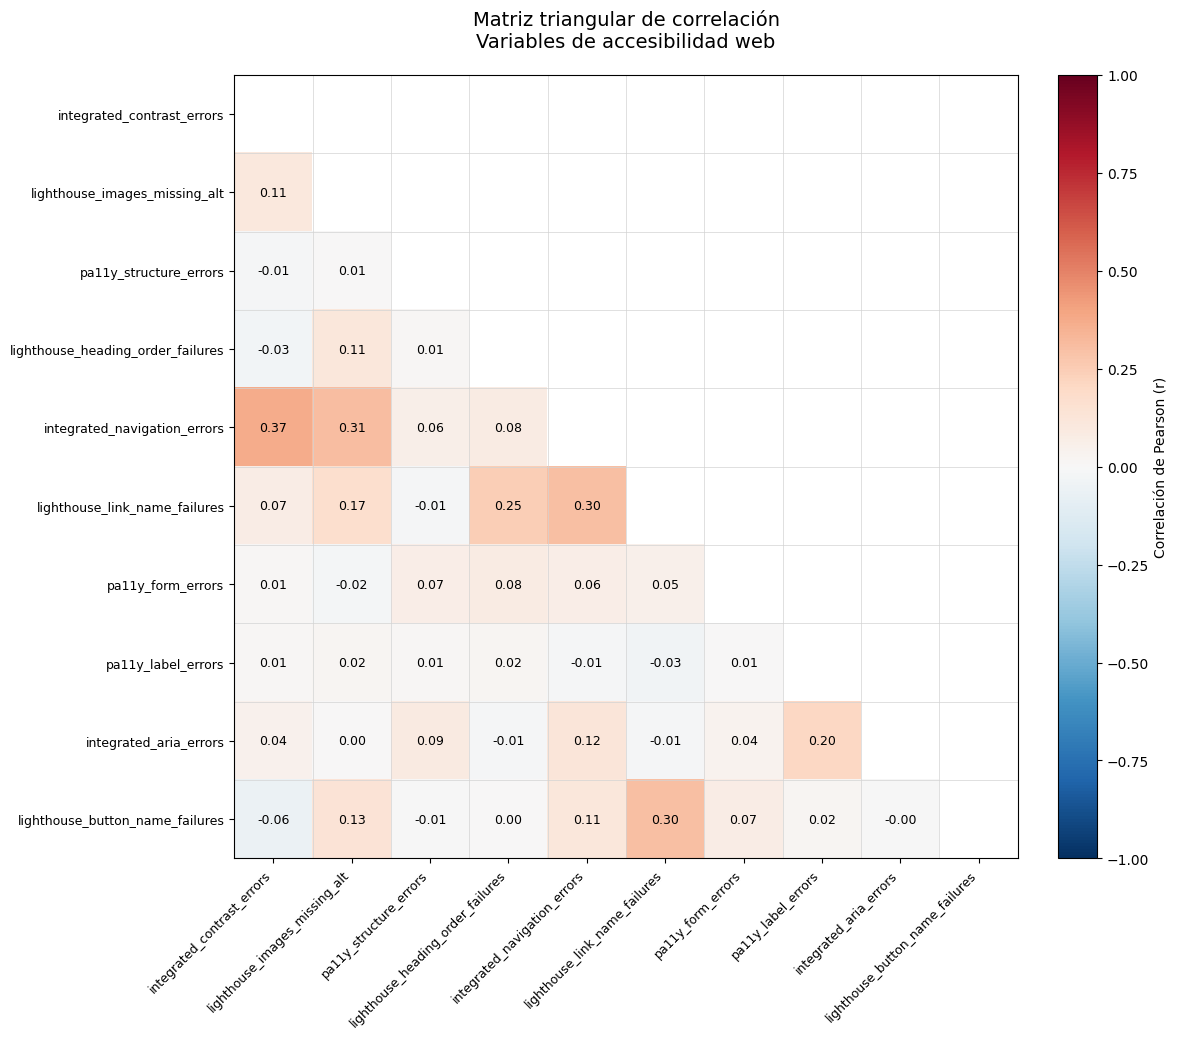


🔥 PAREJAS CON MAYOR CORRELACIÓN
----------------------------------------------------------------------


,variable_1,variable_2,correlacion,correlacion_abs
0,integrated_contrast_errors,integrated_navigation_errors,0.370578,0.370578
1,lighthouse_images_missing_alt,integrated_navigation_errors,0.306348,0.306348
2,lighthouse_link_name_failures,lighthouse_button_name_failures,0.304440,0.304440
3,integrated_navigation_errors,lighthouse_link_name_failures,0.304274,0.304274
4,lighthouse_heading_order_failures,lighthouse_link_name_failures,0.247231,0.247231
5,pa11y_label_errors,integrated_aria_errors,0.204845,0.204845
6,lighthouse_images_missing_alt,lighthouse_link_name_failures,0.168976,0.168976
7,lighthouse_images_missing_alt,lighthouse_button_name_failures,0.132892,0.132892
8,integrated_navigation_errors,integrated_aria_errors,0.118032,0.118032
9,lighthouse_images_missing_alt,lighthouse_heading_order_failures,0.112280,0.112280


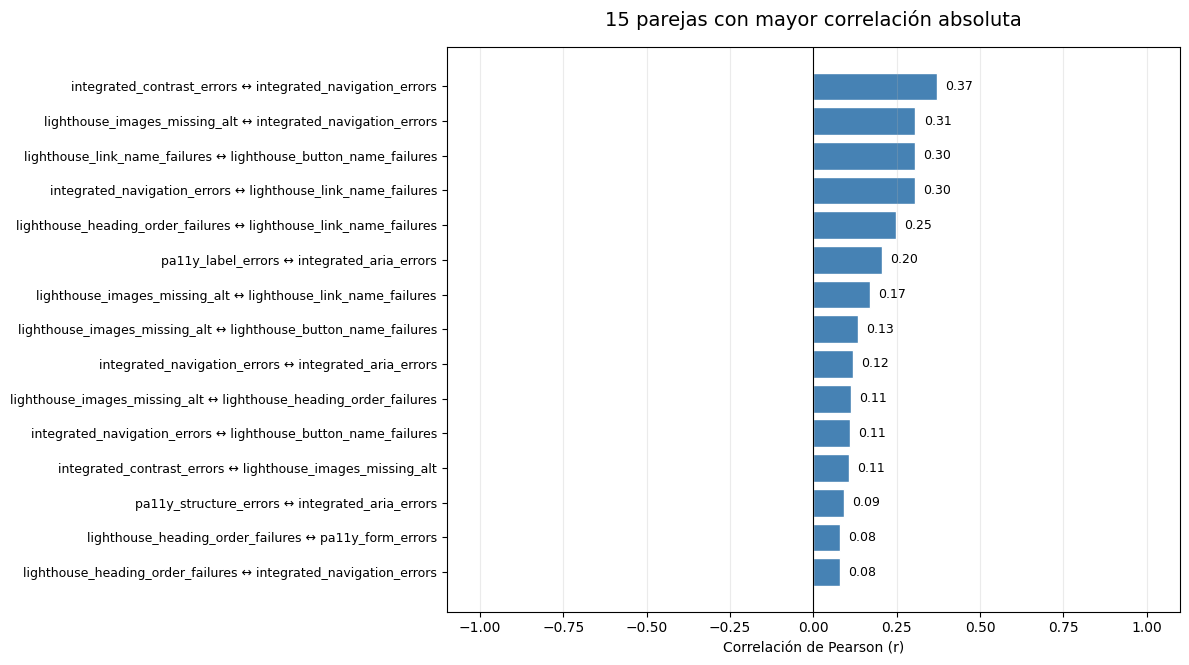


🔎 GRÁFICAS DE DISPERSIÓN
----------------------------------------------------------------------


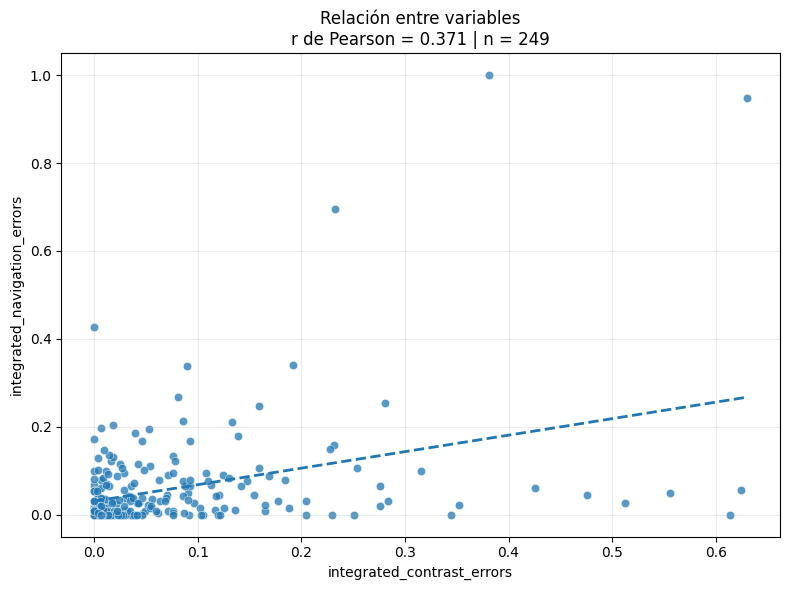

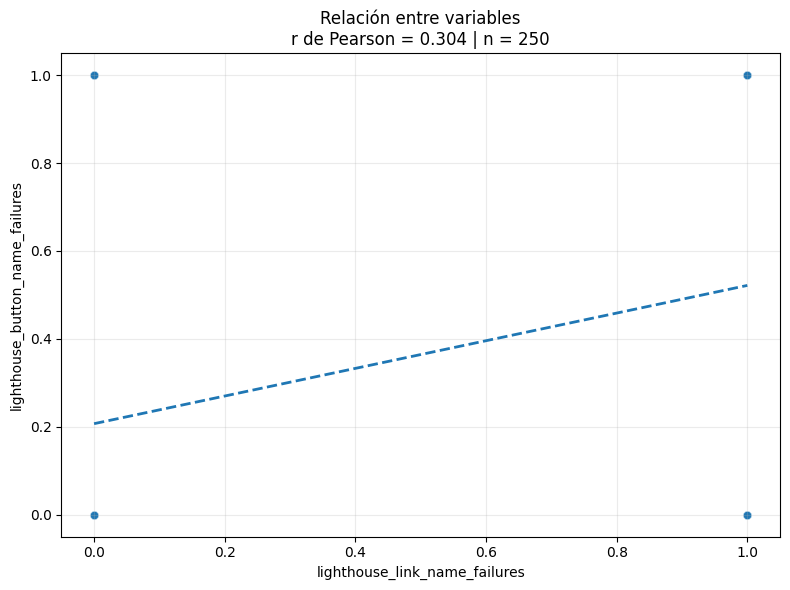

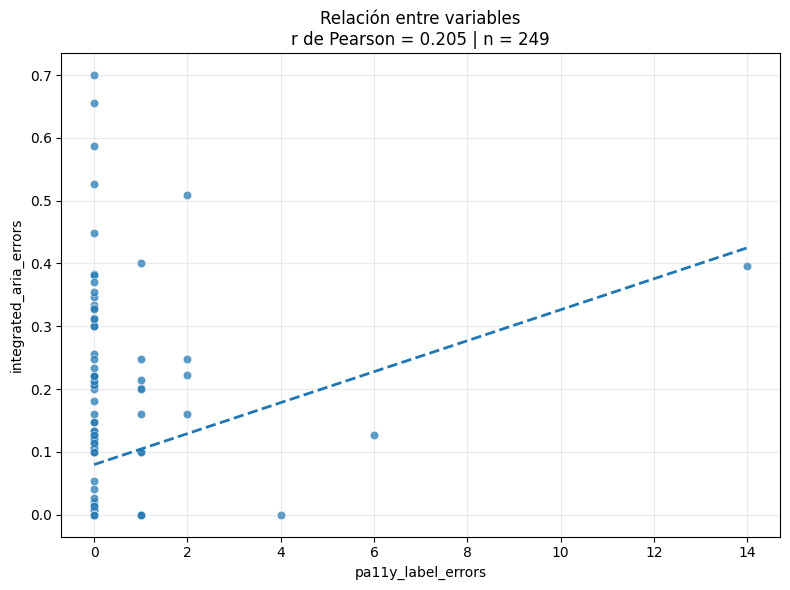


💾 RESULTADOS GUARDADOS
📁 Carpeta: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/1. Matriz_Correlacion
📄 Matriz CSV: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/1. Matriz_Correlacion/matriz_correlacion.csv
📄 Parejas CSV: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/1. Matriz_Correlacion/pares_correlacion.csv
🖼️ Matriz triangular: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/1. Matriz_Correlacion/matriz_correlacion_triangular.png
🖼️ Ranking de parejas: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/1. Matriz_Correlacion/top_15_pares_correlacion.png
📈 Gráficas de dispersión generadas: 3

✅ ANÁLISIS DE CORRELACIONES FINALIZADO


In [ ]:
# ============================================================
# 6.2.1 VALIDACIÓN DE CORRELACIONES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ============================================================
# RUTA BASE DEL DATASET CONSOLIDADO
# ============================================================

RUTA_DATASET_CONSOLIDADO = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado"
)

RUTA_SELECCION_VARIABLES = os.path.join(
    RUTA_DATASET_CONSOLIDADO,
    "1. Seleccion_Variables_Dataset_Consolidado"
)

# ============================================================
# DATASET CONSOLIDADO
# ============================================================

CSV_CONSOLIDADO = os.path.join(
    RUTA_SELECCION_VARIABLES,
    "dataset_consolidado.csv"
)

if not os.path.isfile(CSV_CONSOLIDADO):
    raise FileNotFoundError(
        f"No se encontró el dataset consolidado:\n"
        f"{CSV_CONSOLIDADO}"
    )

# ============================================================
# CARGAR DATASET
# ============================================================

df_consolidado = pd.read_csv(CSV_CONSOLIDADO)

print("\n✅ DATASET CONSOLIDADO CARGADO")
print("=" * 70)
print(f"🌐 Sitios: {len(df_consolidado)}")
print(f"📊 Columnas: {len(df_consolidado.columns)}")

# ============================================================
# VARIABLES ANALÍTICAS
# ============================================================

columnas_identificadoras = ["url", "site_key"]

variables_analiticas = [
    col
    for col in df_consolidado.columns
    if col not in columnas_identificadoras
]

df_numerico = (
    df_consolidado[variables_analiticas]
    .apply(pd.to_numeric, errors="coerce")
)

print(f"📈 Variables analíticas: {df_numerico.shape[1]}")

# ============================================================
# VALIDACIÓN DE VALORES FALTANTES
# ============================================================

faltantes = df_numerico.isna().sum()
faltantes = faltantes[faltantes > 0]

print("\n🔎 VALORES FALTANTES")
print("-" * 70)

if faltantes.empty:
    print("✅ No existen valores faltantes.")
else:
    display(
        faltantes.sort_values(ascending=False)
        .rename("valores_faltantes")
        .to_frame()
    )
    print(
        "⚠️ Las correlaciones se calcularán con las "
        "observaciones disponibles para cada pareja."
    )

# ============================================================
# VARIABLES CONSTANTES O SIN DATOS
# ============================================================

constantes = [
    col
    for col in df_numerico.columns
    if df_numerico[col].nunique(dropna=True) <= 1
]

print("\n⚠️ VARIABLES CONSTANTES O SIN VARIACIÓN")
print("-" * 70)

if constantes:
    for col in constantes:
        print(f"❌ {col}")

    df_numerico = df_numerico.drop(columns=constantes)
else:
    print("✅ No se encontraron variables constantes.")

if df_numerico.shape[1] < 2:
    raise ValueError(
        "Se necesitan al menos dos variables numéricas "
        "válidas para calcular correlaciones."
    )

# ============================================================
# MATRIZ DE CORRELACIÓN
# ============================================================

matriz_corr = df_numerico.corr(
    method="pearson",
    min_periods=3
)

print("\n📊 MATRIZ DE CORRELACIÓN CALCULADA")
print("-" * 70)
print(f"Variables evaluadas: {len(matriz_corr.columns)}")

# ============================================================
# RUTAS DE SALIDA
# ============================================================

RUTA_ANALISIS_DISTRIBUCION = os.path.join(
    RUTA_DATASET_CONSOLIDADO,
    "2. Analisis_Distribucion"
)

RUTA_CORRELACION = os.path.join(
    RUTA_ANALISIS_DISTRIBUCION,
    "1. Matriz_Correlacion"
)

os.makedirs(RUTA_CORRELACION, exist_ok=True)

# ============================================================
# GRÁFICA 1: MATRIZ TRIANGULAR DE CORRELACIÓN
# ============================================================

n = len(matriz_corr.columns)
valores = matriz_corr.to_numpy(dtype=float)

mascara = np.triu(
    np.ones_like(valores, dtype=bool),
    k=0
)

valores_mostrados = np.ma.array(
    valores,
    mask=mascara
)

fig, ax = plt.subplots(
    figsize=(max(10, n * 1.25), max(8, n * 1.05))
)

cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad(color="white")

imagen = ax.imshow(
    valores_mostrados,
    cmap=cmap,
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="equal"
)

ax.set_xticks(range(n))
ax.set_yticks(range(n))

ax.set_xticklabels(
    matriz_corr.columns,
    rotation=45,
    ha="right",
    fontsize=9
)

ax.set_yticklabels(
    matriz_corr.index,
    fontsize=9
)

for i in range(n):
    for j in range(n):
        valor = valores[i, j]

        if j < i and np.isfinite(valor):
            ax.text(
                j,
                i,
                f"{valor:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color="black"
            )

barra = fig.colorbar(
    imagen,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

barra.set_label("Correlación de Pearson (r)")

ax.set_title(
    "Matriz triangular de correlación\n"
    "Variables de accesibilidad web",
    fontsize=14,
    pad=20
)

ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n, 1), minor=True)

ax.grid(
    which="minor",
    color="lightgray",
    linewidth=0.5
)

ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()

PNG_MATRIZ = os.path.join(
    RUTA_CORRELACION,
    "matriz_correlacion_triangular.png"
)

fig.savefig(PNG_MATRIZ, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ============================================================
# PARES DE VARIABLES
# ============================================================

pares = []

for i in range(len(matriz_corr.columns)):
    for j in range(i + 1, len(matriz_corr.columns)):

        variable_1 = matriz_corr.columns[i]
        variable_2 = matriz_corr.columns[j]
        correlacion = matriz_corr.iloc[i, j]

        if np.isfinite(correlacion):
            pares.append({
                "variable_1": variable_1,
                "variable_2": variable_2,
                "correlacion": correlacion,
                "correlacion_abs": abs(correlacion)
            })

df_correlaciones = pd.DataFrame(
    pares,
    columns=[
        "variable_1",
        "variable_2",
        "correlacion",
        "correlacion_abs"
    ]
)

if not df_correlaciones.empty:
    df_correlaciones = (
        df_correlaciones
        .sort_values("correlacion_abs", ascending=False)
        .reset_index(drop=True)
    )

# ============================================================
# GRÁFICA 2: RANKING DE LAS 15 PAREJAS MÁS CORRELACIONADAS
# ============================================================

print("\n🔥 PAREJAS CON MAYOR CORRELACIÓN")
print("-" * 70)

if df_correlaciones.empty:
    print("⚠️ No hay parejas válidas para graficar.")
else:
    display(df_correlaciones.head(15))

    top = (
        df_correlaciones.head(15)
        .sort_values("correlacion")
        .copy()
    )

    etiquetas = (
        top["variable_1"] + " ↔ " + top["variable_2"]
    )

    colores = [
        "steelblue" if valor >= 0 else "indianred"
        for valor in top["correlacion"]
    ]

    fig, ax = plt.subplots(
        figsize=(12, max(6, len(top) * 0.45))
    )

    posiciones = np.arange(len(top))

    ax.barh(
        posiciones,
        top["correlacion"],
        color=colores,
        edgecolor="white"
    )

    ax.set_yticks(posiciones)
    ax.set_yticklabels(etiquetas, fontsize=9)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlim(-1.10, 1.10)

    ax.set_xlabel("Correlación de Pearson (r)")
    ax.set_title(
        "15 parejas con mayor correlación absoluta",
        fontsize=14,
        pad=15
    )

    ax.grid(axis="x", alpha=0.25)

    for posicion, valor in enumerate(top["correlacion"]):
        ax.text(
            valor + (0.025 if valor >= 0 else -0.025),
            posicion,
            f"{valor:.2f}",
            va="center",
            ha="left" if valor >= 0 else "right",
            fontsize=9
        )

    plt.tight_layout()

    PNG_PARES = os.path.join(
        RUTA_CORRELACION,
        "top_15_pares_correlacion.png"
    )

    fig.savefig(PNG_PARES, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

# ============================================================
# GRÁFICAS 3: DISPERSIÓN DE PAREJAS SELECCIONADAS
# ============================================================

# Seleccionar automáticamente hasta 3 parejas distintas
# con correlaciones válidas y mayor correlación absoluta.
MAX_DISPERSIONES = 3

parejas_dispersion = []
variables_usadas = set()

for _, fila in df_correlaciones.iterrows():

    v1 = fila["variable_1"]
    v2 = fila["variable_2"]

    # Evitar que todas las gráficas repitan una misma variable
    if v1 in variables_usadas or v2 in variables_usadas:
        continue

    parejas_dispersion.append((v1, v2))
    variables_usadas.update([v1, v2])

    if len(parejas_dispersion) >= MAX_DISPERSIONES:
        break

print("\n🔎 GRÁFICAS DE DISPERSIÓN")
print("-" * 70)

if not parejas_dispersion:
    print("⚠️ No hay parejas válidas para generar dispersiones.")
else:
    for numero, (v1, v2) in enumerate(parejas_dispersion, start=1):

        datos = df_numerico[[v1, v2]].dropna()

        if len(datos) < 3:
            print(f"⚠️ Se omite {v1} frente a {v2}: datos insuficientes.")
            continue

        r = datos[v1].corr(datos[v2], method="pearson")

        fig, ax = plt.subplots(figsize=(8, 6))

        ax.scatter(
            datos[v1],
            datos[v2],
            alpha=0.75,
            edgecolors="white",
            linewidths=0.4
        )

        # Línea de tendencia solo si ambas variables varían
        if datos[v1].nunique() > 1 and datos[v2].nunique() > 1:
            pendiente, intercepto = np.polyfit(
                datos[v1],
                datos[v2],
                1
            )

            x_linea = np.linspace(
                datos[v1].min(),
                datos[v1].max(),
                100
            )

            ax.plot(
                x_linea,
                pendiente * x_linea + intercepto,
                linestyle="--",
                linewidth=2
            )

        ax.set_xlabel(v1)
        ax.set_ylabel(v2)

        ax.set_title(
            f"Relación entre variables\n"
            f"r de Pearson = {r:.3f} | n = {len(datos)}",
            fontsize=12
        )

        ax.grid(alpha=0.25)
        plt.tight_layout()

        PNG_DISPERSION = os.path.join(
            RUTA_CORRELACION,
            f"dispersion_{numero}_{v1}_vs_{v2}.png"
        )

        fig.savefig(
            PNG_DISPERSION,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

# ============================================================
# GUARDAR RESULTADOS CSV
# ============================================================

CSV_MATRIZ = os.path.join(
    RUTA_CORRELACION,
    "matriz_correlacion.csv"
)

CSV_PARES = os.path.join(
    RUTA_CORRELACION,
    "pares_correlacion.csv"
)

matriz_corr.to_csv(
    CSV_MATRIZ,
    encoding="utf-8-sig"
)

df_correlaciones.to_csv(
    CSV_PARES,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# ELIMINAR CSV VACÍO DE CORRELACIONES FUERTES
# ============================================================

CSV_FUERTES_ANTERIOR = os.path.join(
    RUTA_CORRELACION,
    "correlaciones_fuertes.csv"
)

if os.path.isfile(CSV_FUERTES_ANTERIOR):
    os.remove(CSV_FUERTES_ANTERIOR)
    print("\n🧹 Se eliminó el archivo redundante:")
    print(CSV_FUERTES_ANTERIOR)

# ============================================================
# RESULTADO FINAL
# ============================================================

print("\n💾 RESULTADOS GUARDADOS")
print("=" * 70)

print(f"📁 Carpeta: {RUTA_CORRELACION}")
print(f"📄 Matriz CSV: {CSV_MATRIZ}")
print(f"📄 Parejas CSV: {CSV_PARES}")
print(f"🖼️ Matriz triangular: {PNG_MATRIZ}")

if not df_correlaciones.empty:
    print(
        "🖼️ Ranking de parejas: "
        + os.path.join(
            RUTA_CORRELACION,
            "top_15_pares_correlacion.png"
        )
    )

print(
    f"📈 Gráficas de dispersión generadas: "
    f"{len(parejas_dispersion)}"
)

print("\n✅ ANÁLISIS DE CORRELACIONES FINALIZADO")

##### **6.2.2 Transformación Logarítmica Exploratoria**


La transformación logarítmica exploratoria se realizó con el propósito de analizar el comportamiento de la distribución de las 10 variables analíticas del dataset consolidado y evaluar si la aplicación de una transformación log(1+x) permitía reducir su nivel de asimetría. Para ello, se calculó la asimetría de cada variable en su escala original y posteriormente se aplicó la transformación logarítmica únicamente sobre variables con valores no negativos, utilizando log(1+x), lo que permite trabajar también con variables que contienen ceros. Se compararon las distribuciones originales y transformadas mediante histogramas y se cuantificó el cambio en la asimetría absoluta, estableciendo una tolerancia de 0.01 para distinguir entre mejoras, cambios no relevantes y empeoramientos. Este procedimiento tuvo carácter exploratorio y no modificó el dataset original ni determinó por sí solo qué variables serían utilizadas posteriormente en el clustering.


In [ ]:

# ============================================================
# 6.2.2. TRANSFORMACIÓN LOGARÍTMICA EXPLORATORIA
# Clasificación de Sitios Web por Accesibilidad mediante Clustering
# Multidimensional
# ============================================================

import os
import warnings
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
logging.getLogger().setLevel(logging.ERROR)

# ============================================================
# 1. CONFIGURACIÓN DE RUTAS
# ============================================================

# Conserva BASE_DIR si ya fue definido en otra celda.
if "BASE_DIR" not in globals():
    BASE_DIR = (
        "/content/drive/MyDrive/Trabajo de Grado/"
        "Archivos_Generados"
    )

RUTA_DATASET = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "1. Seleccion_Variables_Dataset_Consolidado",
    "dataset_consolidado.csv"
)

# Carpeta única para los resultados del 6.2.2.
RUTA_ANALISIS = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "2. Analisis_Distribucion",
    "2. Transformacion_Logaritmica"
)

RUTA_GRAFICAS = os.path.join(
    RUTA_ANALISIS,
    "graficas"
)

os.makedirs(RUTA_ANALISIS, exist_ok=True)
os.makedirs(RUTA_GRAFICAS, exist_ok=True)

# ============================================================
# 2. PARÁMETROS DE EVALUACIÓN
# ============================================================

# Criterios exploratorios definidos antes de evaluar:
#
# 1. Asimetría absoluta original >= 1.
# 2. Reducción absoluta de asimetría >= 0.10.
# 3. Reducción porcentual de asimetría >= 20 %.
# 4. Al menos 10 observaciones válidas.
# 5. Todos los valores observados deben ser >= 0.
#
# Cumplir estos criterios identifica una candidata a transformación.
# La decisión debe interpretarse junto con las gráficas y el contexto
# de cada variable. No constituye por sí sola una prueba estadística.

UMBRAL_ASIMETRIA = 1.0
REDUCCION_ABSOLUTA_MINIMA = 0.10
REDUCCION_PORCENTUAL_MINIMA = 20.0
MIN_OBSERVACIONES = 10

BINS = 12
DPI = 250

# ============================================================
# 3. CARGA Y VALIDACIÓN DEL DATASET
# ============================================================

if not os.path.isfile(RUTA_DATASET):
    raise FileNotFoundError(
        "No se encontró el dataset consolidado:\n"
        f"{RUTA_DATASET}\n\n"
        "Verifica la ruta y que Google Drive esté montado."
    )

df_original = pd.read_csv(RUTA_DATASET)

print("=" * 75)
print("6.2.2. TRANSFORMACIÓN LOGARÍTMICA EXPLORATORIA")
print("=" * 75)

print(f"\nDataset: {RUTA_DATASET}")
print(f"Sitios registrados: {len(df_original)}")
print(f"Columnas totales: {len(df_original.columns)}")

# ============================================================
# 3.1. VARIABLES ANALÍTICAS DESDE LA METADATA CONSOLIDADA
# ============================================================

# La celda donde se define variables_consolidadas debe ejecutarse
# antes de esta celda.
if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'.\n"
        "Ejecuta primero la celda donde defines la metadata "
        "de las variables consolidadas."
    )

if not isinstance(variables_consolidadas, dict):
    raise TypeError(
        "'variables_consolidadas' debe ser un diccionario "
        "con los nombres de las variables como claves."
    )

# Obtiene automáticamente los nombres de las variables.
VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        "Se esperaban exactamente 10 variables en "
        f"'variables_consolidadas', pero se encontraron {len(VARIABLES)}."
    )

variables_faltantes = [
    variable for variable in VARIABLES
    if variable not in df_original.columns
]

if variables_faltantes:
    raise ValueError(
        "Faltan variables definidas en 'variables_consolidadas' "
        "dentro del dataset consolidado:\n"
        + "\n".join(f"- {variable}" for variable in variables_faltantes)
    )

print("\nVariables analíticas obtenidas desde variables_consolidadas:")
for i, variable in enumerate(VARIABLES, start=1):
    print(f"{i:02d}. {variable}")
print(f"Total de variables: {len(VARIABLES)}")

# Copia de trabajo: nunca modificamos el archivo original.
df_trabajo = df_original.copy()

for variable in VARIABLES:
    df_trabajo[variable] = pd.to_numeric(
        df_trabajo[variable],
        errors="coerce"
    )

# Los infinitos no se consideran observaciones válidas.
df_trabajo[VARIABLES] = df_trabajo[VARIABLES].replace(
    [np.inf, -np.inf],
    np.nan
)

print("\nValores faltantes por variable:")
display(
    df_trabajo[VARIABLES]
    .isna()
    .sum()
    .rename("valores_faltantes")
    .to_frame()
)

print(
    "\nNota: los valores faltantes se conservan. "
    "No se inventan observaciones ni se imputan automáticamente."
)

# ============================================================
# 4. EVALUACIÓN DE CADA VARIABLE
# ============================================================

resultados = []
datos_comparacion = {}

for variable in VARIABLES:

    # Serie original con observaciones válidas.
    serie_original = df_trabajo[variable].replace(
        [np.inf, -np.inf],
        np.nan
    )

    valores_validos = serie_original.dropna()
    n_validos = len(valores_validos)

    minimo = (
        valores_validos.min()
        if n_validos > 0 else np.nan
    )

    maximo = (
        valores_validos.max()
        if n_validos > 0 else np.nan
    )

    asimetria_original = (
        valores_validos.skew()
        if n_validos >= 3 else np.nan
    )

    asimetria_log = np.nan
    reduccion_absoluta = np.nan
    reduccion_porcentual = np.nan

    decision = "REVISAR"
    justificacion = ""

    # --------------------------------------------------------
    # 4.1. Validar suficiencia de los datos
    # --------------------------------------------------------

    if n_validos < MIN_OBSERVACIONES:

        decision = "REVISAR"
        justificacion = (
            f"Solo hay {n_validos} observaciones válidas; "
            "no alcanza el mínimo definido."
        )

        serie_log = None

    # --------------------------------------------------------
    # 4.2. Verificar si log(1+x) es aplicable
    # --------------------------------------------------------

    elif (valores_validos < 0).any():

        decision = "REVISAR"
        justificacion = (
            "Existen valores negativos. "
            "No se aplica log(1+x) automáticamente."
        )

        serie_log = None

    # --------------------------------------------------------
    # 4.3. Evaluar la transformación candidata
    # --------------------------------------------------------

    else:

        # Se conserva el índice original y los valores faltantes.
        serie_log = np.log1p(serie_original)

        valores_log_validos = serie_log.dropna()

        asimetria_log = (
            valores_log_validos.skew()
            if len(valores_log_validos) >= 3 else np.nan
        )

        if pd.isna(asimetria_original) or pd.isna(asimetria_log):

            decision = "REVISAR"
            justificacion = (
                "No fue posible calcular de manera válida "
                "la asimetría original o transformada."
            )

        else:

            abs_original = abs(asimetria_original)
            abs_log = abs(asimetria_log)

            # Positivo: disminuye la asimetría absoluta.
            # Negativo: aumenta la asimetría absoluta.
            reduccion_absoluta = abs_original - abs_log

            if abs_original > 0:
                reduccion_porcentual = (
                    reduccion_absoluta / abs_original
                ) * 100

            # ------------------------------------------------
            # 4.4. Aplicar criterios de decisión
            # ------------------------------------------------

            cumple_asimetria = (
                abs_original >= UMBRAL_ASIMETRIA
            )

            cumple_reduccion_absoluta = (
                reduccion_absoluta
                >= REDUCCION_ABSOLUTA_MINIMA
            )

            cumple_reduccion_porcentual = (
                reduccion_porcentual
                >= REDUCCION_PORCENTUAL_MINIMA
            )

            if (
                cumple_asimetria
                and cumple_reduccion_absoluta
                and cumple_reduccion_porcentual
            ):

                decision = "TRANSFORMAR"

                justificacion = (
                    "Asimetría original elevada y reducción "
                    "suficiente según los criterios definidos. "
                    "Candidata a transformación."
                )

            elif not cumple_asimetria:

                decision = "NO TRANSFORMAR"

                justificacion = (
                    "La asimetría original no alcanza el umbral "
                    "definido para justificar la transformación."
                )

            else:

                decision = "NO TRANSFORMAR"

                justificacion = (
                    "La reducción de asimetría no cumple todos "
                    "los criterios establecidos."
                )

    # --------------------------------------------------------
    # 4.5. Guardar resultados
    # --------------------------------------------------------

    resultados.append({
        "variable": variable,
        "n_validos": n_validos,
        "valores_faltantes": int(
            serie_original.isna().sum()
        ),
        "minimo": minimo,
        "maximo": maximo,
        "asimetria_original": asimetria_original,
        "asimetria_log1p": asimetria_log,
        "reduccion_absoluta_asimetria": reduccion_absoluta,
        "reduccion_porcentual_asimetria": reduccion_porcentual,
        "decision": decision,
        "justificacion": justificacion
    })

    datos_comparacion[variable] = {
        "original": serie_original,
        "log1p": serie_log
    }

# Tabla completa de evaluación.
df_resultados = pd.DataFrame(resultados)

print("\n" + "=" * 75)
print("RESULTADOS DE LA EVALUACIÓN")
print("=" * 75)

display(
    df_resultados.round(4)
)

# ============================================================
# 5. CONSTRUIR EL DATASET SEGÚN LAS DECISIONES
# ============================================================

# Empezamos desde la copia del dataset original.
# Únicamente reemplazamos las variables seleccionadas.
df_transformado = df_original.copy()

# Conservamos la conversión numérica de las variables analíticas
# y los faltantes identificados durante la validación.
for variable in VARIABLES:
    df_transformado[variable] = df_trabajo[variable]

variables_transformadas = df_resultados.loc[
    df_resultados["decision"] == "TRANSFORMAR",
    "variable"
].tolist()

for variable in variables_transformadas:
    df_transformado[variable] = np.log1p(
        df_trabajo[variable]
    )

variables_originales = df_resultados.loc[
    df_resultados["decision"] == "NO TRANSFORMAR",
    "variable"
].tolist()

variables_revisar = df_resultados.loc[
    df_resultados["decision"] == "REVISAR",
    "variable"
].tolist()

# ============================================================
# 6. GUARDAR TABLAS Y DATASET
# ============================================================

RUTA_TABLA_ASIMETRIA = os.path.join(
    RUTA_ANALISIS,
    "comparacion_asimetria_log.csv"
)

RUTA_DECISIONES = os.path.join(
    RUTA_ANALISIS,
    "decision_transformacion.csv"
)

RUTA_DATASET_TRANSFORMADO = os.path.join(
    RUTA_ANALISIS,
    "dataset_consolidado_transformado.csv"
)

df_resultados.to_csv(
    RUTA_TABLA_ASIMETRIA,
    index=False,
    encoding="utf-8-sig"
)

# La tabla de decisiones contiene las métricas y la justificación.
df_resultados.to_csv(
    RUTA_DECISIONES,
    index=False,
    encoding="utf-8-sig"
)

df_transformado.to_csv(
    RUTA_DATASET_TRANSFORMADO,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 7. GRÁFICAS INDIVIDUALES: ANTES Y DESPUÉS
# ============================================================

print("\n" + "=" * 75)
print("GENERACIÓN DE GRÁFICAS INDIVIDUALES")
print("=" * 75)

contador_graficas = 0

for variable in VARIABLES:

    serie_original = datos_comparacion[variable]["original"]
    serie_log = datos_comparacion[variable]["log1p"]

    resultado_variable = df_resultados.loc[
        df_resultados["variable"] == variable
    ].iloc[0]

    decision = resultado_variable["decision"]
    skew_original = resultado_variable["asimetria_original"]
    skew_log = resultado_variable["asimetria_log1p"]

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 4.8)
    )

    # --------------------------------------------------------
    # Gráfica izquierda: datos originales
    # --------------------------------------------------------

    valores_originales = serie_original.dropna()

    if len(valores_originales) > 0:

        axes[0].hist(
            valores_originales,
            bins=BINS,
            edgecolor="black",
            alpha=0.8
        )

        axes[0].set_title(
            f"Antes: {variable}",
            fontsize=11,
            fontweight="bold"
        )

        axes[0].set_xlabel("Valor original")
        axes[0].set_ylabel("Frecuencia")
        axes[0].grid(axis="y", alpha=0.25)

        if pd.notna(skew_original):
            axes[0].text(
                0.98,
                0.95,
                f"Asimetría = {skew_original:.3f}",
                transform=axes[0].transAxes,
                ha="right",
                va="top",
                fontsize=9
            )

    else:

        axes[0].text(
            0.5, 0.5,
            "Sin observaciones válidas",
            ha="center",
            va="center",
            transform=axes[0].transAxes
        )

    # --------------------------------------------------------
    # Gráfica derecha: candidato log(1+x)
    # --------------------------------------------------------

    if serie_log is not None and not serie_log.dropna().empty:

        valores_log = serie_log.dropna()

        axes[1].hist(
            valores_log,
            bins=BINS,
            edgecolor="black",
            alpha=0.8
        )

        axes[1].set_title(
            "Después: candidato log(1+x)",
            fontsize=11,
            fontweight="bold"
        )

        axes[1].set_xlabel("Valor transformado")
        axes[1].set_ylabel("Frecuencia")
        axes[1].grid(axis="y", alpha=0.25)

        if pd.notna(skew_log):
            axes[1].text(
                0.98,
                0.95,
                f"Asimetría = {skew_log:.3f}",
                transform=axes[1].transAxes,
                ha="right",
                va="top",
                fontsize=9
            )

    else:

        axes[1].text(
            0.5, 0.5,
            "Transformación no evaluable",
            ha="center",
            va="center",
            transform=axes[1].transAxes
        )

        axes[1].set_title(
            "Después: no evaluable",
            fontsize=11,
            fontweight="bold"
        )

    # --------------------------------------------------------
    # Título general y decisión
    # --------------------------------------------------------

    fig.suptitle(
        f"{variable} | Decisión: {decision}",
        fontsize=13,
        fontweight="bold"
    )

    fig.tight_layout(rect=[0, 0, 1, 0.92])

    nombre_archivo = f"{variable}_comparacion.png"

    ruta_grafica = os.path.join(
        RUTA_GRAFICAS,
        nombre_archivo
    )

    fig.savefig(
        ruta_grafica,
        dpi=DPI,
        bbox_inches="tight"
    )

    plt.close(fig)
    contador_graficas += 1

print(f"Gráficas individuales guardadas: {contador_graficas}")

# ============================================================
# 8. GRÁFICA RESUMEN DEL CAMBIO DE ASIMETRÍA
# ============================================================

df_plot = df_resultados.dropna(
    subset=["reduccion_absoluta_asimetria"]
).copy()

RUTA_RESUMEN_ASIMETRIA = os.path.join(
    RUTA_ANALISIS,
    "resumen_asimetria_log.png"
)

if not df_plot.empty:

    df_plot = df_plot.sort_values(
        "reduccion_absoluta_asimetria",
        ascending=True
    )

    valores = df_plot[
        "reduccion_absoluta_asimetria"
    ].to_numpy()

    etiquetas = df_plot["variable"].to_numpy()

    colores = [
        "seagreen" if valor > 0
        else "indianred" if valor < 0
        else "gray"
        for valor in valores
    ]

    fig, ax = plt.subplots(figsize=(12, 7))

    ax.barh(
        etiquetas,
        valores,
        color=colores,
        edgecolor="black",
        alpha=0.85
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1
    )

    ax.set_title(
        "Cambio en la asimetría absoluta después de log(1+x)",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "|asimetría original| - |asimetría log(1+x)|"
    )

    ax.set_ylabel("Variable")
    ax.grid(axis="x", alpha=0.25)

    fig.tight_layout()

    fig.savefig(
        RUTA_RESUMEN_ASIMETRIA,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close(fig)

else:
    print(
        "\nNo fue posible generar el resumen de asimetría: "
        "no hay resultados comparables."
    )

# ============================================================
# 9. RESUMEN DE DECISIONES
# ============================================================

print("\n" + "=" * 75)
print("RESUMEN FINAL DEL 6.2.2")
print("=" * 75)

print(f"\nSitios analizados: {len(df_original)}")
print(f"Variables evaluadas: {len(VARIABLES)}")
print(f"Gráficas individuales: {contador_graficas}")

print(
    f"\nVariables seleccionadas para transformar: "
    f"{len(variables_transformadas)}"
)

if variables_transformadas:
    for variable in variables_transformadas:
        print(f"  [TRANSFORMAR] {variable}")
else:
    print("  Ninguna variable cumplió todos los criterios.")

print(
    f"\nVariables que conservan sus valores originales: "
    f"{len(variables_originales)}"
)

for variable in variables_originales:
    print(f"  [ORIGINAL] {variable}")

print(
    f"\nVariables pendientes de revisión: "
    f"{len(variables_revisar)}"
)

for variable in variables_revisar:
    print(f"  [REVISAR] {variable}")

print("\nArchivos generados:")

print(f"  Gráficas individuales: {RUTA_GRAFICAS}")
print(f"  Resumen de asimetría: {RUTA_RESUMEN_ASIMETRIA}")
print(f"  Comparación estadística: {RUTA_TABLA_ASIMETRIA}")
print(f"  Decisiones justificadas: {RUTA_DECISIONES}")
print(f"  Dataset transformado: {RUTA_DATASET_TRANSFORMADO}")

print("\n" + "=" * 75)
print("6.2.2 FINALIZADO")
print("=" * 75)

print(
    "\nIMPORTANTE: el dataset transformado conserva los valores "
    "faltantes. Antes de PCA y K-Means, debes documentar y aplicar "
    "un tratamiento adecuado para ellos y estandarizar las variables."
)

print(
    "\nLa transformación logarítmica es exploratoria: las decisiones "
    "se basan en los criterios definidos y deben revisarse junto "
    "con las gráficas y el significado de cada variable."
)

6.2.2. TRANSFORMACIÓN LOGARÍTMICA EXPLORATORIA

Dataset: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/1. Seleccion_Variables_Dataset_Consolidado/dataset_consolidado.csv
Sitios registrados: 250
Columnas totales: 12

Variables analíticas obtenidas desde variables_consolidadas:
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures
Total de variables: 10

Valores faltantes por variable:


,valores_faltantes
integrated_contrast_errors,0
lighthouse_images_missing_alt,0
pa11y_structure_errors,1
lighthouse_heading_order_failures,0
integrated_navigation_errors,1
lighthouse_link_name_failures,0
pa11y_form_errors,1
pa11y_label_errors,1
integrated_aria_errors,0
lighthouse_button_name_failures,0



Nota: los valores faltantes se conservan. No se inventan observaciones ni se imputan automáticamente.

RESULTADOS DE LA EVALUACIÓN


,variable,n_validos,valores_faltantes,minimo,maximo,asimetria_original,asimetria_log1p,reduccion_absoluta_asimetria,reduccion_porcentual_asimetria,decision,justificacion
0,integrated_contrast_errors,250,0,0.0,0.6305,2.8900,2.4906,0.3995,13.8224,NO TRANSFORMAR,La reducción de asimetría no cumple todos los ...
1,lighthouse_images_missing_alt,250,0,0.0,52.0000,5.8549,2.2996,3.5553,60.7229,TRANSFORMAR,Asimetría original elevada y reducción suficie...
2,pa11y_structure_errors,249,1,0.0,212.0000,7.1692,1.5391,5.6301,78.5322,TRANSFORMAR,Asimetría original elevada y reducción suficie...
3,lighthouse_heading_order_failures,250,0,0.0,1.0000,0.2268,0.2268,-0.0000,-0.0000,NO TRANSFORMAR,La asimetría original no alcanza el umbral def...
4,integrated_navigation_errors,249,1,0.0,1.0000,5.5481,4.3886,1.1594,20.8980,TRANSFORMAR,Asimetría original elevada y reducción suficie...
5,lighthouse_link_name_failures,250,0,0.0,1.0000,-0.6421,-0.6421,0.0000,0.0000,NO TRANSFORMAR,La asimetría original no alcanza el umbral def...
6,pa11y_form_errors,249,1,0.0,330.0000,15.3030,2.3960,12.9070,84.3429,TRANSFORMAR,Asimetría original elevada y reducción suficie...
7,pa11y_label_errors,249,1,0.0,14.0000,10.6169,5.2596,5.3573,50.4603,TRANSFORMAR,Asimetría original elevada y reducción suficie...
8,integrated_aria_errors,250,0,0.0,0.7000,2.1063,1.7291,0.3772,17.9068,NO TRANSFORMAR,La reducción de asimetría no cumple todos los ...
9,lighthouse_button_name_failures,250,0,0.0,1.0000,0.3597,0.3597,-0.0000,-0.0000,NO TRANSFORMAR,La asimetría original no alcanza el umbral def...



GENERACIÓN DE GRÁFICAS INDIVIDUALES
Gráficas individuales guardadas: 10

RESUMEN FINAL DEL 6.2.2

Sitios analizados: 250
Variables evaluadas: 10
Gráficas individuales: 10

Variables seleccionadas para transformar: 5
  [TRANSFORMAR] lighthouse_images_missing_alt
  [TRANSFORMAR] pa11y_structure_errors
  [TRANSFORMAR] integrated_navigation_errors
  [TRANSFORMAR] pa11y_form_errors
  [TRANSFORMAR] pa11y_label_errors

Variables que conservan sus valores originales: 5
  [ORIGINAL] integrated_contrast_errors
  [ORIGINAL] lighthouse_heading_order_failures
  [ORIGINAL] lighthouse_link_name_failures
  [ORIGINAL] integrated_aria_errors
  [ORIGINAL] lighthouse_button_name_failures

Variables pendientes de revisión: 0

Archivos generados:
  Gráficas individuales: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/2. Analisis_Distribucion/2. Transformacion_Logaritmica/graficas
  Resumen de asimetría: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset

### **6.3 Tratamiento de valores faltantes y Detección y análisis de outliers**

En esta etapa se realizó la revisión de valores faltantes y la detección de posibles valores atípicos en las 10 variables analíticas del escenario MX. Los valores faltantes, en caso de presentarse, fueron tratados mediante imputación con la mediana, mientras que los outliers se identificaron utilizando el rango intercuartílico (IQR), diferenciando entre valores moderados (1.5 × IQR) y extremos (3 × IQR). Para conservar la totalidad de los sitios, únicamente los valores extremos fueron ajustados mediante winsorización, manteniendo los outliers moderados sin modificación.


6.3. TRATAMIENTO DE VALORES FALTANTES Y OUTLIERS
Registros iniciales: 250
Variables obtenidas desde la metadata: 10

Variables analizadas:
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures
integrated_contrast_errors: 10 outliers extremos detectados; 0 faltantes imputados; Limitación por límites extremos IQR.
lighthouse_images_missing_alt: 18 outliers extremos detectados; 0 faltantes imputados; Limitación por límites extremos IQR.
pa11y_structure_errors: 0 outliers extremos detectados; 1 faltantes imputados; Limitación por límites extremos IQR.
lighthouse_heading_order_failures: 0 outliers extremos detectados; 0 faltantes imputados; Limitación por límites extremos IQR.
integrated_navigation_errors: 6 outliers extremos detectados; 1 falt

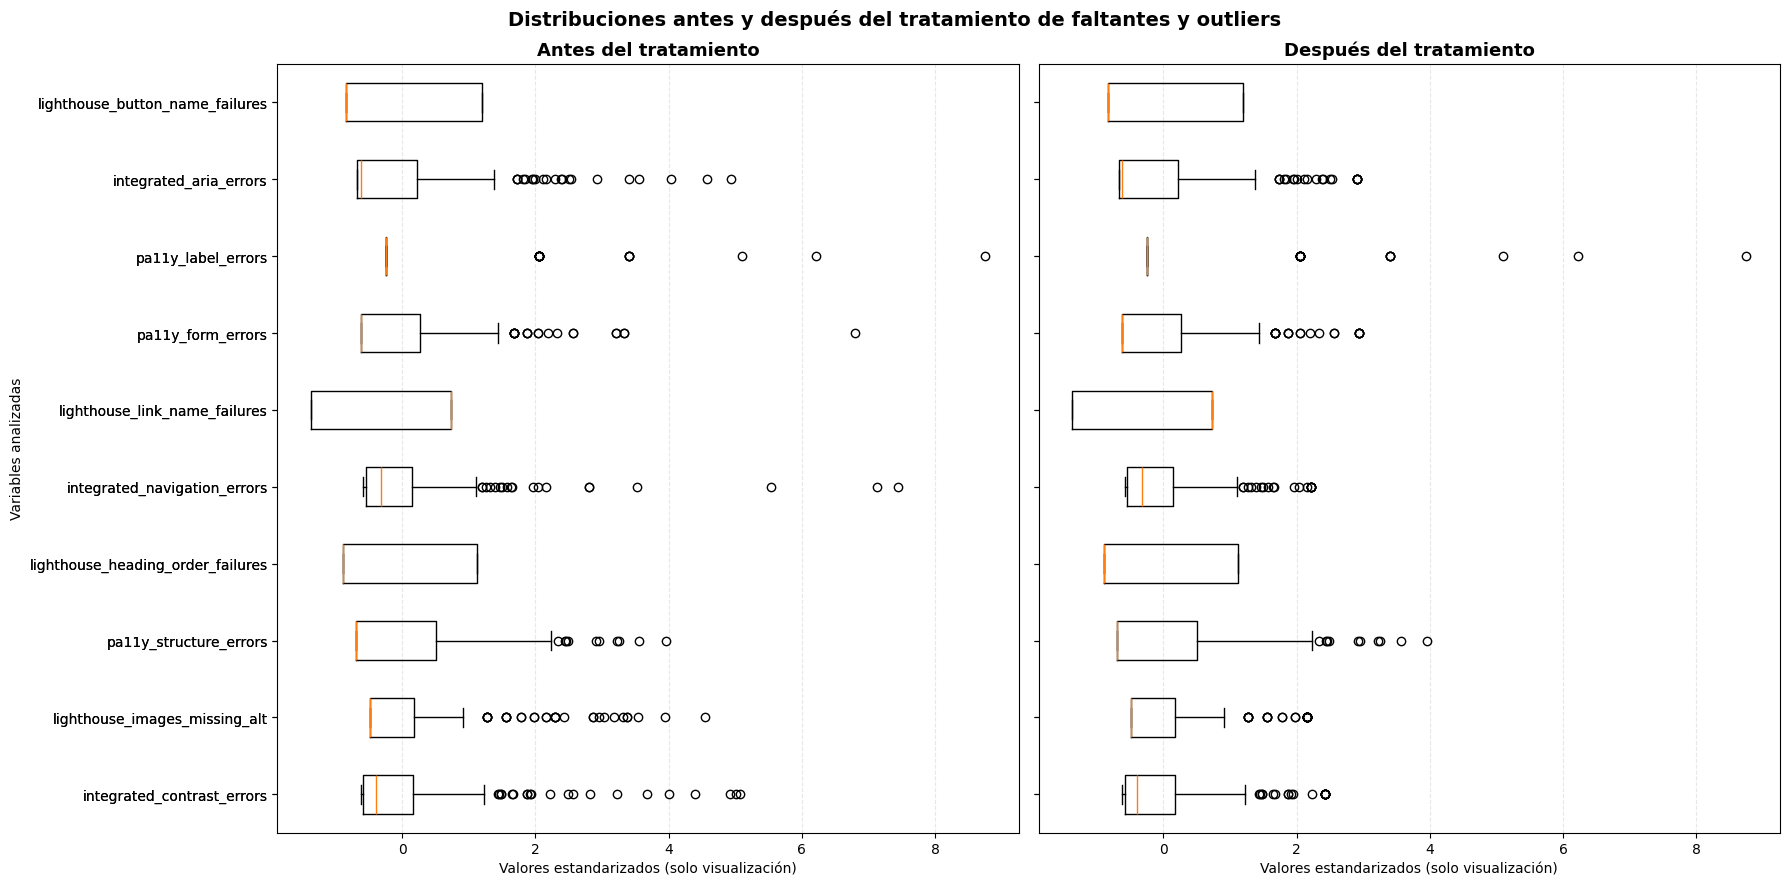


PROCESO COMPLETADO
Registros conservados: 250
Variables tratadas: 10
Valores faltantes finales: 0
Valores infinitos finales: 0

Archivos generados:
1. Dataset tratado:
   /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/3. Tratamiento_Outliers/dataset_consolidado_tratado.csv
2. Comparación estadística:
   /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/3. Tratamiento_Outliers/comparacion_antes_despues.csv
3. Gráfica comparativa:
   /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/3. Tratamiento_Outliers/boxplot_antes_despues.png

Resumen de resultados:


,variable,faltantes_iniciales,faltantes_imputados,outliers_extremos_detectados,metodo_outliers,Q1,Q3,IQR,limite_inferior,limite_superior,mediana_imputacion,media_antes,media_despues,mediana_antes,mediana_despues,minimo_antes,minimo_despues,maximo_antes,maximo_despues
0,integrated_contrast_errors,0,0,10,Limitación por límites extremos IQR,0.004,0.087,0.083,-0.246,0.337,0.025,0.068,0.062,0.025,0.025,0.0,0.0,0.630,0.337
1,lighthouse_images_missing_alt,0,0,18,Limitación por límites extremos IQR,0.000,0.520,0.520,-1.560,2.079,0.000,0.380,0.335,0.000,0.000,0.0,0.0,3.970,2.079
2,pa11y_structure_errors,1,1,0,Limitación por límites extremos IQR,0.000,1.386,1.386,-4.159,5.545,0.000,0.797,0.794,0.000,0.000,0.0,0.0,5.361,5.361
3,lighthouse_heading_order_failures,0,0,0,Limitación por límites extremos IQR,0.000,1.000,1.000,-3.000,4.000,0.000,0.444,0.444,0.000,0.000,0.0,0.0,1.000,1.000
4,integrated_navigation_errors,1,1,6,Limitación por límites extremos IQR,0.004,0.063,0.059,-0.174,0.241,0.022,0.050,0.045,0.022,0.022,0.0,0.0,0.693,0.241
5,lighthouse_link_name_failures,0,0,0,Limitación por límites extremos IQR,0.000,1.000,1.000,-3.000,4.000,1.000,0.652,0.652,1.000,1.000,0.0,0.0,1.000,1.000
6,pa11y_form_errors,1,1,5,Limitación por límites extremos IQR,0.000,0.693,0.693,-2.079,2.773,0.000,0.481,0.462,0.000,0.000,0.0,0.0,5.802,2.773
7,pa11y_label_errors,1,1,0,Sin limitación (IQR igual a 0),0.000,0.000,0.000,0.000,0.000,0.000,0.073,0.073,0.000,0.000,0.0,0.0,2.708,2.708
8,integrated_aria_errors,0,0,6,Limitación por límites extremos IQR,0.000,0.112,0.112,-0.335,0.447,0.007,0.084,0.081,0.007,0.007,0.0,0.0,0.700,0.447
9,lighthouse_button_name_failures,0,0,0,Limitación por límites extremos IQR,0.000,1.000,1.000,-3.000,4.000,0.000,0.412,0.412,0.000,0.000,0.0,0.0,1.000,1.000


In [ ]:
# ============================================================
# 6.3. TRATAMIENTO DE VALORES FALTANTES Y OUTLIERS
# Versión simplificada y conectada a variables_consolidadas
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. RUTAS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

CSV_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "2. Analisis_Distribucion",
    "2. Transformacion_Logaritmica",
    "dataset_consolidado_transformado.csv"
)

DIR_SALIDA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "3. Tratamiento_Outliers"
)

os.makedirs(DIR_SALIDA, exist_ok=True)

CSV_FINAL = os.path.join(
    DIR_SALIDA,
    "dataset_consolidado_tratado.csv"
)

CSV_COMPARACION = os.path.join(
    DIR_SALIDA,
    "comparacion_antes_despues.csv"
)

PNG_COMPARACION = os.path.join(
    DIR_SALIDA,
    "boxplot_antes_despues.png"
)

# ------------------------------------------------------------
# 2. VALIDAR METADATA, CARGA Y COLUMNAS
# ------------------------------------------------------------

if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'. "
        "Ejecuta primero la celda donde defines la metadata "
        "de las variables consolidadas."
    )

# Las variables se obtienen automáticamente de la metadata.
VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        "Se esperaban 10 variables en 'variables_consolidadas', "
        f"pero se encontraron {len(VARIABLES)}."
    )

if not os.path.isfile(CSV_ENTRADA):
    raise FileNotFoundError(
        f"No se encontró el dataset de entrada:\n{CSV_ENTRADA}\n\n"
        "Ejecuta primero la celda 6.2.2 de transformación logarítmica."
    )

df = pd.read_csv(CSV_ENTRADA)

IDENTIFICADORES = ["url", "site_key"]
columnas_requeridas = IDENTIFICADORES + VARIABLES

faltantes_columnas = [
    columna for columna in columnas_requeridas
    if columna not in df.columns
]

if faltantes_columnas:
    raise ValueError(
        "Faltan columnas requeridas en el dataset:\n"
        + "\n".join(f"- {columna}" for columna in faltantes_columnas)
    )

if df.empty:
    raise ValueError("El dataset está vacío.")

if df["site_key"].isna().any():
    raise ValueError("Hay registros sin site_key. Revisa los identificadores.")

if df["site_key"].duplicated().any():
    duplicados = int(df["site_key"].duplicated().sum())
    raise ValueError(
        f"Hay {duplicados} valores duplicados en site_key. "
        "Revisa los identificadores antes de continuar."
    )

# Convertir las variables a números. Los valores no convertibles
# se cuentan y se tratan como faltantes para la imputación posterior.
conversiones_invalidas = {}
for variable in VARIABLES:
    serie_convertida = pd.to_numeric(df[variable], errors="coerce")
    mascara_conversion_invalida = df[variable].notna() & serie_convertida.isna()
    conversiones_invalidas[variable] = int(mascara_conversion_invalida.sum())
    df[variable] = serie_convertida

# Los infinitos se consideran valores faltantes.
df[VARIABLES] = df[VARIABLES].replace([np.inf, -np.inf], np.nan)

df_original = df.copy()
df_tratado = df.copy()

print("=" * 72)
print("6.3. TRATAMIENTO DE VALORES FALTANTES Y OUTLIERS")
print("=" * 72)
print(f"Registros iniciales: {len(df_original)}")
print(f"Variables obtenidas desde la metadata: {len(VARIABLES)}")
print("\nVariables analizadas:")
for i, variable in enumerate(VARIABLES, start=1):
    print(f"{i:02d}. {variable}")

if any(conversiones_invalidas.values()):
    print("\nValores no numéricos convertidos a faltantes:")
    for variable, cantidad in conversiones_invalidas.items():
        if cantidad > 0:
            print(f"- {variable}: {cantidad}")

# ------------------------------------------------------------
# 3. DETECCIÓN Y TRATAMIENTO DE OUTLIERS Y FALTANTES
# ------------------------------------------------------------
# Outliers: método IQR con límites extremos Q1 - 3*IQR y Q3 + 3*IQR.
# Los extremos se limitan (winsorización); no se eliminan registros.
# Importante: si IQR = 0, no se limitan los valores de esa variable,
# para evitar convertir en cero/constante variables con muchos ceros.
# Faltantes: imputación por mediana calculada con los valores observados.

FACTOR_IQR = 3
resultados = []

for variable in VARIABLES:
    serie_original = df_original[variable]
    valores_validos = serie_original.dropna()

    if valores_validos.empty:
        raise ValueError(
            f"La variable '{variable}' no tiene valores válidos. "
            "No se puede calcular el IQR ni imputar su mediana."
        )

    # Estadísticas antes del tratamiento.
    media_antes = serie_original.mean()
    mediana_antes = serie_original.median()
    faltantes_antes = int(serie_original.isna().sum())

    # Límites IQR calculados usando datos observados.
    q1 = valores_validos.quantile(0.25)
    q3 = valores_validos.quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - FACTOR_IQR * iqr
    limite_superior = q3 + FACTOR_IQR * iqr

    if pd.isna(iqr) or iqr == 0:
        # Con IQR=0, el criterio marcaría como extremos muchos valores
        # válidos en variables con alta concentración en cero.
        extremos_detectados = 0
        metodo_outliers = "Sin limitación (IQR igual a 0)"
        # Se mantiene la variable tal como está antes de imputar faltantes.
    else:
        mascara_extremos = (
            serie_original.notna()
            & (
                (serie_original < limite_inferior)
                | (serie_original > limite_superior)
            )
        )
        extremos_detectados = int(mascara_extremos.sum())
        df_tratado[variable] = df_tratado[variable].clip(
            lower=limite_inferior,
            upper=limite_superior
        )
        metodo_outliers = "Limitación por límites extremos IQR"

    # Imputar con la mediana de los valores observados originales.
    mediana_imputacion = valores_validos.median()
    df_tratado[variable] = df_tratado[variable].fillna(mediana_imputacion)

    serie_final = df_tratado[variable]

    resultados.append({
        "variable": variable,
        "faltantes_iniciales": faltantes_antes,
        "faltantes_imputados": faltantes_antes,
        "outliers_extremos_detectados": extremos_detectados,
        "metodo_outliers": metodo_outliers,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "limite_inferior": limite_inferior,
        "limite_superior": limite_superior,
        "mediana_imputacion": mediana_imputacion,
        "media_antes": media_antes,
        "media_despues": serie_final.mean(),
        "mediana_antes": mediana_antes,
        "mediana_despues": serie_final.median(),
        "minimo_antes": serie_original.min(),
        "minimo_despues": serie_final.min(),
        "maximo_antes": serie_original.max(),
        "maximo_despues": serie_final.max()
    })

    print(
        f"{variable}: {extremos_detectados} outliers extremos detectados; "
        f"{faltantes_antes} faltantes imputados; {metodo_outliers}."
    )

# ------------------------------------------------------------
# 4. EXPORTAR DATASET TRATADO Y COMPARACIÓN
# ------------------------------------------------------------

comparacion = pd.DataFrame(resultados)

comparacion.to_csv(
    CSV_COMPARACION,
    index=False,
    encoding="utf-8-sig"
)

df_tratado.to_csv(
    CSV_FINAL,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 5. GRÁFICA COMPARATIVA ANTES / DESPUÉS
# ------------------------------------------------------------
# Se estandariza únicamente para la visualización. Se usan la media y la
# desviación estándar originales en AMBOS paneles, para que la comparación
# antes/después mantenga la misma escala. El CSV no se estandariza aquí.

def estandarizar_para_grafica(datos, variables, parametros):
    salida = pd.DataFrame(index=datos.index)

    for variable in variables:
        media, desviacion = parametros[variable]

        if pd.isna(desviacion) or desviacion == 0:
            salida[variable] = 0.0
        else:
            salida[variable] = (datos[variable] - media) / desviacion

    return salida


parametros_grafica = {}
for variable in VARIABLES:
    media = df_original[variable].mean()
    desviacion = df_original[variable].std()
    parametros_grafica[variable] = (media, desviacion)

antes_grafica = estandarizar_para_grafica(
    df_original[VARIABLES], VARIABLES, parametros_grafica
)

despues_grafica = estandarizar_para_grafica(
    df_tratado[VARIABLES], VARIABLES, parametros_grafica
)

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 9),
    sharey=True
)

for ax, datos, titulo in [
    (axes[0], antes_grafica, "Antes del tratamiento"),
    (axes[1], despues_grafica, "Después del tratamiento")
]:
    ax.boxplot(
        [datos[variable].dropna().to_numpy() for variable in VARIABLES],
        vert=False,
        tick_labels=VARIABLES,
        showfliers=True
    )
    ax.set_title(titulo, fontsize=13, fontweight="bold")
    ax.set_xlabel("Valores estandarizados (solo visualización)")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

axes[0].set_ylabel("Variables analizadas")
fig.suptitle(
    "Distribuciones antes y después del tratamiento de faltantes y outliers",
    fontsize=14,
    fontweight="bold"
)
fig.tight_layout()
fig.savefig(PNG_COMPARACION, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 6. VALIDACIÓN FINAL
# ------------------------------------------------------------

faltantes_finales = int(df_tratado[VARIABLES].isna().sum().sum())
infinitos_finales = int(
    np.isinf(df_tratado[VARIABLES].to_numpy(dtype=float)).sum()
)

assert len(df_original) == len(df_tratado), (
    "Cambió la cantidad de registros durante el tratamiento."
)
assert faltantes_finales == 0, "Persisten valores faltantes en las variables analíticas."
assert infinitos_finales == 0, "Persisten valores infinitos en las variables analíticas."
assert not df_tratado["site_key"].duplicated().any(), (
    "Se detectaron identificadores duplicados después del tratamiento."
)

print("\n" + "=" * 72)
print("PROCESO COMPLETADO")
print("=" * 72)
print(f"Registros conservados: {len(df_tratado)}")
print(f"Variables tratadas: {len(VARIABLES)}")
print(f"Valores faltantes finales: {faltantes_finales}")
print(f"Valores infinitos finales: {infinitos_finales}")

print("\nArchivos generados:")
print(f"1. Dataset tratado:\n   {CSV_FINAL}")
print(f"2. Comparación estadística:\n   {CSV_COMPARACION}")
print(f"3. Gráfica comparativa:\n   {PNG_COMPARACION}")

print("\nResumen de resultados:")
display(comparacion.round(3))

### **6.4 Normalización / Estandarización**

Se aplicó el método de estandarización Z-score mediante la herramienta StandardScaler de Scikit-learn, con el propósito de homogeneizar la escala de las diez variables analíticas utilizadas en el estudio. El procedimiento consiste en restar la media de cada variable y dividir el resultado por su desviación estándar.

La validación posterior confirmó que las variables estandarizadas presentan medias aproximadamente iguales a cero y desviaciones estándar iguales a uno. De esta manera, se obtuvo una matriz de datos en una escala comparable, conservando los identificadores de los sitios web y las diez variables analíticas para su utilización en las etapas posteriores de clustering.


6.4. ESTANDARIZACIÓN DE VARIABLES
Sitios analizados: 250
Variables analíticas: 10
Columnas identificadoras: ['url', 'site_key']

Variables que se estandarizarán:
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures

--- Validación de la estandarización ---
Máximo error absoluto de la media: 0.000000000000
Máximo error respecto a desviación estándar 1: 0.000000000000
Medias aproximadamente iguales a 0: True
Desviaciones aproximadamente iguales a 1: True


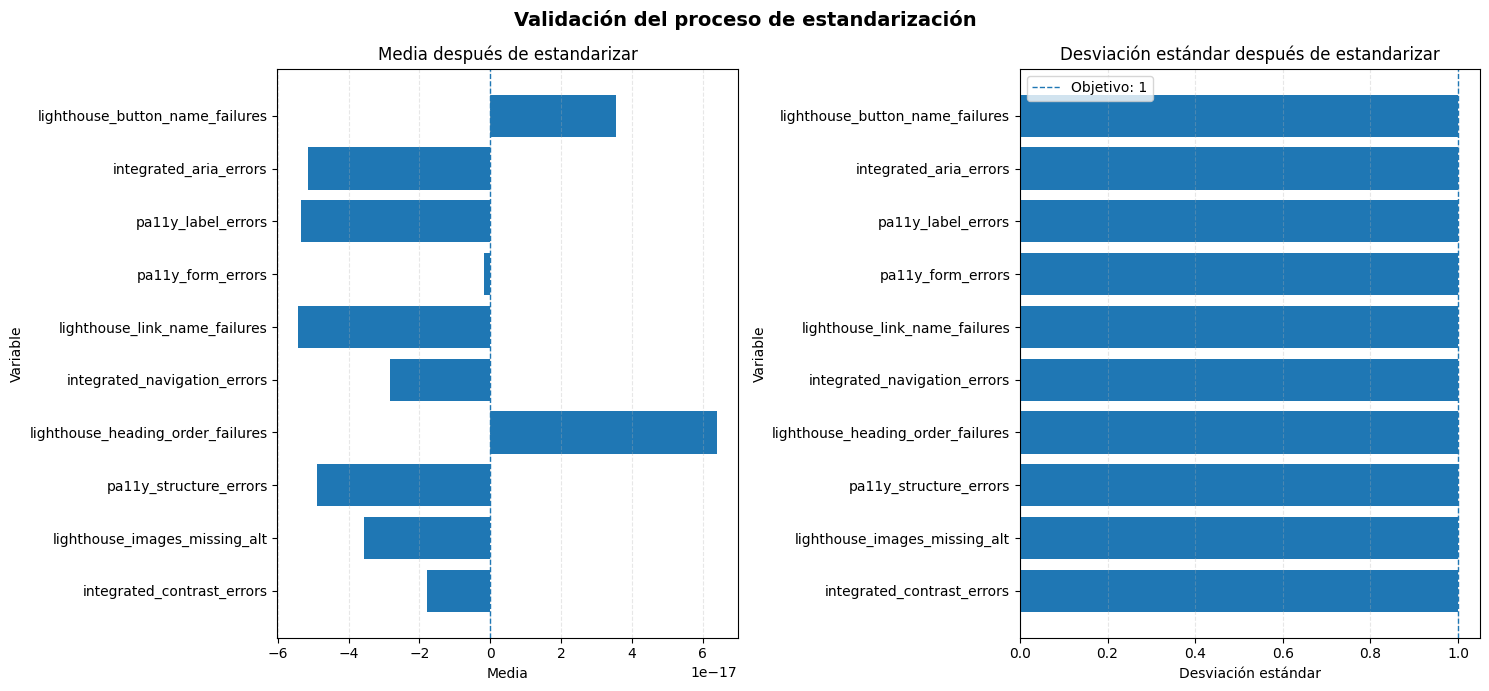


PROCESO COMPLETADO
Registros conservados: 250
Variables estandarizadas: 10
Medias validadas: True
Desviaciones validadas: True

Archivos generados:
1. Dataset: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/4. Estandarizacion/dataset_consolidado_estandarizado.csv
2. Resumen: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/4. Estandarizacion/resumen_estandarizacion.csv
3. Gráfica: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/4. Estandarizacion/resultado_estandarizacion.png

Vista previa del dataset estandarizado:


,url,site_key,integrated_contrast_errors,lighthouse_images_missing_alt,pa11y_structure_errors,lighthouse_heading_order_failures,integrated_navigation_errors,lighthouse_link_name_failures,pa11y_form_errors,pa11y_label_errors,integrated_aria_errors,lighthouse_button_name_failures
0,https://www.acofi.edu.co,acofi.edu.co,-0.717644,2.692535,-0.691044,1.119041,0.854376,0.730577,-0.657470,-0.243841,-0.656131,-0.837066
1,https://www.adres.gov.co,adres.gov.co,-0.166462,-0.516695,-0.691044,1.119041,-0.708933,-1.368782,-0.657470,-0.243841,-0.715845,-0.837066
2,https://www.aerocivil.gov.co,aerocivil.gov.co,-0.707651,0.553048,-0.691044,-0.893622,-0.642592,-1.368782,0.328653,2.067360,1.063616,1.194648
3,https://www.aldeamo.com,aldeamo.com,-0.717644,-0.516695,-0.691044,1.119041,-0.775529,-1.368782,-0.657470,-0.243841,-0.715845,-0.837066
4,https://www.alegra.com,alegra.com,-0.416196,-0.516695,-0.691044,-0.893622,-0.775529,-1.368782,-0.657470,2.067360,-0.715845,-0.837066



Resumen de resultados:


,variable,media_antes,desviacion_antes,media_despues,desviacion_despues,valor_minimo_despues,valor_maximo_despues,variable_constante
0,integrated_contrast_errors,0.0620,0.0864,-0.0,1.0,-0.7176,3.1799,False
1,lighthouse_images_missing_alt,0.3348,0.6480,-0.0,1.0,-0.5167,2.6925,False
2,pa11y_structure_errors,0.7943,1.1494,-0.0,1.0,-0.6910,3.9734,False
3,lighthouse_heading_order_failures,0.4440,0.4969,0.0,1.0,-0.8936,1.1190,False
4,integrated_navigation_errors,0.0447,0.0576,-0.0,1.0,-0.7755,3.4123,False
5,lighthouse_link_name_failures,0.6520,0.4763,-0.0,1.0,-1.3688,0.7306,False
6,pa11y_form_errors,0.4621,0.7029,-0.0,1.0,-0.6575,3.2870,False
7,pa11y_label_errors,0.0731,0.2999,-0.0,1.0,-0.2438,8.7858,False
8,integrated_aria_errors,0.0810,0.1132,-0.0,1.0,-0.7158,3.2372,False
9,lighthouse_button_name_failures,0.4120,0.4922,0.0,1.0,-0.8371,1.1946,False


In [ ]:
# ============================================================
# 6.4. ESTANDARIZACIÓN DE VARIABLES
# Preparación del dataset para clustering
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from IPython.display import display

# ------------------------------------------------------------
# 1. RUTAS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

# Entrada: dataset tratado en el apartado 6.3
CSV_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "3. Tratamiento_Outliers",
    "dataset_consolidado_tratado.csv"
)

# Salidas del apartado 6.4
DIR_SALIDA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion"
)

os.makedirs(DIR_SALIDA, exist_ok=True)

CSV_SALIDA = os.path.join(
    DIR_SALIDA,
    "dataset_consolidado_estandarizado.csv"
)

CSV_RESUMEN = os.path.join(
    DIR_SALIDA,
    "resumen_estandarizacion.csv"
)

PNG_GRAFICA = os.path.join(
    DIR_SALIDA,
    "resultado_estandarizacion.png"
)

# ------------------------------------------------------------
# 2. CARGAR Y VALIDAR EL DATASET
# ------------------------------------------------------------

if not os.path.isfile(CSV_ENTRADA):
    raise FileNotFoundError(
        "No se encontró el dataset tratado del apartado 6.3.\n"
        f"Ruta esperada:\n{CSV_ENTRADA}\n\n"
        "Verifica que hayas ejecutado el apartado 6.3."
    )

# Obtener automáticamente las variables desde la metadata.
if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'. "
        "Ejecuta primero la celda donde defines la metadata."
    )

VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        "Se esperaban 10 variables en 'variables_consolidadas', "
        f"pero se encontraron {len(VARIABLES)}."
    )

IDENTIFICADORES = ["url", "site_key"]

df = pd.read_csv(CSV_ENTRADA)

columnas_faltantes = [
    c for c in IDENTIFICADORES + VARIABLES
    if c not in df.columns
]

if columnas_faltantes:
    raise ValueError(
        "Faltan columnas requeridas en el dataset tratado:\n"
        + ", ".join(columnas_faltantes)
    )

if df.empty:
    raise ValueError("El dataset no contiene registros.")

if df["site_key"].duplicated().any():
    raise ValueError(
        "Hay identificadores site_key duplicados. "
        "Revisa el dataset antes de estandarizar."
    )

# Garantizar formato numérico.
for variable in VARIABLES:
    df[variable] = pd.to_numeric(df[variable], errors="coerce")

# Validar que los datos estén completos y sean finitos.
matriz_original = df[VARIABLES].to_numpy(dtype=float)

if not np.isfinite(matriz_original).all():
    columnas_invalidas = [
        variable for variable in VARIABLES
        if not np.isfinite(df[variable].to_numpy(dtype=float)).all()
    ]
    raise ValueError(
        "Las variables analíticas contienen valores faltantes "
        "o infinitos. Revisa el resultado del apartado 6.3.\n"
        "Variables afectadas: " + ", ".join(columnas_invalidas)
    )

print("=" * 65)
print("6.4. ESTANDARIZACIÓN DE VARIABLES")
print("=" * 65)
print(f"Sitios analizados: {len(df)}")
print(f"Variables analíticas: {len(VARIABLES)}")
print(f"Columnas identificadoras: {IDENTIFICADORES}")

print("\nVariables que se estandarizarán:")
for i, variable in enumerate(VARIABLES, start=1):
    print(f"{i:02d}. {variable}")

# ------------------------------------------------------------
# 3. APLICAR STANDARD SCALER
# ------------------------------------------------------------
# Fórmula:
# z = (x - media) / desviación estándar
#
# StandardScaler utiliza la desviación estándar poblacional.
# Las variables constantes quedan en cero; no se eliminan.

X_original = df[VARIABLES].copy()

scaler = StandardScaler()
X_transformado = scaler.fit_transform(X_original)

df_estandarizado = pd.DataFrame(
    X_transformado,
    columns=VARIABLES,
    index=df.index
)

# Conservar identificadores sin transformarlos.
df_estandarizado.insert(0, "site_key", df["site_key"])
df_estandarizado.insert(0, "url", df["url"])

# ------------------------------------------------------------
# 4. RESUMEN ANTES Y DESPUÉS
# ------------------------------------------------------------

medias_antes = X_original.mean()
desviaciones_antes = X_original.std(ddof=0)
medias_despues = df_estandarizado[VARIABLES].mean()
desviaciones_despues = df_estandarizado[VARIABLES].std(ddof=0)

resumen = pd.DataFrame({
    "variable": VARIABLES,
    "media_antes": medias_antes.reindex(VARIABLES).to_numpy(),
    "desviacion_antes": desviaciones_antes.reindex(VARIABLES).to_numpy(),
    "media_despues": medias_despues.reindex(VARIABLES).to_numpy(),
    "desviacion_despues": desviaciones_despues.reindex(VARIABLES).to_numpy(),
    "valor_minimo_despues": (
        df_estandarizado[VARIABLES].min().reindex(VARIABLES).to_numpy()
    ),
    "valor_maximo_despues": (
        df_estandarizado[VARIABLES].max().reindex(VARIABLES).to_numpy()
    ),
    "variable_constante": [
        bool(desviaciones_antes[v] == 0)
        for v in VARIABLES
    ]
})

# ------------------------------------------------------------
# 5. VALIDAR LA TRANSFORMACIÓN
# ------------------------------------------------------------

medias_finales = df_estandarizado[VARIABLES].mean()
desviaciones_finales = df_estandarizado[VARIABLES].std(ddof=0)

# Las variables constantes tienen desviación estándar cero,
# por lo que se excluyen de la validación de desviación = 1.
variables_no_constantes = [
    v for v in VARIABLES
    if X_original[v].std(ddof=0) > 0
]

max_error_media = float(np.abs(medias_finales).max())

if variables_no_constantes:
    max_error_desviacion = float(
        np.abs(
            desviaciones_finales[variables_no_constantes] - 1
        ).max()
    )
else:
    max_error_desviacion = 0.0

validacion_media = max_error_media < 1e-10
validacion_desviacion = max_error_desviacion < 1e-10

print("\n--- Validación de la estandarización ---")
print(f"Máximo error absoluto de la media: {max_error_media:.12f}")
print(
    "Máximo error respecto a desviación estándar 1: "
    f"{max_error_desviacion:.12f}"
)
print(f"Medias aproximadamente iguales a 0: {validacion_media}")
print(
    "Desviaciones aproximadamente iguales a 1: "
    f"{validacion_desviacion}"
)

if not validacion_media or not validacion_desviacion:
    raise ValueError(
        "La validación estadística de la estandarización falló."
    )

# ------------------------------------------------------------
# 6. GRÁFICA ÚNICA DE RESULTADOS
# ------------------------------------------------------------
# La gráfica resume dos propiedades:
# 1. Las medias estandarizadas deben estar cerca de cero.
# 2. Las desviaciones estándar deben estar cerca de uno,
#    salvo en variables constantes.

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 7)
)

# Gráfico de medias.
medias_plot = medias_finales.reindex(VARIABLES)
axes[0].barh(VARIABLES, medias_plot.values)
axes[0].axvline(0, linestyle="--", linewidth=1)
axes[0].set_title("Media después de estandarizar")
axes[0].set_xlabel("Media")
axes[0].set_ylabel("Variable")
axes[0].grid(axis="x", linestyle="--", alpha=0.3)

# Gráfico de desviaciones estándar.
desviaciones_plot = desviaciones_finales.reindex(VARIABLES)
axes[1].barh(VARIABLES, desviaciones_plot.values)
axes[1].axvline(
    1,
    linestyle="--",
    linewidth=1,
    label="Objetivo: 1"
)
axes[1].set_title("Desviación estándar después de estandarizar")
axes[1].set_xlabel("Desviación estándar")
axes[1].set_ylabel("Variable")
axes[1].legend()
axes[1].grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle(
    "Validación del proceso de estandarización",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(PNG_GRAFICA, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. GUARDAR RESULTADOS
# ------------------------------------------------------------

df_estandarizado.to_csv(
    CSV_SALIDA,
    index=False,
    encoding="utf-8-sig"
)

resumen.to_csv(
    CSV_RESUMEN,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. RESULTADO FINAL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PROCESO COMPLETADO")
print("=" * 65)

print(f"Registros conservados: {len(df_estandarizado)}")
print(f"Variables estandarizadas: {len(VARIABLES)}")
print(f"Medias validadas: {validacion_media}")
print(f"Desviaciones validadas: {validacion_desviacion}")

print("\nArchivos generados:")
print(f"1. Dataset: {CSV_SALIDA}")
print(f"2. Resumen: {CSV_RESUMEN}")
print(f"3. Gráfica: {PNG_GRAFICA}")

print("\nVista previa del dataset estandarizado:")
display(df_estandarizado.head())

print("\nResumen de resultados:")
display(resumen.round(4))

### **6.5 PCA**



#### **6.5.1 Análisis exploratorio del PCA y selección del número de componentes**



6.5.1. ANÁLISIS EXPLORATORIO DEL PCA
Sitios analizados: 250
Variables analíticas: 10

Variables incluidas:
01. integrated_contrast_errors
02. lighthouse_images_missing_alt
03. pa11y_structure_errors
04. lighthouse_heading_order_failures
05. integrated_navigation_errors
06. lighthouse_link_name_failures
07. pa11y_form_errors
08. pa11y_label_errors
09. integrated_aria_errors
10. lighthouse_button_name_failures

Dataset de entrada:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/4. Estandarizacion/dataset_consolidado_estandarizado.csv

--- Varianza y eigenvalues por componente ---


,componente,eigenvalue_matriz_correlacion,varianza_explicada_pct,varianza_acumulada_pct,criterio_kaiser_eigenvalue_mayor_1,eigenvalue_simulado_percentil_95,supera_analisis_paralelo
0,PC1,2.1324,21.3240,21.3240,True,1.4075,True
1,PC2,1.5408,15.4075,36.7315,True,1.2925,True
2,PC3,1.1393,11.3929,48.1244,True,1.2078,False
3,PC4,1.0277,10.2775,58.4019,True,1.1272,False
4,PC5,0.9732,9.7322,68.1341,False,1.0695,False
5,PC6,0.8509,8.5085,76.6427,False,1.0005,False
6,PC7,0.6952,6.9517,83.5943,False,0.9436,False
7,PC8,0.6338,6.3378,89.9321,False,0.8892,False
8,PC9,0.5875,5.8746,95.8067,False,0.8344,False
9,PC10,0.4193,4.1933,100.0000,False,0.7659,False



--- Comparación de criterios de selección ---


,criterio,componentes_recomendados,varianza_acumulada_pct,interpretacion
0,Kaiser (eigenvalue > 1),4,58.402,Referencia clásica para variables estandarizad...
1,Análisis paralelo (percentil 95),2,36.731,Retiene componentes cuyos eigenvalues superan ...
2,Varianza acumulada >= 70%,6,76.643,Criterio de compresión; decidir junto con los ...
3,Varianza acumulada >= 75%,6,76.643,Criterio de compresión; decidir junto con los ...
4,Varianza acumulada >= 80%,7,83.594,Criterio de compresión; decidir junto con los ...
5,Varianza acumulada >= 85%,8,89.932,Criterio de compresión; decidir junto con los ...
6,Varianza acumulada >= 90%,9,95.807,Criterio de compresión; decidir junto con los ...



--- Sensibilidad de K-means al número de componentes ---


,numero_componentes,k_clusters,inercia,silhouette,estado
0,1,4,49.3119,0.5691,OK
1,1,7,15.3866,0.5667,OK
2,2,4,263.8971,0.4228,OK
3,2,7,147.9496,0.3977,OK
4,3,4,490.7944,0.3446,OK
5,3,7,322.7382,0.3387,OK
6,4,4,734.6353,0.2766,OK
7,4,7,526.0702,0.2614,OK
8,5,4,961.7823,0.2334,OK
9,5,7,678.5706,0.2559,OK


K=4: mayor silhouette = 0.5691 con 1 componente(s).
K=7: mayor silhouette = 0.5667 con 1 componente(s).


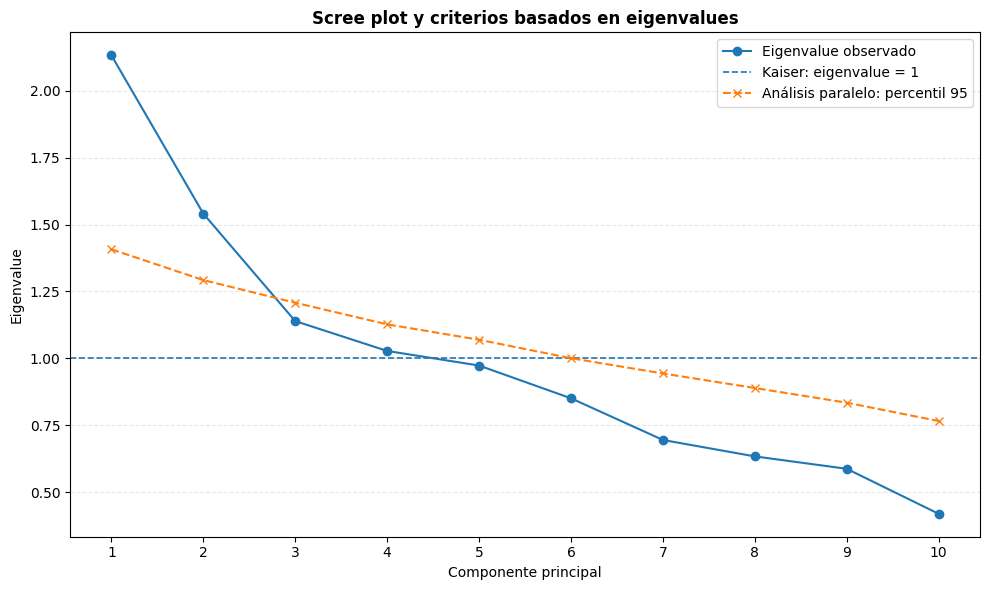

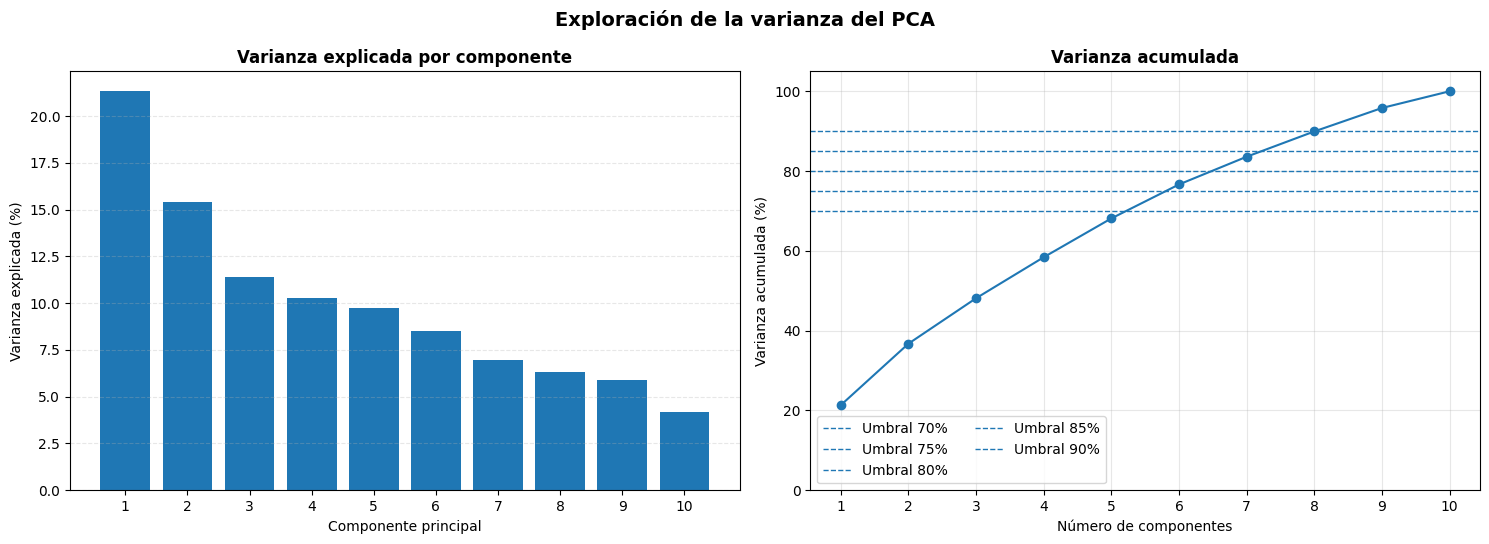

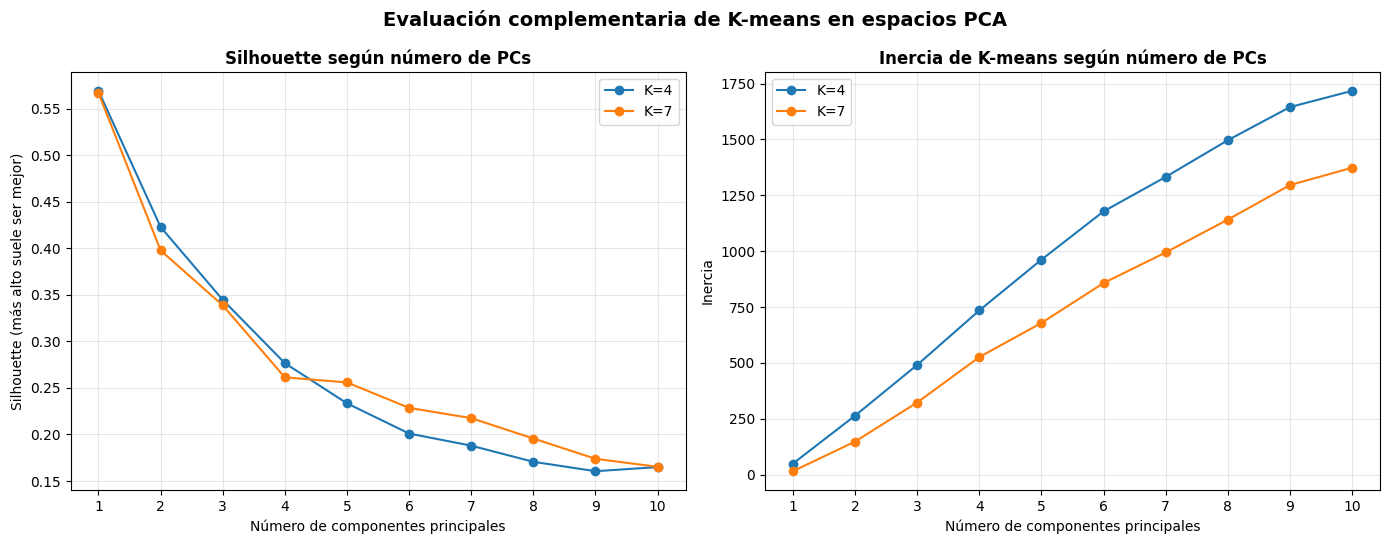

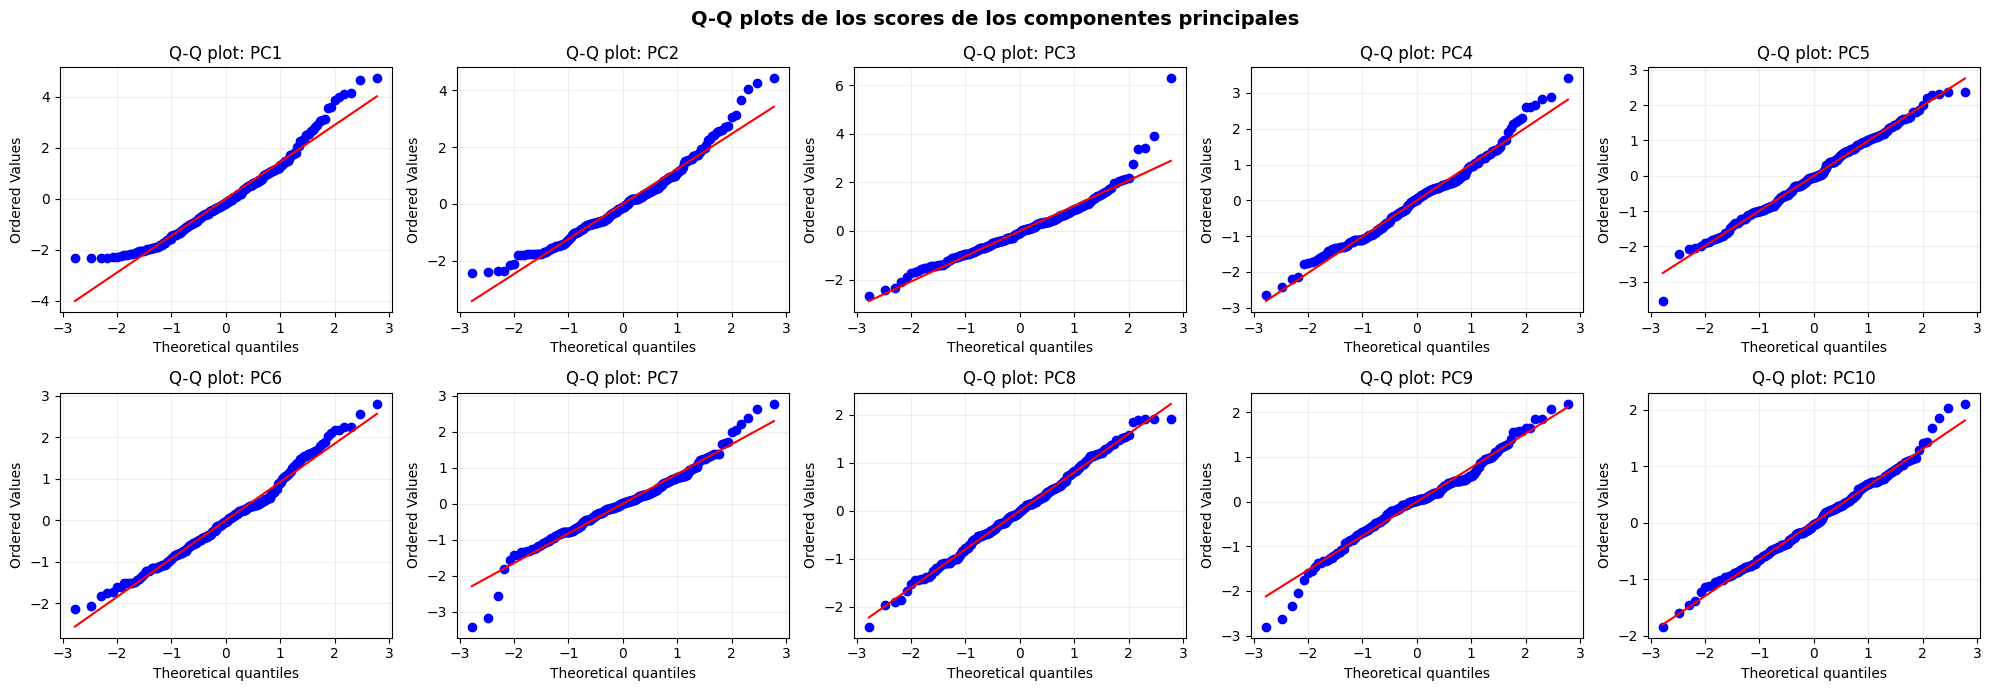


ANÁLISIS EXPLORATORIO DEL PCA COMPLETADO
Componentes calculados: 10
Componentes sugeridos por Kaiser: 4
Componentes sugeridos por análisis paralelo: 2

Criterios por varianza acumulada:
  70%: 6 componentes (76.64% acumulado)
  75%: 6 componentes (76.64% acumulado)
  80%: 7 componentes (83.59% acumulado)
  85%: 8 componentes (89.93% acumulado)
  90%: 9 componentes (95.81% acumulado)

Archivos generados:
- Varianza y eigenvalues:
  /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.1. Analisis_Exploratorio/varianza_explicada_pca.csv
- Comparación de criterios:
  /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.1. Analisis_Exploratorio/seleccion_componentes_pca.csv
- Umbrales de varianza:
  /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.1. Analisis_Exploratorio/resumen_umbrales_pca.csv
- K-means por número de PCs:
  /content/drive/MyDrive/Trabajo de Grado/A

,criterio,componentes_recomendados,varianza_acumulada_pct,interpretacion
0,Kaiser (eigenvalue > 1),4,58.402,Referencia clásica para variables estandarizad...
1,Análisis paralelo (percentil 95),2,36.731,Retiene componentes cuyos eigenvalues superan ...
2,Varianza acumulada >= 70%,6,76.643,Criterio de compresión; decidir junto con los ...
3,Varianza acumulada >= 75%,6,76.643,Criterio de compresión; decidir junto con los ...
4,Varianza acumulada >= 80%,7,83.594,Criterio de compresión; decidir junto con los ...
5,Varianza acumulada >= 85%,8,89.932,Criterio de compresión; decidir junto con los ...
6,Varianza acumulada >= 90%,9,95.807,Criterio de compresión; decidir junto con los ...



Primeras filas del análisis K-means:


,numero_componentes,k_clusters,inercia,silhouette,estado
0,1,4,49.3119,0.5691,OK
1,1,7,15.3866,0.5667,OK
2,2,4,263.8971,0.4228,OK
3,2,7,147.9496,0.3977,OK
4,3,4,490.7944,0.3446,OK
5,3,7,322.7382,0.3387,OK
6,4,4,734.6353,0.2766,OK
7,4,7,526.0702,0.2614,OK
8,5,4,961.7823,0.2334,OK
9,5,7,678.5706,0.2559,OK


In [ ]:
# ============================================================
# 6.5.1. ANÁLISIS EXPLORATORIO DEL PCA Y SELECCIÓN
#        DEL NÚMERO DE COMPONENTES
# ============================================================
# Se exploran varios criterios:
# 1. Criterio de Kaiser (eigenvalue > 1).
# 2. Varianza acumulada (70 %, 75 %, 80 %, 85 % y 90 %).
# 3. Scree plot.
# 4. Análisis paralelo por permutación.
# 5. Diagnóstico Q-Q de los scores de los componentes.
# 6. Sensibilidad complementaria de K-means al número de PCs,
#    comparando K=4 y K=7. K-means es una revisión complementaria;
#    no sustituye los criterios propios de selección de PCA.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy import stats
from IPython.display import display

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE RUTAS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

RUTA_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_consolidado_estandarizado.csv"
)

DIR_SALIDA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "5. PCA",
    "6.5.1. Analisis_Exploratorio"
)
os.makedirs(DIR_SALIDA, exist_ok=True)

RUTA_VARIANZA = os.path.join(DIR_SALIDA, "varianza_explicada_pca.csv")
RUTA_SELECCION = os.path.join(DIR_SALIDA, "seleccion_componentes_pca.csv")
RUTA_UMBRALES = os.path.join(DIR_SALIDA, "resumen_umbrales_pca.csv")
RUTA_KMEANS = os.path.join(DIR_SALIDA, "analisis_kmeans_por_componentes.csv")
RUTA_SCREE = os.path.join(DIR_SALIDA, "scree_plot_pca.png")
RUTA_GRAFICA_VARIANZA = os.path.join(DIR_SALIDA, "analisis_varianza_pca.png")
RUTA_GRAFICA_KMEANS = os.path.join(DIR_SALIDA, "analisis_kmeans_componentes.png")
RUTA_QQ = os.path.join(DIR_SALIDA, "qqplot_scores_pca.png")

# Configuración reproducible del análisis paralelo y K-means.
N_SIMULACIONES_PARALELO = 500
SEMILLA = 42
UMBRALES_VARIANZA = [70, 75, 80, 85, 90]
VALORES_K = [4, 7]

# ------------------------------------------------------------
# 2. CARGAR Y VALIDAR EL DATASET
# ------------------------------------------------------------

if not os.path.isfile(RUTA_ENTRADA):
    raise FileNotFoundError(
        "No se encontró el dataset estandarizado.\n"
        f"Ruta esperada:\n{RUTA_ENTRADA}\n\n"
        "Verifica que hayas ejecutado el apartado 6.4."
    )

df = pd.read_csv(RUTA_ENTRADA)

if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'. "
        "Ejecuta primero la celda donde defines la metadata."
    )

# Obtener automáticamente las variables analíticas desde la metadata.
VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        "Se esperaban 10 variables analíticas en la metadata, "
        f"pero se encontraron {len(VARIABLES)}."
    )

faltantes_columnas = [v for v in VARIABLES if v not in df.columns]
if faltantes_columnas:
    raise ValueError(
        "Faltan variables analíticas del diccionario "
        "en el dataset estandarizado:\n"
        + "\n".join(f"- {v}" for v in faltantes_columnas)
    )

if df.empty:
    raise ValueError("El dataset no contiene registros.")

X = df[VARIABLES].apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError(
        "El dataset contiene valores faltantes o infinitos. "
        "Revisa el apartado 6.4 antes de continuar."
    )

if len(X) < 2:
    raise ValueError("Se necesitan al menos dos registros para realizar PCA.")

# Identificar variables constantes, que no aportan variabilidad al PCA.
variables_constantes = [
    v for v in VARIABLES
    if np.isclose(X[v].std(ddof=0), 0.0)
]
if variables_constantes:
    print("⚠️ Variables constantes detectadas:")
    for v in variables_constantes:
        print(f"   - {v}")
    print("   Estas variables no aportan información de variabilidad al PCA.")

print("=" * 75)
print("6.5.1. ANÁLISIS EXPLORATORIO DEL PCA")
print("=" * 75)
print(f"Sitios analizados: {len(X)}")
print(f"Variables analíticas: {len(VARIABLES)}")
print("\nVariables incluidas:")
for i, variable in enumerate(VARIABLES, start=1):
    print(f"{i:02d}. {variable}")
print(f"\nDataset de entrada:\n{RUTA_ENTRADA}")

# ------------------------------------------------------------
# 3. CALCULAR LOS COMPONENTES PRINCIPALES
# ------------------------------------------------------------

n_componentes = min(X.shape[0], X.shape[1])
pca = PCA(n_components=n_componentes, random_state=SEMILLA)
SCORES = pca.fit_transform(X)

varianza_individual = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza_individual)
componentes = [f"PC{i}" for i in range(1, n_componentes + 1)]

# Eigenvalues de la matriz de correlación para aplicar Kaiser con umbral 1.
# Si una variable es constante, su fila/columna de correlación se fija en cero.
matriz_corr = X.corr().to_numpy(dtype=float)
matriz_corr = np.nan_to_num(matriz_corr, nan=0.0, posinf=0.0, neginf=0.0)
for j, variable in enumerate(VARIABLES):
    if variable in variables_constantes:
        matriz_corr[j, :] = 0.0
        matriz_corr[:, j] = 0.0

# Orden descendente para que corresponda a PC1, PC2, etc.
eigenvalues_kaiser = np.linalg.eigvalsh(matriz_corr)[::-1]
eigenvalues_kaiser = np.clip(eigenvalues_kaiser, 0, None)

# En datasets no constantes, los porcentajes basados en eigenvalues de la
# correlación y PCA deben coincidir salvo diferencias numéricas pequeñas.
# Se utiliza la varianza explicada de sklearn para el porcentaje oficial.

# ------------------------------------------------------------
# 4. ANÁLISIS PARALELO POR PERMUTACIÓN
# ------------------------------------------------------------
# Cada columna se permuta de manera independiente. Esto conserva su
# distribución marginal, pero elimina las asociaciones entre variables.
# Se compara el eigenvalue observado con el percentil 95 de los simulados.

rng = np.random.default_rng(SEMILLA)
matriz_X = X.to_numpy(dtype=float)
n_variables = matriz_X.shape[1]
eigenvalues_simulados = np.zeros((N_SIMULACIONES_PARALELO, n_variables))

for simulacion in range(N_SIMULACIONES_PARALELO):
    datos_aleatorios = np.empty_like(matriz_X)
    for j in range(n_variables):
        datos_aleatorios[:, j] = rng.permutation(matriz_X[:, j])

    corr_simulada = np.corrcoef(datos_aleatorios, rowvar=False)
    corr_simulada = np.nan_to_num(
        corr_simulada, nan=0.0, posinf=0.0, neginf=0.0
    )
    for j, variable in enumerate(VARIABLES):
        if variable in variables_constantes:
            corr_simulada[j, :] = 0.0
            corr_simulada[:, j] = 0.0

    eigenvalues_simulados[simulacion, :] = np.linalg.eigvalsh(
        corr_simulada
    )[::-1]

umbral_paralelo_95 = np.percentile(eigenvalues_simulados, 95, axis=0)

# Conservar la secuencia inicial de componentes cuyo eigenvalue observado
# supera el percentil 95 de su componente simulado correspondiente.
componentes_paralelo = 0
for observado, umbral in zip(eigenvalues_kaiser, umbral_paralelo_95):
    if observado > umbral:
        componentes_paralelo += 1
    else:
        break

# ------------------------------------------------------------
# 5. TABLA GENERAL DE VARIANZA Y EIGENVALUES
# ------------------------------------------------------------

tabla_varianza = pd.DataFrame({
    "componente": componentes,
    "eigenvalue_matriz_correlacion": eigenvalues_kaiser,
    "varianza_explicada_pct": varianza_individual,
    "varianza_acumulada_pct": varianza_acumulada,
    "criterio_kaiser_eigenvalue_mayor_1": eigenvalues_kaiser > 1,
    "eigenvalue_simulado_percentil_95": umbral_paralelo_95,
    "supera_analisis_paralelo": eigenvalues_kaiser > umbral_paralelo_95
})

tabla_varianza.to_csv(RUTA_VARIANZA, index=False, encoding="utf-8-sig")

print("\n--- Varianza y eigenvalues por componente ---")
display(tabla_varianza.round(4))

# ------------------------------------------------------------
# 6. CRITERIOS PARA SELECCIONAR COMPONENTES
# ------------------------------------------------------------

n_kaiser = int(np.sum(eigenvalues_kaiser > 1))
criterios = [{
    "criterio": "Kaiser (eigenvalue > 1)",
    "componentes_recomendados": n_kaiser,
    "varianza_acumulada_pct": (
        float(varianza_acumulada[n_kaiser - 1]) if n_kaiser > 0 else 0.0
    ),
    "interpretacion": "Referencia clásica para variables estandarizadas; no usar de forma aislada."
}, {
    "criterio": "Análisis paralelo (percentil 95)",
    "componentes_recomendados": componentes_paralelo,
    "varianza_acumulada_pct": (
        float(varianza_acumulada[componentes_paralelo - 1])
        if componentes_paralelo > 0 else 0.0
    ),
    "interpretacion": "Retiene componentes cuyos eigenvalues superan el umbral aleatorio de referencia."
}]

resumen_umbrales = []
for umbral in UMBRALES_VARIANZA:
    indices = np.where(varianza_acumulada >= umbral)[0]
    if len(indices):
        cantidad = int(indices[0] + 1)
        porcentaje = float(varianza_acumulada[cantidad - 1])
    else:
        cantidad = np.nan
        porcentaje = np.nan

    resumen_umbrales.append({
        "umbral_varianza_pct": umbral,
        "componentes_necesarios": cantidad,
        "varianza_acumulada_pct": porcentaje
    })
    criterios.append({
        "criterio": f"Varianza acumulada >= {umbral}%",
        "componentes_recomendados": cantidad,
        "varianza_acumulada_pct": porcentaje,
        "interpretacion": "Criterio de compresión; decidir junto con los demás resultados."
    })

resumen_umbrales_df = pd.DataFrame(resumen_umbrales)
seleccion_df = pd.DataFrame(criterios)

seleccion_df.to_csv(RUTA_SELECCION, index=False, encoding="utf-8-sig")
resumen_umbrales_df.to_csv(RUTA_UMBRALES, index=False, encoding="utf-8-sig")

print("\n--- Comparación de criterios de selección ---")
display(seleccion_df.round(3))

# ------------------------------------------------------------
# 7. EVALUACIÓN COMPLEMENTARIA DE K-MEANS SEGÚN NÚMERO DE PCs
# ------------------------------------------------------------
# Se prueba K=4 y K=7 (los valores comparados en el análisis de clustering)
# con 1, 2, ..., n componentes. Se registran inertia e índice silhouette.
# La inercia no es directamente comparable entre espacios con distinta
# dimensionalidad; el silhouette sirve como indicador complementario.

resultados_kmeans = []

for n_pc in range(1, n_componentes + 1):
    X_pc = SCORES[:, :n_pc]

    for k in VALORES_K:
        if len(X_pc) <= k:
            resultados_kmeans.append({
                "numero_componentes": n_pc,
                "k_clusters": k,
                "inercia": np.nan,
                "silhouette": np.nan,
                "estado": "No evaluado: registros insuficientes"
            })
            continue

        modelo_kmeans = KMeans(
            n_clusters=k,
            random_state=SEMILLA,
            n_init=20
        )
        etiquetas = modelo_kmeans.fit_predict(X_pc)

        if len(np.unique(etiquetas)) < 2 or len(np.unique(etiquetas)) >= len(X_pc):
            silhouette = np.nan
            estado = "Silhouette no calculable para esta partición"
        else:
            silhouette = float(silhouette_score(X_pc, etiquetas))
            estado = "OK"

        resultados_kmeans.append({
            "numero_componentes": n_pc,
            "k_clusters": k,
            "inercia": float(modelo_kmeans.inertia_),
            "silhouette": silhouette,
            "estado": estado
        })

kmeans_df = pd.DataFrame(resultados_kmeans)
kmeans_df.to_csv(RUTA_KMEANS, index=False, encoding="utf-8-sig")

print("\n--- Sensibilidad de K-means al número de componentes ---")
display(kmeans_df.round(4))

for k in VALORES_K:
    subset = kmeans_df[
        (kmeans_df["k_clusters"] == k)
        & kmeans_df["silhouette"].notna()
    ]
    if not subset.empty:
        mejor = subset.loc[subset["silhouette"].idxmax()]
        print(
            f"K={k}: mayor silhouette = {mejor['silhouette']:.4f} "
            f"con {int(mejor['numero_componentes'])} componente(s)."
        )

# ------------------------------------------------------------
# 8. GRÁFICOS DE EIGENVALUES, SCREE PLOT Y VARIANZA ACUMULADA
# ------------------------------------------------------------

posiciones = np.arange(1, n_componentes + 1)

# 8.1 Scree plot: eigenvalues observados y umbral Kaiser/paralelo.
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    posiciones,
    eigenvalues_kaiser,
    marker="o",
    label="Eigenvalue observado"
)
ax.axhline(1, linestyle="--", linewidth=1.2, label="Kaiser: eigenvalue = 1")
ax.plot(
    posiciones,
    umbral_paralelo_95,
    marker="x",
    linestyle="--",
    label="Análisis paralelo: percentil 95"
)
ax.set_title("Scree plot y criterios basados en eigenvalues", fontweight="bold")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Eigenvalue")
ax.set_xticks(posiciones)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(RUTA_SCREE, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# 8.2 Varianza individual y acumulada.
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].bar(posiciones, varianza_individual)
axes[0].set_title("Varianza explicada por componente", fontweight="bold")
axes[0].set_xlabel("Componente principal")
axes[0].set_ylabel("Varianza explicada (%)")
axes[0].set_xticks(posiciones)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

axes[1].plot(posiciones, varianza_acumulada, marker="o")
for umbral in UMBRALES_VARIANZA:
    axes[1].axhline(
        umbral,
        linestyle="--",
        linewidth=1,
        label=f"Umbral {umbral}%"
    )
axes[1].set_title("Varianza acumulada", fontweight="bold")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_xticks(posiciones)
axes[1].set_ylim(0, 105)
axes[1].grid(alpha=0.3)
axes[1].legend(ncol=2)
fig.suptitle("Exploración de la varianza del PCA", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUTA_GRAFICA_VARIANZA, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. GRÁFICAS DE K-MEANS: SILHOUETTE E INERCIA
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for k in VALORES_K:
    subset = kmeans_df[kmeans_df["k_clusters"] == k].sort_values("numero_componentes")
    axes[0].plot(
        subset["numero_componentes"],
        subset["silhouette"],
        marker="o",
        label=f"K={k}"
    )
    axes[1].plot(
        subset["numero_componentes"],
        subset["inercia"],
        marker="o",
        label=f"K={k}"
    )

axes[0].set_title("Silhouette según número de PCs", fontweight="bold")
axes[0].set_xlabel("Número de componentes principales")
axes[0].set_ylabel("Silhouette (más alto suele ser mejor)")
axes[0].set_xticks(posiciones)
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title("Inercia de K-means según número de PCs", fontweight="bold")
axes[1].set_xlabel("Número de componentes principales")
axes[1].set_ylabel("Inercia")
axes[1].set_xticks(posiciones)
axes[1].grid(alpha=0.3)
axes[1].legend()
fig.suptitle("Evaluación complementaria de K-means en espacios PCA", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(RUTA_GRAFICA_KMEANS, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Q-Q PLOTS DE LOS SCORES DE LOS COMPONENTES PRINCIPALES
# ------------------------------------------------------------
# Este gráfico compara la distribución de los scores con una distribución
# normal teórica. Es un diagnóstico descriptivo: no es un criterio para
# seleccionar el número de componentes ni un supuesto obligatorio de PCA
# o K-means.

n_columnas = min(5, n_componentes)
n_filas = int(np.ceil(n_componentes / n_columnas))
fig, axes = plt.subplots(
    n_filas,
    n_columnas,
    figsize=(4 * n_columnas, 3.5 * n_filas),
    squeeze=False
)

for i in range(n_componentes):
    ax = axes.flat[i]
    scores_i = SCORES[:, i]
    if np.isclose(np.std(scores_i), 0.0):
        ax.text(0.5, 0.5, "Componente sin variación", ha="center", va="center")
        ax.set_title(componentes[i])
        ax.set_axis_off()
    else:
        stats.probplot(scores_i, dist="norm", plot=ax)
        ax.set_title(f"Q-Q plot: {componentes[i]}")
        ax.grid(alpha=0.2)

for i in range(n_componentes, n_filas * n_columnas):
    axes.flat[i].set_visible(False)

fig.suptitle(
    "Q-Q plots de los scores de los componentes principales",
    fontsize=14,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(RUTA_QQ, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. RESUMEN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("ANÁLISIS EXPLORATORIO DEL PCA COMPLETADO")
print("=" * 75)
print(f"Componentes calculados: {n_componentes}")
print(f"Componentes sugeridos por Kaiser: {n_kaiser}")
print(f"Componentes sugeridos por análisis paralelo: {componentes_paralelo}")
print("\nCriterios por varianza acumulada:")
for _, fila in resumen_umbrales_df.iterrows():
    if pd.notna(fila["componentes_necesarios"]):
        print(
            f"  {int(fila['umbral_varianza_pct'])}%: "
            f"{int(fila['componentes_necesarios'])} componentes "
            f"({fila['varianza_acumulada_pct']:.2f}% acumulado)"
        )
    else:
        print(
            f"  {int(fila['umbral_varianza_pct'])}%: "
            "umbral no alcanzado"
        )

print("\nArchivos generados:")
for etiqueta, ruta in [
    ("Varianza y eigenvalues", RUTA_VARIANZA),
    ("Comparación de criterios", RUTA_SELECCION),
    ("Umbrales de varianza", RUTA_UMBRALES),
    ("K-means por número de PCs", RUTA_KMEANS),
    ("Scree plot", RUTA_SCREE),
    ("Gráficas de varianza", RUTA_GRAFICA_VARIANZA),
    ("Gráficas K-means", RUTA_GRAFICA_KMEANS),
    ("Q-Q plots PCA", RUTA_QQ),
]:
    print(f"- {etiqueta}:\n  {ruta}")

print(
    "\nNota metodológica: no se fuerza una selección fija de componentes. "
    "Se recomienda contrastar Kaiser, análisis paralelo, varianza acumulada "
    "y scree plot. K-means aporta una comprobación complementaria sobre la "
    "separación de grupos al variar el número de PCs; el silhouette no debe "
    "ser el único criterio de decisión. Los Q-Q plots describen normalidad "
    "aproximada de los scores, pero no determinan cuántos PCs conservar."
)

print("\nResumen de criterios:")
display(seleccion_df.round(3))
print("\nPrimeras filas del análisis K-means:")
display(kmeans_df.head(10).round(4))

#### **6.5.2. Interpretación de los componentes principales**

Los cuatro componentes principales explican conjuntamente el **58,34 % de la varianza total** de las diez variables originales de accesibilidad web. Esta reducción permite representar los datos en un espacio de cuatro dimensiones para el análisis posterior de clustering.

| Componente | Varianza explicada | Varianza acumulada | ¿Qué representa? |
|---|---:|---:|---|
| **PC1** | 21,38 % | 21,38 % | Primera dimensión de variabilidad de los indicadores de accesibilidad web. |
| **PC2** | 15,29 % | 36,67 % | Segunda dimensión de variabilidad, independiente linealmente de PC1. |
| **PC3** | 11,26 % | 47,93 % | Tercera dimensión, que recoge variaciones adicionales de los indicadores. |
| **PC4** | 10,41 % | 58,34 % | Cuarta dimensión, que aporta información complementaria a los componentes anteriores. |
| **Total** | **58,34 %** | **58,34 %** | **Varianza total representada por los cuatro componentes.** |

**Nota metodológica:** Las descripciones de los componentes son provisionales. Su interpretación específica debe basarse en las cargas de las diez variables nuevas sobre cada componente. Posteriormente, se analizará su relación conceptual con los cuatro principios de accesibilidad de WCAG: **Perceptible, Operable, Comprensible y Robusto**. Los componentes son dimensiones estadísticas y no equivalen automáticamente a dichos principios.


6.5.2. INTERPRETACIÓN DE LOS COMPONENTES PRINCIPALES
Sitios analizados: 250
Variables originales: 10
Componentes calculados: 4
Dataset de entrada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/4. Estandarizacion/dataset_consolidado_estandarizado.csv


### PC1
- **Varianza explicada:** 21.32 %
- **Variables con mayor carga absoluta:** integrated_navigation_errors (+0.792); lighthouse_link_name_failures (+0.644); pa11y_form_errors (+0.548)
- **Principio con mayor representación relativa:** Operable (41.4 % de las cargas absolutas agregadas).

Esta afinidad es descriptiva; la interpretación se debe contrastar con las reglas de accesibilidad y las cargas de las demás variables.

### PC2
- **Varianza explicada:** 15.41 %
- **Variables con mayor carga absoluta:** pa11y_form_errors (+0.511); integrated_aria_errors (+0.500); pa11y_label_errors (+0.484)
- **Principio con mayor representación relativa:** Comprensible (33.5 % de las cargas absolutas agregadas).

Esta afinidad es descriptiva; la interpretación se debe contrastar con las reglas de accesibilidad y las cargas de las demás variables.

### PC3
- **Varianza explicada:** 11.39 %
- **Variables con mayor carga absoluta:** pa11y_label_errors (+0.620); lighthouse_button_name_failures (+0.484); integrated_aria_errors (+0.436)
- **Principio con mayor representación relativa:** Comprensible (36.0 % de las cargas absolutas agregadas).

Esta afinidad es descriptiva; la interpretación se debe contrastar con las reglas de accesibilidad y las cargas de las demás variables.

### PC4
- **Varianza explicada:** 10.28 %
- **Variables con mayor carga absoluta:** integrated_contrast_errors (+0.620); lighthouse_heading_order_failures (-0.588); pa11y_structure_errors (-0.403)
- **Principio con mayor representación relativa:** Perceptible (34.8 % de las cargas absolutas agregadas).

Esta afinidad es descriptiva; la interpretación se debe contrastar con las reglas de accesibilidad y las cargas de las demás variables.

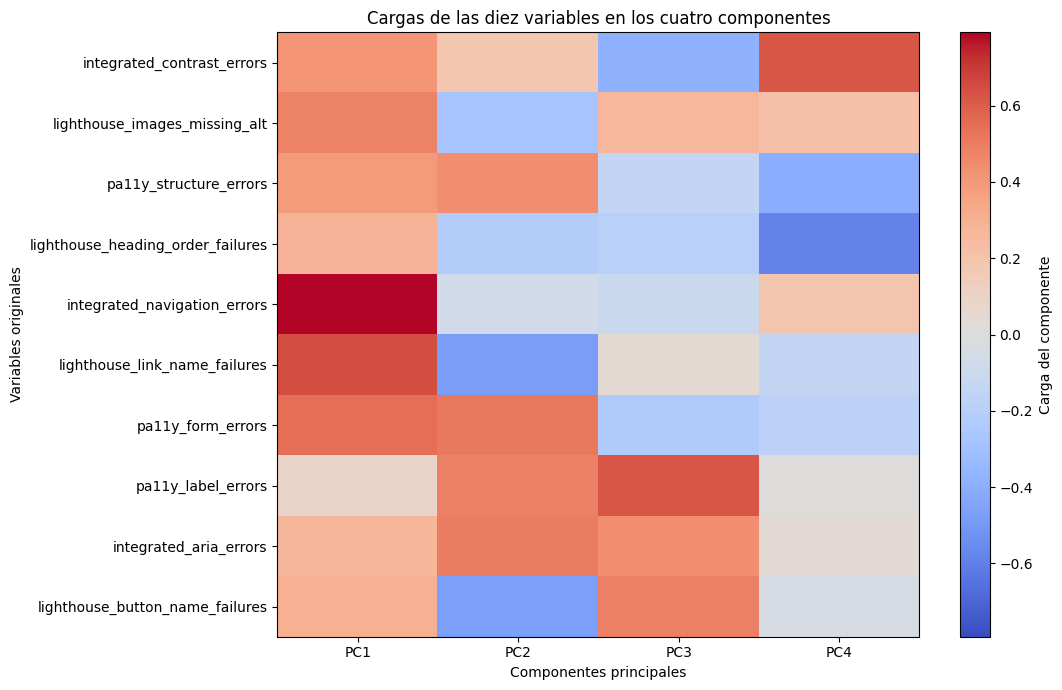

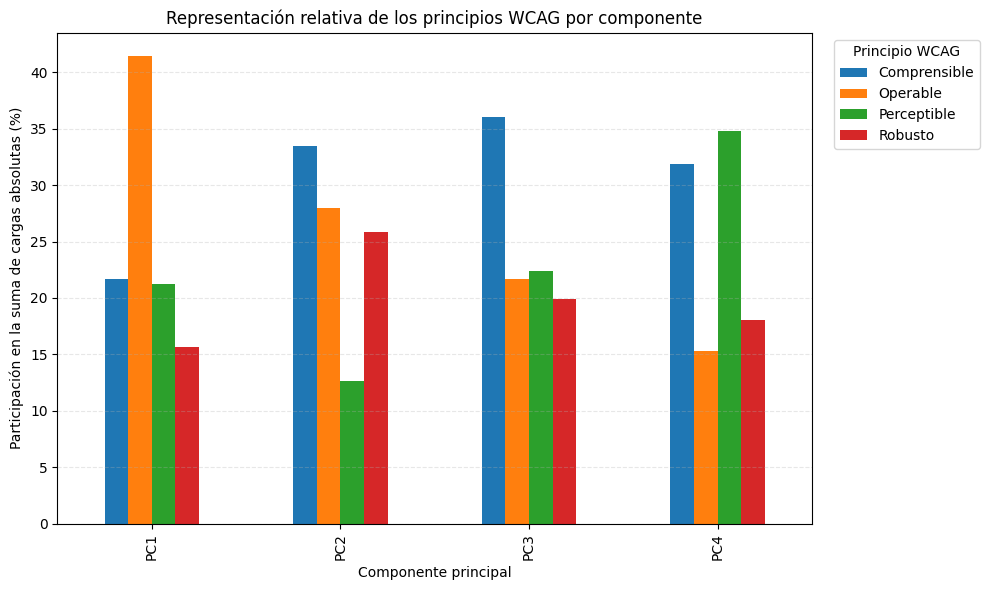


INTERPRETACIÓN DEL PCA FINALIZADA
Observaciones: 250
Variables originales: 10
Componentes retenidos: 4
Varianza acumulada de los cuatro componentes: 58.40 %


### Resumen de los cuatro componentes

,Componente,Varianza_explicada_pct,Varianza_acumulada_pct,Principio_con_mayor_representacion,Participacion_del_principio_pct
0,PC1,21.324,21.324,Operable,41.421
1,PC2,15.408,36.731,Comprensible,33.489
2,PC3,11.393,48.124,Comprensible,36.031
3,PC4,10.277,58.402,Perceptible,34.827


### Contribución relativa de los principios WCAG

Principio_WCAG,Comprensible,Operable,Perceptible,Robusto
Componente,,,,
PC1,21.67,41.42,21.26,15.65
PC2,33.49,27.99,12.65,25.87
PC3,36.03,21.70,22.35,19.92
PC4,31.85,15.32,34.83,18.01


### Nota metodológica
WCAG organiza sus criterios en cuatro principios: Perceptible, Operable, Comprensible y Robusto. En este análisis, la correspondencia entre cada variable y un principio es una clasificación conceptual inicial. El PCA genera componentes matemáticos a partir de las relaciones entre variables; por ello, no debe asumirse que cada componente equivale exactamente a un principio WCAG. Para el análisis posterior de clustering se exportan las puntuaciones de los cuatro componentes.


Archivos generados:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/cargas_componentes_pca.csv
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/resumen_pca.csv
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/contribucion_principios_wcag_pca.csv
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/variables_principales_por_componente.csv
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/puntuaciones_4_componentes_pca.csv
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/6.5.2. Interpretacion_Componentes/mapa_calor_cargas_pca.png
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/

In [ ]:
# ============================================================
# 6.5.2. INTERPRETACIÓN DE LOS COMPONENTES PRINCIPALES (PCA)
# Cuatro componentes y análisis de relación con los principios WCAG
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from IPython.display import display, Markdown

# ------------------------------------------------------------
# 1. CONFIGURACIÓN
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados"

INPUT_FILE = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_consolidado_estandarizado.csv"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "5. PCA",
    "6.5.2. Interpretacion_Componentes"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

N_COMPONENTES = 4
IDENTIFICADORES = ["url", "site_key"]

# Asignación conceptual inicial de cada variable a un principio WCAG.
# Verifica esta clasificación frente a las reglas exactas de las herramientas.
# No significa que los componentes PCA representen automáticamente cada principio.
PRINCIPIOS_WCAG = {
    "Perceptible": [
        "integrated_contrast_errors",
        "lighthouse_images_missing_alt"
    ],
    "Operable": [
        "integrated_navigation_errors",
        "lighthouse_link_name_failures",
        "lighthouse_button_name_failures"
    ],
    "Comprensible": [
        "lighthouse_heading_order_failures",
        "pa11y_form_errors",
        "pa11y_label_errors"
    ],
    "Robusto": [
        "pa11y_structure_errors",
        "integrated_aria_errors"
    ]
}

# ------------------------------------------------------------
# 2. OBTENER VARIABLES DESDE LA METADATA Y VALIDAR
# ------------------------------------------------------------

if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'. Ejecuta primero la celda "
        "donde defines la metadata de las diez variables."
    )

VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        f"Se esperaban 10 variables en 'variables_consolidadas', "
        f"pero se encontraron {len(VARIABLES)}."
    )

# Validar que cada variable esté asignada una sola vez a un principio.
variables_asignadas = [
    variable
    for lista in PRINCIPIOS_WCAG.values()
    for variable in lista
]

if len(variables_asignadas) != len(set(variables_asignadas)):
    raise ValueError(
        "Una variable está asignada a más de un principio WCAG. "
        "Revisa PRINCIPIOS_WCAG."
    )

variables_sin_principio = sorted(set(VARIABLES) - set(variables_asignadas))
variables_no_definidas = sorted(set(variables_asignadas) - set(VARIABLES))

if variables_sin_principio or variables_no_definidas:
    detalle = []
    if variables_sin_principio:
        detalle.append(
            "Variables sin principio: " + ", ".join(variables_sin_principio)
        )
    if variables_no_definidas:
        detalle.append(
            "Variables del mapa que no están en metadata: "
            + ", ".join(variables_no_definidas)
        )
    raise ValueError("; ".join(detalle))

# ------------------------------------------------------------
# 3. CARGA Y VALIDACIÓN DEL DATASET ESTANDARIZADO
# ------------------------------------------------------------

if not os.path.isfile(INPUT_FILE):
    raise FileNotFoundError(
        "No se encontró el dataset estandarizado del apartado 6.4.\n"
        f"Ruta esperada:\n{INPUT_FILE}\n\n"
        "Ejecuta primero los apartados 6.1, 6.2.2, 6.3 y 6.4."
    )

df = pd.read_csv(INPUT_FILE)

columnas_faltantes = [
    columna for columna in IDENTIFICADORES + VARIABLES
    if columna not in df.columns
]
if columnas_faltantes:
    raise ValueError(
        "Faltan columnas requeridas en el dataset: "
        + ", ".join(columnas_faltantes)
    )

if df.empty:
    raise ValueError("El dataset no contiene registros.")

if df["site_key"].duplicated().any():
    raise ValueError("Hay valores duplicados en site_key.")

X = df[VARIABLES].apply(pd.to_numeric, errors="coerce")

if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError(
        "Las variables contienen valores faltantes o infinitos. "
        "Revisa el apartado 6.3 antes de continuar."
    )

if X.shape[0] < N_COMPONENTES or X.shape[1] < N_COMPONENTES:
    raise ValueError(
        f"Se requieren al menos {N_COMPONENTES} observaciones y "
        f"{N_COMPONENTES} variables para calcular el PCA."
    )

print("=" * 75)
print("6.5.2. INTERPRETACIÓN DE LOS COMPONENTES PRINCIPALES")
print("=" * 75)
print(f"Sitios analizados: {len(X)}")
print(f"Variables originales: {len(VARIABLES)}")
print(f"Componentes calculados: {N_COMPONENTES}")
print(f"Dataset de entrada: {INPUT_FILE}")

# ------------------------------------------------------------
# 4. CALCULAR PCA CON CUATRO COMPONENTES
# ------------------------------------------------------------

pca = PCA(n_components=N_COMPONENTES)
puntuaciones = pca.fit_transform(X)

varianza = pca.explained_variance_ratio_ * 100
varianza_acumulada = np.cumsum(varianza)
componentes = [f"PC{i}" for i in range(1, N_COMPONENTES + 1)]

resumen = pd.DataFrame({
    "Componente": componentes,
    "Varianza_explicada_pct": varianza,
    "Varianza_acumulada_pct": varianza_acumulada
})

# Cargas: correlación aproximada entre las variables estandarizadas
# y los componentes, usando los valores propios de PCA.
cargas = pca.components_.T * np.sqrt(pca.explained_variance_)

cargas_df = pd.DataFrame(
    cargas,
    index=VARIABLES,
    columns=componentes
)
cargas_df.index.name = "variable"

# Guardar puntuaciones de los componentes para el análisis posterior.
puntuaciones_df = pd.DataFrame(
    puntuaciones,
    columns=componentes,
    index=df.index
)
for identificador in reversed(IDENTIFICADORES):
    puntuaciones_df.insert(0, identificador, df[identificador])

# ------------------------------------------------------------
# 5. RELACIONAR LAS CARGAS CON LOS PRINCIPIOS WCAG
# ------------------------------------------------------------
# Para cada componente, sumar las cargas absolutas de las variables
# asignadas a cada principio. Es una aproximación descriptiva de afinidad,
# no una prueba de que el componente represente de forma pura ese principio.

filas_principios = []

for componente in componentes:
    total_cargas = float(cargas_df[componente].abs().sum())

    for principio, variables_principio in PRINCIPIOS_WCAG.items():
        suma_cargas = float(
            cargas_df.loc[variables_principio, componente].abs().sum()
        )
        porcentaje = (
            suma_cargas / total_cargas * 100
            if total_cargas > 0 else 0.0
        )
        filas_principios.append({
            "Componente": componente,
            "Principio_WCAG": principio,
            "Suma_cargas_absolutas": suma_cargas,
            "Participacion_pct_cargas": porcentaje
        })

principios_df = pd.DataFrame(filas_principios)
principio_dominante = (
    principios_df.sort_values(
        ["Componente", "Participacion_pct_cargas"],
        ascending=[True, False]
    )
    .groupby("Componente", as_index=False)
    .first()
    .rename(columns={
        "Principio_WCAG": "Principio_con_mayor_representacion",
        "Participacion_pct_cargas": "Participacion_del_principio_pct"
    })
)

resumen = resumen.merge(
    principio_dominante[[
        "Componente",
        "Principio_con_mayor_representacion",
        "Participacion_del_principio_pct"
    ]],
    on="Componente",
    how="left"
)

# ------------------------------------------------------------
# 6. IDENTIFICAR VARIABLES REPRESENTATIVAS POR COMPONENTE
# ------------------------------------------------------------

filas_cargas_principales = []

for componente in componentes:
    top_variables = cargas_df[componente].abs().nlargest(3).index.tolist()
    detalle_texto = []

    for variable in top_variables:
        carga = float(cargas_df.loc[variable, componente])
        filas_cargas_principales.append({
            "Componente": componente,
            "Variable": variable,
            "Carga": carga,
            "Carga_absoluta": abs(carga),
            "Direccion_carga": "Positiva" if carga >= 0 else "Negativa"
        })
        detalle_texto.append(f"{variable} ({carga:+.3f})")

    principio = principio_dominante.loc[
        principio_dominante["Componente"] == componente,
        "Principio_con_mayor_representacion"
    ].iloc[0]
    porcentaje_principio = principio_dominante.loc[
        principio_dominante["Componente"] == componente,
        "Participacion_del_principio_pct"
    ].iloc[0]

    display(Markdown(
        f"### {componente}\n"
        f"- **Varianza explicada:** {varianza[int(componente[2:]) - 1]:.2f} %\n"
        f"- **Variables con mayor carga absoluta:** "
        f"{'; '.join(detalle_texto)}\n"
        f"- **Principio con mayor representación relativa:** {principio} "
        f"({porcentaje_principio:.1f} % de las cargas absolutas agregadas).\n\n"
        "Esta afinidad es descriptiva; la interpretación se debe contrastar "
        "con las reglas de accesibilidad y las cargas de las demás variables."
    ))

tabla_cargas_principales = pd.DataFrame(filas_cargas_principales)

# ------------------------------------------------------------
# 7. GUARDAR TABLAS
# ------------------------------------------------------------

RUTA_CARGAS = os.path.join(OUTPUT_DIR, "cargas_componentes_pca.csv")
RUTA_RESUMEN = os.path.join(OUTPUT_DIR, "resumen_pca.csv")
RUTA_PRINCIPIOS = os.path.join(OUTPUT_DIR, "contribucion_principios_wcag_pca.csv")
RUTA_TOP_CARGAS = os.path.join(OUTPUT_DIR, "variables_principales_por_componente.csv")
RUTA_PUNTUACIONES = os.path.join(OUTPUT_DIR, "puntuaciones_4_componentes_pca.csv")
RUTA_GRAFICO_CARGAS = os.path.join(OUTPUT_DIR, "mapa_calor_cargas_pca.png")
RUTA_GRAFICO_PRINCIPIOS = os.path.join(OUTPUT_DIR, "contribucion_principios_wcag.png")

cargas_df.to_csv(RUTA_CARGAS, encoding="utf-8-sig")
resumen.to_csv(RUTA_RESUMEN, index=False, encoding="utf-8-sig")
principios_df.to_csv(RUTA_PRINCIPIOS, index=False, encoding="utf-8-sig")
tabla_cargas_principales.to_csv(RUTA_TOP_CARGAS, index=False, encoding="utf-8-sig")
puntuaciones_df.to_csv(RUTA_PUNTUACIONES, index=False, encoding="utf-8-sig")

# ------------------------------------------------------------
# 8. GRÁFICO DE CARGAS DE LOS CUATRO COMPONENTES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))
limite = float(np.max(np.abs(cargas_df.to_numpy())))
if limite == 0 or not np.isfinite(limite):
    limite = 1.0

imagen = ax.imshow(
    cargas_df.values,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limite,
    vmax=limite
)

ax.set_xticks(range(len(componentes)))
ax.set_xticklabels(componentes)
ax.set_yticks(range(len(VARIABLES)))
ax.set_yticklabels(VARIABLES)
ax.set_title("Cargas de las diez variables en los cuatro componentes")
ax.set_xlabel("Componentes principales")
ax.set_ylabel("Variables originales")
barra = fig.colorbar(imagen, ax=ax)
barra.set_label("Carga del componente")
plt.tight_layout()
plt.savefig(RUTA_GRAFICO_CARGAS, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. GRÁFICO DE CONTRIBUCIÓN RELATIVA POR PRINCIPIO WCAG
# ------------------------------------------------------------

matriz_principios = principios_df.pivot(
    index="Componente",
    columns="Principio_WCAG",
    values="Participacion_pct_cargas"
).reindex(componentes)

fig, ax = plt.subplots(figsize=(10, 6))
matriz_principios.plot(kind="bar", ax=ax)
ax.set_title("Representación relativa de los principios WCAG por componente")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Participación en la suma de cargas absolutas (%)")
ax.legend(title="Principio WCAG", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(RUTA_GRAFICO_PRINCIPIOS, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. VALIDACIÓN Y CONCLUSIÓN
# ------------------------------------------------------------

if not np.isfinite(puntuaciones_df[componentes].to_numpy()).all():
    raise ValueError("Las puntuaciones PCA contienen valores no finitos.")

print("\n" + "=" * 75)
print("INTERPRETACIÓN DEL PCA FINALIZADA")
print("=" * 75)
print(f"Observaciones: {len(X)}")
print(f"Variables originales: {len(VARIABLES)}")
print(f"Componentes retenidos: {N_COMPONENTES}")
print(f"Varianza acumulada de los cuatro componentes: {varianza_acumulada[-1]:.2f} %")

display(Markdown("### Resumen de los cuatro componentes"))
display(resumen.round(3))

display(Markdown("### Contribución relativa de los principios WCAG"))
display(matriz_principios.round(2))

display(Markdown(
    "### Nota metodológica\n"
    "WCAG organiza sus criterios en cuatro principios: Perceptible, Operable, "
    "Comprensible y Robusto. En este análisis, la correspondencia entre cada "
    "variable y un principio es una clasificación conceptual inicial. El PCA "
    "genera componentes matemáticos a partir de las relaciones entre variables; "
    "por ello, no debe asumirse que cada componente equivale exactamente a un "
    "principio WCAG. Para el análisis posterior de clustering se exportan las "
    "puntuaciones de los cuatro componentes."
))

print("\nArchivos generados:")
for ruta in [
    RUTA_CARGAS,
    RUTA_RESUMEN,
    RUTA_PRINCIPIOS,
    RUTA_TOP_CARGAS,
    RUTA_PUNTUACIONES,
    RUTA_GRAFICO_CARGAS,
    RUTA_GRAFICO_PRINCIPIOS
]:
    print(ruta)

## **7. Clustering**


### **7.1 Determinación del número de clusters**



7.1. DETERMINACIÓN DE CLUSTERS CON PCA + K-MEANS
Sitios analizados: 250
Variables analíticas obtenidas desde metadata: 10
Variables utilizadas:
  01. integrated_contrast_errors
  02. lighthouse_images_missing_alt
  03. pa11y_structure_errors
  04. lighthouse_heading_order_failures
  05. integrated_navigation_errors
  06. lighthouse_link_name_failures
  07. pa11y_form_errors
  08. pa11y_label_errors
  09. integrated_aria_errors
  10. lighthouse_button_name_failures

Componentes utilizados: 4
Varianza explicada por los cuatro componentes: 58.40%
Varianza por componente:
  PC1: 21.32%
  PC2: 15.41%
  PC3: 11.39%
  PC4: 10.28%

RESULTADOS DE EVALUACIÓN


,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,1117.5149,0.3162,1.5470,76.0151
1,3,870.5515,0.2593,1.3597,83.6283
2,4,734.6353,0.2766,1.2340,80.9705
3,5,639.1130,0.2882,1.1897,78.6750
4,6,578.3941,0.2578,1.2180,74.3864
5,7,526.0702,0.2614,1.1330,71.9031
6,8,480.8124,0.2700,1.1810,70.4090
7,9,444.2160,0.2616,1.1734,68.8897
8,10,414.8205,0.2530,1.1585,67.1922



MEJOR K SEGÚN CADA MÉTRICA
Silhouette: K = 2 (valor: 0.3162)
Davies-Bouldin: K = 7 (valor: 1.1330)
Calinski-Harabasz: K = 3 (valor: 83.6283)


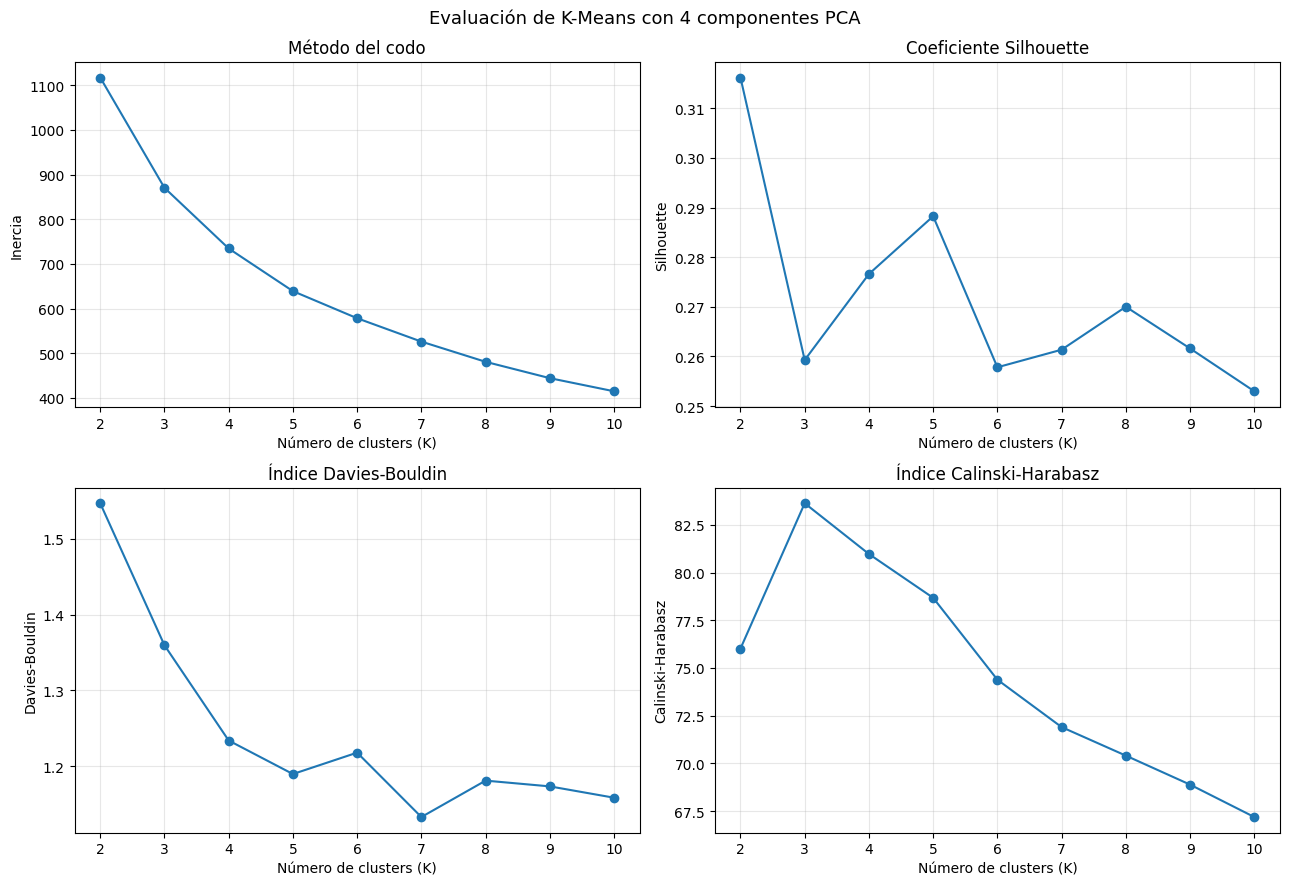


ANÁLISIS COMPLETADO
Sitios analizados: 250
Variables originales: 10
Componentes PCA: 4
Varianza explicada: 58.40%

ARCHIVOS GENERADOS
Dataset PCA:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/4. Dataset_Consolidado/5. PCA/dataset_pca_4_componentes.csv

Tabla de métricas:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/1. Determinacion_Clusters/evaluacion_kmeans_pca4.csv

Gráficas:
/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/1. Determinacion_Clusters/evaluacion_kmeans_pca4.png

La elección final de K debe considerar conjuntamente las métricas, el tamaño de los grupos, su estabilidad y su interpretabilidad para la clasificación de sitios web por accesibilidad.


In [ ]:
# ============================================================
# 7.1. DETERMINACIÓN DEL NÚMERO DE CLUSTERS: PCA + K-MEANS
# Tesis: Clasificación de Sitios Web por Accesibilidad
# Versión ajustada a variables_consolidadas y 4 componentes PCA
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from IPython.display import display

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DE RUTAS
# ------------------------------------------------------------

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

# Dataset estandarizado generado en el apartado 6.4
RUTA_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_consolidado_estandarizado.csv"
)

# Dataset con las puntuaciones de los cuatro componentes PCA
CARPETA_PCA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "5. PCA"
)

RUTA_DATASET_PCA = os.path.join(
    CARPETA_PCA,
    "dataset_pca_4_componentes.csv"
)

# Resultados del apartado 7.1
RUTA_SALIDA = os.path.join(
    BASE_DIR,
    "5. Clustering",
    "1. Determinacion_Clusters"
)

os.makedirs(CARPETA_PCA, exist_ok=True)
os.makedirs(RUTA_SALIDA, exist_ok=True)

RUTA_RESULTADOS = os.path.join(
    RUTA_SALIDA,
    "evaluacion_kmeans_pca4.csv"
)

RUTA_GRAFICA = os.path.join(
    RUTA_SALIDA,
    "evaluacion_kmeans_pca4.png"
)

# ------------------------------------------------------------
# 2. CARGAR Y VALIDAR EL DATASET
# ------------------------------------------------------------

if not os.path.isfile(RUTA_ENTRADA):
    raise FileNotFoundError(
        "No se encontró el dataset estandarizado:\n"
        f"{RUTA_ENTRADA}\n"
        "Verifica que Google Drive esté montado y que hayas ejecutado el apartado 6.4."
    )

# Obtener las variables de la metadata definida previamente.
# Así se evita reutilizar nombres antiguos o duplicar la lista.
if "variables_consolidadas" not in globals():
    raise NameError(
        "No existe 'variables_consolidadas'. Ejecuta primero la celda "
        "donde defines la metadata de las diez variables consolidadas."
    )

VARIABLES = list(variables_consolidadas.keys())

if len(VARIABLES) != 10:
    raise ValueError(
        "Se esperaban 10 variables en 'variables_consolidadas', "
        f"pero se encontraron {len(VARIABLES)}."
    )

df = pd.read_csv(RUTA_ENTRADA)

IDENTIFICADORES = [
    col for col in ["url", "site_key"] if col in df.columns
]

faltantes = [v for v in VARIABLES if v not in df.columns]
if faltantes:
    raise ValueError(
        "Las siguientes variables de 'variables_consolidadas' no aparecen "
        "en el dataset estandarizado:\n- "
        + "\n- ".join(faltantes)
        + "\n\nVerifica que el apartado 6.1 haya generado el dataset con "
        "los nombres nuevos y que 6.3 y 6.4 se hayan ejecutado después."
    )

if df.empty:
    raise ValueError("El dataset no contiene registros.")

if "site_key" in df.columns and df["site_key"].duplicated().any():
    raise ValueError(
        "Hay identificadores site_key duplicados. Revisa el dataset antes de continuar."
    )

X = df[VARIABLES].apply(pd.to_numeric, errors="coerce")

if X.isnull().any().any():
    columnas_con_nulos = X.columns[X.isnull().any()].tolist()
    raise ValueError(
        "Hay valores faltantes en las variables analíticas: "
        + ", ".join(columnas_con_nulos)
        + ". Revisa el apartado 6.3."
    )

if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("Hay valores infinitos en las variables analíticas.")

if len(X) < 11:
    raise ValueError(
        "Se necesitan al menos 11 observaciones para evaluar K de 2 a 10."
    )

print("=" * 70)
print("7.1. DETERMINACIÓN DE CLUSTERS CON PCA + K-MEANS")
print("=" * 70)
print(f"Sitios analizados: {len(X)}")
print(f"Variables analíticas obtenidas desde metadata: {len(VARIABLES)}")
print("Variables utilizadas:")
for i, variable in enumerate(VARIABLES, start=1):
    print(f"  {i:02d}. {variable}")

# ------------------------------------------------------------
# 3. CALCULAR PCA CON CUATRO COMPONENTES
# ------------------------------------------------------------
# Se utilizan cuatro componentes para mantener la coherencia con
# el apartado 6.5.2 y la línea metodológica actual de la tesis.

N_COMPONENTES = 4

if min(X.shape[0], X.shape[1]) < N_COMPONENTES:
    raise ValueError(
        f"No es posible calcular {N_COMPONENTES} componentes PCA "
        "con las dimensiones disponibles."
    )

pca = PCA(n_components=N_COMPONENTES)
puntuaciones = pca.fit_transform(X)

COMPONENTES = [f"PC{i}" for i in range(1, N_COMPONENTES + 1)]

X_pca = pd.DataFrame(
    puntuaciones,
    columns=COMPONENTES,
    index=df.index
)

# Conservar identificadores; no se incluyen las variables originales
# en la matriz utilizada por K-means.
df_pca = (
    df[IDENTIFICADORES].copy()
    if IDENTIFICADORES
    else pd.DataFrame(index=df.index)
)

for componente in COMPONENTES:
    df_pca[componente] = X_pca[componente].values

df_pca.to_csv(
    RUTA_DATASET_PCA,
    index=False,
    encoding="utf-8-sig"
)

varianza_componentes = pca.explained_variance_ratio_ * 100
varianza_explicada = float(varianza_componentes.sum())

print(f"\nComponentes utilizados: {N_COMPONENTES}")
print(f"Varianza explicada por los cuatro componentes: {varianza_explicada:.2f}%")
print("Varianza por componente:")
for componente, varianza in zip(COMPONENTES, varianza_componentes):
    print(f"  {componente}: {varianza:.2f}%")

# ------------------------------------------------------------
# 4. EVALUAR K DESDE 2 HASTA 10
# ------------------------------------------------------------
# Silhouette: mayor suele indicar grupos mejor separados.
# Davies-Bouldin: menor suele indicar grupos más compactos y separados.
# Calinski-Harabasz: mayor suele indicar separación relativa más alta.
# Inercia: se examina como apoyo mediante el método del codo.

resultados = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_pca)

    # Evitar calcular métricas si el modelo no genera todos los grupos.
    if len(np.unique(etiquetas)) != k:
        print(f"Advertencia: se omite K={k}; no se generaron {k} grupos distintos.")
        continue

    resultados.append({
        "k": k,
        "inercia": float(modelo.inertia_),
        "silhouette": float(silhouette_score(X_pca, etiquetas)),
        "davies_bouldin": float(davies_bouldin_score(X_pca, etiquetas)),
        "calinski_harabasz": float(calinski_harabasz_score(X_pca, etiquetas))
    })

resultados_df = pd.DataFrame(resultados)

if resultados_df.empty:
    raise ValueError("No se obtuvieron resultados válidos de K-Means.")

# ------------------------------------------------------------
# 5. MOSTRAR RESULTADOS Y MEJORES MÉTRICAS
# ------------------------------------------------------------

print("\nRESULTADOS DE EVALUACIÓN")
display(resultados_df.round(4))

mejor_sil = resultados_df.loc[resultados_df["silhouette"].idxmax()]
mejor_db = resultados_df.loc[resultados_df["davies_bouldin"].idxmin()]
mejor_ch = resultados_df.loc[resultados_df["calinski_harabasz"].idxmax()]

print("\nMEJOR K SEGÚN CADA MÉTRICA")
print(
    f"Silhouette: K = {int(mejor_sil['k'])} "
    f"(valor: {mejor_sil['silhouette']:.4f})"
)
print(
    f"Davies-Bouldin: K = {int(mejor_db['k'])} "
    f"(valor: {mejor_db['davies_bouldin']:.4f})"
)
print(
    f"Calinski-Harabasz: K = {int(mejor_ch['k'])} "
    f"(valor: {mejor_ch['calinski_harabasz']:.4f})"
)

# ------------------------------------------------------------
# 6. GRÁFICAS DE EVALUACIÓN
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

metricas = [
    ("inercia", "Método del codo", "Inercia"),
    ("silhouette", "Coeficiente Silhouette", "Silhouette"),
    ("davies_bouldin", "Índice Davies-Bouldin", "Davies-Bouldin"),
    ("calinski_harabasz", "Índice Calinski-Harabasz", "Calinski-Harabasz")
]

for ax, (columna, titulo, etiqueta_y) in zip(axes.flat, metricas):
    ax.plot(
        resultados_df["k"],
        resultados_df[columna],
        marker="o"
    )
    ax.set_title(titulo)
    ax.set_xlabel("Número de clusters (K)")
    ax.set_ylabel(etiqueta_y)
    ax.set_xticks(resultados_df["k"])
    ax.grid(alpha=0.3)

fig.suptitle(
    f"Evaluación de K-Means con {N_COMPONENTES} componentes PCA",
    fontsize=13
)

plt.tight_layout()
plt.savefig(RUTA_GRAFICA, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 7. GUARDAR RESULTADOS
# ------------------------------------------------------------

resultados_df.to_csv(
    RUTA_RESULTADOS,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 8. RESUMEN FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("ANÁLISIS COMPLETADO")
print("=" * 70)
print(f"Sitios analizados: {len(X_pca)}")
print(f"Variables originales: {len(VARIABLES)}")
print(f"Componentes PCA: {N_COMPONENTES}")
print(f"Varianza explicada: {varianza_explicada:.2f}%")

print("\nARCHIVOS GENERADOS")
print(f"Dataset PCA:\n{RUTA_DATASET_PCA}")
print(f"\nTabla de métricas:\n{RUTA_RESULTADOS}")
print(f"\nGráficas:\n{RUTA_GRAFICA}")

print(
    "\nLa elección final de K debe considerar conjuntamente las métricas, "
    "el tamaño de los grupos, su estabilidad y su interpretabilidad "
    "para la clasificación de sitios web por accesibilidad."
)

### **7.2 K-Means**

7.3. COMPARACIÓN DE CLUSTERS EN TODOS LOS PLANOS PCA
Sitios analizados: 250
Componentes usados para calcular K-Means: PC1, PC2, PC3, PC4
Valores de K comparados: [3, 4, 5]
Planos evaluados: PC1-PC2, PC1-PC3, PC1-PC4, PC2-PC3, PC2-PC4, PC3-PC4
Nota: K-Means se ajusta en cuatro dimensiones. Los planos 2D son proyecciones para inspección visual.
Asignaciones K=3 guardadas: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/asignaciones_clusters_pca_k3.csv
Asignaciones K=4 guardadas: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/asignaciones_clusters_pca_k4.csv
Asignaciones K=5 guardadas: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/asignaciones_clusters_pca_k5.csv


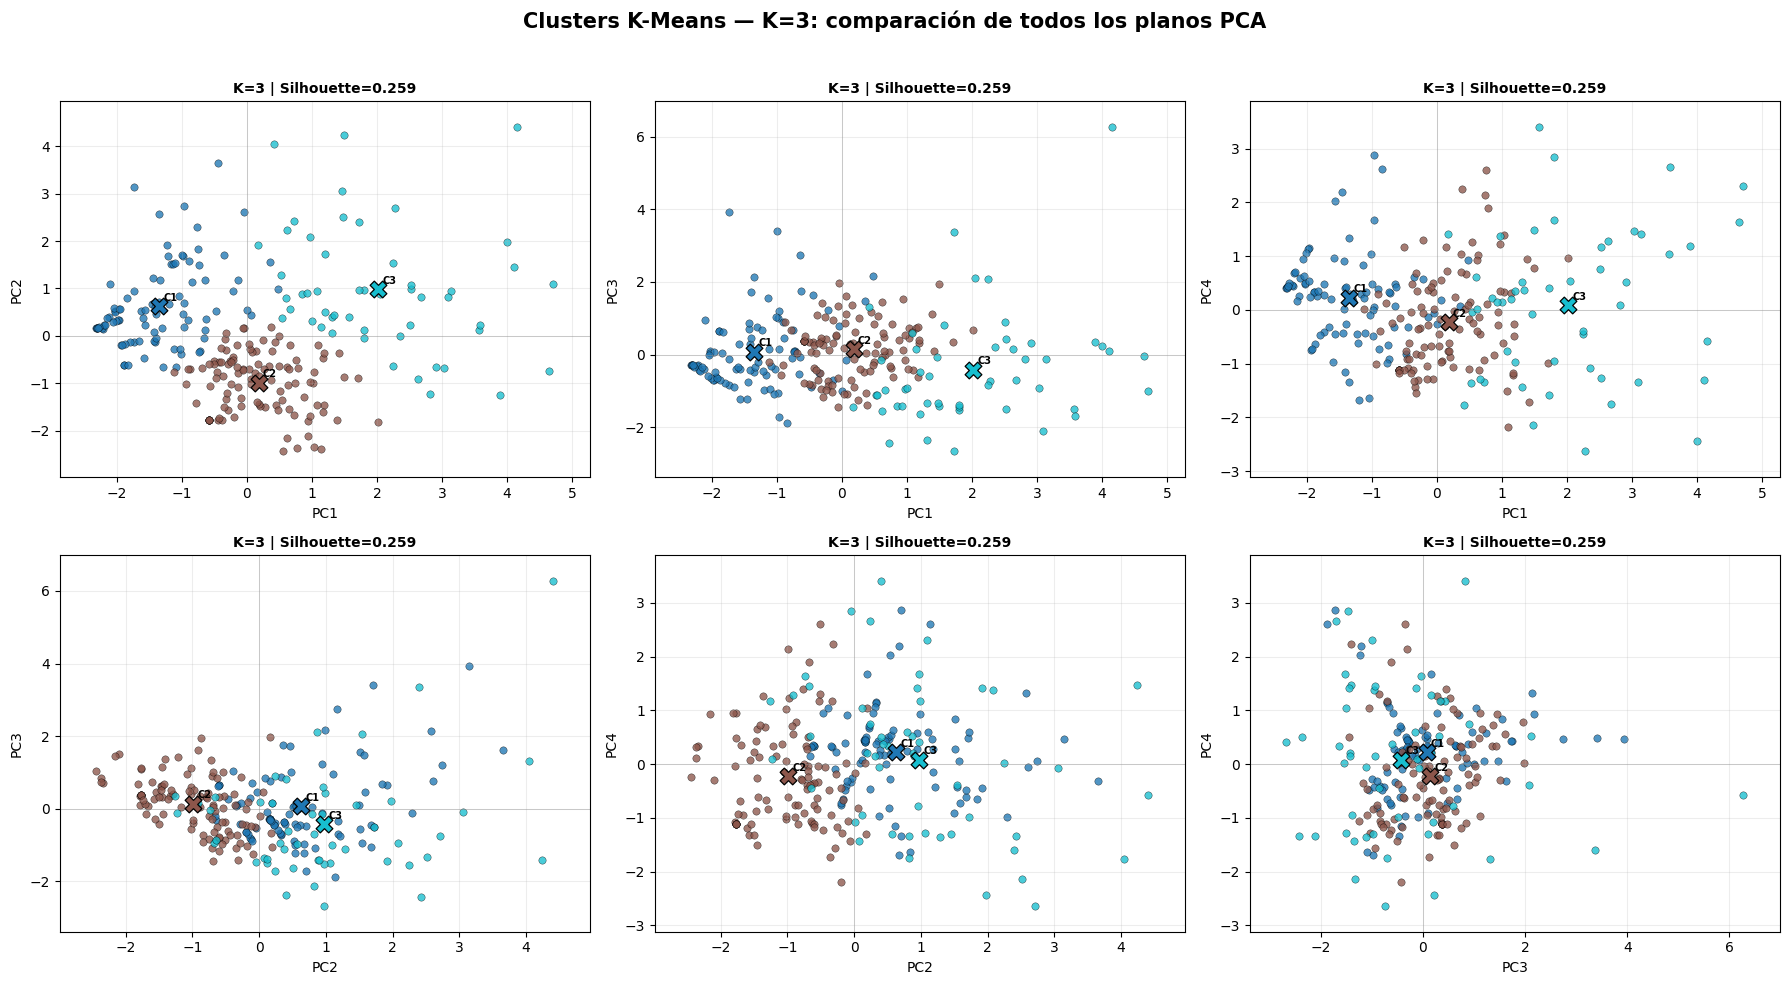

Matriz de seis planos para K=3 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k3.png


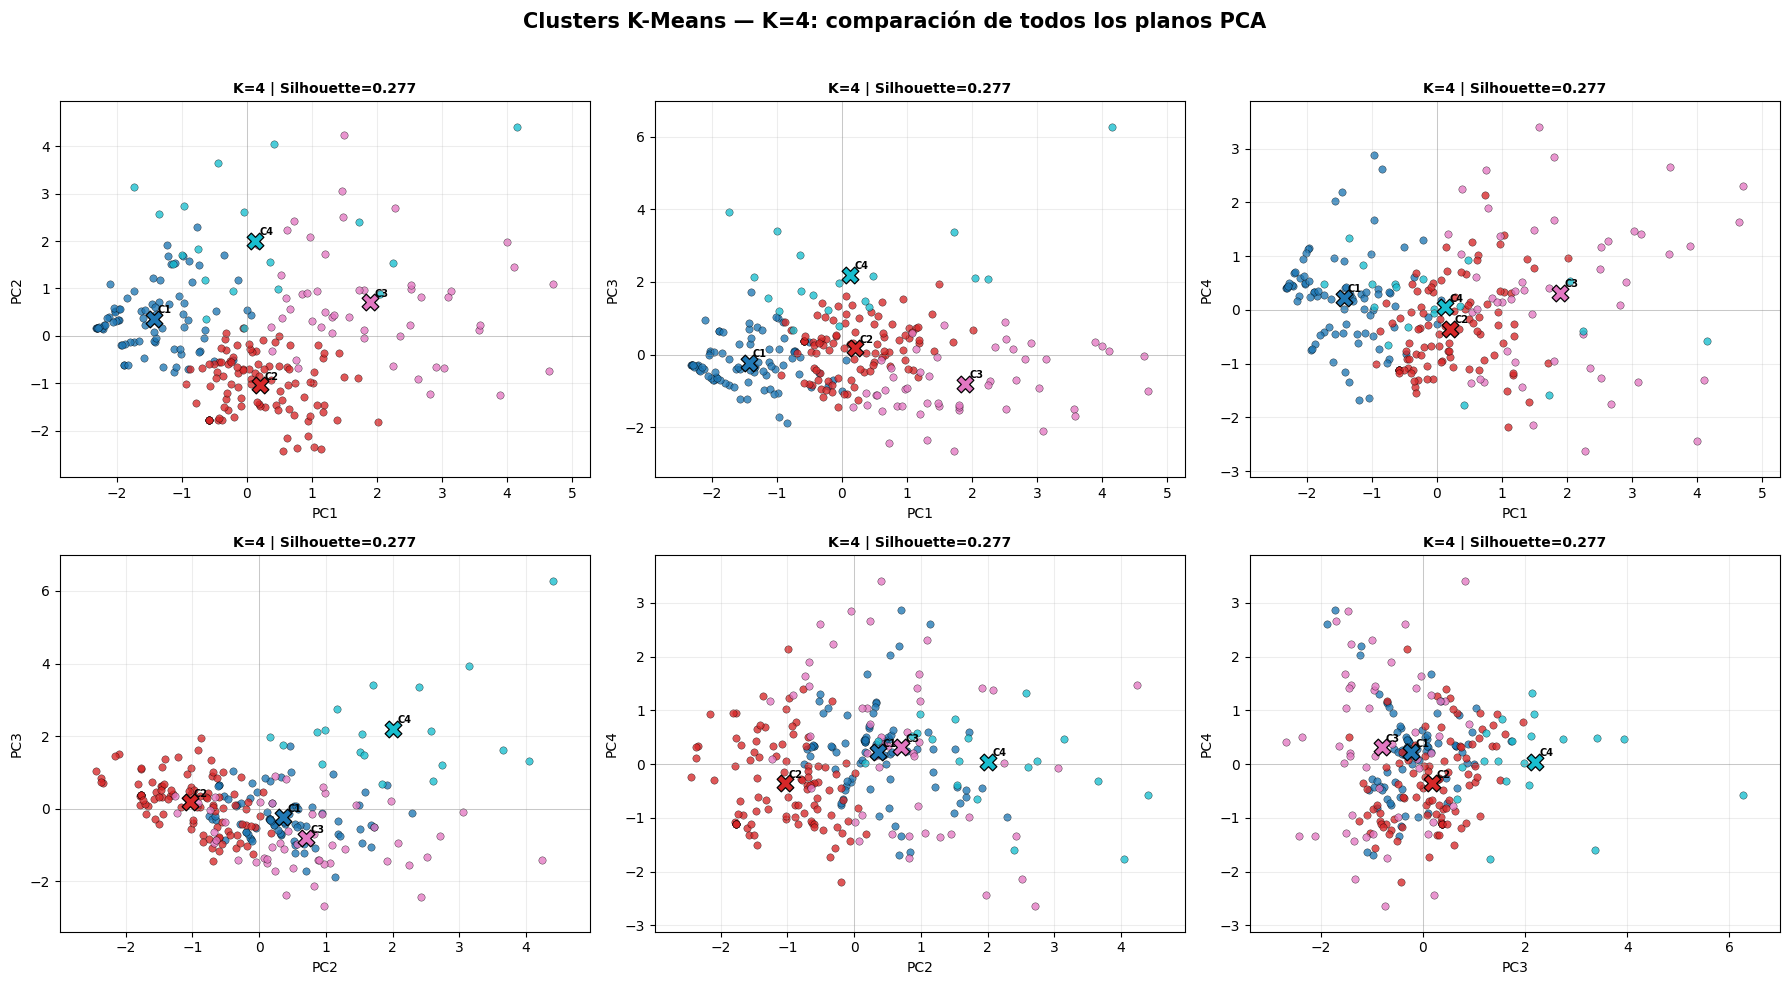

Matriz de seis planos para K=4 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k4.png


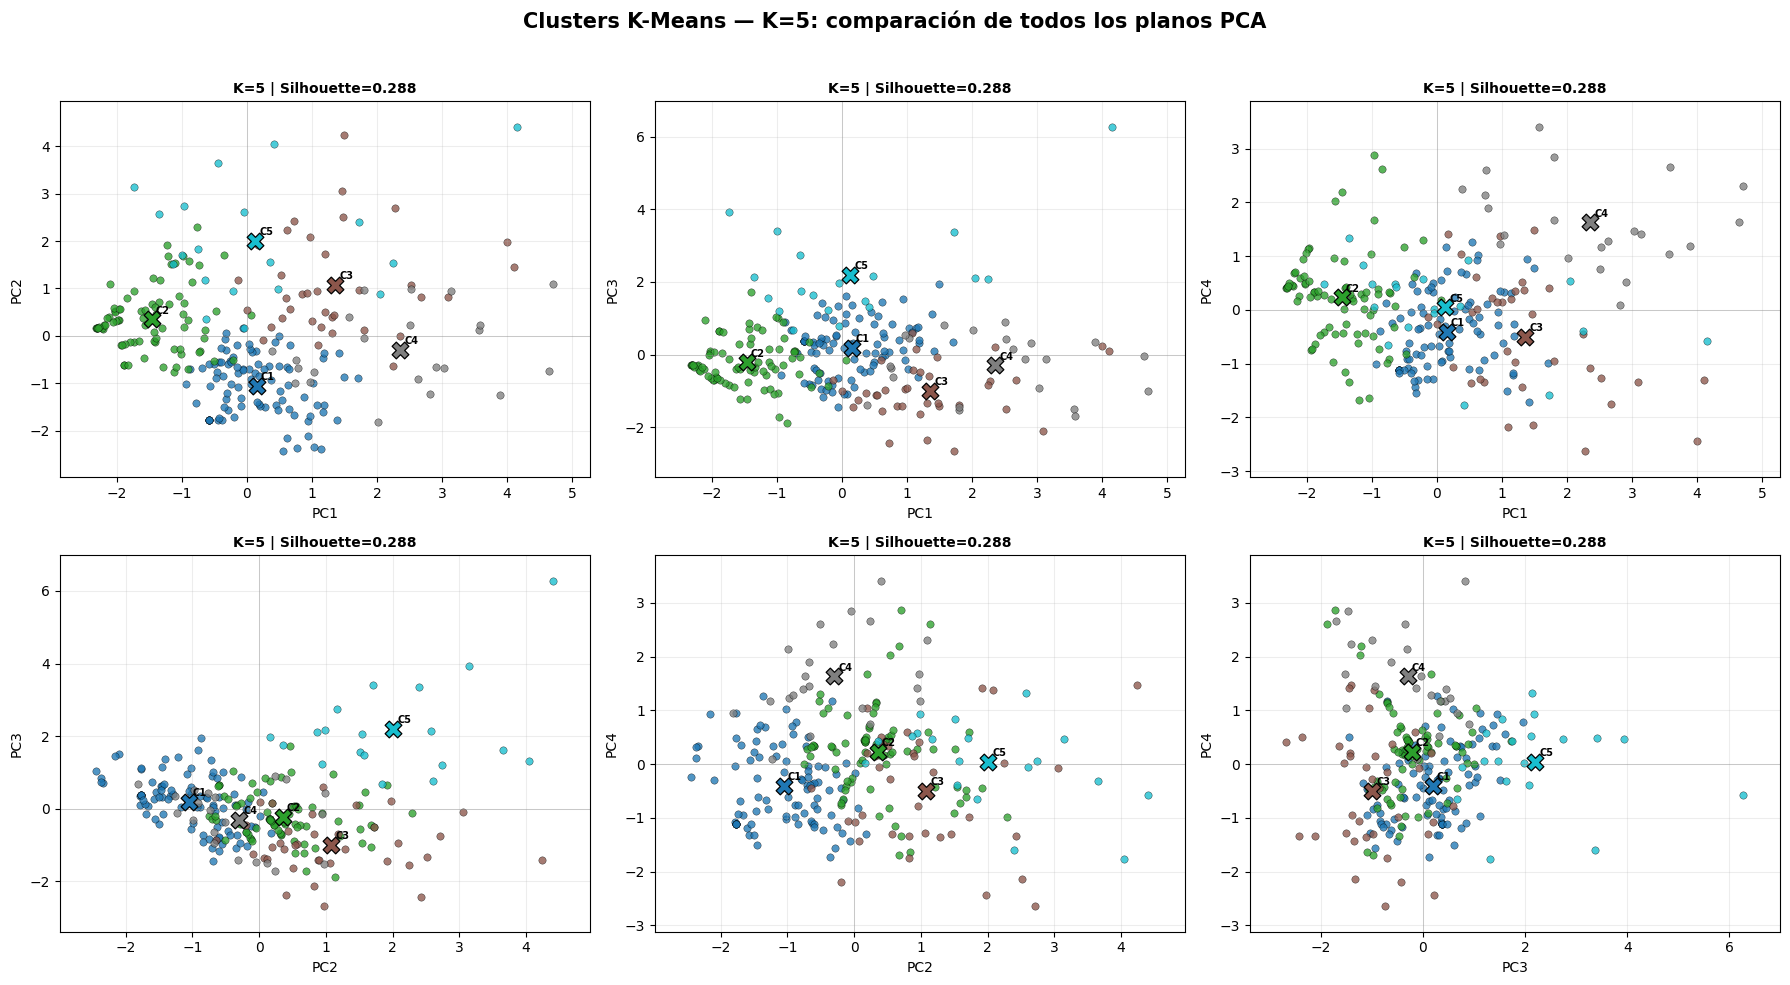

Matriz de seis planos para K=5 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k5.png


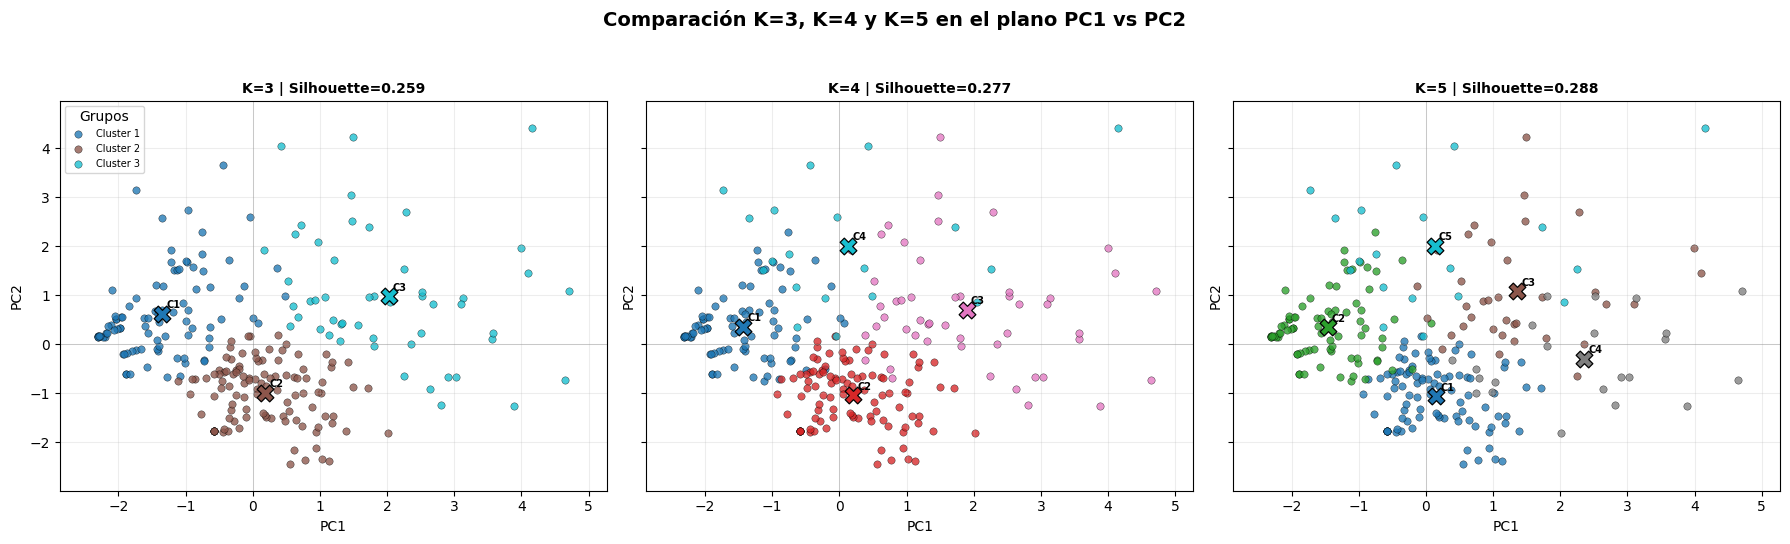

Comparación PC1-PC2 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc1_pc2_k3_k4_k5.png


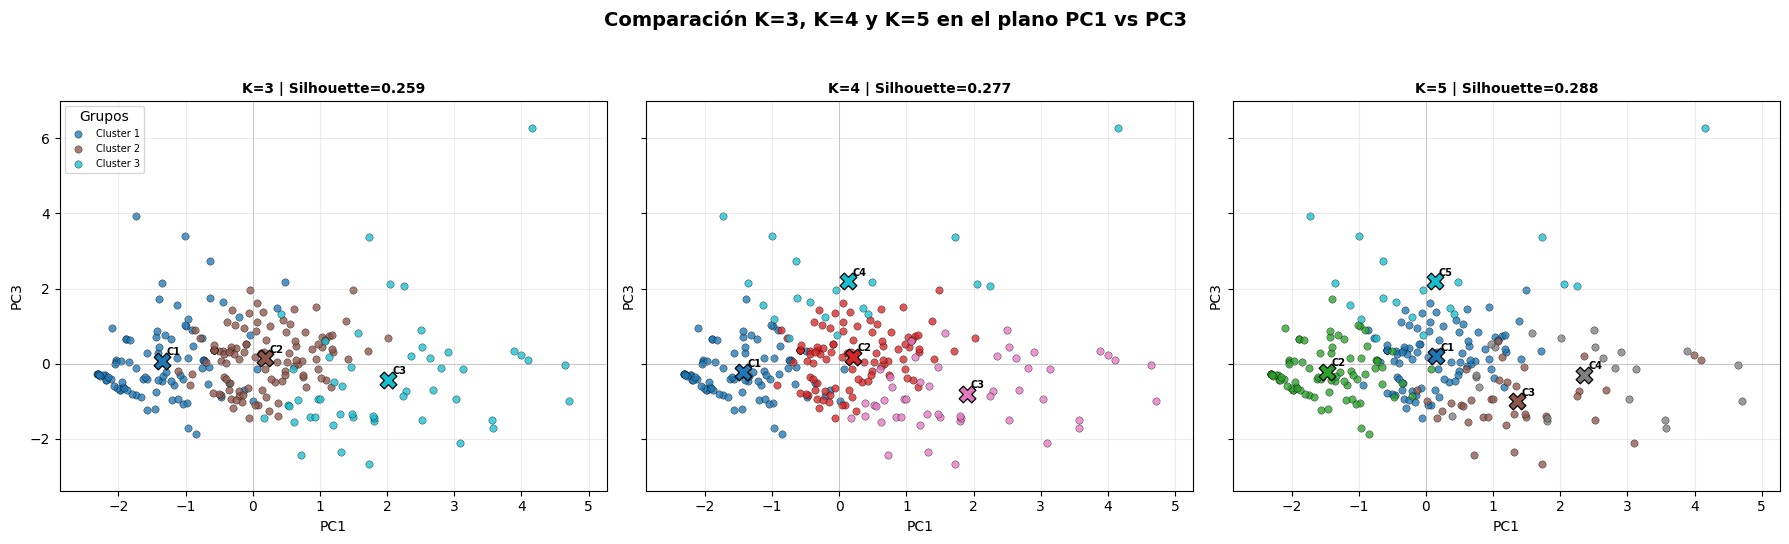

Comparación PC1-PC3 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc1_pc3_k3_k4_k5.png


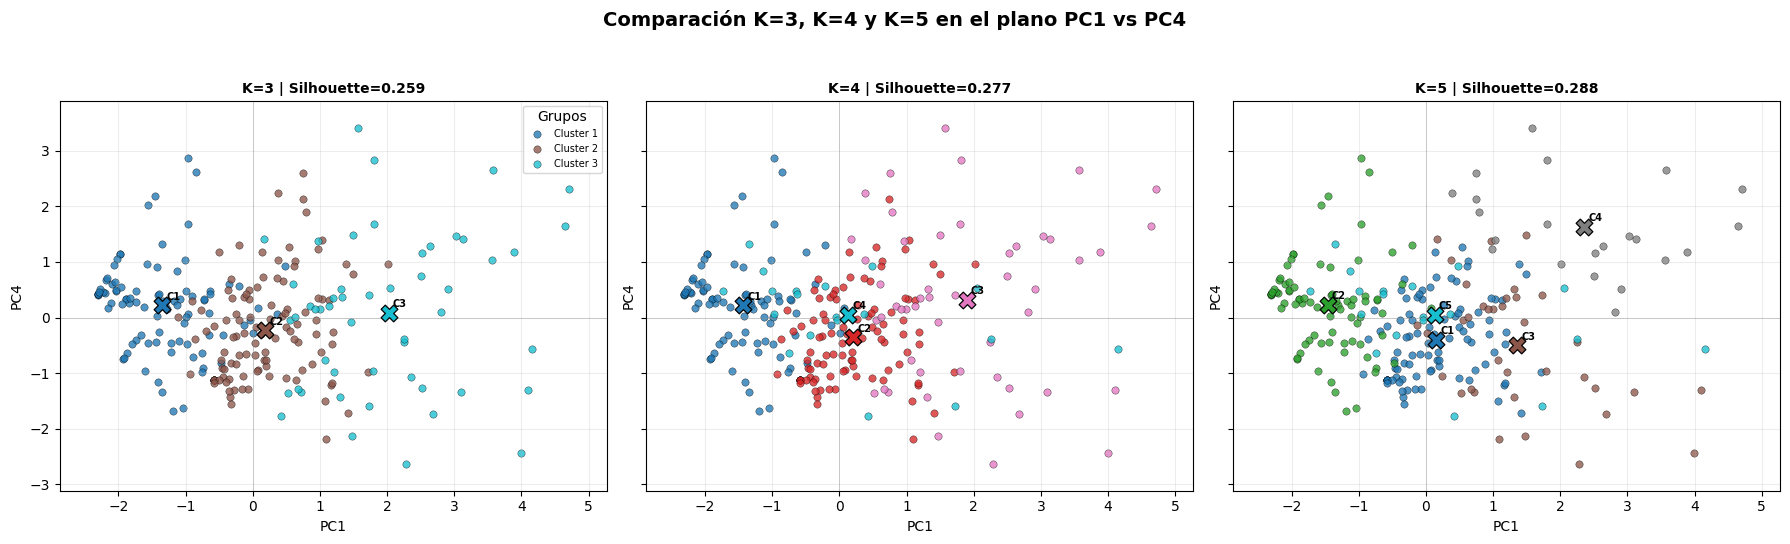

Comparación PC1-PC4 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc1_pc4_k3_k4_k5.png


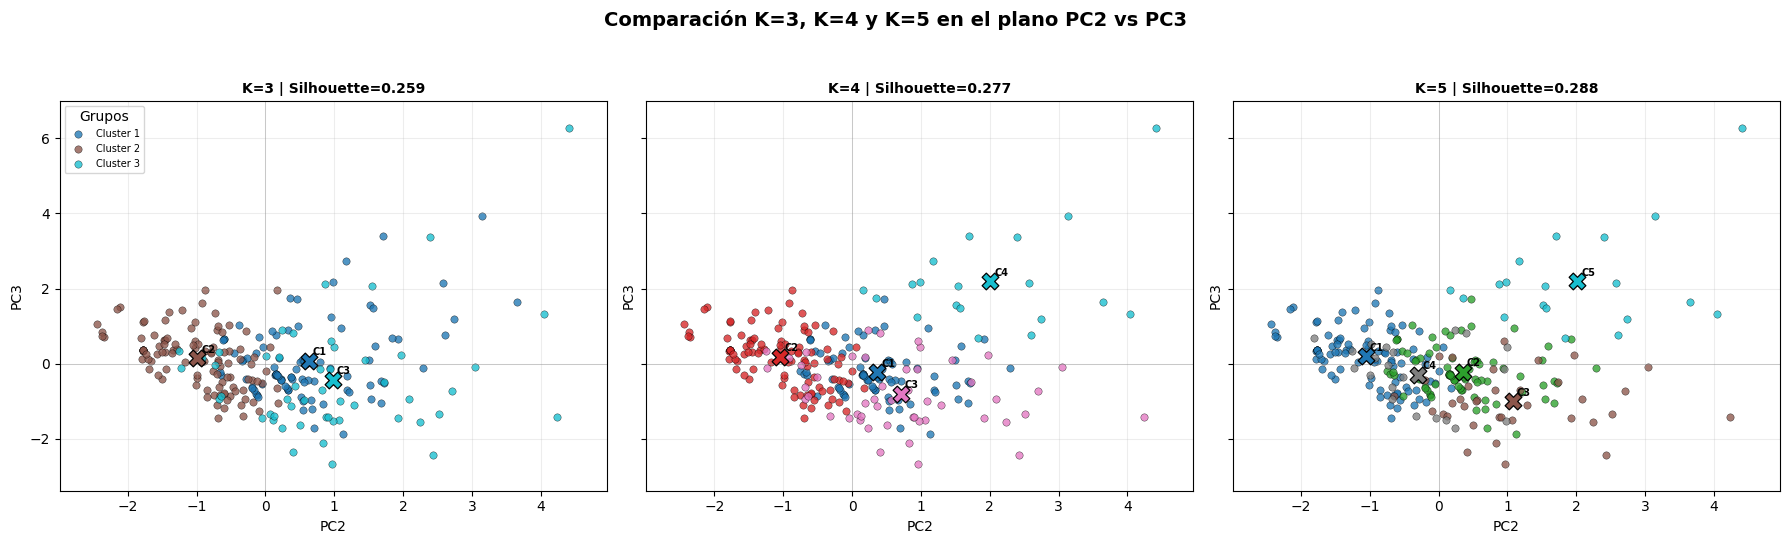

Comparación PC2-PC3 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc2_pc3_k3_k4_k5.png


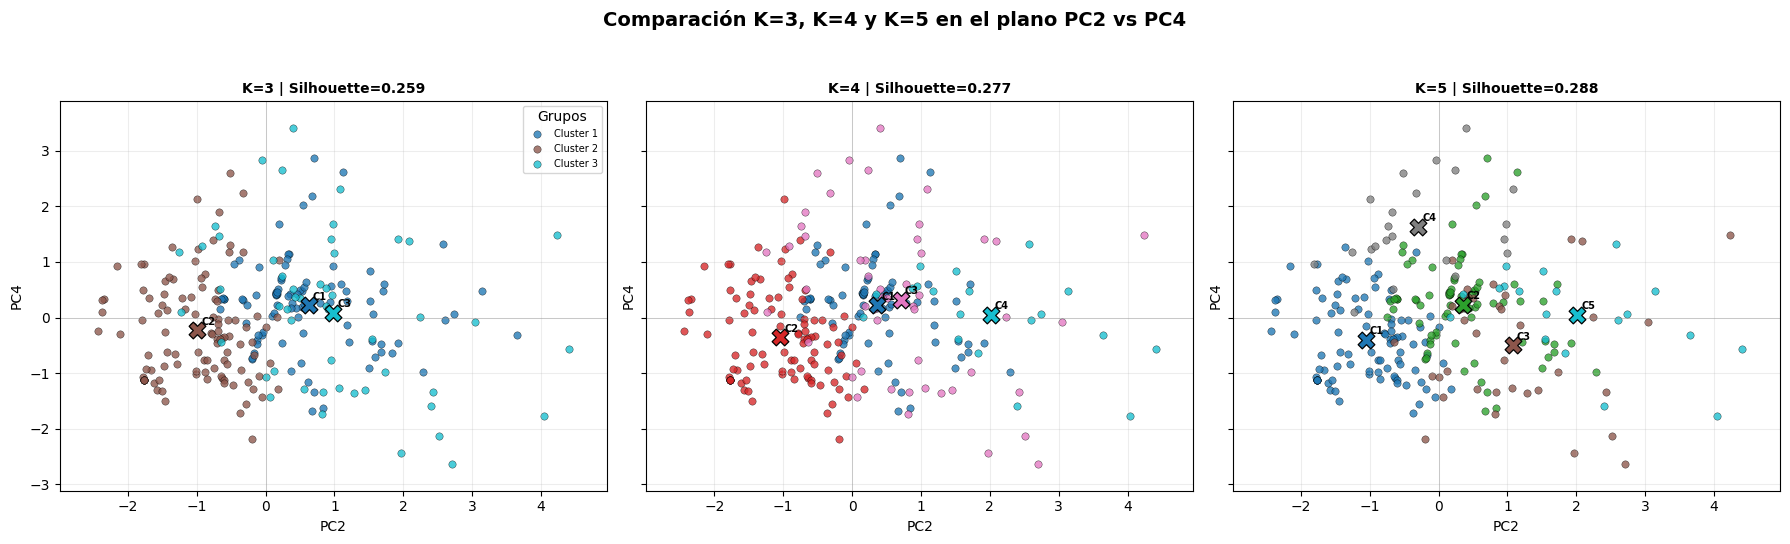

Comparación PC2-PC4 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc2_pc4_k3_k4_k5.png


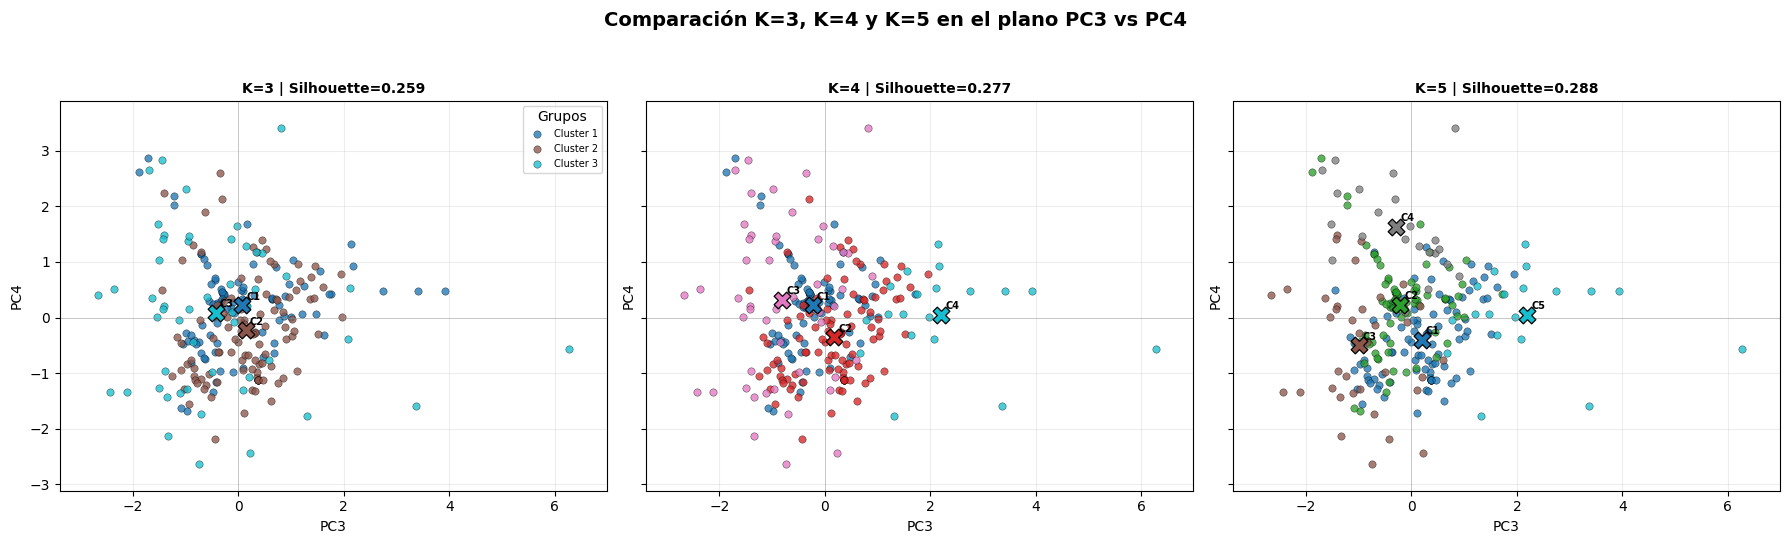

Comparación PC3-PC4 guardada: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_pc3_pc4_k3_k4_k5.png


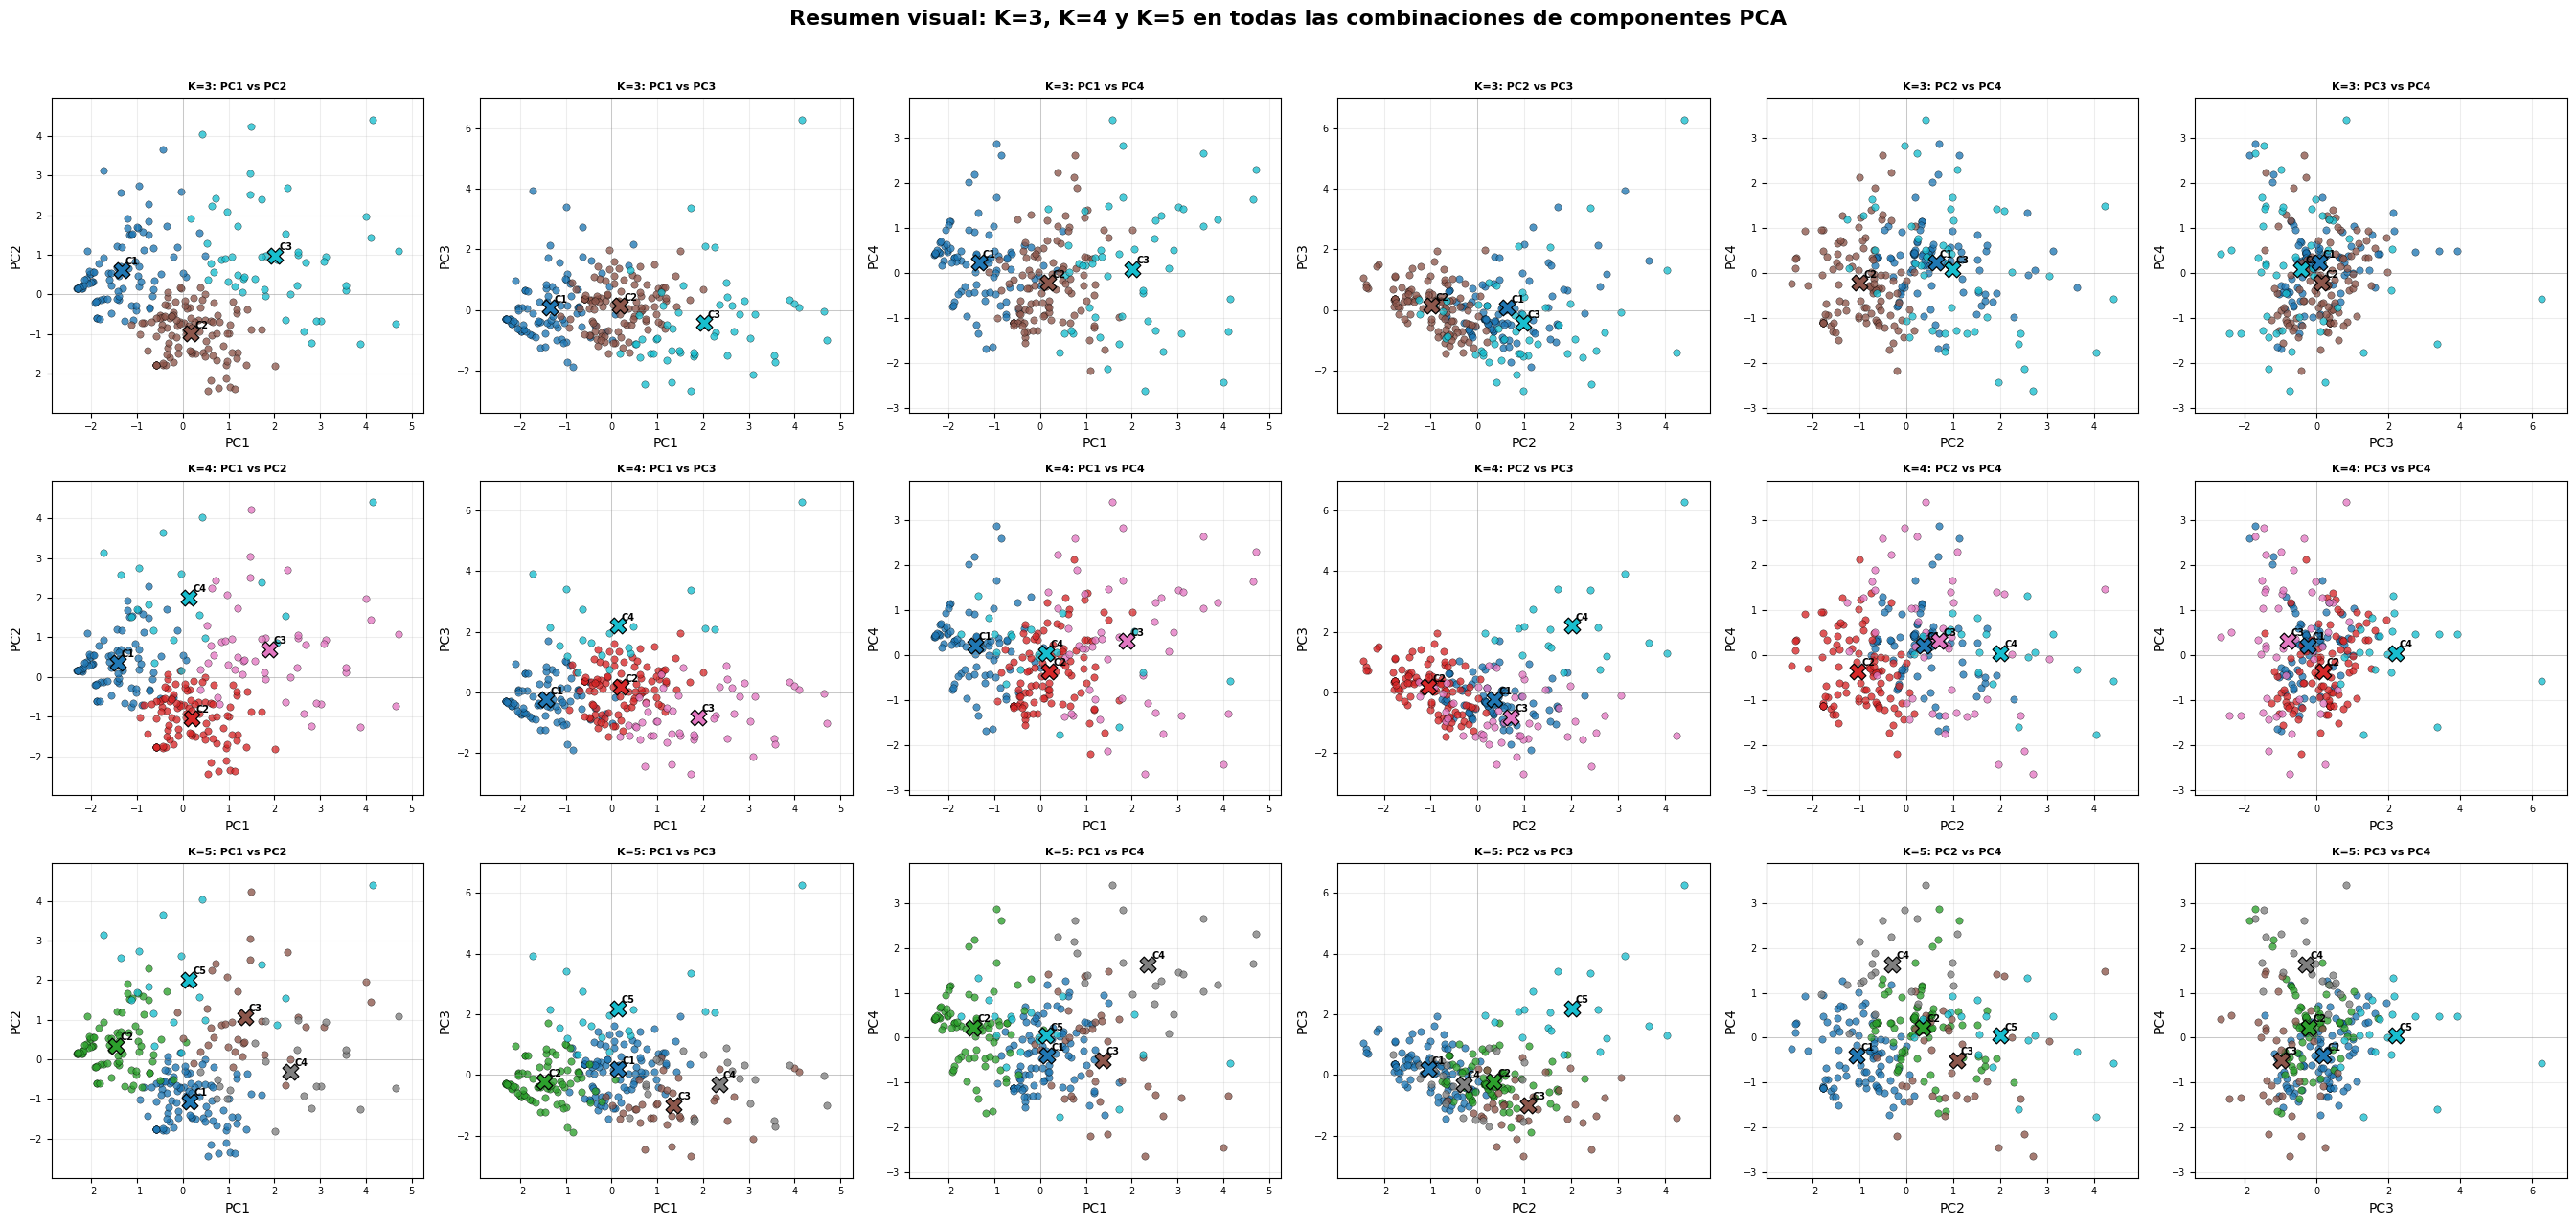


COMPARACIÓN DE CLUSTERS EN TODOS LOS PLANOS PCA COMPLETADA
Métricas (calculadas en las cuatro dimensiones PCA):


,k,inercia_4d,silhouette_4d,davies_bouldin_4d,calinski_harabasz_4d,tamano_cluster_minimo,tamano_cluster_maximo
0,3,870.5515,0.2593,1.3597,83.6283,51,108
1,4,734.6353,0.2766,1.2340,80.9705,19,99
2,5,639.1130,0.2882,1.1897,78.6750,19,93


Tamaños de los clusters:


,k,cluster,cantidad_sitios,porcentaje_sitios
0,3,1,91,36.4
1,3,2,108,43.2
2,3,3,51,20.4
3,4,1,82,32.8
4,4,2,99,39.6
5,4,3,50,20.0
6,4,4,19,7.6
7,5,1,93,37.2
8,5,2,80,32.0
9,5,3,36,14.4



Archivos principales generados:
1. Métricas: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_kmeans_pca_k3_k4_k5.csv
2. Tamaños de clusters: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/tamanos_clusters_pca_k3_k4_k5.csv
3. Resumen visual 3×6: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/comparacion_todos_planos_pca_k3_k4_k5.png
4. Todos los planos para K=3: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k3.png
4. Todos los planos para K=4: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k4.png
4. Todos los planos para K=5: /content/drive/MyDrive/Trabajo de Grado/Archivos_Generados/5. Clustering/2. KMeans/mapa_todos_planos_pca_k5.png

Interpretación: los colores indican las etiquetas de cluster de cada modelo; los nombres C1, C2, etc. no representan el

In [ ]:
# ============================================================
# 7.3. COMPARACIÓN DE CLUSTERS EN TODOS LOS PLANOS PCA: K=3, 4 Y 5
# Tesis: Clasificación de Sitios Web por Accesibilidad
# ============================================================

import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from IPython.display import display

# ------------------------------------------------------------
# 1. RUTAS
# ------------------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/Trabajo de Grado/Archivos_Generados"

RUTA_PCA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "5. PCA",
    "dataset_pca_4_componentes.csv"
)

RUTA_SALIDA = os.path.join(
    BASE_DIR,
    "5. Clustering",
    "2. KMeans"
)
os.makedirs(RUTA_SALIDA, exist_ok=True)

RUTA_RESUMEN_METRICAS = os.path.join(
    RUTA_SALIDA,
    "comparacion_kmeans_pca_k3_k4_k5.csv"
)
RUTA_RESUMEN_TAMANOS = os.path.join(
    RUTA_SALIDA,
    "tamanos_clusters_pca_k3_k4_k5.csv"
)
RUTA_GRAFICA_RESUMEN = os.path.join(
    RUTA_SALIDA,
    "comparacion_todos_planos_pca_k3_k4_k5.png"
)

if not os.path.isfile(RUTA_PCA):
    raise FileNotFoundError(
        "No se encontró el dataset PCA con cuatro componentes:\n"
        f"{RUTA_PCA}\n\n"
        "Ejecuta primero el apartado 7.1, que genera "
        "dataset_pca_4_componentes.csv."
    )

# ------------------------------------------------------------
# 2. CARGAR Y VALIDAR EL DATASET PCA
# ------------------------------------------------------------

df = pd.read_csv(RUTA_PCA)
PCS = ["PC1", "PC2", "PC3", "PC4"]

columnas_faltantes = [col for col in PCS if col not in df.columns]
if columnas_faltantes:
    raise ValueError(
        "El dataset PCA no contiene los componentes requeridos: "
        + ", ".join(columnas_faltantes)
    )
if df.empty:
    raise ValueError("El dataset PCA está vacío.")
if "site_key" in df.columns and df["site_key"].duplicated().any():
    raise ValueError("Se encontraron valores duplicados en site_key.")

X = df[PCS].apply(pd.to_numeric, errors="coerce")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError(
        "Los componentes PCA contienen valores faltantes o infinitos."
    )

K_VALORES = [3, 4, 5]
if len(X) <= max(K_VALORES):
    raise ValueError(
        f"Se necesitan más de {max(K_VALORES)} sitios para ejecutar K-Means."
    )

# Seis combinaciones posibles de ejes con cuatro componentes:
# PC1-PC2, PC1-PC3, PC1-PC4, PC2-PC3, PC2-PC4 y PC3-PC4.
PLANOS = list(combinations(PCS, 2))

print("=" * 78)
print("7.3. COMPARACIÓN DE CLUSTERS EN TODOS LOS PLANOS PCA")
print("=" * 78)
print(f"Sitios analizados: {len(df)}")
print(f"Componentes usados para calcular K-Means: {', '.join(PCS)}")
print(f"Valores de K comparados: {K_VALORES}")
print("Planos evaluados: " + ", ".join(f"{x}-{y}" for x, y in PLANOS))
print(
    "Nota: K-Means se ajusta en cuatro dimensiones. Los planos 2D son "
    "proyecciones para inspección visual."
)

# ------------------------------------------------------------
# 3. AJUSTAR K-MEANS, CALCULAR MÉTRICAS Y GUARDAR ASIGNACIONES
# ------------------------------------------------------------

resultados_metricas = []
resultados_tamanos = []
etiquetas_por_k = {}
modelos_por_k = {}

for k in K_VALORES:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=20)
    etiquetas = modelo.fit_predict(X)

    if len(np.unique(etiquetas)) != k:
        raise ValueError(f"K-Means no generó {k} clusters distintos para K={k}.")

    tamanos = pd.Series(etiquetas + 1).value_counts().sort_index()
    resultados_metricas.append({
        "k": k,
        "inercia_4d": float(modelo.inertia_),
        "silhouette_4d": float(silhouette_score(X, etiquetas)),
        "davies_bouldin_4d": float(davies_bouldin_score(X, etiquetas)),
        "calinski_harabasz_4d": float(calinski_harabasz_score(X, etiquetas)),
        "tamano_cluster_minimo": int(tamanos.min()),
        "tamano_cluster_maximo": int(tamanos.max())
    })

    for cluster, cantidad in tamanos.items():
        resultados_tamanos.append({
            "k": k,
            "cluster": int(cluster),
            "cantidad_sitios": int(cantidad),
            "porcentaje_sitios": float(cantidad / len(df) * 100)
        })

    resultado = df.copy()
    resultado[f"cluster_k{k}"] = etiquetas + 1
    ruta_asignaciones = os.path.join(
        RUTA_SALIDA, f"asignaciones_clusters_pca_k{k}.csv"
    )
    resultado.to_csv(ruta_asignaciones, index=False, encoding="utf-8-sig")
    print(f"Asignaciones K={k} guardadas: {ruta_asignaciones}")

    etiquetas_por_k[k] = etiquetas
    modelos_por_k[k] = modelo

metricas_df = pd.DataFrame(resultados_metricas)
tamanos_df = pd.DataFrame(resultados_tamanos)

# ------------------------------------------------------------
# 4. LÍMITES COMUNES PARA CADA PLANO
# ------------------------------------------------------------
# Los mismos límites se usan al comparar K=3, 4 y 5 dentro de un mismo
# plano. Así, las diferencias visuales no se deben al cambio de escala.

limites_planos = {}
for eje_x, eje_y in PLANOS:
    x_min, x_max = float(X[eje_x].min()), float(X[eje_x].max())
    y_min, y_max = float(X[eje_y].min()), float(X[eje_y].max())
    x_margen = max((x_max - x_min) * 0.08, 0.1)
    y_margen = max((y_max - y_min) * 0.08, 0.1)
    limites_planos[(eje_x, eje_y)] = (
        (x_min - x_margen, x_max + x_margen),
        (y_min - y_margen, y_max + y_margen)
    )

# ------------------------------------------------------------
# 5. FUNCIÓN PARA DIBUJAR UN PLANO PCA
# ------------------------------------------------------------

def dibujar_plano(ax, k, eje_x, eje_y, mostrar_leyenda=False):
    etiquetas = etiquetas_por_k[k]
    modelo = modelos_por_k[k]
    colores = plt.get_cmap("tab10", k)

    for cluster in range(k):
        mascara = etiquetas == cluster
        puntos = X.loc[mascara, [eje_x, eje_y]].to_numpy()
        centroide = modelo.cluster_centers_[cluster, [PCS.index(eje_x), PCS.index(eje_y)]]
        color = colores(cluster)

        ax.scatter(
            puntos[:, 0], puntos[:, 1],
            s=28, color=color, edgecolor="black", linewidth=0.3,
            alpha=0.78, label=f"Cluster {cluster + 1}"
        )
        ax.scatter(
            centroide[0], centroide[1],
            marker="X", s=145, color=color, edgecolor="black",
            linewidth=0.9, zorder=5
        )
        ax.annotate(
            f"C{cluster + 1}", (centroide[0], centroide[1]),
            xytext=(3, 4), textcoords="offset points",
            fontsize=7, fontweight="bold"
        )

    metrica = metricas_df.loc[metricas_df["k"] == k, "silhouette_4d"].iloc[0]
    ax.set_title(f"K={k} | Silhouette={metrica:.3f}", fontsize=10, fontweight="bold")
    ax.set_xlabel(eje_x)
    ax.set_ylabel(eje_y)
    xlim, ylim = limites_planos[(eje_x, eje_y)]
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axhline(0, color="gray", linewidth=0.6, alpha=0.4)
    ax.axvline(0, color="gray", linewidth=0.6, alpha=0.4)
    ax.grid(alpha=0.22)
    if mostrar_leyenda:
        ax.legend(title="Grupos", fontsize=7, loc="best")

# ------------------------------------------------------------
# 6. UNA MATRIZ DE SEIS PLANOS PARA CADA K
# ------------------------------------------------------------
# Cada figura permite inspeccionar el mismo resultado de clustering
# desde las seis combinaciones de ejes posibles.

for k in K_VALORES:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    for ax, (eje_x, eje_y) in zip(axes.flat, PLANOS):
        dibujar_plano(ax, k, eje_x, eje_y, mostrar_leyenda=False)

    fig.suptitle(
        f"Clusters K-Means — K={k}: comparación de todos los planos PCA",
        fontsize=15, fontweight="bold"
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    ruta_figura = os.path.join(RUTA_SALIDA, f"mapa_todos_planos_pca_k{k}.png")
    plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Matriz de seis planos para K={k} guardada: {ruta_figura}")

# ------------------------------------------------------------
# 7. COMPARAR K=3, K=4 Y K=5 EN CADA PLANO
# ------------------------------------------------------------
# Se genera un archivo por combinación de ejes, con tres paneles:
# K=3, K=4 y K=5, usando los mismos límites del plano.

for eje_x, eje_y in PLANOS:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
    for ax, k in zip(axes, K_VALORES):
        dibujar_plano(ax, k, eje_x, eje_y, mostrar_leyenda=(k == K_VALORES[0]))

    fig.suptitle(
        f"Comparación K=3, K=4 y K=5 en el plano {eje_x} vs {eje_y}",
        fontsize=14, fontweight="bold"
    )
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    ruta_figura = os.path.join(
        RUTA_SALIDA,
        f"comparacion_{eje_x.lower()}_{eje_y.lower()}_k3_k4_k5.png"
    )
    plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Comparación {eje_x}-{eje_y} guardada: {ruta_figura}")

# ------------------------------------------------------------
# 8. RESUMEN GENERAL EN UNA FIGURA DE 3 FILAS × 6 COLUMNAS
# ------------------------------------------------------------
# Cada fila representa un K y cada columna, una combinación de componentes.

fig, axes = plt.subplots(3, 6, figsize=(27, 13), squeeze=False)
for fila, k in enumerate(K_VALORES):
    for columna, (eje_x, eje_y) in enumerate(PLANOS):
        ax = axes[fila, columna]
        dibujar_plano(ax, k, eje_x, eje_y, mostrar_leyenda=False)
        ax.set_title(f"K={k}: {eje_x} vs {eje_y}", fontsize=8, fontweight="bold")
        ax.tick_params(axis="both", labelsize=7)

fig.suptitle(
    "Resumen visual: K=3, K=4 y K=5 en todas las combinaciones de componentes PCA",
    fontsize=16, fontweight="bold"
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(RUTA_GRAFICA_RESUMEN, dpi=250, bbox_inches="tight")
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. EXPORTAR MÉTRICAS Y TAMAÑOS DE LOS CLUSTERS
# ------------------------------------------------------------

metricas_df.to_csv(RUTA_RESUMEN_METRICAS, index=False, encoding="utf-8-sig")
tamanos_df.to_csv(RUTA_RESUMEN_TAMANOS, index=False, encoding="utf-8-sig")

print("\n" + "=" * 78)
print("COMPARACIÓN DE CLUSTERS EN TODOS LOS PLANOS PCA COMPLETADA")
print("=" * 78)
print("Métricas (calculadas en las cuatro dimensiones PCA):")
display(metricas_df.round(4))
print("Tamaños de los clusters:")
display(tamanos_df)

print("\nArchivos principales generados:")
print(f"1. Métricas: {RUTA_RESUMEN_METRICAS}")
print(f"2. Tamaños de clusters: {RUTA_RESUMEN_TAMANOS}")
print(f"3. Resumen visual 3×6: {RUTA_GRAFICA_RESUMEN}")
for k in K_VALORES:
    print(f"4. Todos los planos para K={k}: {os.path.join(RUTA_SALIDA, f'mapa_todos_planos_pca_k{k}.png')}")
print("\nInterpretación: los colores indican las etiquetas de cluster de cada modelo; "
      "los nombres C1, C2, etc. no representan el mismo grupo entre distintos valores de K.")

### **7.3 Validacion del K-MEANS - SILHOUETTE**

In [ ]:
# ============================================================
# 7.3 VALIDACIÓN DEL K-MEANS - SILHOUETTE POR SITIO
#     ESCENARIO MX
# ============================================================


# ============================================================
# CONFIGURACIÓN
# ============================================================

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning
)

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning
)

os.environ[
    "PYTHONWARNINGS"
] = (
    "ignore::DeprecationWarning,"
    "ignore::RuntimeWarning"
)

logging.getLogger().setLevel(
    logging.ERROR
)

# ============================================================
# 1. RUTA PRINCIPAL
# ============================================================

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

# ============================================================
# 2. RUTA DE ENTRADA
# ============================================================

RUTA_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_mx_estandarizado.csv"
)

# ============================================================
# 3. RUTA DE SALIDA - 5. CLUSTERING
# ============================================================

RUTA_CLUSTERING = os.path.join(
    BASE_DIR,
    "5. Clustering"
)

RUTA_SALIDA = os.path.join(
    RUTA_CLUSTERING,
    "3. Validacion_Silhouette"
)

os.makedirs(
    RUTA_SALIDA,
    exist_ok=True
)

# ============================================================
# 4. ARCHIVOS DE SALIDA
# ============================================================

RUTA_SILHOUETTE = os.path.join(
    RUTA_SALIDA,
    "silhouette_por_sitio_k2_mx.csv"
)

RUTA_RESUMEN = os.path.join(
    RUTA_SALIDA,
    "resumen_silhouette_clusters_k2_mx.csv"
)

RUTA_GRAFICA = os.path.join(
    RUTA_SALIDA,
    "silhouette_plot_k2_mx.png"
)

# ============================================================
# 5. K SELECCIONADO
# ============================================================


K_SELECCIONADO = 7

# ============================================================
# 6. VALIDAR ARCHIVO
# ============================================================

if not os.path.isfile(RUTA_ENTRADA):

    raise FileNotFoundError(
        "\n❌ No se encontró el dataset "
        "estandarizado MX:\n"
        f"{RUTA_ENTRADA}"
    )

# ============================================================
# 7. CARGAR DATOS
# ============================================================

df = pd.read_csv(
    RUTA_ENTRADA
)

print("=" * 70)

print(
    "7.3 VALIDACIÓN DEL K-MEANS - SILHOUETTE POR SITIO"
)

print("=" * 70)

print(
    f"\n📂 Entrada:\n"
    f"{RUTA_ENTRADA}"
)

print(
    f"\n🌐 Sitios: "
    f"{df.shape[0]}"
)

print(
    f"📊 Columnas totales: "
    f"{df.shape[1]}"
)

# ============================================================
# 8. VARIABLES ANALÍTICAS
# ============================================================

COLUMNAS_IDENTIFICACION = [
    "url",
    "site_key"
]

variables_analiticas = [
    col
    for col in df.columns
    if col not in COLUMNAS_IDENTIFICACION
]

X = df[
    variables_analiticas
].copy()

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

print(
    f"📈 Variables analíticas: "
    f"{X.shape[1]}"
)

print(
    f"❌ Valores faltantes: "
    f"{int(X.isna().sum().sum())}"
)

print(
    f"♾️ Valores infinitos: "
    f"{int(np.isinf(X.to_numpy()).sum())}"
)

# ============================================================
# 9. VALIDACIONES
# ============================================================

if X.shape[1] != 10:

    raise ValueError(
        f"❌ Se esperaban 10 variables analíticas "
        f"y se encontraron {X.shape[1]}."
    )

if X.isna().sum().sum() > 0:

    raise ValueError(
        "❌ La matriz contiene valores faltantes."
    )

if np.isinf(
    X.to_numpy()
).sum() > 0:

    raise ValueError(
        "❌ La matriz contiene valores infinitos."
    )

if (X.nunique() <= 1).any():

    raise ValueError(
        "❌ La matriz contiene variables constantes."
    )

if K_SELECCIONADO >= len(X):

    raise ValueError(
        "❌ K debe ser menor que el número de sitios."
    )

print(
    f"🔢 K validado: "
    f"{K_SELECCIONADO}"
)

# ============================================================
# 10. EJECUTAR K-MEANS
#     MISMA CONFIGURACIÓN DE 7.2
# ============================================================

modelo_kmeans = KMeans(
    n_clusters=K_SELECCIONADO,
    random_state=42,
    n_init=20
)

etiquetas = modelo_kmeans.fit_predict(
    X
)

# ============================================================
# 11. CALCULAR SILHOUETTE POR SITIO
# ============================================================

silhouette_valores = silhouette_samples(
    X,
    etiquetas
)

silhouette_global = silhouette_score(
    X,
    etiquetas
)

# ============================================================
# 12. DATASET DE RESULTADOS
# ============================================================

df_silhouette = df[
    [
        "url",
        "site_key"
    ]
].copy()

df_silhouette[
    "cluster"
] = etiquetas + 1

df_silhouette[
    "silhouette"
] = silhouette_valores

df_silhouette = (
    df_silhouette
    .sort_values(
        [
            "cluster",
            "silhouette"
        ],
        ascending=[
            True,
            True
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================
# 13. RESUMEN POR CLUSTER
# ============================================================

resumen_clusters = (
    df_silhouette
    .groupby(
        "cluster"
    )[
        "silhouette"
    ]
    .agg(
        num_sitios="count",
        promedio="mean",
        minimo="min",
        maximo="max",
        mediana="median"
    )
    .reset_index()
)

# ============================================================
# 14. SITIOS CON SILHOUETTE BAJO
# ============================================================

sitios_bajos = (
    df_silhouette[
        df_silhouette[
            "silhouette"
        ] < 0.10
    ]
    .copy()
)

# ============================================================
# 15. SITIOS CON SILHOUETTE NEGATIVO
# ============================================================

sitios_negativos = (
    df_silhouette[
        df_silhouette[
            "silhouette"
        ] < 0
    ]
    .copy()
)

# ============================================================
# 16. RESULTADOS EN CONSOLA
# ============================================================

print(
    "\n" + "-" * 70
)

print(
    "📊 RESULTADO GLOBAL"
)

print(
    "-" * 70
)

print(
    f"K utilizado: "
    f"{K_SELECCIONADO}"
)

print(
    f"Sitios analizados: "
    f"{len(df_silhouette)}"
)

print(
    f"Silhouette global: "
    f"{silhouette_global:.4f}"
)

# ============================================================
# 17. RESUMEN POR CLUSTER
# ============================================================

print(
    "\n" + "-" * 70
)

print(
    "📊 RESUMEN POR CLUSTER"
)

print(
    "-" * 70
)

print(
    resumen_clusters.to_string(
        index=False,
        formatters={

            "promedio":
                "{:.4f}".format,

            "minimo":
                "{:.4f}".format,

            "maximo":
                "{:.4f}".format,

            "mediana":
                "{:.4f}".format
        }
    )
)

# ============================================================
# 18. SITIOS CON SILHOUETTE < 0.10
# ============================================================

print(
    "\n" + "-" * 70
)

print(
    "⚠️ SITIOS CON SILHOUETTE < 0.10"
)

print(
    "-" * 70
)

print(
    f"Cantidad: "
    f"{len(sitios_bajos)}"
)

if len(sitios_bajos) > 0:

    print(
        sitios_bajos[
            [
                "url",
                "cluster",
                "silhouette"
            ]
        ].to_string(
            index=False,
            formatters={
                "silhouette":
                    "{:.4f}".format
            }
        )
    )

else:

    print(
        "✅ No se encontraron sitios "
        "con silhouette < 0.10."
    )

# ============================================================
# 19. SITIOS CON SILHOUETTE NEGATIVO
# ============================================================

print(
    "\n" + "-" * 70
)

print(
    "🚨 SITIOS CON SILHOUETTE NEGATIVO"
)

print(
    "-" * 70
)

print(
    f"Cantidad: "
    f"{len(sitios_negativos)}"
)

if len(sitios_negativos) > 0:

    print(
        sitios_negativos[
            [
                "url",
                "cluster",
                "silhouette"
            ]
        ].to_string(
            index=False,
            formatters={
                "silhouette":
                    "{:.4f}".format
            }
        )
    )

else:

    print(
        "✅ No se encontraron sitios "
        "con silhouette negativo."
    )

# ============================================================
# 20. SILHOUETTE PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 7)
)

y_lower = 10

for cluster in range(
    K_SELECCIONADO
):

    valores_cluster = (
        silhouette_valores[
            etiquetas == cluster
        ]
    )

    valores_cluster = np.sort(
        valores_cluster
    )

    tamaño_cluster = len(
        valores_cluster
    )

    y_upper = (
        y_lower
        + tamaño_cluster
    )

    ax.fill_betweenx(
        np.arange(
            y_lower,
            y_upper
        ),
        0,
        valores_cluster
    )

    ax.text(
        -0.05,
        y_lower
        + 0.5 * tamaño_cluster,
        f"Cluster {cluster + 1}"
    )

    y_lower = (
        y_upper + 10
    )

ax.axvline(
    x=silhouette_global,
    linestyle="--",
    linewidth=2,
    label=(
        f"Promedio global = "
        f"{silhouette_global:.4f}"
    )
)

ax.set_title(
    f"Silhouette Plot - K-Means "
    f"(K={K_SELECCIONADO}) - MX"
)

ax.set_xlabel(
    "Coeficiente de Silhouette"
)

ax.set_ylabel(
    "Observaciones"
)

ax.legend()

plt.tight_layout()

# ============================================================
# 21. GUARDAR GRÁFICA
# ============================================================

plt.savefig(
    RUTA_GRAFICA,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 22. GUARDAR SILHOUETTE POR SITIO
# ============================================================

df_silhouette.to_csv(
    RUTA_SILHOUETTE,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 23. GUARDAR RESUMEN POR CLUSTER
# ============================================================

resumen_clusters.to_csv(
    RUTA_RESUMEN,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 24. RESULTADO FINAL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "✅ 7.3 VALIDACIÓN SILHOUETTE FINALIZADA"
)

print(
    "=" * 70
)

print(
    f"🌐 Sitios analizados: "
    f"{len(df_silhouette)}"
)

print(
    f"📊 Variables analíticas: "
    f"{len(variables_analiticas)}"
)

print(
    f"🔢 K utilizado: "
    f"{K_SELECCIONADO}"
)

print(
    f"📈 Silhouette global: "
    f"{silhouette_global:.4f}"
)

print(
    f"⚠️ Sitios con silhouette < 0.10: "
    f"{len(sitios_bajos)}"
)

print(
    f"🚨 Sitios con silhouette negativo: "
    f"{len(sitios_negativos)}"
)

# ============================================================
# 25. ARCHIVOS GENERADOS
# ============================================================

print(
    "\n💾 ARCHIVOS GENERADOS"
)

print(
    "-" * 70
)

print(
    f"📄 Silhouette por sitio:\n"
    f"{RUTA_SILHOUETTE}"
)

print(
    f"\n📄 Resumen por cluster:\n"
    f"{RUTA_RESUMEN}"
)

print(
    f"\n📊 Gráfica:\n"
    f"{RUTA_GRAFICA}"
)


### **7.4 DBSCAN**

DBSCAN no encuentra, para el escenario MX, una estructura de múltiples clusters claramente definida con bajo nivel de ruido. Al disminuir eps, aparecen dos o más grupos, pero a costa de clasificar una proporción considerable de los sitios como ruido; al aumentar eps, la mayoría de las observaciones se integran en un único cluster. Este comportamiento sugiere que la estructura observada mediante K-Means no está caracterizada principalmente por regiones densas diferenciadas. No obstante, DBSCAN identifica como ruido a movilidadbogota.gov.co, coincidiendo con su coeficiente de Silhouette negativo en K-Means.

In [ ]:
# ============================================================
# 7.4 DBSCAN - EXPLORACIÓN DE PARÁMETROS Y EJECUCIÓN
#     ESCENARIO MX
# ============================================================


# ============================================================
# CONFIGURACIÓN
# ============================================================

warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning
)

warnings.filterwarnings(
    "ignore",
    category=RuntimeWarning
)

os.environ[
    "PYTHONWARNINGS"
] = (
    "ignore::DeprecationWarning,"
    "ignore::RuntimeWarning"
)

logging.getLogger().setLevel(
    logging.ERROR
)

# ============================================================
# 1. RUTA PRINCIPAL
# ============================================================

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

# ============================================================
# 2. DATASET DE ENTRADA
# ============================================================

RUTA_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_mx_estandarizado.csv"
)

# ============================================================
# 3. CARPETA DE SALIDA
# ============================================================

RUTA_CLUSTERING = os.path.join(
    BASE_DIR,
    "5. Clustering"
)

RUTA_SALIDA = os.path.join(
    RUTA_CLUSTERING,
    "4. DBSCAN"
)

os.makedirs(
    RUTA_SALIDA,
    exist_ok=True
)

# ============================================================
# 4. ARCHIVOS DE SALIDA
# ============================================================

RUTA_KDISTANCE = os.path.join(
    RUTA_SALIDA,
    "grafica_k_distance_mx.png"
)

RUTA_PARAMETROS = os.path.join(
    RUTA_SALIDA,
    "exploracion_parametros_dbscan_mx.csv"
)

RUTA_DATASET = os.path.join(
    RUTA_SALIDA,
    "dataset_dbscan_mx.csv"
)

RUTA_DISTRIBUCION = os.path.join(
    RUTA_SALIDA,
    "distribucion_clusters_dbscan_mx.csv"
)

# ============================================================
# 5. VALIDAR DATASET
# ============================================================

if not os.path.isfile(RUTA_ENTRADA):

    raise FileNotFoundError(
        "\n❌ No se encontró el dataset MX estandarizado:\n"
        f"{RUTA_ENTRADA}"
    )

# ============================================================
# 6. CARGAR DATASET
# ============================================================

df = pd.read_csv(
    RUTA_ENTRADA
)

print("=" * 70)
print(
    "7.4 DBSCAN - EXPLORACIÓN DE PARÁMETROS Y EJECUCIÓN"
)
print("=" * 70)

print(
    f"\n📂 Entrada:\n"
    f"{RUTA_ENTRADA}"
)

print(
    f"\n🌐 Sitios: "
    f"{len(df)}"
)

print(
    f"📊 Columnas totales: "
    f"{len(df.columns)}"
)

# ============================================================
# 7. VARIABLES ANALÍTICAS
# ============================================================

COLUMNAS_IDENTIFICACION = [
    "url",
    "site_key"
]

variables_analiticas = [
    columna
    for columna in df.columns
    if columna not in COLUMNAS_IDENTIFICACION
]

X = df[
    variables_analiticas
].copy()

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

print(
    f"📈 Variables analíticas: "
    f"{len(variables_analiticas)}"
)

# ============================================================
# 8. VALIDACIONES
# ============================================================

faltantes = int(
    X.isna()
    .sum()
    .sum()
)

infinitos = int(
    np.isinf(
        X.to_numpy()
    ).sum()
)

variables_constantes = int(
    (
        X.nunique() <= 1
    ).sum()
)

print(
    f"❌ Valores faltantes: "
    f"{faltantes}"
)

print(
    f"♾️ Valores infinitos: "
    f"{infinitos}"
)

print(
    f"🔎 Variables constantes: "
    f"{variables_constantes}"
)

if len(variables_analiticas) != 10:

    raise ValueError(
        "❌ El dataset debe contener "
        "20 variables analíticas."
    )

if faltantes > 0:

    raise ValueError(
        "❌ La matriz contiene "
        "valores faltantes."
    )

if infinitos > 0:

    raise ValueError(
        "❌ La matriz contiene "
        "valores infinitos."
    )

if variables_constantes > 0:

    raise ValueError(
        "❌ La matriz contiene "
        "variables constantes."
    )

# ============================================================
# 9. ANÁLISIS DE DISTANCIAS A VECINOS
# ============================================================

# Se utiliza un rango pequeño de min_samples para explorar
# configuraciones razonables para una muestra de 50 sitios.

MIN_SAMPLES_RANGE = range(
    3,
    8
)

resultados_parametros = []

print(
    "\n" + "-" * 70
)

print(
    "🔎 EXPLORACIÓN DE PARÁMETROS DBSCAN"
)

print(
    "-" * 70
)

for min_samples in MIN_SAMPLES_RANGE:

    # --------------------------------------------------------
    # k vecinos más cercanos
    # --------------------------------------------------------

    vecinos = NearestNeighbors(
        n_neighbors=min_samples
    )

    vecinos.fit(X)

    distancias, _ = vecinos.kneighbors(
        X
    )

    # Distancia al k-ésimo vecino

    k_distancias = np.sort(
        distancias[
            :,
            -1
        ]
    )

    # --------------------------------------------------------
    # Valores candidatos de EPS
    # --------------------------------------------------------

    percentiles = [
        70,
        75,
        80,
        85,
        90,
        92,
        95
    ]

    eps_candidatos = np.unique(
        np.round(
            np.percentile(
                k_distancias,
                percentiles
            ),
            4
        )
    )

    for eps in eps_candidatos:

        modelo = DBSCAN(
            eps=float(eps),
            min_samples=min_samples,
            metric="euclidean"
        )

        etiquetas = modelo.fit_predict(
            X
        )

        # -1 corresponde a ruido

        etiquetas_validas = etiquetas[
            etiquetas != -1
        ]

        if len(etiquetas_validas) > 0:

            n_clusters = len(
                np.unique(
                    etiquetas_validas
                )
            )

        else:

            n_clusters = 0

        n_ruido = int(
            np.sum(
                etiquetas == -1
            )
        )

        porcentaje_ruido = (
            n_ruido
            / len(X)
            * 100
        )

        resultados_parametros.append({

            "min_samples":
                min_samples,

            "eps":
                float(eps),

            "num_clusters":
                n_clusters,

            "sitios_ruido":
                n_ruido,

            "porcentaje_ruido":
                round(
                    porcentaje_ruido,
                    2
                )
        })

resultados_parametros_df = (
    pd.DataFrame(
        resultados_parametros
    )
    .sort_values(
        [
            "min_samples",
            "eps"
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================
# 10. MOSTRAR EXPLORACIÓN
# ============================================================

print(
    resultados_parametros_df.to_string(
        index=False
    )
)

# ============================================================
# 11. GRÁFICAS K-DISTANCE
# ============================================================

# Usamos min_samples = 5 como referencia visual.

MIN_SAMPLES_KDISTANCE = 5

vecinos = NearestNeighbors(
    n_neighbors=MIN_SAMPLES_KDISTANCE
)

vecinos.fit(X)

distancias, _ = vecinos.kneighbors(
    X
)

k_distancias = np.sort(
    distancias[
        :,
        -1
    ]
)

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    range(
        1,
        len(k_distancias) + 1
    ),
    k_distancias
)

plt.title(
    "K-Distance Plot - DBSCAN MX"
)

plt.xlabel(
    "Observaciones ordenadas"
)

plt.ylabel(
    f"Distancia al {MIN_SAMPLES_KDISTANCE}° vecino"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    RUTA_KDISTANCE,
    dpi=300,
    bbox_inches="tight"
)

plt.close()

# ============================================================
# 12. CONFIGURACIÓN DBSCAN PRELIMINAR
# ============================================================

# IMPORTANTE:
# Este valor se deja separado para poder modificarlo
# después de revisar el K-Distance Plot.

MIN_SAMPLES = 5

EPS = float(
    np.percentile(
        k_distancias,
        90
    )
)

# ============================================================
# 13. EJECUTAR DBSCAN PRELIMINAR
# ============================================================

modelo_dbscan = DBSCAN(
    eps=EPS,
    min_samples=MIN_SAMPLES,
    metric="euclidean"
)

etiquetas = modelo_dbscan.fit_predict(
    X
)

# ============================================================
# 14. CREAR DATASET CON CLUSTERS
# ============================================================

df_resultado = df.copy()

# DBSCAN usa:
# -1 = ruido
#  0,1,2,... = clusters

df_resultado[
    "cluster_dbscan"
] = etiquetas

# ============================================================
# 15. DISTRIBUCIÓN DE CLUSTERS
# ============================================================

distribucion = (
    df_resultado[
        "cluster_dbscan"
    ]
    .value_counts()
    .sort_index()
    .rename_axis(
        "cluster_dbscan"
    )
    .reset_index(
        name="num_sitios"
    )
)

distribucion[
    "porcentaje"
] = (
    distribucion[
        "num_sitios"
    ]
    / len(df_resultado)
    * 100
)

# ============================================================
# 16. NÚMERO DE CLUSTERS Y RUIDO
# ============================================================

clusters_validos = (
    etiquetas[
        etiquetas != -1
    ]
)

if len(clusters_validos) > 0:

    num_clusters = len(
        np.unique(
            clusters_validos
        )
    )

else:

    num_clusters = 0

sitios_ruido = int(
    np.sum(
        etiquetas == -1
    )
)

porcentaje_ruido = (
    sitios_ruido
    / len(df_resultado)
    * 100
)

# ============================================================
# 17. RESULTADOS
# ============================================================

print(
    "\n" + "-" * 70
)

print(
    "🧠 RESULTADO PRELIMINAR DBSCAN"
)

print(
    "-" * 70
)

print(
    f"EPS: "
    f"{EPS:.4f}"
)

print(
    f"Min Samples: "
    f"{MIN_SAMPLES}"
)

print(
    f"Clusters encontrados: "
    f"{num_clusters}"
)

print(
    f"Sitios clasificados como ruido: "
    f"{sitios_ruido}"
)

print(
    f"Porcentaje de ruido: "
    f"{porcentaje_ruido:.2f}%"
)

# ============================================================
# 18. DISTRIBUCIÓN
# ============================================================

print(
    "\n🌐 DISTRIBUCIÓN DE DBSCAN"
)

print(
    "-" * 70
)

print(
    distribucion.to_string(
        index=False,
        formatters={
            "porcentaje":
                "{:.2f}%".format
        }
    )
)

# ============================================================
# 19. SITIOS CONSIDERADOS RUIDO
# ============================================================

sitios_ruido_df = (
    df_resultado[
        df_resultado[
            "cluster_dbscan"
        ] == -1
    ]
    [
        [
            "url",
            "site_key",
            "cluster_dbscan"
        ]
    ]
)

print(
    "\n🚨 SITIOS CLASIFICADOS COMO RUIDO"
)

print(
    "-" * 70
)

if sitios_ruido_df.empty:

    print(
        "✅ No se detectaron sitios "
        "como ruido."
    )

else:

    display(
        sitios_ruido_df
    )

# ============================================================
# 20. GUARDAR EXPLORACIÓN
# ============================================================

resultados_parametros_df.to_csv(
    RUTA_PARAMETROS,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 21. GUARDAR DATASET DBSCAN
# ============================================================

df_resultado.to_csv(
    RUTA_DATASET,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 22. GUARDAR DISTRIBUCIÓN
# ============================================================

distribucion.to_csv(
    RUTA_DISTRIBUCION,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 23. RESULTADO FINAL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "✅ 7.4 DBSCAN FINALIZADO"
)

print(
    "=" * 70
)

print(
    f"🌐 Sitios analizados: "
    f"{len(df_resultado)}"
)

print(
    f"📊 Variables analíticas: "
    f"{len(variables_analiticas)}"
)

print(
    f"🔢 EPS utilizado: "
    f"{EPS:.4f}"
)

print(
    f"🔢 Min Samples utilizado: "
    f"{MIN_SAMPLES}"
)

print(
    f"🔵 Clusters encontrados: "
    f"{num_clusters}"
)

print(
    f"🚨 Sitios como ruido: "
    f"{sitios_ruido}"
)

print(
    f"📈 Porcentaje de ruido: "
    f"{porcentaje_ruido:.2f}%"
)

# ============================================================
# 24. ARCHIVOS GENERADOS
# ============================================================

print(
    "\n💾 ARCHIVOS GENERADOS"
)

print(
    "-" * 70
)

print(
    f"📄 Exploración de parámetros:\n"
    f"{RUTA_PARAMETROS}"
)

print(
    f"\n📊 K-Distance Plot:\n"
    f"{RUTA_KDISTANCE}"
)

print(
    f"\n📄 Dataset DBSCAN:\n"
    f"{RUTA_DATASET}"
)

print(
    f"\n📄 Distribución:\n"
    f"{RUTA_DISTRIBUCION}"
)


#### **7.4.1 Refinamiento de Parametros DBSCAN**

In [ ]:
# ============================================================
# 7.4.1 REFINAMIENTO DE PARÁMETROS DBSCAN
#       ESCENARIO MX
# ============================================================


warnings.filterwarnings("ignore")

logging.getLogger().setLevel(logging.ERROR)

# ============================================================
# 1. RUTAS
# ============================================================

BASE_DIR = (
    "/content/drive/MyDrive/Trabajo de Grado/"
    "Archivos_Generados"
)

RUTA_ENTRADA = os.path.join(
    BASE_DIR,
    "4. Dataset_Consolidado",
    "4. Estandarizacion",
    "dataset_mx_estandarizado.csv"
)

RUTA_CLUSTERING = os.path.join(
    BASE_DIR,
    "5. Clustering"
)

RUTA_SALIDA = os.path.join(
    RUTA_CLUSTERING,
    "4. DBSCAN"
)

os.makedirs(
    RUTA_SALIDA,
    exist_ok=True
)

RUTA_RESULTADOS = os.path.join(
    RUTA_SALIDA,
    "exploracion_dbscan_fina_mx.csv"
)

# ============================================================
# 2. VALIDAR ARCHIVO
# ============================================================

if not os.path.isfile(RUTA_ENTRADA):

    raise FileNotFoundError(
        f"\n❌ No se encontró el dataset MX:\n"
        f"{RUTA_ENTRADA}"
    )

# ============================================================
# 3. CARGAR DATOS
# ============================================================

df = pd.read_csv(
    RUTA_ENTRADA
)

COLUMNAS_IDENTIFICACION = [
    "url",
    "site_key"
]

variables_analiticas = [
    col
    for col in df.columns
    if col not in COLUMNAS_IDENTIFICACION
]

X = df[
    variables_analiticas
].apply(
    pd.to_numeric,
    errors="coerce"
)

# ============================================================
# 4. VALIDACIONES
# ============================================================

if len(variables_analiticas) != 10:
    raise ValueError(
        "❌ Se esperaban 10 variables analíticas."
    )

if X.isna().sum().sum() > 0:
    raise ValueError(
        "❌ Existen valores faltantes."
    )

if np.isinf(X.to_numpy()).sum() > 0:
    raise ValueError(
        "❌ Existen valores infinitos."
    )

if (X.nunique() <= 1).any():
    raise ValueError(
        "❌ Existen variables constantes."
    )

# ============================================================
# 5. RANGO FINO DE PARÁMETROS
# ============================================================

# Exploramos valores de EPS más bajos y de forma gradual.

EPS_RANGE = np.round(
    np.arange(
        0.5,
        6.01,
        0.1
    ),
    2
)

MIN_SAMPLES_RANGE = range(
    3,
    8
)

# ============================================================
# 6. EXPLORACIÓN
# ============================================================

resultados = []

print("=" * 70)
print(
    "7.4.1 REFINAMIENTO DE PARÁMETROS DBSCAN - MX"
)
print("=" * 70)

print(
    f"\n🌐 Sitios: {len(X)}"
)

print(
    f"📊 Variables: {len(variables_analiticas)}"
)

print(
    f"🔢 EPS evaluados: {len(EPS_RANGE)}"
)

print(
    f"🔢 Min Samples evaluados: "
    f"{len(MIN_SAMPLES_RANGE)}"
)

for min_samples in MIN_SAMPLES_RANGE:

    for eps in EPS_RANGE:

        modelo = DBSCAN(
            eps=float(eps),
            min_samples=min_samples,
            metric="euclidean"
        )

        etiquetas = modelo.fit_predict(
            X
        )

        # ----------------------------------------------------
        # CLUSTERS VÁLIDOS
        # ----------------------------------------------------

        clusters_validos = etiquetas[
            etiquetas != -1
        ]

        if len(clusters_validos) > 0:

            num_clusters = len(
                np.unique(
                    clusters_validos
                )
            )

        else:

            num_clusters = 0

        # ----------------------------------------------------
        # RUIDO
        # ----------------------------------------------------

        sitios_ruido = int(
            np.sum(
                etiquetas == -1
            )
        )

        porcentaje_ruido = (
            sitios_ruido
            / len(X)
            * 100
        )

        # ----------------------------------------------------
        # MAYOR CLUSTER
        # ----------------------------------------------------

        tamaños = []

        for cluster in np.unique(
            clusters_validos
        ):

            tamaños.append(
                np.sum(
                    etiquetas == cluster
                )
            )

        if tamaños:

            mayor_cluster = max(
                tamaños
            )

        else:

            mayor_cluster = 0

        # ----------------------------------------------------
        # MENOR CLUSTER
        # ----------------------------------------------------

        if tamaños:

            menor_cluster = min(
                tamaños
            )

        else:

            menor_cluster = 0

        # ----------------------------------------------------
        # RESULTADO
        # ----------------------------------------------------

        resultados.append({

            "eps":
                float(eps),

            "min_samples":
                int(min_samples),

            "num_clusters":
                int(num_clusters),

            "sitios_ruido":
                sitios_ruido,

            "porcentaje_ruido":
                round(
                    porcentaje_ruido,
                    2
                ),

            "mayor_cluster":
                int(mayor_cluster),

            "menor_cluster":
                int(menor_cluster)
        })

# ============================================================
# 7. TABLA DE RESULTADOS
# ============================================================

resultados_df = pd.DataFrame(
    resultados
)

resultados_df = (
    resultados_df
    .sort_values(
        [
            "min_samples",
            "eps"
        ]
    )
    .reset_index(
        drop=True
    )
)

# ============================================================
# 8. MOSTRAR RESULTADOS CON 2+ CLUSTERS
# ============================================================

candidatos = resultados_df[
    resultados_df[
        "num_clusters"
    ] >= 2
].copy()

print(
    "\n" + "-" * 70
)

print(
    "🔎 CONFIGURACIONES CON 2 O MÁS CLUSTERS"
)

print(
    "-" * 70
)

print(
    f"Cantidad de configuraciones: "
    f"{len(candidatos)}"
)

if candidatos.empty:

    print(
        "\n⚠️ No se encontraron "
        "configuraciones con 2 o más clusters."
    )

else:

    print(
        candidatos.to_string(
            index=False
        )
    )

# ============================================================
# 9. MOSTRAR CONFIGURACIONES CON RUIDO <= 20%
#     Y AL MENOS 2 CLUSTERS
# ============================================================

candidatos_controlados = candidatos[
    candidatos[
        "porcentaje_ruido"
    ] <= 20
].copy()

print(
    "\n" + "-" * 70
)

print(
    "📌 CONFIGURACIONES CON 2+ CLUSTERS "
    "Y RUIDO <= 20%"
)

print(
    "-" * 70
)

print(
    f"Cantidad: "
    f"{len(candidatos_controlados)}"
)

if candidatos_controlados.empty:

    print(
        "⚠️ No se encontraron configuraciones "
        "bajo este criterio."
    )

else:

    print(
        candidatos_controlados.to_string(
            index=False
        )
    )

# ============================================================
# 10. GUARDAR EXPLORACIÓN COMPLETA
# ============================================================

resultados_df.to_csv(
    RUTA_RESULTADOS,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 11. RESULTADO FINAL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "✅ 7.4.1 REFINAMIENTO FINALIZADO"
)

print(
    "=" * 70
)

print(
    f"🌐 Sitios: "
    f"{len(X)}"
)

print(
    f"📊 Variables: "
    f"{len(variables_analiticas)}"
)

print(
    f"🔢 Configuraciones evaluadas: "
    f"{len(resultados_df)}"
)

print(
    f"🔵 Configuraciones con 2+ clusters: "
    f"{len(candidatos)}"
)

print(
    f"📌 Configuraciones con 2+ clusters "
    f"y ruido <= 20%: "
    f"{len(candidatos_controlados)}"
)

print(
    "\n💾 Resultado:"
)

print(
    RUTA_RESULTADOS
)
